# FB69 — Football Player Market Value Estimation
## End-to-End Machine Learning Report

This notebook is the complete report of the FB69 project: from data collection and dataset construction, through exploratory analysis, preprocessing and modeling, to a single final test on an untouched season.

**Question.** For an English Premier League outfield player-season, how well do the player's market value at the start of the season and his whole-season FotMob performance explain his Transfermarkt market value at the end of the season?

**Answer in one line.** One LightGBM model reaches a typical ratio error of about 1.30× (MAE 0.265 on the ln scale) in cross-validation, beats the "value does not change" reference, and confirms this on the untouched 2025/26 season (section 13).

## Contents

| Section | Topic |
|---|---|
| 00 | Notebook setup |
| 01 | Problem definition |
| 02 | Research scope and data sources |
| 03 | FotMob data collection (development seasons and holdout season) |
| 04 | Transfermarkt data and target construction |
| 05 | Player identity resolution and data integration |
| 06 | Final development dataset |
| 07 | Data quality, validation and dataset limitations |
| 08 | Exploratory data analysis (8.0 to 8.7) |
| 09 | Data preprocessing & feature engineering |
| 10 | Evaluation design & baseline |
| 11 | Model training & hyperparameter tuning |
| 12 | Error analysis |
| 13 | Final model & holdout test (2025/26) |
| 14 | Conclusion & limitations |

## Two data sets: development and holdout

```text
Development data (five seasons, 2020/21 - 2024/25)        Holdout data (one season, 2025/26)
  player_season_integrated_rs5_v1                            holdout_model_input_v2
  - EDA, feature design, preprocessing,                      - same frozen collection, target and
    cross-validation, tuning, error analysis                   feature code as development
  - every design decision is made here                       - built only after the final model was frozen
                                                             - scored once (section 13)
```

The role of the holdout season is the same as `test.csv` in a Kaggle competition: it is never looked at while the model is designed.

The collection pipeline also produced **historical artifacts** (request logs, raw captures, the six-season FotMob release v3.1 that still contains 2019/20). They are used only to show **how** the data was collected. Every statistic about the data uses the five development seasons.

## Reading guide: issue codes

The project keeps a register of known data issues. Codes that appear in the text:

| Code | Meaning |
|---|---|
| RD-03 | The target is mostly a mid-season valuation, while features cover the whole season (timing mismatch) |
| RD-01, RD-02 | Very old target valuations; two inconclusive identity adjudications |
| RD-04 | Five metrics with incomplete evidence of their observation window |
| RS5-11 | Players appear in several seasons, so rows are not independent |
| RS5-12 | Club-context columns with an unclear time reference |
| RS5-13 | Statistics were collected after the seasons ended |
| ISS-01 | Precision of the FotMob ↔ Transfermarkt identity mapping |
| ISS-21, ISS-22 | Transfermarkt revalues the league in batches, at a different time in each season |
| ISS-25, ISS-27 | A null may mean "no event"; missingness is not random |
| ISS-28 | `key_passes` has no data |
| ISS-29 | Rates reported by the source that cannot be recomputed |
| P4-B01 | Rows whose identity evidence is weaker (identity-sensitive subset) |
| P4-B05 | Per-90 rates are unstable when minutes are low |
| P4-D01, P4-D02, P4-D03 | EDA design questions: missing values, evaluation split, feature representation |
| D4, D6 | Target rule (latest valuation on or before season end); research objective (end-of-season estimation, not a forecast) |

# 00. Notebook Setup

Objective:
Prepare a read-only, reproducible environment for the report.

Rules followed by every cell in this notebook:
- No network requests. Nothing is crawled or downloaded.
- No file in the repository is written or modified.
- No model is retrained here. Results are reproduced from the saved predictions and the saved final model, whose checksums are verified first (sections 11 to 13).
- The research scope is read from `configs/research_scope.yaml` through `src/research_scope/scope.py` (`load_scope()`), never typed by hand.
- Every dataset is opened only after its SHA-256 has been verified.

Requirements: `pandas`, `pyarrow`, `duckdb`, `PyYAML`, `matplotlib`, `scikit-learn` and `lightgbm` (pinned in the project `.venv314`). The notebook must be run from the repository root (or a sub-folder of it).

In [1]:
import sys
sys.dont_write_bytecode = True          # do not leave __pycache__ files in the repository

import hashlib
import json
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Locate the repository root (the folder that contains the research scope configuration)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "configs" / "research_scope.yaml").exists())
sys.path.insert(0, str(ROOT))

from src.research_scope.scope import load_scope, check_parquet

# Official research dataset and its accepted checksum
OFFICIAL_DATASET = ROOT / "data/releases/fb69_player_season_integrated_rs5_v1/player_season_integrated_rs5_v1.parquet"
OFFICIAL_SHA256 = "4d94ec73cfb9d72421fb2bbb1d7976bcf29f8a4f6cc985435955e574b072eedd"

# Display and plotting defaults
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True})
COLOR = "steelblue"


def sha256_file(path, chunk=1 << 20):
    # SHA-256 of a file, read in chunks
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(chunk), b""):
            digest.update(block)
    return digest.hexdigest()


def read_jsonl(path):
    # One JSON object per line (request logs)
    with open(path, encoding="utf-8") as handle:
        return pd.DataFrame([json.loads(line) for line in handle if line.strip()])


def read_json(path):
    with open(ROOT / path, encoding="utf-8") as handle:
        return json.load(handle)


def short(label):
    # "2020/2021" -> "2020/21"
    return f"{label[:4]}/{label[-2:]}"


print("Repository root:", ROOT)
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__, "| numpy:", np.__version__)

Repository root: D:\PTIT\Hoc_may\FB69
Python: 3.14.6 | pandas: 3.1.0 | numpy: 2.5.4


In [2]:
# Load the official research scope through the project implementation
SCOPE = load_scope()
SEASONS = list(SCOPE.labels)            # official seasons, e.g. "2020/2021"
SEASON_IDS = list(SCOPE.season_ids)     # FotMob tournament season ids

print("Scope id:", SCOPE.scope_id)
print("Official seasons:", [short(s) for s in SEASONS])
print("Excluded seasons:", list(SCOPE.excluded_labels))
print("Research objective:", SCOPE.objective_id)
print("Target selection rule:", SCOPE.selection_rule_version)

# Holdout season: kept outside the development scope and used once, for the final test
HOLDOUT_CFG = yaml.safe_load((ROOT / "configs/phase_05_holdout_seasons.yaml").read_text(encoding="utf-8"))["seasons"][0]
print("Holdout season:", short(HOLDOUT_CFG["season"]), "| season end:", HOLDOUT_CFG["season_end_date"])

Scope id: rs5_v1
Official seasons: ['2020/21', '2021/22', '2022/23', '2023/24', '2024/25']
Excluded seasons: ['2019/2020']
Research objective: A
Target selection rule: latest_valid_on_or_before_season_end_v1
Holdout season: 2025/26 | season end: 2026-05-24


# 01. Problem Definition

## Objective
Estimate the **market value of English Premier League players at the end of a season** from their market value at the start of that season and their performance during it.

## Machine Learning Task
Supervised **regression**. Model target: `ln(market value in EUR)`. (The EDA in section 08 describes the target with `log10` for readability; the modeling uses the natural log.)

## Research Objective (D6)
**End-of-season estimation.** The model describes a player's value at the season's end given that season. It is **not** a forecast of future value, and its results must not be read as performance *causing* value.

## Unit of Analysis
One row per **player × season** (a *player-season*). A player who plays five seasons contributes five rows.

## Target Variable (D4)
For each player-season, the **latest valid Transfermarkt valuation dated on or before the official season end date** (EUR).

## Evaluation Metric
- **Primary:** MAE on the ln scale. `exp(MAE)` is the typical ratio error: MAE 0.26 means predictions are typically off by a factor of about 1.30.
- **Secondary:** RMSE on the ln scale and the median absolute percentage error in EUR (MdAPE).
- **Reference:** *persistence*, the prediction "the value at the end of the season equals the value at its start". A useful model must beat it.

## Why two data sources?
- Performance statistics alone have no price label.
- Market valuations alone say nothing about what a player did on the pitch.
- The project therefore joins a **performance source** (FotMob) with a **valuation source** (Transfermarkt).

| Source | Role | What it provides |
|---|---|---|
| FotMob | Predictor source | Season statistics per player, match lineups, substitutions, player profiles |
| Transfermarkt (via `dcaribou/transfermarkt-datasets`) | Target source | Historical market-valuation history per player, player identities |

## Workflow
```text
 FotMob (JSON interface)                    Transfermarkt (public dataset snapshot)
        |                                              |
 Audit -> pilot -> hardening -> full crawl      Pinned download -> normalization
        |                                              |
        +-------------------+--------------------------+
                            |
              Identity crosswalk + season-end target + integration
                            |
          +-----------------+------------------+
          |                                    |
 Development data (2020/21 - 2024/25)   Holdout data (2025/26)
          |                                    |  (built with the same frozen code,
          v                                    |   after the final model was frozen)
        EDA (08)                               |
          |                                    |
 Preprocessing & features (09)                 |
          |                                    |
 Grouped cross-validation + tuning (10-11)     |
          |                                    |
 Error analysis (12)                           |
          |                                    |
 Final model, fitted once ---------------------+
                            |
                            v
              Holdout test, scored once (13)
```

# 02. Research Scope and Data Sources

## A. Research Scope and Season Selection

| Role | Seasons | Use |
|---|---|---|
| **Development** | 2020/21, 2021/22, 2022/23, 2023/24, 2024/25 | Everything: EDA, features, preprocessing, cross-validation, tuning, error analysis |
| **Holdout** | 2025/26 | Final test only, once, after the model is frozen |
| Excluded | 2019/20 | Not used anywhere |

The collection pipeline also crawled **2019/20**, but this season is excluded from every research use, for two data-quality reasons found during integration:
- 491 of the 498 usable 2019/20 valuation targets fell on a single pandemic-era revaluation batch dated 2020-04-08, so the "season-end" label of that season is in practice a COVID re-valuation.
- The 2019/20 expected-goals (xG) family was available for only 4 of 380 matches.

The tables below are read directly from the scope configuration files.

In [3]:
# Official seasons with their identifiers and cutoff dates
scope_table = pd.DataFrame([{
    "Season": short(s.season),
    "FotMob season id": s.season_id,
    "Transfermarkt season (start year)": s.tm_season_start_year,
    "First match": s.first_match_date,
    "Season end = target cutoff": s.season_end_date,
} for s in SCOPE.seasons])
display(scope_table)

# Excluded seasons, as declared in the configuration
excluded = pd.DataFrame([{
    "Excluded season": e["season"],
    "FotMob season id": e["season_id"],
    "Decision": SCOPE.raw["decision_id"],
    "Excluded from": ", ".join(e["excluded_from"]),
} for e in SCOPE.excluded])
display(excluded)

# Holdout season: dates verified from the official fixture release
display(pd.DataFrame([{
    "Holdout season": short(HOLDOUT_CFG["season"]),
    "First match": HOLDOUT_CFG["first_match_date"],
    "Season end = target cutoff": HOLDOUT_CFG["season_end_date"],
    "Verification": HOLDOUT_CFG["verification_status"],
}]))

,Season,FotMob season id,Transfermarkt season (start year),First match,Season end = target cutoff
0,2020/21,15382,2020,2020-09-12,2021-05-23
1,2021/22,16390,2021,2021-08-13,2022-05-22
2,2022/23,17664,2022,2022-08-05,2023-05-28
3,2023/24,20720,2023,2023-08-11,2024-05-19
4,2024/25,23685,2024,2024-08-16,2025-05-25


,Excluded season,FotMob season id,Decision,Excluded from
0,2019/2020,14022,D9,"EDA, feature_selection, feature_engineering, p..."


,Holdout season,First match,Season end = target cutoff,Verification
0,2025/26,2025-08-15,2026-05-24,VERIFIED


**Interpretation**

- Five development seasons, each identified by its FotMob tournament id and its Transfermarkt start year, so that every table can be checked against the scope by any identifier it carries.
- The **target cutoff is the official season end date**, verified against Premier League pages (`configs/phase_03_seasons.yaml`).
- 2025/26 is declared in a separate configuration (`configs/phase_05_holdout_seasons.yaml`), so the development validators keep rejecting it from every development output.
- 2019/20 appears here only as an **excluded season**. It does not appear in any research statistic or chart.

## B. Data Source Selection

### FotMob (performance features)
FotMob publishes Premier League data through the JSON interface used by its website (`https://www.fotmob.com/api/data/...`). It is **not an official public API**; it is undocumented and may change. The Phase 1 audit (Section 03.B) showed it provides, for every historical season:
- the season's fixture list and results,
- season leaderboards per statistic,
- per-player season statistics,
- match details with full lineups and substitutions,
- player profiles.

### Transfermarkt (target)
The project did **not** crawl Transfermarkt. Following the rule "existing dataset first", it uses a published, pinned snapshot of the open-source project **`dcaribou/transfermarkt-datasets`**, which contains the historical valuation history needed for a time-valid target. The snapshot is pinned: every file is identified by its size, ETag and SHA-256 (section 04).

In [4]:
# Source summary read from the project configuration files
fotmob_cfg = read_json("configs/fotmob_audit.json")
full_cfg = yaml.safe_load((ROOT / "configs/full_collection.yaml").read_text(encoding="utf-8"))
tm_cfg = yaml.safe_load((ROOT / "configs/phase_03_tm_source.yaml").read_text(encoding="utf-8"))

sources = pd.DataFrame([
    {"Source": "FotMob",
     "Data role": "Predictor source",
     "Main information": "Season player statistics, lineups, substitutions, profiles",
     "Access method": f"HTTP GET on {fotmob_cfg['api_base_url']}",
     "Endpoints used in full collection": ", ".join(full_cfg["verified_request_endpoints"]),
     "Usage": "Features (m_* metrics, s_* statuses), population"},
    {"Source": "Transfermarkt",
     "Data role": "Target source",
     "Main information": "Historical market valuations, player identities, transfers, games",
     "Access method": f"Pinned download of {len(tm_cfg['files'])} CSV files ({tm_cfg['source']['name']})",
     "Endpoints used in full collection": "not applicable (no crawling)",
     "Usage": "Target (season-end valuation), identity evidence"},
])
display(sources)

print("Transfermarkt snapshot:", tm_cfg["snapshot_id"], "| repository commit:", tm_cfg["source"]["repository_commit"][:12])
print("Declared license:", tm_cfg["rights"]["declared_license"], "| upstream rights:", tm_cfg["rights"]["upstream_rights_status"])

,Source,Data role,Main information,Access method,Endpoints used in full collection,Usage
0,FotMob,Predictor source,"Season player statistics, lineups, substitutio...",HTTP GET on https://www.fotmob.com/api/data,"leagues, leagueseasondeepstats, matchDetails, ...","Features (m_* metrics, s_* statuses), population"
1,Transfermarkt,Target source,"Historical market valuations, player identitie...",Pinned download of 7 CSV files (dcaribou/trans...,not applicable (no crawling),"Target (season-end valuation), identity evidence"


Transfermarkt snapshot: tm_r2_20260905 | repository commit: e44f186d6f06
Declared license: CC0-1.0 | upstream rights: NOT_INDEPENDENTLY_VERIFIED


## C. Known Source Limitations

| Source | Limitation | Consequence |
|---|---|---|
| FotMob | Unofficial, undocumented JSON interface | Endpoints and fields can change; every response was stored raw with its checksum |
| FotMob | No published, complete season roster | The player population had to be **derived from match lineups** |
| FotMob | `playerMatches` (per-player match list) returned HTTP 400 | Player-to-match links were taken from `matchDetails` instead |
| FotMob | Profiles carry **present-day** club, position and nationality | These fields are never used as historical facts |
| FotMob | Statistics were collected retrospectively (Nov 2026) | Values may differ from what was visible at the season's end |
| Transfermarkt | CC0 is the maintainer's declaration; upstream rights not verified | Internal academic use only, with attribution; no redistribution of raw data |
| Transfermarkt | Valuations are published in league-wide batches; the meaning of the date field (`datum_mw`) is not documented | Valuation "age" must be interpreted with care |

# 03. FotMob Data Collection

The FotMob data was not collected in one step. The pipeline was grown in gated phases, and each phase had to pass before the next one was allowed to send more requests. The final, frozen pipeline was then run once more on the holdout season.

```text
Phase 1    Availability audit      bounded probes; what exists, for which seasons?
   |
   v
Phase 2A   Controlled pilot        120 sampled player-seasons; does the pipeline work end to end?
   |
   v
Phase 2B.0 Hardening               immutable captures, cache, resume, failure handling, reliability test
   |
   v
Phase 2B.1 Full collection         every completed match, every appeared player, every season
   |
   v
Remediation + releases             appearance correction, conflicts, coverage, release manifest;
                                   five-season development release (2019/20 removed)
   |
   v
Holdout collection (2025/26)       same frozen code, run after the final model was frozen (section G)
```

| Phase | Main evidence in the repository |
|---|---|
| 1 | `reports/phase_01/`, `logs/fotmob_requests.jsonl`, `logs/fotmob_steps_03_05_requests.jsonl` |
| 2A | `reports/phase_02a/`, `logs/phase_02a_requests.jsonl`, `configs/pilot_config.yaml` |
| 2B.0 | `reports/phase_02b0/`, `logs/phase_02b0_reliability_requests.jsonl`, `configs/reliability_config.yaml` |
| 2B.1 | `reports/phase_02b1/`, `logs/phase_02b1_requests.jsonl`, `data/phase_02b1/raw/`, `configs/full_collection.yaml` |
| Releases | `data/releases/fotmob_epl_2019_2025_v3_1/` (historical), `data/releases/fotmob_epl_2020_2025_rs5_v1/` (development) |
| Holdout | `src/holdout/`, `logs/holdout_2025_26_fotmob_requests.jsonl`, `data/holdout_2025_26/fotmob/` |

**Scope note.** The development crawl covered six seasons, 2019/20 to 2024/25; 2019/20 was excluded afterwards (section 02). Request logs are shown as whole-run totals. Wherever a result is broken down **by season**, only the five development seasons are shown.

## A. The HTTP Access Layer

Every FotMob request in every phase goes through one small client, `AuditClient` in `src/audit/client.py`. Its behaviour, read from the code:

| Mechanism | Implementation |
|---|---|
| Request method | `GET` only, JSON `Accept` header, a User-Agent that identifies the academic research purpose |
| Request pacing | Waits until at least `min_request_interval_seconds` have passed since the previous request started |
| Request budget | Stops with `BudgetExceeded` once `request_budget` attempts (including retries) have been made in a run |
| Retry policy | Retries only HTTP 429, 500, 502, 503, 504 and network errors, at most `max_retries` times |
| Backoff | `backoff_seconds × 2^retry`; for HTTP 429 a server `Retry-After` is honoured, but only up to `max_retry_after_seconds` |
| Timeout | `request_timeout_seconds` per request |
| Response size cap | Body is streamed; a response above `max_response_bytes` is rejected |
| Validation | Status must be 200, content type must be JSON, body must parse, root must be an object or a list |
| Logging | Every attempt (successful or not) is appended to a JSONL log with timestamp, URL, status, bytes, outcome and latency |

The settings were tightened as the collection grew. The table compares the configuration files of each phase.

In [5]:
# Compare HTTP settings across the phase configuration files
def load_cfg(path):
    text = (ROOT / path).read_text(encoding="utf-8")
    return json.loads(text) if path.endswith(".json") else yaml.safe_load(text)

phase_cfgs = {
    "Phase 1 audit": {**load_cfg("configs/fotmob_audit.json")},
    "Phase 1 steps 03-05": {**load_cfg("configs/fotmob_audit.json"), **load_cfg("configs/phase_01_steps_03_05.json")},
    "Phase 2A pilot": load_cfg("configs/pilot_config.yaml"),
    "Phase 2B.0 reliability": load_cfg("configs/reliability_config.yaml"),
    "Phase 2B.1 full collection": load_cfg("configs/full_collection.yaml"),
}
fields = {
    "min_request_interval_seconds": "Min. interval (s)",
    "max_retries": "Max retries",
    "backoff_seconds": "Backoff base (s)",
    "max_retry_after_seconds": "Max Retry-After (s)",
    "request_timeout_seconds": "Timeout (s)",
    "max_response_bytes": "Max bytes",
    "request_budget": "Budget per run",
    "max_live_http_attempts": "Budget per run (2B.0)",
    "max_run_http_attempts": "Budget per run (2B.1)",
    "workers": "Workers",
}
http_settings = pd.DataFrame({phase: {label: cfg.get(key, "-") for key, label in fields.items()}
                              for phase, cfg in phase_cfgs.items()})
display(http_settings)

,Phase 1 audit,Phase 1 steps 03-05,Phase 2A pilot,Phase 2B.0 reliability,Phase 2B.1 full collection
Min. interval (s),0.7,0.7,0.7,1.2,1.2
Max retries,1,1,1,1,1
Backoff base (s),2,2,2,2,2
Max Retry-After (s),-,-,-,10,10
Timeout (s),15,15,15,-,15
Max bytes,3000000,3000000,3000000,-,3000000
Budget per run,25,64,40,-,-
Budget per run (2B.0),-,-,-,50,-
Budget per run (2B.1),-,-,-,-,50
Workers,-,-,-,1,1


**Interpretation**

- The audit and the pilot used a 0.7-second minimum gap. For the reliability test and the full collection, the gap was raised to **1.2 seconds**, with **one worker** (no parallel requests).
- Each run had a hard attempt budget (25, 64 and 40 in the early phases; **50 per run** in the full collection). A crawl therefore proceeds in many small, explicitly started batches rather than in one unattended run.
- Values shown as "-" are not set in that file; the client then uses the value inherited from the earlier configuration (for example, the 2B.0 runner reuses the 15-second timeout and the 3 MB cap).

## B. Data Availability Audit (Phase 1)

Objective:
Find out, with a small number of requests, whether FotMob can supply the data the project needs for every season.

Questions:
- Which FotMob endpoints answer, and what do their JSON responses contain?
- Are all seasons available (season ids, teams, fixtures, statistics)?
- Can a complete player population be built?
- Which fields are historical, and which are present-day only?

Method:
- Probe the league, season statistics, team, player, player-statistics and match-detail endpoints.
- Save representative raw responses (`data/audit/raw_samples/`) and log every attempt.

In [6]:
# All Phase 1 request logs (audit run, steps 03-05, final review, probe)
phase1_logs = ["logs/fotmob_requests.jsonl", "logs/fotmob_steps_03_05_requests.jsonl",
               "logs/fotmob_final_review_requests.jsonl", "logs/phase_1_steps_03_05_probe.jsonl"]
phase1 = pd.concat([read_jsonl(ROOT / p).assign(log=Path(p).name) for p in phase1_logs], ignore_index=True)

phase1_summary = (phase1.groupby(["endpoint", "outcome"]).size()
                  .unstack(fill_value=0).sort_values("OK", ascending=False))
display(phase1_summary)

print("Total Phase 1 HTTP attempts:", len(phase1))
print("HTTP status counts:", phase1["http_status"].value_counts().to_dict())
print("Failed attempts by endpoint:", phase1.loc[phase1["outcome"] != "OK", "endpoint"].value_counts().to_dict())

outcome,FAILED,OK
endpoint,,
leagueseasondeepstats,0,75
leagues,0,40
playerStats,0,39
playerData,0,37
matchDetails,0,9
allLeagues,0,3
teams,0,3
playerMatches,8,0


Total Phase 1 HTTP attempts: 214
HTTP status counts: {200: 206, 400: 8}
Failed attempts by endpoint: {'playerMatches': 8}


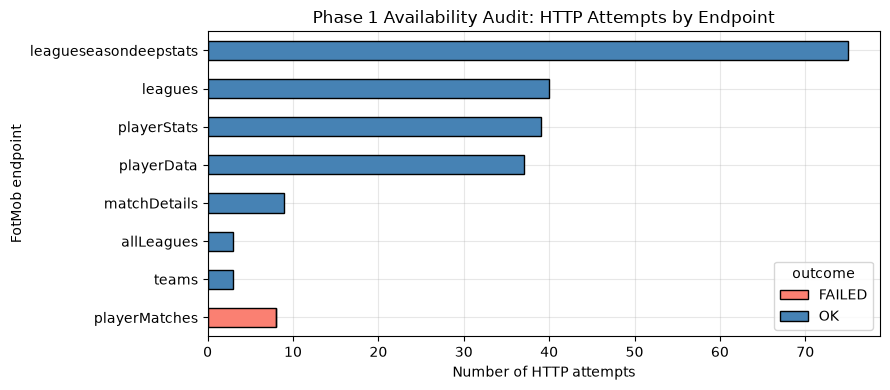

In [7]:
# Visualize Phase 1 attempts by endpoint and outcome
ax = phase1_summary.plot(kind="barh", stacked=True, figsize=(9, 4),
                         color={"OK": COLOR, "FAILED": "salmon"}, edgecolor="black")
ax.set_title("Phase 1 Availability Audit: HTTP Attempts by Endpoint")
ax.set_xlabel("Number of HTTP attempts")
ax.set_ylabel("FotMob endpoint")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

**Interpretation**

- All failed Phase 1 attempts are `playerMatches` requests answered with **HTTP 400** ("Invalid or missing query parameters"). Every other endpoint answered with HTTP 200 and JSON.
- Because `playerMatches` could not be made to work, the project decided to obtain player-to-match links from **`matchDetails` lineups** instead.

### Verifying the historical "54/54 responses" figure

An earlier project summary reported "9 sample metrics, 54/54 responses containing data". The request log allows that claim to be checked.

In [8]:
# Season-leaderboard probes in Phase 1 steps 03-05
steps = read_jsonl(ROOT / "logs/fotmob_steps_03_05_requests.jsonl")
boards = steps[steps["endpoint"] == "leagueseasondeepstats"].copy()
boards["stat"] = boards["params"].map(lambda p: p.get("stat"))
boards["season_id"] = boards["params"].map(lambda p: str(p.get("season")))

print("Leaderboard requests:", len(boards), "| outcome OK:", (boards["outcome"] == "OK").sum())
print("Distinct statistics requested:", sorted(boards["stat"].unique()))
print("Distinct seasons requested:", boards["season_id"].nunique())
print("Requests per season:", boards.groupby("season_id").size().unique().tolist())

Leaderboard requests: 54 | outcome OK: 54
Distinct statistics requested: ['goals', 'mins_played', 'saves']
Distinct seasons requested: 6
Requests per season: [9]


**Interpretation**

- The log confirms **54 leaderboard requests, all successful**.
- They are **3 distinct statistics** (goals, minutes played, saves) × 6 seasons, repeated over **3 runs** of the audit step. That is 9 requests per season, **not 9 distinct metrics**. The earlier "9 sample metrics" wording is therefore not supported; the correct reading is "9 requests per season, 54 of 54 successful".
- "Successful" here means HTTP 200 with a parsable, populated leaderboard. It does not show that every player or every metric is covered.

In [9]:
# Season availability from the audit, restricted to the official seasons
availability = pd.read_csv(ROOT / "reports/phase_01/season_availability.csv")
availability = availability[availability["season"].isin(SEASONS)]
display(availability[["season", "numeric_season_id", "team_count", "fixture_count",
                      "player_stat_count", "overall_status", "league_http_status", "deep_stats_http_status"]]
        .rename(columns={"player_stat_count": "goal_leaderboard_rows"}))

,season,numeric_season_id,team_count,fixture_count,goal_leaderboard_rows,overall_status,league_http_status,deep_stats_http_status
1,2020/2021,15382,20,380,270,AVAILABLE,200,200
2,2021/2022,16390,20,380,281,AVAILABLE,200,200
3,2022/2023,17664,20,380,271,AVAILABLE,200,200
4,2023/2024,20720,20,381,298,AVAILABLE,200,200
5,2024/2025,23685,20,380,271,AVAILABLE,200,200


**Interpretation and conclusions of the audit**

- Every official season returned 20 teams, its full fixture list (380 entries; 381 in 2023/24 because one match was abandoned and replayed) and a populated goals leaderboard.
- Leaderboards only list players with a value for that statistic. **Their union is not a complete player population.** No endpoint offered a complete historical squad list.
- Player profiles contain the player's **current** club and position (collected in 2026); in 9 of 12 sampled profiles the current club differed from the historical club.
- Verdict recorded in `reports/phase_01/fotmob_data_availability_audit.md`: **conditional go for a bounded pilot, no-go for an unrestricted crawl.**

These findings shaped the whole collection design: the population is built from match lineups, historical club membership comes from match evidence, and present-day profile fields are kept separate.

## C. Controlled Pilot (Phase 2A)

Objective:
Run the complete chain (request → raw storage → normalization → validation) on a small, deliberately designed sample before scaling up.

Why a pilot?
- To find defects while they are cheap (request identity, units, caching, schemas).
- To measure request behaviour on real traffic.
- To check that historical fields are scoped correctly.

Sampling design (`configs/pilot_config.yaml`, fixed seed 6902):
- **Deep** seasons: 4 clubs × 8 players per season.
- **Light** seasons: 8 players per season.
- Players were drawn from the union of the minutes, goals and saves leaderboards, with position and minutes strata.

In [10]:
# Reconstruct the pilot sample size from its configuration
pilot_cfg = load_cfg("configs/pilot_config.yaml")
deep = len(pilot_cfg["deep_seasons"]) * pilot_cfg["deep_clubs_per_season"] * pilot_cfg["deep_players_per_club"]
light = len(pilot_cfg["light_seasons"]) * pilot_cfg["light_players_per_season"]
print(f"Deep seasons:  {len(pilot_cfg['deep_seasons'])} x {pilot_cfg['deep_clubs_per_season']} clubs x {pilot_cfg['deep_players_per_club']} players = {deep}")
print(f"Light seasons: {len(pilot_cfg['light_seasons'])} x {pilot_cfg['light_players_per_season']} players = {light}")
print("Planned player-season sample:", deep + light)

# Compare with the sample manifest actually produced
pilot_manifest = pd.read_csv(ROOT / "reports/phase_02a/pilot_sample_manifest.csv")
print("Rows in pilot sample manifest:", len(pilot_manifest),
      "| unique players:", pilot_manifest["fotmob_player_id"].nunique())
display(pilot_manifest.groupby(["pilot_depth", "position_group"]).size().unstack(fill_value=0))

Deep seasons:  3 x 4 clubs x 8 players = 96
Light seasons: 3 x 8 players = 24
Planned player-season sample: 120
Rows in pilot sample manifest: 120 | unique players: 109


position_group,DEF,FWD,GK,MID
pilot_depth,,,,
DEEP,32,24,12,28
LIGHT,7,7,3,7


In [11]:
# Pilot request log
pilot_log = read_jsonl(ROOT / "logs/phase_02a_requests.jsonl")
pilot_summary = pilot_log.groupby("endpoint").agg(
    attempts=("outcome", "size"),
    ok=("outcome", lambda s: (s == "OK").sum()),
    retries=("retry_index", lambda s: (s > 0).sum()),
    median_kb=("response_bytes", lambda s: round(s.median() / 1024, 1)),
).sort_values("attempts", ascending=False)
display(pilot_summary)
print("Total attempts:", len(pilot_log), "| OK:", (pilot_log["outcome"] == "OK").sum(),
      "| HTTP statuses:", pilot_log["http_status"].value_counts().to_dict())

,attempts,ok,retries,median_kb
endpoint,,,,
playerStats,120,120,0,19.5
playerData,109,109,0,108.1
leagueseasondeepstats,18,18,0,69.3
matchDetails,10,10,0,226.4
leagues,6,6,0,861.0
teams,2,2,0,798.2


Total attempts: 265 | OK: 265 | HTTP statuses: {200: 265}


**Interpretation**

- The configuration produces exactly **120** player-seasons, and the sample manifest contains 120 rows (109 distinct players).
- The pilot made **265 HTTP attempts and all 265 succeeded**, with no retries. The phase report also records **31/31 automated tests passing** (`reports/phase_02a/phase_02a_pilot_report.md`; that test run is not repeated here).
- 265 successes describe a small observed sample. They do not estimate the failure rate of a full crawl.

What the pilot revealed before scaling up (from the pilot report):
- Two team probes reused the same source id. **Request identity had to become a content-derived key.**
- In 84 of 120 profiles the current club differed from the historical club, so **profiles cannot be historical evidence**.
- One minutes value differed by one minute between the leaderboard and `playerStats`. **Both values must be kept**; no silent source preference.
- Leaderboards still gave no player denominator. **The population must come from lineups.**

## D. Collection Reliability and Hardening (Phase 2B.0)

Objective:
Make the collector safe to run at scale, then measure it on a bounded live plan.

Mechanisms added in this phase (code in `src/collection/source_registry.py`, `src/collection/reliability_runner.py`, `src/audit/client.py`):

| Mechanism | What it does |
|---|---|
| Content-derived request key | `request_key()` hashes method, path, canonicalized parameters and a contract version into `req_<sha256>`. The same logical request always has the same key |
| Immutable raw capture | Each response is written as `response.json` + `metadata.json` into a temporary folder, flushed, then atomically renamed to `raw/<season>/<endpoint>/cap_<id>/`. An existing capture is never overwritten |
| Verified cache | Before reuse, a cached capture's SHA-256 and its historical scope are re-checked. A wrong-season capture is preserved but refused |
| Checkpoint / resume | Committed captures act as checkpoints; a resumed run reuses them and sends no request for them |
| Bounded `Retry-After` | HTTP 429 waits are honoured only up to a configured ceiling |
| Raw retention on failure | Malformed or non-JSON bodies are kept for diagnosis instead of being discarded |
| Failure injection | Mocked HTTP 400/403/429/500/503, timeouts, resets, invalid/empty JSON and wrong-season captures in automated tests |

### Three different meanings of "success"

| Level | Question | Evidence |
|---|---|---|
| Received | Did the server answer with HTTP 200? | `http_status` |
| Parsed | Is the body valid JSON with the expected root type? | `json_parse_success` |
| Usable | Does the response contain valid data for the intended purpose and the right historical scope? | `schema_status`, `historical_scope_status` |

The bounded live reliability run measured all three.

In [12]:
# Live reliability measurements (23 attempts)
metrics = pd.read_csv(ROOT / "reports/phase_02b0/request_metrics.csv")
funnel = pd.Series({
    "Attempts": len(metrics),
    "Received (HTTP 200)": (metrics["http_status"] == 200).sum(),
    "Parsed (valid JSON)": metrics["json_parse_success"].astype(bool).sum(),
    "Usable (VALID_DATA)": (metrics["schema_status"] == "VALID_DATA").sum(),
    "Season directly confirmed in response": (metrics["historical_scope_status"] == "ACCEPTED").sum(),
})
display(funnel.to_frame("Responses"))
display(metrics.groupby(["endpoint", "schema_status"]).size().unstack(fill_value=0))
print("Retries:", (metrics["retry_index"] > 0).sum(),
      "| median latency (s):", metrics["latency_seconds"].median())

,Responses
Attempts,23
Received (HTTP 200),23
Parsed (valid JSON),23
Usable (VALID_DATA),21
Season directly confirmed in response,15


schema_status,HISTORICAL_SCOPE_UNVERIFIED,VALID_DATA
endpoint,,
leagues,0,6
leagueseasondeepstats,0,6
matchDetails,0,3
playerData,0,3
playerStats,0,3
teams,2,0


Retries: 0 | median latency (s): 0.485


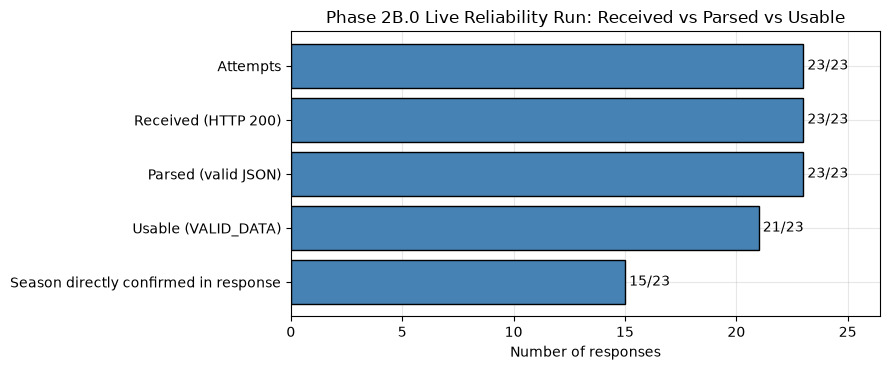

In [13]:
# Visualize the difference between received, parsed and usable responses
plt.figure(figsize=(9, 3.8))
bars = plt.barh(funnel.index[::-1], funnel.values[::-1], color=COLOR, edgecolor="black")
plt.bar_label(bars, labels=[f"{v}/{len(metrics)}" for v in funnel.values[::-1]], padding=3)
plt.title("Phase 2B.0 Live Reliability Run: Received vs Parsed vs Usable")
plt.xlabel("Number of responses")
plt.xlim(0, len(metrics) * 1.15)
plt.tight_layout()
plt.show()

**Interpretation**

- **23/23** responses were received (HTTP 200) and **23/23** parsed as JSON, but only **21/23** were usable. The two `teams` responses had a valid shape yet no explicit historical squad season, so they could not serve as historical membership evidence (`HISTORICAL_SCOPE_UNVERIFIED`).
- Only 15 responses state their season directly. Profile and player-statistics responses are tied to a season through a season entry chosen from the profile, not through a season field in the response, so they are counted as not directly confirmed.
- This is why the report never treats "HTTP success" as "data coverage".
- 23 attempts is a small, bounded observation. It is not a prediction of service behaviour during a long crawl.

In [14]:
# Cache, resume and recovery scenarios
recovery = pd.read_csv(ROOT / "reports/phase_02b0/recovery_test_results.csv")
display(recovery[["scenario", "status", "observed", "expected", "note"]])

,scenario,status,observed,expected,note
0,injected_checkpoint_interruption,PASS,10,10,Ten committed checkpoints survive interruption
1,resume_equals_uninterrupted,PASS,23,23,"Logical key, status, scope and SHA-256 agree"
2,checkpoint_cache_hits,PASS,10,10,Previously committed requests were not fetched...
3,duplicate_request_keys,PASS,0,0,One committed observation per logical request
4,normalization_idempotency,PASS,7,7,Seven table logical hashes stable over two runs
5,partial_output_recovery,PASS,7,7,Corrupted test output rebuilt from preserved raw


**Interpretation**

- Replaying the same 23-request plan produced **zero HTTP attempts**: all requests were served from verified checkpoints.
- An interruption after 10 saved responses resumed to the same final state as an uninterrupted run, with no duplicated request keys.
- Normalization run twice gave identical table hashes, and a deliberately corrupted output was rebuilt from preserved raw data.
- The failure types (403, 429, 5xx, timeouts, invalid JSON) were tested with **mocked** responses in `tests/collection/test_reliability_step05.py`. They are not part of the live success rates.

### How a request key is formed

The function below is the project's own implementation. It runs offline and shows that parameter order and types do not change a request's identity, while a different season does.

In [15]:
from src.collection.source_registry import request_key

key_a = request_key("leagueseasondeepstats", {"id": 47, "season": 15382, "type": "players", "stat": "goals"})
key_b = request_key("leagueseasondeepstats", {"stat": "goals", "type": "players", "season": "15382", "id": "47"})
key_c = request_key("leagueseasondeepstats", {"id": 47, "season": 16390, "type": "players", "stat": "goals"})

print("Same request, different parameter order/types:", key_a == key_b)
print("Different season gives a different key:      ", key_a != key_c)
print("Example key:", key_a[:32] + "...")

Same request, different parameter order/types: True
Different season gives a different key:       True
Example key: req_139099db09f4cbc8d367d9643177...


In [16]:
# One immutable raw capture from the full collection (official season 2024/25)
example_meta_path = sorted((ROOT / "data/phase_02b1/raw/2024_2025/matchDetails").glob("cap_*/metadata.json"))[0]
example_meta = json.loads(example_meta_path.read_text(encoding="utf-8"))
display(pd.Series(example_meta, name="value").to_frame())

# Verify the stored body against the checksum recorded at capture time
body_ok = sha256_file(example_meta_path.with_name("response.json")) == example_meta["content_sha256"]
print("Stored response matches its recorded SHA-256:", body_ok)

,value
body_kind,wire_json
capture_id,cap_02660c2e0fce4d22b2f74da27eadd979
collected_at_utc,2026-11-02T14:37:59.092239+00:00
content_sha256,50fafeea696e36bb48e61fb07182607c63731d76aaba9a...
content_type,application/json; charset=utf-8
endpoint,matchDetails
http_status,200
legacy,False
metadata_path,data/phase_02b1/raw/2024_2025/matchDetails/cap...
method,GET


Stored response matches its recorded SHA-256: True


**Interpretation**

Every raw capture carries its own provenance: request key, endpoint, parameters, source URL, HTTP status, collection time, season, scope check, parser and schema versions, and the SHA-256 of the exact bytes received. Normalized tables keep the `raw_path` of the capture they came from, so any value can be traced back to the original response.

## E. Large-Scale Data Collection (Phase 2B.1)

Objective:
Collect every completed league match, every player who appeared, and that player's season statistics and profile, for every season of the development crawl (2019/20 to 2024/25).

### Collection architecture

The crawl is driven by a **task manifest** (SQLite, `collection_manifest.sqlite`). Each task has a stage, a resource type, a content-derived request key, dependencies and an execution state (`PLANNED → RUNNING → FETCHED → VALIDATED → …`, or `RETRY_PENDING` / `QUARANTINED` / `BLOCKED`). The orchestrator (`src/collection/full_orchestrator.py`) runs only tasks whose dependencies are validated.

```text
Per season:
 [A] leagues                -> fixture index (match ids, dates, teams, results)
        |
        +--> [C] leaderboards (minutes, goals, saves)        candidate players only
        |
        v
 [E] match index gate -> 380 x matchDetails                 full lineups + substitutions
        |
        v
 [B] population gate                                        players who STARTED or were SUBSTITUTED_ON
        |
        v
 [D] player expansion -> playerData (profile) per player    identity, season entries
        |               -> historical membership gate       club from match evidence
        v
 [C] playerStats per player-season (seasonId from profile)  53 season metrics
        |
        +--> [C] season metric leaderboards                 cross-source checks
        v
 [F] normalization gate -> [G] season acceptance gate
```

### Batch control and stop rules

- Each run is started explicitly, with at most **50 HTTP attempts** and **one worker**.
- A batch report (`reports/phase_02b1/batches/`) is written after every run, with decision `PASS`, `REVIEW` or `STOP`.
- A batch **stops** on: any raw corruption, cache corruption, request-identity collision, historical-scope mismatch, incomplete provenance or duplicate id; any HTTP 403 or 429; repeated schema or server errors; or three consecutive JSON-null `playerStats` responses.
- Rejected responses are moved to a **quarantine** folder with their metadata, never into the accepted raw store.

In [17]:
# Read the released crawl manifest in read-only (immutable) mode
manifest_path = ROOT / "data/releases/fotmob_epl_2019_2025_v3_1/manifests/collection_manifest.sqlite"
con = sqlite3.connect(f"file:{manifest_path.as_posix()}?mode=ro&immutable=1", uri=True)
tasks = pd.read_sql_query("SELECT season_label, stage, resource_type, execution_state FROM tasks", con)
con.close()

# Per-season breakdown restricted to the official seasons
tasks_scope = tasks[tasks["season_label"].isin(SEASONS)]
task_table = (tasks_scope.groupby(["stage", "resource_type"]).size().rename("tasks (5 seasons)").to_frame()
              .join(tasks_scope.groupby(["stage", "resource_type"])["execution_state"]
                    .agg(lambda s: ", ".join(f"{k}: {v}" for k, v in s.value_counts().items()))))
display(task_table)
display(tasks_scope.pivot_table(index="resource_type", columns="season_label", values="stage",
                                aggfunc="size", fill_value=0).rename(columns=short))

tasks (5 seasons)  execution_state
stage resource_type                                                 
A     SEASON_FIXTURES                             5     VALIDATED: 5
B     POPULATION_GATE                             5     VALIDATED: 5
C     CANDIDATE_LEADERBOARD                      15    VALIDATED: 15
      PLAYER_SEASON_STATS                      2747  VALIDATED: 2747
      SEASON_METRIC_LEADERBOARD                  95    VALIDATED: 95
      SEASON_STATS_GATE                           5     VALIDATED: 5
D     HISTORICAL_MEMBERSHIP_GATE                  5     VALIDATED: 5
      PLAYER_EXPANSION_GATE                       5     VALIDATED: 5
      PLAYER_IDENTITY_PROFILE                   368   VALIDATED: 368
      PLAYER_PROFILE                           2747  VALIDATED: 2747
E     MATCH_DETAIL                             1900  VALIDATED: 1900
      MATCH_INDEX_GATE                            5     VALIDATED: 5
F     NORMALIZATION_GATE                          5    SUPERSEDED: 5
G     SEASON_ACCEPTANCE_GATE                      5    SUPERSEDED: 5

season_label,2020/21,2021/22,2022/23,2023/24,2024/25
resource_type,,,,,
CANDIDATE_LEADERBOARD,3,3,3,3,3
HISTORICAL_MEMBERSHIP_GATE,1,1,1,1,1
MATCH_DETAIL,380,380,380,380,380
MATCH_INDEX_GATE,1,1,1,1,1
NORMALIZATION_GATE,1,1,1,1,1
PLAYER_EXPANSION_GATE,1,1,1,1,1
PLAYER_IDENTITY_PROFILE,76,69,64,96,63
PLAYER_PROFILE,524,537,554,570,562
PLAYER_SEASON_STATS,524,537,554,570,562


**Interpretation**

- Each official season has exactly **380 `MATCH_DETAIL` tasks**, one per completed match, all validated.
- The number of `PLAYER_PROFILE` and `PLAYER_SEASON_STATS` tasks per season equals the season's confirmed population (524, 537, 554, 570, 562). These tasks were **appended** to the manifest only after the population gate had derived the players from lineups; they were not guessed in advance.
- `PLAYER_IDENTITY_PROFILE` tasks are extra profile requests for players seen in lineups (including bench-only players) whose profile had not been captured yet; they support identity checks, not season statistics.
- `SEASON_METRIC_LEADERBOARD` tasks (19 per season) download league leaderboards that are used to cross-check the per-player values and, where a per-player value is absent, as a documented fallback (status `OBSERVED_FALLBACK_LEADERBOARD`).
- `NORMALIZATION_GATE` and `SEASON_ACCEPTANCE_GATE` are `SUPERSEDED`: the original gates were replaced by the later remediation and the v3.1 acceptance (Section 03.F).

In [18]:
# Full-collection request log (all seasons of the historical crawl)
crawl_log = read_jsonl(ROOT / "logs/phase_02b1_requests.jsonl")
crawl_summary = crawl_log.groupby("endpoint").agg(
    attempts=("outcome", "size"),
    ok=("outcome", lambda s: (s == "OK").sum()),
    failed=("outcome", lambda s: (s != "OK").sum()),
    http_200=("http_status", lambda s: (s == 200).sum()),
    retries=("retry_index", lambda s: (s > 0).sum()),
    total_mb=("response_bytes", lambda s: round(s.sum() / 1e6, 1)),
).sort_values("attempts", ascending=False)
display(crawl_summary)
print("Attempts:", len(crawl_log), "| OK:", (crawl_log["outcome"] == "OK").sum(),
      "| first:", crawl_log["timestamp_utc"].min()[:19], "| last:", crawl_log["timestamp_utc"].max()[:19])
print("Failure reasons:", crawl_log.loc[crawl_log["outcome"] != "OK", "error"].value_counts().to_dict())

,attempts,ok,failed,http_200,retries,total_mb
endpoint,,,,,,
playerStats,3156,3142,14,3156,0,85.8
matchDetails,2258,2258,0,2258,0,519.2
playerData,1649,1649,0,1649,0,147.4
leagueseasondeepstats,114,114,0,114,0,8.1


Attempts: 7177 | OK: 7163 | first: 2026-11-02T13:38:14 | last: 2026-11-03T02:15:20
Failure reasons: {'JSON root is not an object or list': 14}


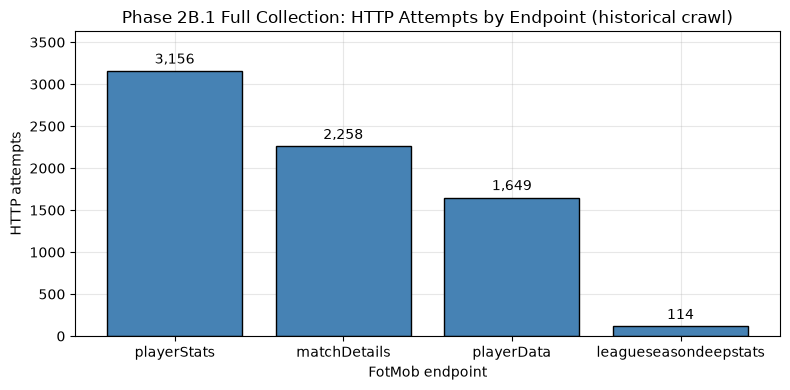

In [19]:
# Visualize request volume by endpoint
plt.figure(figsize=(8, 4))
bars = plt.bar(crawl_summary.index, crawl_summary["attempts"], color=COLOR, edgecolor="black")
plt.bar_label(bars, labels=[f"{v:,}" for v in crawl_summary["attempts"]], padding=3)
plt.title("Phase 2B.1 Full Collection: HTTP Attempts by Endpoint (historical crawl)")
plt.xlabel("FotMob endpoint")
plt.ylabel("HTTP attempts")
plt.ylim(0, crawl_summary["attempts"].max() * 1.15)
plt.tight_layout()
plt.show()

**Interpretation**

- The full crawl made **7,177 HTTP attempts** over about 12.5 hours (2026-11-02 13:38 to 2026-11-03 02:15 UTC), in explicitly started batches.
- **Every attempt received HTTP 200**, but **14 were not usable**: `playerStats` answered with a JSON `null` body ("JSON root is not an object or list"). Such bodies were moved to the **quarantine** store, not into the accepted raw store, and the affected tasks were requested again later (all `PLAYER_SEASON_STATS` tasks above ended `VALIDATED`). This is the "received ≠ usable" distinction in practice.
- There were no retries and no HTTP 403/429.
- The log has fewer attempts than the manifest has tasks (for example 2,258 `matchDetails` attempts for 2,280 match tasks over six seasons). The **verified cache** explains this: a task whose response had already been captured in an earlier phase was satisfied from that capture after its checksum and scope were re-checked. The next cell reconciles this exactly for the official seasons.

In [20]:
# Count committed captures in the three raw stores the crawler's registries read
def count_new_store(root, season, endpoint):
    # layout: <root>/<season>/<endpoint>/<capture_id>/metadata.json
    return sum(1 for _ in (root / season.replace("/", "_") / endpoint).glob("*/metadata.json"))

def count_pilot_store(season, endpoint):
    # layout: data/pilot/raw/<season>_<endpoint>_<id>.json (+ .meta.json)
    return sum(1 for _ in (ROOT / "data/pilot/raw").glob(f"{season.replace('/', '_')}_{endpoint}_*.meta.json"))

stats_tasks = tasks_scope[tasks_scope["resource_type"] == "PLAYER_SEASON_STATS"].groupby("season_label").size()
rows = []
for season in SEASONS:
    for endpoint, expected in (("matchDetails", 380), ("playerStats", int(stats_tasks[season]))):
        full = count_new_store(ROOT / "data/phase_02b1/raw", season, endpoint)
        hardening = count_new_store(ROOT / "data/phase_02b0/raw", season, endpoint)
        pilot = count_pilot_store(season, endpoint)
        rows.append({"season": short(season), "endpoint": endpoint, "Phase 2B.1 store": full,
                     "Phase 2B.0 store": hardening, "Phase 2A pilot store": pilot,
                     "total": full + hardening + pilot, "expected": expected})
reconciliation = pd.DataFrame(rows)
reconciliation["reconciled"] = reconciliation["total"] == reconciliation["expected"]
display(reconciliation)

# Quarantined (rejected) captures of the full collection
quarantine = pd.DataFrame([json.loads(p.read_text(encoding="utf-8"))
                           for p in (ROOT / "data/phase_02b1/quarantine").glob("*/metadata.json")])
print("Quarantined captures:", len(quarantine), "| by endpoint and reason:",
      quarantine.groupby(["endpoint", "reason"]).size().to_dict())

,season,endpoint,Phase 2B.1 store,Phase 2B.0 store,Phase 2A pilot store,total,expected,reconciled
0,2020/21,matchDetails,377,2,1,380,380,True
1,2020/21,playerStats,516,0,8,524,524,True
2,2021/22,matchDetails,377,2,1,380,380,True
3,2021/22,playerStats,529,0,8,537,537,True
4,2022/23,matchDetails,376,2,2,380,380,True
5,2022/23,playerStats,522,0,32,554,554,True
6,2023/24,matchDetails,376,2,2,380,380,True
7,2023/24,playerStats,562,0,8,570,570,True
8,2024/25,matchDetails,376,2,2,380,380,True
9,2024/25,playerStats,530,0,32,562,562,True


Quarantined captures: 17 | by endpoint and reason: {('playerStats', 'NO_STATS_PAYLOAD'): 13, ('playerStats', 'SCHEMA_ERROR'): 4}


**Interpretation**

- For every official season, the committed captures across the three raw stores add up to **exactly 380 `matchDetails`** (one per completed match) and **exactly one `playerStats` capture per Confirmed player-season**.
- The `playerStats` captures not in the full-collection store are exactly the pilot sample (8 or 32 per season), reused from the pilot store.
- Rejected responses are kept separately in the quarantine store with their reason, so they can be inspected but never enter the normalized data.
- `playerData` profiles are not reconciled per season: a profile is a player-level, present-day record, filed under the first season in which the crawler met the player (the project documents 387 such profiles stored in `2019_2020`-named folders; they are not season data).

### From lineups to a player population

A player belongs to a season's population only if match evidence shows he **appeared**:
- `STARTED`: listed in the starting eleven.
- `SUBSTITUTED_ON`: a substitution event brings him on.
- `UNKNOWN`: listed on the bench, but the evidence cannot confirm whether he came on.

`UNKNOWN` is **never** converted into "did not play". A player-season is **Confirmed** when at least one appearance is confirmed; otherwise it is **Unverified** and excluded from the research population, with its count preserved.

participation_status,STARTED,SUBSTITUTED_ON,UNKNOWN,total
season_label,,,,
2020/21,8360,2033,4250,14643
2021/22,8360,2125,4677,15162
2022/23,8360,2985,3840,15185
2023/24,8360,3024,3796,15180
2024/25,8360,3207,3621,15188


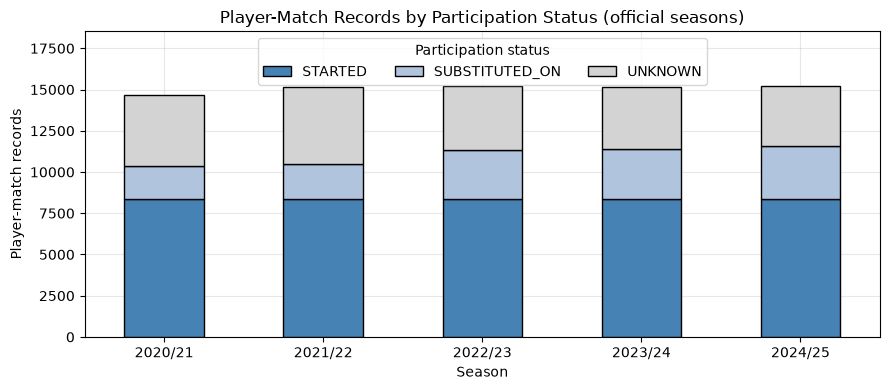

In [21]:
# Participation evidence in the five-season research release of FotMob
FOTMOB_RS5 = ROOT / "data/releases/fotmob_epl_2020_2025_rs5_v1"
appearances = pd.read_parquet(FOTMOB_RS5 / "normalized/player_match_appearances.parquet",
                              columns=["season_label", "participation_status"])
participation = appearances.groupby(["season_label", "participation_status"]).size().unstack(fill_value=0)
participation.index = participation.index.map(short)
display(participation.assign(total=participation.sum(axis=1)))

ax = participation[["STARTED", "SUBSTITUTED_ON", "UNKNOWN"]].plot(
    kind="bar", stacked=True, figsize=(9, 4), edgecolor="black",
    color=["steelblue", "lightsteelblue", "lightgray"])
ax.set_title("Player-Match Records by Participation Status (official seasons)")
ax.set_xlabel("Season")
ax.set_ylabel("Player-match records")
ax.set_ylim(0, participation.sum(axis=1).max() * 1.22)
ax.legend(title="Participation status", ncol=3, loc="upper center")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,completed_matches,player_seasons,confirmed_appeared,unverified,unknown_player_matches
season_label,,,,,
2020/21,380,641,524,117,4250
2021/22,380,679,537,142,4677
2022/23,380,699,554,145,3840
2023/24,380,734,570,164,3796
2024/25,380,685,562,123,3621


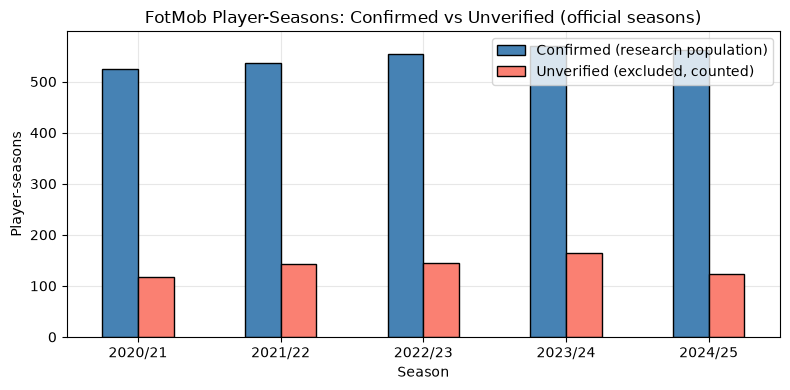

In [22]:
# Confirmed vs Unverified player-seasons per official season
summary_rs5 = pd.DataFrame(read_json("data/releases/fotmob_epl_2020_2025_rs5_v1/metadata/canonical_summary_rs5.json")["population_by_season"])
population = summary_rs5[summary_rs5["season_label"].isin(SEASONS)].set_index("season_label")
population.index = population.index.map(short)
display(population[["completed_matches", "player_seasons", "confirmed_appeared", "unverified", "unknown_player_matches"]])

ax = population[["confirmed_appeared", "unverified"]].plot(kind="bar", figsize=(8, 4), edgecolor="black",
                                                            color=["steelblue", "salmon"])
ax.set_title("FotMob Player-Seasons: Confirmed vs Unverified (official seasons)")
ax.set_xlabel("Season")
ax.set_ylabel("Player-seasons")
ax.legend(["Confirmed (research population)", "Unverified (excluded, counted)"])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Interpretation**

- Every match contributes 22 starters (8,360 `STARTED` records per season = 380 × 22).
- **20,184 bench records (26.8%) remain `UNKNOWN`.** They are excluded from confirmed appearances, never counted as zero minutes.
- Over the five seasons, **2,747 player-seasons are Confirmed** and form the research population; **691 are Unverified** and excluded, with their counts kept for audit.

## F. From Raw Captures to Structured Data: FotMob Releases

Normalization turns raw captures into typed Parquet tables:

| Table | Grain | Content |
|---|---|---|
| `matches` | match | date, teams, score, completion status, fixture raw path |
| `player_match_appearances` | player × match | lineup role, substitution events, participation status, raw path |
| `metric_observations` | player × season × metric × source | original field name, raw value, unit, source endpoint, status, raw path |
| `player_seasons`, `player_team_seasons` | player × season (× team) | evidence status, historical club membership |
| `players` | player | profile fields (present-day; never used as history) |
| `player_season_metrics_wide` (curated) | player × season | one `m_<metric>` value and one `s_<metric>` status column per metric |

Rules applied during normalization:
- **Null is never zero.** Every metric value has a status (`OBSERVED`, `OBSERVED_ZERO`, `MISSING`, `UNVERIFIED_POSITION`, `UNSUPPORTED`, `CONFLICTING`, …).
- **Conflicts are preserved.** When two sources disagree beyond rounding, both observations stay in the long table and the curated cell is null with status `CONFLICTING`.
- Multi-club players stay **one player-season row**; club detail is kept in a separate table.

The releases evolved as defects were found and fixed:

| Release | Scope | Status |
|---|---|---|
| `fotmob_epl_2019_2025_v1`, `v2`, `v3` | six seasons | historical; superseded |
| `fotmob_epl_2019_2025_v3_1` | six seasons | historical collection release (CONDITIONAL_GO), frozen input of Phase 3 |
| `fotmob_epl_2020_2025_rs5_v1` | **five seasons** | research release: a verified row filter of v3.1 (D9) |

In [23]:
# Historical six-season collection release v3.1 (totals only; NOT research statistics)
V31 = ROOT / "data/releases/fotmob_epl_2019_2025_v3_1"
v31_summary = read_json("data/releases/fotmob_epl_2019_2025_v3_1/metadata/canonical_summary.json")
v31_pop = pd.DataFrame(v31_summary["population_by_season"])
v31_parquets = sorted(V31.rglob("*.parquet"))
import pyarrow.parquet as pq
historical = pd.Series({
    "Seasons": len(v31_pop),
    "Completed matches": int(v31_pop["completed_matches"].sum()),
    "Player-season records": int(v31_pop["player_seasons"].sum()),
    "Player-match records": pq.ParquetFile(V31 / "normalized/player_match_appearances.parquet").metadata.num_rows,
    "Metric observations": pq.ParquetFile(V31 / "normalized/metric_observations.parquet").metadata.num_rows,
    "Parquet tables": len(v31_parquets),
}, name="FotMob v3.1 (historical, six seasons)")
display(historical.to_frame())

,"FotMob v3.1 (historical, six seasons)"
Seasons,6
Completed matches,2280
Player-season records,4052
Player-match records,89392
Metric observations,207043
Parquet tables,16


**Interpretation**

These are the totals of the **historical six-season collection release** (they include the excluded season). The release report (`reports/final_acceptance_fix/final_acceptance_report.md`) also records 318 metric-season coverage rows, 30/30 key and population checks, 190/190 automated tests and 38/38 manifest checksums for this release. They describe the collection pipeline's output, **not** the research dataset.

The research uses the five-season release below.

In [24]:
# Five-season FotMob research release: tables and row counts
rs5_tables = pd.DataFrame([{
    "table": p.relative_to(FOTMOB_RS5).as_posix(),
    "rows": pq.ParquetFile(p).metadata.num_rows,
    "columns": len(pq.ParquetFile(p).schema_arrow.names),
} for p in sorted(FOTMOB_RS5.rglob("*.parquet"))])
display(rs5_tables)

# Every season-bearing table passes the project's scope check
scope_checked = 0
for p in sorted(FOTMOB_RS5.rglob("*.parquet")):
    names = pq.ParquetFile(p).schema_arrow.names
    if "season_id" in names:
        check_parquet(p, SCOPE, "season_label" if "season_label" in names else None, "season_id", require_all=False)
        scope_checked += 1
print("Season-bearing tables passing the scope check:", scope_checked)

,table,rows,columns
0,curated/confirmed_appeared_player_seasons.parquet,2747,114
1,curated/player_season_metrics_wide.parquet,3438,114
2,normalized/complete_player_season_classificati...,3438,20
3,normalized/confirmed_appeared_player_seasons.p...,2747,20
4,normalized/confirmed_non_appeared_player_seaso...,0,20
5,normalized/historical_position_observations.pa...,123481,11
6,normalized/matches.parquet,1901,16
7,normalized/metric_observations.parquet,174956,28
8,normalized/player_match_appearances.parquet,75358,24
9,normalized/player_seasons.parquet,3438,10


Season-bearing tables passing the scope check: 15


,cells
status,
OBSERVED,91289
MISSING,27361
UNVERIFIED_POSITION,17899
OBSERVED_ZERO,5762
UNSUPPORTED,2747
OBSERVED_FALLBACK_LEADERBOARD,402
OBSERVED_SOURCE_REVISED,95
CONFLICTING,36


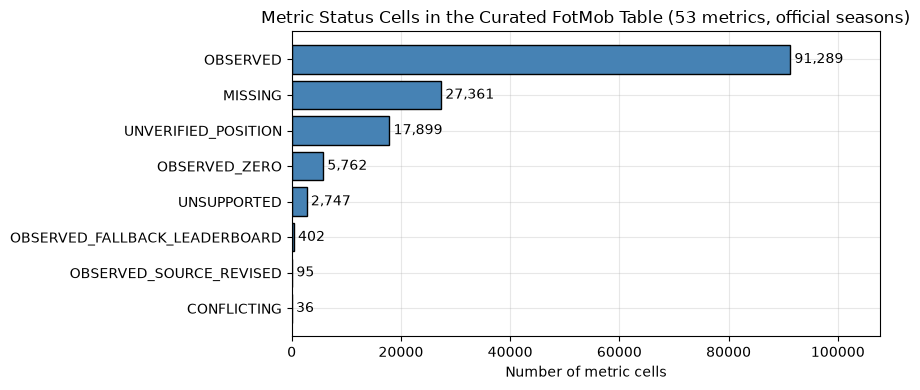

In [25]:
# Metric status cells in the curated Confirmed table (53 metrics x 2,747 player-seasons)
curated = pd.read_parquet(FOTMOB_RS5 / "curated/confirmed_appeared_player_seasons.parquet")
status_cols = [c for c in curated.columns if c.startswith("s_")]
status_counts = curated[status_cols].melt(value_name="status")["status"].value_counts()
display(status_counts.to_frame("cells"))

plt.figure(figsize=(9, 4))
bars = plt.barh(status_counts.index[::-1], status_counts.values[::-1], color=COLOR, edgecolor="black")
plt.bar_label(bars, labels=[f"{v:,}" for v in status_counts.values[::-1]], padding=3)
plt.title(f"Metric Status Cells in the Curated FotMob Table ({len(status_cols)} metrics, official seasons)")
plt.xlabel("Number of metric cells")
plt.xlim(0, status_counts.max() * 1.18)
plt.tight_layout()
plt.show()

**Interpretation**

- The research release has **2,747 Confirmed player-seasons × 53 metrics** (145,591 cells). About 63% of the cells are `OBSERVED`.
- `OBSERVED_ZERO` (5,762) is a genuine zero reported by the source. `MISSING` (27,361) and `UNVERIFIED_POSITION` (17,899) are **unknown**, not zero.
- `UNSUPPORTED` (2,747) is the `key_passes` metric, which the source never supplies.
- `CONFLICTING` (36) values are null because the sources disagree; both source values remain in `metric_observations`.

### Remaining FotMob limitations
- 20,184 bench appearances remain `UNKNOWN`; the population is limited to confirmed appearances.
- Season-level metric windows are not published by the source; they were re-tested against match sums later (Section 08).
- `key_passes` has no data; `clearances` has values in only 3 of 5 seasons.
- Profiles are present-day records; historical club and position come from match evidence only.

## G. Holdout Season Collection (2025/26)

Objective:
Collect the holdout season with **exactly the same pipeline** as the development seasons, so that the final test measures the model and not a change in the data.

Method (`src/holdout/collect_fotmob.py`, `src/holdout/fotmob_tables.py`):
- Same endpoints, user agent, 1.2-second spacing, stop rules and immutable raw store (response + metadata + SHA-256) as Phase 2B.1.
- The table-building code reuses the development functions unchanged.
- **Fidelity check before use:** run on the saved 2024/25 raw files, the same code reproduces release v3.1 exactly: 562 of 562 confirmed player-seasons, 0 appearance-count mismatches, 0 position mismatches and 0 mismatches in 29,786 metric cells (`tests/holdout/test_fotmob_tables.py`).
- **Blind build:** while the holdout data is built, only counts, coverage, nulls and schema are reported. No target value, distribution or prediction is looked at.

The cell below summarises the request log and verifies the holdout release files.

In [26]:
# Holdout season collection: request log and release manifest (counts only)
ho_log = read_jsonl(ROOT / "logs/holdout_2025_26_fotmob_requests.jsonl")
display(ho_log.groupby("endpoint").agg(requests=("url", "size"),
                                       http_200=("http_status", lambda s: int((s == 200).sum())))
        .sort_values("requests", ascending=False))
print("Requests:", len(ho_log), "| non-200 responses:", int((ho_log["http_status"] != 200).sum()))

HO_RELEASE = ROOT / "data/holdout_2025_26/fotmob/release_v1"
ho_release = read_json("data/holdout_2025_26/fotmob/release_v1/release_manifest.json")
s = ho_release["summary"]
display(pd.Series({
    "FotMob season id": ho_release["season_id"],
    "Matches": s["matches"],
    "Player-match rows": s["player_matches"],
    **{f"Participation: {k}": v for k, v in s["participation"].items()},
    "Confirmed appeared player-seasons": s["confirmed_appeared_player_seasons"],
    "Missing profiles": s["profiles_missing"],
    "Missing statistics": s["stats_missing"],
}, name="value").astype(str).to_frame())

bad = [f for f, h in ho_release["files"].items() if sha256_file(HO_RELEASE / f) != h]
print("Holdout release files verified by SHA-256:", len(ho_release["files"]) - len(bad), "of", len(ho_release["files"]))
assert not bad, f"Changed holdout files: {bad}"

,requests,http_200
endpoint,,
playerData,678,678
playerStats,537,537
matchDetails,380,380
leagueseasondeepstats,22,22


Requests: 1617 | non-200 responses: 0


,value
FotMob season id,27110
Matches,380
Player-match rows,15189
Participation: STARTED,8360
Participation: SUBSTITUTED_ON,3132
Participation: UNKNOWN,3697
Confirmed appeared player-seasons,537
Missing profiles,0
Missing statistics,0


Holdout release files verified by SHA-256: 8 of 8


**Interpretation**

- Every request returned HTTP 200, with no 403, 429 or retry. The same endpoints as the development crawl were used: the season fixture list and leaderboards, 380 `matchDetails`, a profile for every lineup player and season statistics for every confirmed player.
- The population rule is unchanged: a player enters the population only if a lineup shows that he started or came on. 537 player-seasons are confirmed.
- No profile and no statistics response is missing. The holdout release is stored apart from the development releases, which are untouched.

# 04. Transfermarkt Data and Target Construction

## A. Source Acquisition

Objective:
Obtain historical market valuations without crawling Transfermarkt.

Method (`src/phase3/acquire_tm.py`, `configs/phase_03_tm_source.yaml`):
- Download only the **seven pinned CSV files** of the pinned snapshot `tm_r2_20260905` of `dcaribou/transfermarkt-datasets`.
- Verify each file's size, ETag and SHA-256 against the pins. Any mismatch stops the run.
- Create the snapshot folder only if every file passes; never overwrite an existing snapshot.

The cell below re-verifies the local source files against their recorded checksums.

In [27]:
# Re-verify the immutable Transfermarkt source files
tm_manifest = read_json("data/transfermarkt/metadata/tm_r2_20260905/source_manifest.json")
TM_SOURCE = ROOT / tm_manifest["local_path"]
tm_files = pd.DataFrame([{
    "file": f["file"],
    "MB": round(f["bytes"] / 1e6, 2),
    "pin basis": f["pin_basis"],
    "recorded SHA-256 matches local file": sha256_file(TM_SOURCE / f["file"]) == f["sha256"],
} for f in tm_manifest["files"]])
display(tm_files)
print("Acquisition method:", tm_manifest["acquisition_method"])
print("Rights:", tm_manifest["rights"]["statement"])

,file,MB,pin basis,recorded SHA-256 matches local file
0,player_valuations.csv.gz,7.20,APPROVED_SHA256,True
1,players.csv.gz,4.39,APPROVED_SHA256,True
2,transfers.csv.gz,5.81,APPROVED_SHA256,True
3,clubs.csv.gz,0.05,APPROVED_SHA256,True
4,competitions.csv.gz,0.00,APPROVED_SHA256,True
5,appearances.csv.gz,45.25,APPROVED_SHA256,True
6,games.csv.gz,5.00,SIZE_AND_MD5_ETAG_SHA256_RECORDED_AT_FIRST_ACQ...,True


Acquisition method: HTTP GET of pinned published files; no scraping or crawling
Rights: CC0 is the dataset maintainer's declaration. Transfermarkt has not been shown to grant CC0, and upstream Transfermarkt rights were not independently verified.


**Interpretation**

- All seven files match their recorded checksums, so the target is built from exactly the approved bytes.
- Six files were pinned by an approved SHA-256 in advance; `games.csv.gz` was pinned by size and MD5 ETag, and its SHA-256 was recorded at first acquisition.
- Rights (decision D2): CC0 is the maintainer's declaration; upstream Transfermarkt rights were not verified. The data is used for internal academic research with attribution and is never redistributed.

## B. Normalization

The raw CSV files are normalized in two layers (`src/phase3/normalize_tm.py`):
- **staging**: every source row and column, typed, with source file, file hash and row number;
- **curated**: tables used downstream. `tm_valuation_history` keeps the historical valuation records; present-day and career-high profile values are deliberately **not** carried.

No row is deleted. Problems are flagged.

In [28]:
# Curated valuation history
valuations = pd.read_parquet(ROOT / "data/transfermarkt/curated/tm_r2_20260905/tm_valuation_history.parquet",
                             columns=["tm_player_id", "valuation_date", "market_value", "currency",
                                      "quality_status", "is_duplicate_key", "is_conflicting_key", "_source_row_number"])
valuations["valuation_date"] = pd.to_datetime(valuations["valuation_date"])
display(pd.Series({
    "Valuation records": len(valuations),
    "Players with valuations": valuations["tm_player_id"].nunique(),
    "Earliest date": valuations["valuation_date"].min().date(),
    "Latest date": valuations["valuation_date"].max().date(),
    "Currencies": ", ".join(valuations["currency"].unique()),
    "Duplicate (player, date) keys": int(valuations["is_duplicate_key"].sum()),
    "Conflicting (player, date) keys": int(valuations["is_conflicting_key"].sum()),
}, name="value").to_frame())
display(valuations["quality_status"].value_counts().to_frame("records"))

,value
Valuation records,656301
Players with valuations,41528
Earliest date,2000-01-20
Latest date,2026-06-12
Currencies,EUR
"Duplicate (player, date) keys",0
"Conflicting (player, date) keys",0


,records
quality_status,
VALID,656300
INVALID_VALUE_NONPOSITIVE,1


**Interpretation**

- 656,301 valuation records, all in **EUR**; no currency conversion is needed or performed.
- No duplicate or conflicting same-day valuations exist in the snapshot. The upstream maintainer removes same-day duplicates before publishing, so conflicts could not be observed even if they existed at the source.
- One record has a non-positive value and is flagged `INVALID_VALUE_NONPOSITIVE`, not deleted. Only `VALID` records can become targets.

## C. Target Contract

```text
                    season (first match ........................ season end)
                    |----------------------------------------------------|
valuations:   v1         v2              v3                 v4     |   v5
              *          *               *                  *      |   *
                                                                   |
                                                       cutoff = season end
target  = latest VALID valuation with date <= cutoff  ->  v4
never   = v5 (after the cutoff), even if it is closer in time
```

| Element | Rule |
|---|---|
| Objective | A: end-of-season estimation (D6) |
| Cutoff | official Premier League season end date |
| Selection (D4) | latest `VALID` valuation with `valuation_date <= season_end_date` |
| Staleness | `age = season_end_date - valuation_date`; age > 90 days is labelled `STALE_TARGET` but **kept usable** |
| Missing | `TARGET_MISSING` with a reason; never imputed |

### Worked example

The rule is applied below to one player-season, directly from the valuation history, and the result is compared with the target stored in the official dataset.

In [29]:
# Worked example: Bukayo Saka, 2022/23
dataset_preview = pd.read_parquet(OFFICIAL_DATASET, columns=[
    "fotmob_player_name", "season", "transfermarkt_player_id", "target_market_value",
    "target_valuation_date", "target_season_end_date", "target_valuation_age_days", "target_status"])
example = dataset_preview[(dataset_preview["fotmob_player_name"] == "Bukayo Saka")
                          & (dataset_preview["season"] == "2022/2023")].iloc[0]
cutoff = pd.Timestamp(example["target_season_end_date"])

history = valuations[valuations["tm_player_id"].astype(str) == str(example["transfermarkt_player_id"])]
window = history[(history["valuation_date"] >= cutoff - pd.Timedelta(days=400))
                 & (history["valuation_date"] <= cutoff + pd.Timedelta(days=250))].copy()
window["eligible (<= cutoff, VALID)"] = (window["valuation_date"] <= cutoff) & (window["quality_status"] == "VALID")
selected_date = window.loc[window["eligible (<= cutoff, VALID)"], "valuation_date"].max()
window["selected"] = window["valuation_date"] == selected_date
display(window[["valuation_date", "market_value", "currency", "eligible (<= cutoff, VALID)", "selected"]])

print("Season end (cutoff):", cutoff.date())
print("Rule applied here:  ", selected_date.date(), "EUR", f"{int(window.loc[window['selected'], 'market_value'].iloc[0]):,}")
print("Official dataset:   ", example["target_valuation_date"], "EUR", f"{int(example['target_market_value']):,}",
      "| age:", example["target_valuation_age_days"], "days | status:", example["target_status"])
assert selected_date.date() == example["target_valuation_date"]

,valuation_date,market_value,currency,"eligible (<= cutoff, VALID)",selected
450245,2022-06-15,65000000,EUR,True,False
463329,2022-09-15,70000000,EUR,True,False
469653,2022-11-03,90000000,EUR,True,False
484465,2022-12-23,100000000,EUR,True,False
490666,2023-03-16,110000000,EUR,True,True
507430,2023-06-20,120000000,EUR,False,False
536627,2023-12-19,120000000,EUR,False,False


Season end (cutoff): 2023-05-28
Rule applied here:   2023-03-16 EUR 110,000,000
Official dataset:    2023-03-16 EUR 110,000,000 | age: 73.0 days | status: VALID


**Interpretation**

- Valuations dated after 28 May 2023 exist, but they are **not eligible**: the rule never looks past the cutoff.
- The latest eligible valuation, recomputed here from the curated history, is the same date and value as the official target.
- The target is therefore a **valuation known at or before the season end**, not a future valuation. It is an estimation label, not a forecasting label.

In [30]:
# Target status and missing reasons in the official dataset (five seasons)
status = pd.read_parquet(OFFICIAL_DATASET, columns=["season", "target_status", "target_missing_reason"])
display(status.pivot_table(index="season", columns="target_status", aggfunc="size", fill_value=0)
        .rename(index=short).assign(total=lambda t: t.sum(axis=1)))
display(status["target_missing_reason"].value_counts().to_frame("rows"))

target_status,STALE_TARGET,TARGET_MISSING,VALID,total
season,,,,
2020/21,15,9,500,524
2021/22,412,9,116,537
2022/23,363,12,179,554
2023/24,412,3,155,570
2024/25,325,17,220,562


,rows
target_missing_reason,
ONLY_VALUATIONS_AFTER_CUTOFF,37
NO_VALUATION_HISTORY,11
NO_ELIGIBLE_IDENTITY_MATCH,2


**Interpretation**

- **2,697 of 2,747** player-seasons have a usable target: 1,170 `VALID` (90 days old or less) and 1,527 `STALE_TARGET` (older than 90 days, still usable).
- **50 targets are missing**, each with a reason: 37 players have only valuations after the cutoff, 11 have no valuation history, and 2 have no confirmed identity match.
- No missing target was imputed, and no stale target was dropped.

## D. Holdout Season Target (2025/26)

The holdout target uses the **same rule and the same code** (`src/phase3/season_targets.py`, `select_target`): the latest valid valuation on or before the verified 2025/26 season end (2026-05-24).

The pinned snapshot `tm_r2_20260905` already covers this season (380 league games of 2025/26 and valuations up to 2026-06-12), so **no Transfermarkt crawl was needed**. Only target statuses are shown here; target values stay hidden until the single scoring run in section 13.

In [31]:
# Holdout target status (counts only; no value is read)
ho_build = read_json("data/holdout_2025_26/model_input/build_manifest_v2.json")["model_input"]
display(pd.Series(ho_build["target_status_all_rows"], name="player-season rows").to_frame())
print("Holdout player-seasons:", ho_build["player_seasons_total"])

,player-season rows
STALE_TARGET,294
VALID,230
TARGET_MISSING,13


Holdout player-seasons: 537


**Interpretation**

- Most holdout targets are usable (`VALID` or `STALE_TARGET`; a stale target is older than 90 days but still on or before the cutoff). 13 rows have no target and cannot be scored; they are counted, not filled.
- As in development, many targets are stale because Transfermarkt revalues the league in batches (ISS-21).

# 05. Player Identity Resolution and Data Integration

## A. Matching Method

FotMob and Transfermarkt use different player identifiers, and the two must never be treated as interchangeable. A **crosswalk** links each FotMob player to at most one Transfermarkt player. Method (`src/phase3/entity_resolution.py`, `configs/phase_03_matching.yaml`), a hybrid of deterministic rules, candidate generation and review:

```text
FotMob identity (names, birth date, season clubs, match list)
        |
        v
1. Exact rule: unique exact name + exact birth date on both sides  --> AUTO_EXACT
   (a club contradiction sends the pair to review)
        |  otherwise
        v
2. Candidate generation (blocking): same birth date + loose name, near birth date,
   same club-season roster, same birth year + close name, near-identical game sets
        |
        v
3. Ranking score (ordering aid only; never creates a mapping)
        |
        v
4. Automated adjudication of specific cases with recorded evidence --> AUTO_ADJUDICATED
   (labelled automated; not human review)
        |  otherwise
        v
5. Review queue --> REVIEW_REQUIRED (left unresolved)
```

Name similarity alone can **never** confirm a match. A second automatic tier (`auto_high_confidence`) exists in the configuration but is **disabled**, because its threshold would need a labelled validation sample.

In [32]:
# Matching configuration (thresholds only order or propose candidates)
matching_cfg = yaml.safe_load((ROOT / "configs/phase_03_matching.yaml").read_text(encoding="utf-8"))
print("Matching version:", matching_cfg["matching_version"])
print("High-confidence tier enabled:", matching_cfg["auto_high_confidence"]["enabled"],
      "| owner approved:", matching_cfg["auto_high_confidence"]["owner_approved"])
display(pd.DataFrame({"blocking": pd.Series(matching_cfg["blocking"]),
                      "ranking points": pd.Series(matching_cfg["scoring"])}).astype(object).fillna("-"))

Matching version: matching_v2_1
High-confidence tier enabled: False | owner approved: False


,blocking,ranking points
birth_year_min_name_similarity,88.0,-
dob_exact,-,30.0
dob_exact_min_name_similarity,40.0,-
dob_near,-,12.0
dob_near_min_name_similarity,75.0,-
dob_same_year,-,3.0
game_set_jaccard,-,20.0
game_set_min_jaccard,0.8,-
game_set_min_shared_games,3.0,-
name_similarity,-,35.0


## B. Crosswalk Results (five-season revalidation)

After the scope change, the crosswalk was revalidated on in-scope evidence only (`matching_v2_1_rs5`).

In [33]:
# Crosswalk of the 1,228 in-scope FotMob identities
crosswalk = pd.read_parquet(ROOT / "data/research_rs5/entity_resolution/matching_v2_1_rs5__reviews_none/player_crosswalk.parquet")
cw = crosswalk.groupby("match_status").agg(players=("fotmob_player_id", "size"),
                                           player_season_rows=("player_season_rows", "sum"))
cw["share of players (%)"] = (cw["players"] / len(crosswalk) * 100).round(2)
display(cw.sort_values("players", ascending=False))
display(crosswalk["match_method"].value_counts().to_frame("players"))

print("Identities mapped:", crosswalk["transfermarkt_player_id"].notna().sum(), "of", len(crosswalk))

# Human validation: a person checked each sampled mapping on the Transfermarkt profile page
round1 = pd.read_csv(ROOT / "reports/phase_05/step_04/iss01_identity_labeling_sample.csv", encoding="utf-8-sig")
round2 = pd.read_csv(ROOT / "reports/phase_05/step_04/iss01_identity_labeling_sample_round2.csv", encoding="utf-8-sig")
human = pd.concat([round1.assign(round="1: random automatic matches"), round2.assign(round="2: adjudicated + worst errors")])
display(pd.crosstab([human["round"], human["stratum"]], human["human_label"], margins=True, margins_name="Total"))

,players,player_season_rows,share of players (%)
match_status,,,
AUTO_EXACT,1190,2663,96.91
AUTO_ADJUDICATED,36,82,2.93
REVIEW_REQUIRED,2,2,0.16


,players
match_method,
EXACT_NAME_DOB_UNIQUE_CLUB_CONFIRMED,1176
AUTOMATED_ADJUDICATION_RULE,29
EXACT_NAME_DOB_UNIQUE_NO_CLUB_EVIDENCE,14
AUTOMATED_ADJUDICATION_EXTERNAL,5
CANDIDATES_NEED_REVIEW,2
AUTOMATED_ADJUDICATION_RULE_AND_EXTERNAL,2


Identities mapped: 1226 of 1228


human_label                                                 CORRECT  Total
round                         stratum                                     
1: random automatic matches   AUTO_EXACT_RANDOM                 100    100
                              MULTI_CLUB_SEASON                   1      1
2: adjudicated + worst errors ADJUDICATED_ALL                     9      9
                              DIFFICULT_POSITIVE_CANDIDATE       27     27
                              WORST_ERROR_STEP03                  2      2
Total                                                           139    139

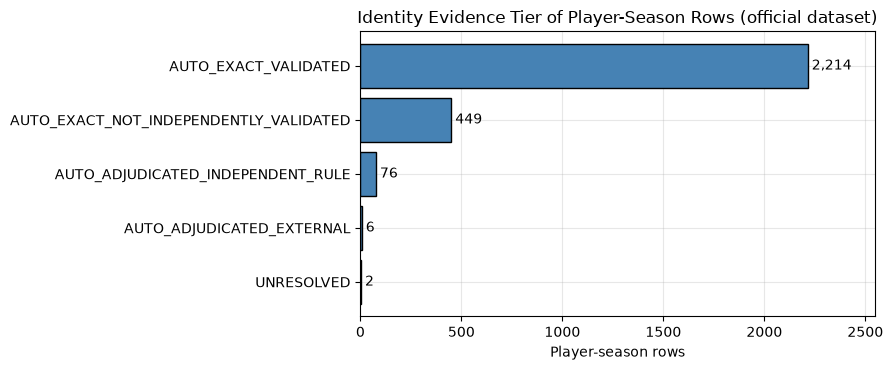

In [34]:
# Identity evidence tier on the rows of the official dataset
tiers = pd.read_parquet(OFFICIAL_DATASET, columns=["identity_evidence_tier"])["identity_evidence_tier"].value_counts()
plt.figure(figsize=(9, 3.8))
bars = plt.barh(tiers.index[::-1], tiers.values[::-1], color=COLOR, edgecolor="black")
plt.bar_label(bars, labels=[f"{v:,}" for v in tiers.values[::-1]], padding=3)
plt.title("Identity Evidence Tier of Player-Season Rows (official dataset)")
plt.xlabel("Player-season rows")
plt.xlim(0, tiers.max() * 1.15)
plt.tight_layout()
plt.show()

**Interpretation**

- **1,226 of 1,228 identities (99.84%)** are mapped: 1,190 by the exact rule and 36 by automated adjudication. Two remain unresolved and have no target.
- **Mapping coverage is not mapping precision**, so the mappings were checked by a person:
  - Round 1: a random sample of 101 automatic exact matches. **101 correct, 0 wrong.** With 0 errors in 101, the 95% upper bound of the wrong-match rate is 3.6% (Clopper-Pearson).
  - Round 2: **all 36** adjudicated mappings (a census, not a sample) and the worst-error players of the error analysis. **All correct.**
- Identity precision (ISS-01) is therefore accepted. The remaining risk is limited to unsampled automatic exact matches, bounded at 3.6%.

## C. Controlled Integration

```text
1. FotMob Confirmed player-seasons (2,747)   --- population, left side of every join
2. Transfermarkt valuation history
3. Player crosswalk (FotMob id -> TM id)
4. Season-end target table (rule D4)
5. LEFT JOIN on (canonical_player_id, season); right keys must be unique,
   row count must not change, otherwise the build stops
6. Integration validation (27 checks)
7. Development release: player_season_integrated_rs5_v1 (+ manifest, dictionary, docs)
```

Multi-club players stay one row; club detail is in `player_team_season_evidence.parquet`. FotMob feature values are carried unchanged.

In [35]:
# Integration validation checks recorded for the official release
validation = read_json("reports/research_scope_rs5/step_03/evidence/integration_validation.json")
checks = pd.DataFrame(validation["checks"])[["check", "status"]]
print(f"Integration checks passed: {validation['passed']} of {validation['total']}")
display(checks)

Integration checks passed: 27 of 27


,check,status
0,five-season whitelist (all official seasons pr...,PASS
1,excluded season rejected (0 rows by label or id),PASS
2,excluded season absent from club evidence,PASS
3,no 2019/20 flag columns remain,PASS
4,player-season uniqueness,PASS
5,record count reconciles with rs5 Confirmed pop...,PASS
6,per-season counts reconcile,PASS
7,canonical id derives from FotMob id,PASS
8,one Transfermarkt id per player across seasons,PASS
9,one player per Transfermarkt id (no many-to-one),PASS


**Interpretation**

All **27 integration checks pass**: the five-season whitelist, rejection of the excluded season, uniqueness of the player-season key, reconciliation with the Confirmed population, one-to-one identity mapping, referential integrity to Transfermarkt ids, target equality with the target table, and the rest. These checks show that the join is structurally correct. They do not show that every identity is correct (Section 05.B).

## D. Holdout Season Identities (2025/26)

The holdout identities were matched with the **same rules** (`matching_v2_1`), without automated adjudication. A person then labelled every new automatic match and every review candidate on the Transfermarkt profile page, without seeing any value or target column.

In [36]:
# Holdout crosswalk, consistency with development, and human labels
ho_cw = pd.read_parquet(ROOT / "data/holdout_2025_26/entity_resolution/matching_v2_1__reviews_none/player_crosswalk.parquet")
display(ho_cw["match_status"].value_counts().to_frame("identities"))

both = ho_cw.merge(crosswalk, on="fotmob_player_id", suffixes=("_holdout", "_dev"))
both = both.dropna(subset=["transfermarkt_player_id_holdout", "transfermarkt_player_id_dev"])
same = int((both["transfermarkt_player_id_holdout"] == both["transfermarkt_player_id_dev"]).sum())
print("Returning players mapped in both runs:", len(both), "| mapped to the same Transfermarkt id:", same)

ho_labels = pd.read_csv(ROOT / "reports/phase_05/holdout/iss01_holdout_labeling.csv", encoding="utf-8-sig")
display(pd.crosstab(ho_labels["sample_reason"], ho_labels["human_label"], margins=True, margins_name="Total"))

,identities
match_status,
AUTO_EXACT,508
REVIEW_REQUIRED,29


Returning players mapped in both runs: 370 | mapped to the same Transfermarkt id: 370


human_label,CORRECT,WRONG,Total
sample_reason,,,
NEW_AUTO_EXACT,136,0,136
REVIEW_REQUIRED,29,22,51
Total,165,22,187


**Interpretation**

- Returning players get exactly the same Transfermarkt identity as in development, which shows the matching rules are stable.
- All 136 new automatic matches were labelled correct. For the 29 identities that needed review, the correct candidate was confirmed for every one of them; the 22 `WRONG` labels are the alternative candidates that were rejected.
- No holdout mapping is wrong, so no holdout row is excluded for identity reasons.

# 06. Final Development Dataset

Objective:
Load the official five-season dataset, prove it is the accepted release, and describe its size and structure.

Steps:
1. Verify the SHA-256 of the file before loading. **If it differs, stop.**
2. Load it and re-check the season scope with the project's validator.
3. Recompute the key statistics and compare them with the official acceptance values.

In [37]:
# 1. Verify the dataset checksum before using it
actual_sha256 = sha256_file(OFFICIAL_DATASET)
print("Dataset:", OFFICIAL_DATASET.relative_to(ROOT).as_posix())
print("Expected SHA-256:", OFFICIAL_SHA256)
print("Actual SHA-256:  ", actual_sha256)
if actual_sha256 != OFFICIAL_SHA256:
    raise RuntimeError("Checksum mismatch: this is not the official research release. Stop and report.")
print("Checksum verified.")

Dataset: data/releases/fb69_player_season_integrated_rs5_v1/player_season_integrated_rs5_v1.parquet
Expected SHA-256: 4d94ec73cfb9d72421fb2bbb1d7976bcf29f8a4f6cc985435955e574b072eedd
Actual SHA-256:   4d94ec73cfb9d72421fb2bbb1d7976bcf29f8a4f6cc985435955e574b072eedd
Checksum verified.


In [38]:
# 2. Load the dataset and validate its seasons with the project implementation
df = pd.read_parquet(OFFICIAL_DATASET)
scope_result = check_parquet(OFFICIAL_DATASET, SCOPE, "season", "season_id")
print("Shape:", df.shape)
print("Seasons in the dataset:", [short(s) for s in scope_result["season"]])
print("Rows outside the official scope:", int((~df["season"].isin(SEASONS)).sum()))
display(df[["canonical_player_id", "season", "fotmob_player_name", "position_group_season",
            "age_at_season_end_years", "m_minutes_played", "m_goals", "target_market_value", "target_status"]].head())

Shape: (2747, 175)
Seasons in the dataset: ['2020/21', '2021/22', '2022/23', '2023/24', '2024/25']
Rows outside the official scope: 0


,canonical_player_id,season,fotmob_player_name,position_group_season,age_at_season_end_years,m_minutes_played,m_goals,target_market_value,target_status
0,fb69p_1010733,2020/2021,Ki-Jana Hoever,DEF,19.34,574.0,0.0,7000000.0,VALID
1,fb69p_101192,2020/2021,James McCarthy,MID,30.53,823.0,0.0,3500000.0,VALID
2,fb69p_101419,2020/2021,Odion Ighalo,FWD,31.93,9.0,0.0,4000000.0,STALE_TARGET
3,fb69p_1017899,2020/2021,Josh Benson,MID,21.46,261.0,0.0,400000.0,STALE_TARGET
4,fb69p_1021586,2020/2021,Gabriel Martinelli,FWD,19.93,587.0,2.0,22000000.0,VALID


In [39]:
# 3. Recompute the key statistics and compare with the official acceptance report
official = {
    "Player-season rows": 2747, "Unique players": 1228, "Usable targets": 2697, "Missing targets": 50,
    "Target coverage (%)": 98.18, "Columns": 175, "Duplicate primary keys": 0, "Duplicate full rows": 0,
}
computed = {
    "Player-season rows": len(df),
    "Unique players": df["canonical_player_id"].nunique(),
    "Usable targets": int(df["target_usable"].sum()),
    "Missing targets": int((~df["target_usable"]).sum()),
    "Target coverage (%)": round(df["target_usable"].mean() * 100, 2),
    "Columns": df.shape[1],
    "Duplicate primary keys": int(df.duplicated(["canonical_player_id", "season"]).sum()),
    "Duplicate full rows": int(df.astype(str).duplicated().sum()),
}
key_stats = pd.DataFrame({"Official result": official, "Recomputed": computed}, dtype=object)
key_stats["Match"] = key_stats["Official result"] == key_stats["Recomputed"]
display(key_stats)
assert key_stats["Match"].all(), "A key statistic differs from the official release"

,Official result,Recomputed,Match
Player-season rows,2747.0,2747.0,True
Unique players,1228.0,1228.0,True
Usable targets,2697.0,2697.0,True
Missing targets,50.0,50.0,True
Target coverage (%),98.18,98.18,True
Columns,175.0,175.0,True
Duplicate primary keys,0.0,0.0,True
Duplicate full rows,0.0,0.0,True


target,Missing target,Usable target,Total
season,,,
2020/21,9,515,524
2021/22,9,528,537
2022/23,12,542,554
2023/24,3,567,570
2024/25,17,545,562


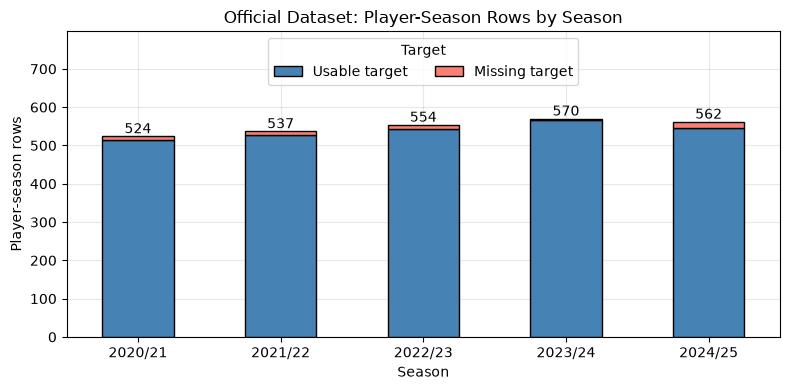

In [40]:
# Player-season rows by season, split by target availability
by_season = (df.assign(target=np.where(df["target_usable"], "Usable target", "Missing target"))
               .pivot_table(index="season", columns="target", aggfunc="size", fill_value=0)
               .rename(index=short))
by_season["Total"] = by_season.sum(axis=1)
display(by_season)
assert by_season["Total"].tolist() == [524, 537, 554, 570, 562]

ax = by_season[["Usable target", "Missing target"]].plot(kind="bar", stacked=True, figsize=(8, 4),
                                                        color=["steelblue", "salmon"], edgecolor="black")
for i, total in enumerate(by_season["Total"]):
    ax.text(i, total + 8, f"{total}", ha="center")
ax.set_title("Official Dataset: Player-Season Rows by Season")
ax.set_xlabel("Season")
ax.set_ylabel("Player-season rows")
ax.set_ylim(0, by_season["Total"].max() * 1.4)
ax.legend(title="Target", ncol=2, loc="upper center")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Interpretation**

- The checksum matches, the validator accepts exactly the five official seasons, and every key statistic equals the official acceptance value.
- Season sizes range from 524 (2020/21) to 570 (2023/24). Missing targets are a small share in every season (between 3 and 17 rows).
- 2,747 is a count of **player-seasons**, not of people: the dataset contains 1,228 distinct players.

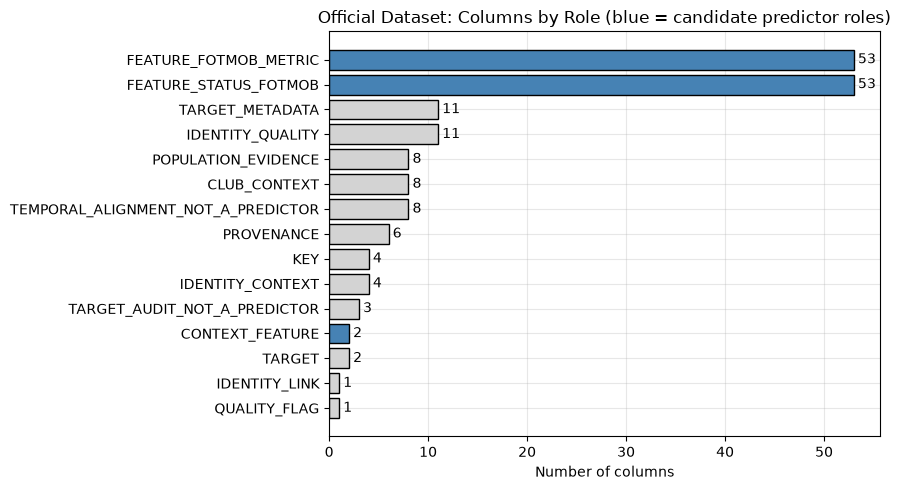

Columns flagged as candidate predictors in the dictionary: 108


In [41]:
# Column roles from the release data dictionary
dictionary = pd.read_csv(ROOT / "data/releases/fb69_player_season_integrated_rs5_v1/data_dictionary.csv")
assert dictionary["column"].tolist() == df.columns.tolist()
roles = dictionary["role"].value_counts()

plt.figure(figsize=(9, 5))
colors = ["steelblue" if r.startswith(("FEATURE", "CONTEXT")) else "lightgray" for r in roles.index[::-1]]
bars = plt.barh(roles.index[::-1], roles.values[::-1], color=colors, edgecolor="black")
plt.bar_label(bars, padding=3)
plt.title("Official Dataset: Columns by Role (blue = candidate predictor roles)")
plt.xlabel("Number of columns")
plt.tight_layout()
plt.show()
print("Columns flagged as candidate predictors in the dictionary:", int(dictionary["candidate_predictor"].sum()))

**Interpretation**

- Of 175 columns, 108 are candidate-predictor roles in the dictionary: 53 FotMob metrics (`m_*`), their 53 status columns (`s_*`) and 2 context features (age at season end, season position group).
- The remaining 67 columns are keys, identity evidence, population evidence, club context, target and target metadata, temporal audit columns and provenance. They exist for **traceability and auditing**, and target, temporal and identity columns must never be used as predictors.
- Which candidates are finally used is a later-phase decision; the Phase 4.0 eligibility register (`reports/phase_04/step_00/`) records the current restrictions.

,players
seasons per player,
1,541
2,243
3,194
4,112
5,138


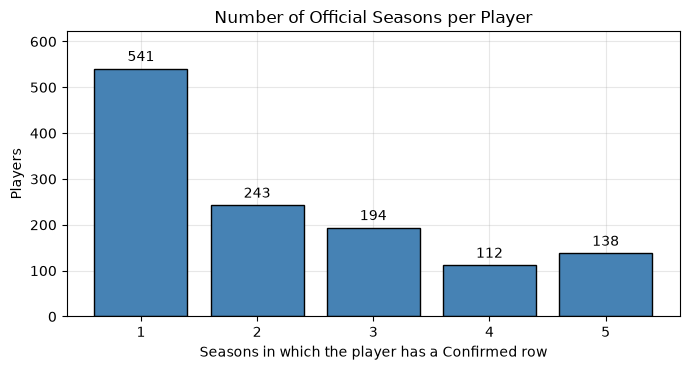

In [42]:
# How many seasons does each player appear in?
seasons_per_player = df.groupby("canonical_player_id")["season"].nunique().value_counts().sort_index()
display(seasons_per_player.rename_axis("seasons per player").to_frame("players"))

plt.figure(figsize=(7, 3.8))
bars = plt.bar(seasons_per_player.index.astype(str), seasons_per_player.values, color=COLOR, edgecolor="black")
plt.bar_label(bars, padding=3)
plt.title("Number of Official Seasons per Player")
plt.xlabel("Seasons in which the player has a Confirmed row")
plt.ylabel("Players")
plt.ylim(0, seasons_per_player.max() * 1.15)
plt.tight_layout()
plt.show()

**Interpretation**

- 541 players appear in one season only; **687 players appear in two or more seasons** (2,206 rows).
- Rows of the same player are not independent. Any later evaluation must split by player or by season; a random row split would place the same player in training and test data.

Usable targets: 2697


,EUR million
mean,19.26
std,20.43
min,0.10
25%,5.00
50%,13.00
75%,25.00
90%,45.00
max,200.00


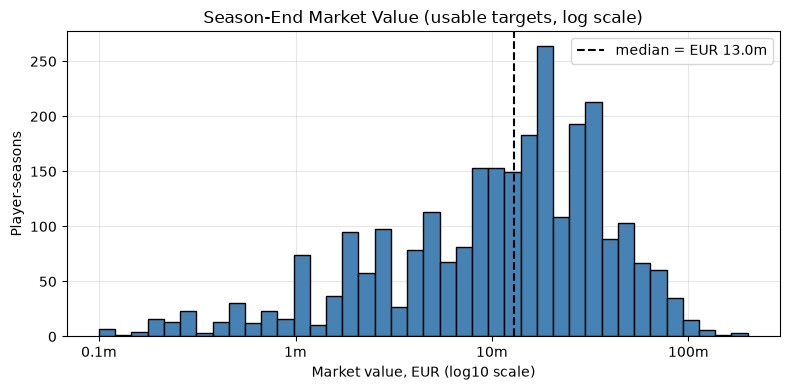

In [43]:
# Basic description of the target (usable rows only)
target = df.loc[df["target_usable"], "target_market_value"]
print("Usable targets:", len(target))
display((target.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).drop("count") / 1e6).round(2).rename("EUR million").to_frame())

plt.figure(figsize=(8, 4))
plt.hist(np.log10(target), bins=40, color=COLOR, edgecolor="black")
ticks = [5, 6, 7, 8]
plt.xticks(ticks, ["0.1m", "1m", "10m", "100m"])
plt.axvline(np.log10(target.median()), color="black", linestyle="--", label=f"median = EUR {target.median() / 1e6:.1f}m")
plt.title("Season-End Market Value (usable targets, log scale)")
plt.xlabel("Market value, EUR (log10 scale)")
plt.ylabel("Player-seasons")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation**

- Median **EUR 13.0 million**, mean **EUR 19.3 million**, maximum **EUR 200 million**, minimum EUR 0.1 million.
- The distribution is strongly right-skewed (the mean is about 1.5 times the median), so a logarithmic scale is the natural way to display it.
- This is a description of the constructed target only; exploratory analysis of its relationships belongs to Phase 4 (sections 4.2 to 4.4; corrected in Phase 4.7).

# 07. Data Quality, Validation and Reproducibility

Objective:
Show which integrity checks support the dataset, re-run the cheap ones live, and read the recorded evidence for the expensive ones.

| Check | How it is shown here |
|---|---|
| Release manifest SHA-256 | Recomputed live for every file |
| Duplicates, key uniqueness | Recomputed live (Section 06) |
| Integration checks | Recorded evidence (`step_03/evidence/integration_validation.json`) |
| Repository test suite | Recorded evidence (`step_05/evidence/final_test_run/`) |
| End-to-end rebuild | Recorded evidence (`step_05/evidence/rs5_reproduction.json`) |
| Historical artifact protection | Recorded evidence (`step_05/evidence/protection_check_final.json`) |

In [44]:
# Recompute the checksum of every file listed in the release manifest
RELEASE = OFFICIAL_DATASET.parent
release_manifest = read_json(RELEASE.relative_to(ROOT) / "release_manifest.json")
manifest_check = pd.DataFrame([{
    "file": f["path"],
    "bytes": f["bytes"],
    "sha256 ok": (RELEASE / f["path"]).exists() and sha256_file(RELEASE / f["path"]) == f["sha256"],
} for f in release_manifest["files"]])
print(f"Release files verified: {manifest_check['sha256 ok'].sum()} of {len(manifest_check)}")
display(manifest_check)

Release files verified: 21 of 21


,file,bytes,sha256 ok
0,data_dictionary.csv,9841,True
1,docs/DATA_CONTRACT_RS5.md,3838,True
2,docs/DATA_QUALITY_REPORT.md,3757,True
3,docs/ENTITY_RESOLUTION_REPORT.md,5359,True
4,docs/feature_reliability.csv,12986,True
5,docs/FEATURE_RELIABILITY_ASSESSMENT.md,2881,True
6,docs/ISSUE_TRACKER.md,6992,True
7,docs/leakage_audit.csv,39776,True
8,docs/LEAKAGE_AUDIT.md,5542,True
9,docs/MISSINGNESS_REPORT.md,2279,True


In [45]:
# Recorded validation evidence of the final acceptance (Phase 3R, G5)
E5 = "reports/research_scope_rs5/step_05/evidence"
tests = read_json(f"{E5}/final_test_run/full_repository_test_run.json")
repro = read_json(f"{E5}/rs5_reproduction.json")
protection = read_json(f"{E5}/protection_check_final.json")

evidence = pd.DataFrame([
    {"Check": "Integration checks", "Passed": validation["passed"], "Total": validation["total"]},
    {"Check": "Repository tests (protected runner)", "Passed": tests["tests_run"] if tests["ok"] else 0, "Total": tests["tests_run"]},
    {"Check": "Rebuilt files byte-identical", "Passed": repro["files_compared"] - len(repro["failed"]), "Total": repro["files_compared"]},
    {"Check": "Release manifest files (live)", "Passed": int(manifest_check["sha256 ok"].sum()), "Total": len(manifest_check)},
    {"Check": "Historical files: no unexpected change", "Passed": protection["historical_files"] - len(protection["unexpected_changes"]) - len(protection["removed"]),
     "Total": protection["historical_files"]},
])
evidence["Pass rate (%)"] = (evidence["Passed"] / evidence["Total"] * 100).round(1)
display(evidence)
print("Test run exit code:", tests["exit_code"], "| rebuild all identical:", repro["all_identical"],
      "| documented historical edits:", protection["documented_edits_changed"])
print("Environment recorded for the rebuild:", repro["environment"])

,Check,Passed,Total,Pass rate (%)
0,Integration checks,27,27,100.0
1,Repository tests (protected runner),437,437,100.0
2,Rebuilt files byte-identical,69,69,100.0
3,Release manifest files (live),21,21,100.0
4,Historical files: no unexpected change,16290,16290,100.0


Test run exit code: 0 | rebuild all identical: True | documented historical edits: ['CLAUDE.md']
Environment recorded for the rebuild: {'python': '3.14.6', 'pyarrow': '24.0.0', 'duckdb': '2.0.0'}


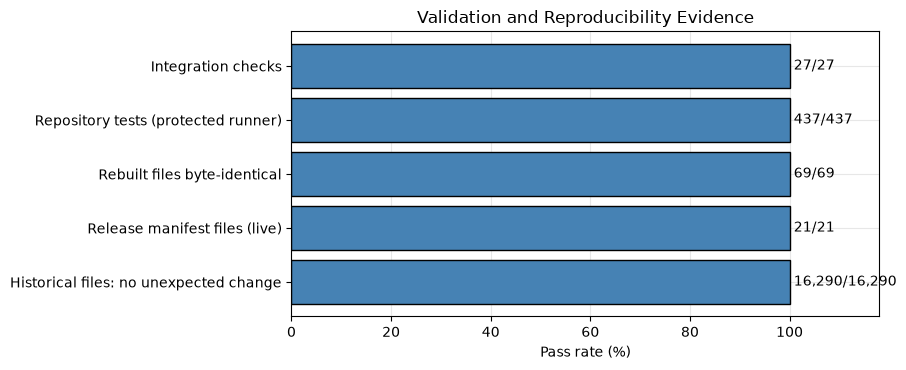

In [46]:
# Visualize the validation results
plt.figure(figsize=(9, 3.8))
bars = plt.barh(evidence["Check"][::-1], evidence["Pass rate (%)"][::-1], color=COLOR, edgecolor="black")
plt.bar_label(bars, labels=[f"{p:,}/{t:,}" for p, t in zip(evidence["Passed"][::-1], evidence["Total"][::-1])], padding=3)
plt.title("Validation and Reproducibility Evidence")
plt.xlabel("Pass rate (%)")
plt.xlim(0, 118)
plt.tight_layout()
plt.show()

**Interpretation**

What these checks **demonstrate**:
- The file analysed here is byte-for-byte the accepted release, and every release file matches its manifest.
- The dataset has one row per player-season, no duplicates, only official seasons, and a join that neither lost nor multiplied rows.
- The whole five-season pipeline can be rebuilt from frozen sources with **identical bytes** (69 of 69 files), and historical artifacts were not altered.
- 437 of 437 repository tests passed in the recorded run.

What they do **not** demonstrate:
- That every identity mapping is correct (no human validation yet).
- That the label and the features describe the same time window (Section 08).
- That missing values are missing at random.
- That FotMob's own values are free of source error.

Note on the environment: the recorded rebuild ran on Python 3.14.6 with pyarrow 24.0.0 and duckdb 2.0.0 (the project's `.venv314`). This notebook only reads that recorded evidence; it does not re-run the test suite or the rebuild.

## D. Dataset Limitations

### Label–Feature Timing Mismatch

The target is the latest valuation **on or before** the season end. Transfermarkt revalues players in league-wide batches during the season, so the selected valuation is often several months old at the season end, while FotMob metrics are **whole-season totals**. The indicators below are recomputed from the dataset's temporal audit columns.

In [47]:
# Temporal alignment indicators (usable targets only)
usable = df[df["target_usable"]]
games_after = usable["temporal_player_games_after_valuation"].sum()
games_total = usable["temporal_player_games_in_season"].sum()
minutes_after = usable["temporal_minutes_after_valuation"].sum()
minutes_total = minutes_after + usable["temporal_minutes_before_or_on_valuation"].sum()

timing = pd.Series({
    "Median valuation age (days)": usable["target_valuation_age_days"].median(),
    "Targets older than 90 days (%)": round((usable["target_valuation_age_days"] > 90).mean() * 100, 2),
    "Appearances after the valuation (%)": round(games_after / games_total * 100, 2),
    "Minutes after the valuation (%)": round(minutes_after / minutes_total * 100, 2),
    "Targets older than 365 days": int((usable["target_valuation_age_days"] > 365).sum()),
    "Valuations after the cutoff": int((usable["target_valuation_age_days"] < 0).sum()),
}, name="value")
display(timing.to_frame())

,value
Median valuation age (days),150.00
Targets older than 90 days (%),56.62
Appearances after the valuation (%),44.10
Minutes after the valuation (%),43.66
Targets older than 365 days,12.00
Valuations after the cutoff,0.00


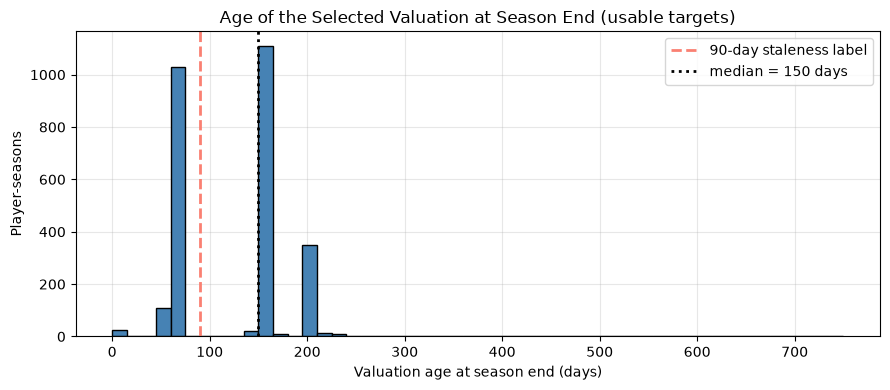

In [48]:
# Distribution of valuation age at the season end
plt.figure(figsize=(9, 4))
plt.hist(usable["target_valuation_age_days"], bins=range(0, 760, 15), color=COLOR, edgecolor="black")
plt.axvline(90, color="salmon", linestyle="--", linewidth=2, label="90-day staleness label")
plt.axvline(usable["target_valuation_age_days"].median(), color="black", linestyle=":", linewidth=2,
            label=f"median = {usable['target_valuation_age_days'].median():.0f} days")
plt.title("Age of the Selected Valuation at Season End (usable targets)")
plt.xlabel("Valuation age at season end (days)")
plt.ylabel("Player-seasons")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation**

- The median selected valuation is **150 days** old at the season end; **56.62%** of usable targets are older than 90 days.
- The histogram is made of separate spikes rather than a smooth curve: Transfermarkt revalues the league in batches, so most players of a season share the same valuation date and therefore the same age.
- **44.10% of appearances and 43.66% of minutes** in the feature window happened **after** the valuation date.
- No valuation after the cutoff is ever used, so this is **not leakage** of future target information. It is a **construct mismatch**: the label is mostly a mid-season valuation, while the features cover the full season.
- Therefore a relationship between season statistics and the target must **not** be read as evidence that later-season performance caused an earlier valuation. The project keeps rule D4 and reports the mismatch (issue RD-03) with every result.
- 12 targets are older than 365 days (the oldest, dated 2019-05-23, belongs to a 2020/21 row; it is an old valuation date, not 2019/20 season data). They are kept and reported (RD-01); no age cap is applied.

### Missing Values Are Not Random

In [49]:
# Mean number of null metrics per row (out of 53), by target availability and by position group
missing_by_target = df.groupby(np.where(df["target_usable"], "usable target", "missing target"))["missing_feature_count"].mean()
missing_by_position = df.groupby("position_group_season")["missing_feature_count"].mean()
display(pd.concat({"by target availability": missing_by_target, "by position group": missing_by_position})
        .round(2).rename("mean null metrics per row").to_frame())

mean null metrics per row
by target availability missing target                      42.10
                       usable target                       17.03
by position group      DEF                                 15.01
                       FWD                                 17.92
                       GK                                  34.49
                       MID                                 15.69

**Interpretation**

- Rows without a target have about 42 null metrics out of 53, against about 17 for rows with a target. Goalkeepers have about 34, because most outfield metrics do not apply to them.
- Missingness therefore concentrates in fringe players and goalkeepers. Dropping incomplete rows, or filling nulls with zero, would bias any later analysis. Nothing is imputed at any point of this project (section 09.E).

### Limitations Register and How Each Is Handled

| ID | Limitation | Effect | Handling |
|---|---|---|---|
| ISS-01 | Identity mappings could be wrong | Wrong targets | Human labelling: 0 wrong in 101 random + 36 adjudicated (section 05.B) |
| RD-03 | Mid-season label vs full-season features | No causal reading of results | Rule D4 kept; stated with every result |
| RS5-11 | 687 players appear in several seasons | Random splits leak identity | Grouped-by-player cross-validation (section 10) |
| ISS-27 / ISS-25 | Non-random missingness; a null may mean "no event" | Bias if handled carelessly | No imputation, no zero-fill; model with native null handling (section 09) |
| ISS-28 | `key_passes` empty; `clearances` in 3 of 5 seasons | Season-dependent availability | Both excluded from the model |
| ISS-29 | 8 source-reported rates cannot be verified independently | Reliability unknown | Two used as features, reported as a risk (section 09.D) |
| RD-04 | 5 metrics with incomplete window evidence | Possible bias | Excluded from the model |
| ISS-04 | 2 identities unresolved | 2 rows without target | Outside the modeling population |
| RS5-13 | Metrics collected retrospectively; 95 cells revised by the source | Values may differ from the season-end view | Documented |
| ISS-21 | Valuations come in league-wide batches | Season and target timing confounded | Season is not a feature; results reported per season |
| ISS-16 | Upstream Transfermarkt rights unverified | Internal academic use only | Accepted |

Full registers: `reports/research_scope_rs5/step_04/ISSUE_TRACKER.md` and `reports/phase_04/step_00/PHASE4_CONDITION_REGISTER.md`.

## E. Summary of the Data Stage

- **Data acquisition was evidence-driven and gated.** A bounded audit established what FotMob offers and what it does not (no roster, no working `playerMatches`, present-day profiles). A 120-player-season pilot (265/265 requests) exposed design defects early. A hardening phase added content-derived request keys, immutable checksummed captures, a verified cache, resume and stop rules, and showed that "received", "parsed" and "usable" are different things (23/23, 23/23, 21/23).
- **The full crawl** collected every completed match and every appeared player under explicit 50-attempt batches with one worker (7,177 attempts, 14 unusable null responses kept out of the accepted lineage). The population was derived from lineups, and unconfirmed bench appearances remain `UNKNOWN`.
- **The target** comes from a pinned public Transfermarkt snapshot, not from scraping, and follows a strict no-future-valuation rule (D4) under end-of-season estimation (D6).
- **The development dataset** `player_season_integrated_rs5_v1` has 2,747 player-seasons, 1,228 players, 175 columns and 2,697 usable targets (98.18%) over five seasons, verified here by checksum, scope validator and recomputed statistics. Identity mappings were checked by a person with no error found.
- **The holdout season 2025/26** was collected with the same frozen code (section 03.G, 04.D) and is not used before section 13.
- **Limitations are explicit:** the label is mostly a mid-season valuation and missingness is not random. These conditions travel with the dataset into the EDA and the modeling.

---

# 08. Exploratory Data Analysis (EDA)

The EDA explores the development dataset before any feature or modeling work. It is organised in eight steps:

| Step | Topic | Question |
|---|---|---|
| 8.0 | Dataset acceptance | Is the dataset fit for EDA, and under which conditions? |
| 8.1 | Dataset profiling and structural EDA | What does the dataset contain, and is it structurally sound? |
| 8.2 | Target and univariate analysis | How are the target and each feature distributed? |
| 8.3 | Bivariate analysis | How do features relate to the target and to each other? |
| 8.4 | Multivariate and group analysis | How heterogeneous is the population across positions, seasons and groups? |
| 8.5 | Missingness, temporal and data reliability | How trustworthy are the observations? |
| 8.6 | Feature assessment and modeling feasibility | Which features are promising, and is regression feasible? |
| 8.7 | EDA synthesis | What does the EDA hand over to the modeling stage? |

Rules followed by every EDA step (`reports/phase_04/step_00/PHASE4_ENTRY_CHECKLIST.md`):
- **Development data only**, verified by SHA-256; seasons come from `load_scope()`. The 2025/26 holdout season is never used here.
- End-of-season estimation (D6). No forecasting claims; no causal reading of relationships.
- Null is not zero. No imputation, no filtering, no correction of published values.
- `target_*`, `temporal_*`, identity and id columns are never predictors.
- The EDA describes; it does not choose. Questions it leaves open are marked *pending design decision* and are answered by the modeling design (summary table in section 8.7.F).

## 8.1 Dataset Profiling & Structural EDA

Objective:
Describe what the official research dataset contains and how it is structured, and find structural anomalies that later EDA must take into account.

Research questions:
1. What does the dataset contain, and how many players and player-season observations does it hold?
2. How is it structured: which columns, types, roles and eligibility categories?
3. How are rows distributed across the five official seasons and across positions?
4. What does the player population look like in terms of appearances and minutes?
5. Where are values missing, and how are missing values coded?
6. Are there structural anomalies (duplicates, invalid types or values, unexpected categories, constant columns, inconsistent counts)?

Methodology:
- All numbers come from `src/phase4/profiling.py`. The same functions write the recorded evidence in `reports/phase_04/step_01/evidence/`, so the notebook and the evidence cannot drift apart.
- The dataset is verified by SHA-256 **before** it is read; a mismatch stops the analysis.
- Column roles and eligibility come from the existing registers (`data_dictionary.csv`, step 8.0 `phase4_feature_eligibility.csv`); no new classification is invented.
- Missing values are counted together with their source status (`s_*` columns). `UNKNOWN`/`UNVERIFIED` values are never treated as zero.
- Out of scope here: target analysis, feature-target relationships, correlations, outlier treatment, feature selection.

### A. Data Loading, Hash Verification and Scope

The loader verifies the SHA-256 first, then validates the seasons with the project's `check_parquet()`, and only then reads the rows.

In [50]:
from src.phase4 import profiling as prof

df41, schema41, scope41, verification41 = prof.load_verified()
dictionary41, eligibility41, reliability41 = prof.load_metadata()

print("SHA-256 verified:", verification41["sha256"] == prof.DATASET_SHA256)
print("Rows per season (check_parquet):", verification41["scope_check"]["season"])
print("Excluded seasons present:", sorted(set(df41["season"]) & set(scope41.excluded_labels)))

SHA-256 verified: True
Rows per season (check_parquet): {'2020/2021': 524, '2021/2022': 537, '2022/2023': 554, '2023/2024': 570, '2024/2025': 562}
Excluded seasons present: []


### B. Dataset Overview

In [51]:
overview41 = prof.overview(df41, scope41)
display(pd.Series(overview41, name="value").to_frame())

,value
rows,2747
columns,175
unique_players,1228
player_season_records,2747
usable_targets,2697
missing_targets,50
target_coverage_pct,98.18
seasons,5
seasons_equal_scope,True
duplicated_full_rows,0


**Interpretation**

- **2,747 player-season rows** for **1,228 players** over the **5 official seasons**; the primary key (`canonical_player_id`, `season`) is complete and unique, and there are no duplicated rows.
- **2,697 rows (98.18%)** carry a usable target; **50** do not.
- Every row is one player in one season, so there is exactly one row per player per season (Section C confirms that the number of unique players per season equals the number of rows).

### C. Schema and Column Profiling

Every column is profiled for its type, role, eligibility category (from the step 8.0 register), nulls, distinct values, constant behaviour and domain-invalid values.

In [52]:
profile41 = prof.schema_profile(df41, schema41, dictionary41, eligibility41)
display(prof.role_summary(profile41))
print("Types differing from the data dictionary:", prof.type_checks(schema41, dictionary41))
print("Columns with domain-invalid values:", int((profile41["invalid_values"] > 0).sum()))

,columns,mean_missing_pct,constant_columns
eligibility_category,,,
STATUS_MISSINGNESS,53,0.00,0
CANDIDATE_PREDICTOR,41,23.26,0
IDENTITY_METADATA,33,8.82,10
CONDITIONAL_PREDICTOR,21,33.11,0
TARGET,16,7.88,1
TEMPORAL_AUDIT,8,1.14,1
EXCLUDED_PREDICTOR,3,33.33,2


Types differing from the data dictionary: []
Columns with domain-invalid values: 0


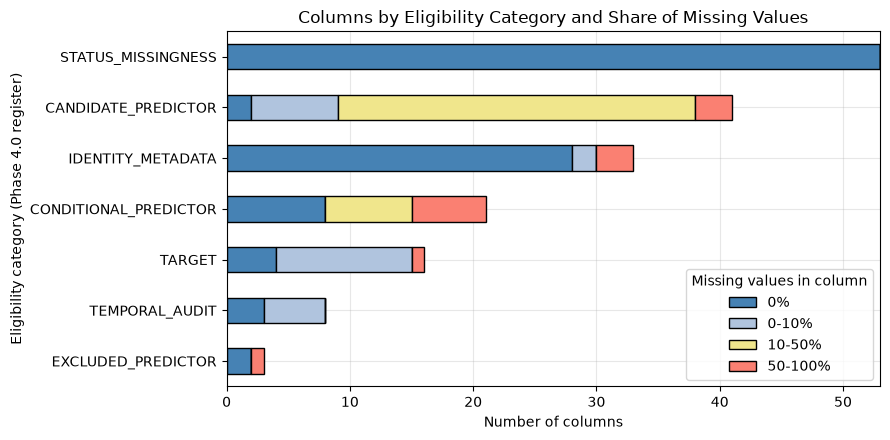

In [53]:
# Columns per eligibility category, split by how much of the column is missing
bins = pd.cut(profile41["missing_pct"], [-0.1, 0, 10, 50, 100], labels=["0%", "0-10%", "10-50%", "50-100%"])
table = pd.crosstab(profile41["eligibility_category"], bins).loc[prof.role_summary(profile41).index]
ax = table.plot(kind="barh", stacked=True, figsize=(9, 4.5), edgecolor="black",
                color=["steelblue", "lightsteelblue", "khaki", "salmon"])
ax.set_title("Columns by Eligibility Category and Share of Missing Values")
ax.set_xlabel("Number of columns")
ax.set_ylabel("Eligibility category (Phase 4.0 register)")
ax.invert_yaxis()
ax.legend(title="Missing values in column", loc="lower right")
plt.tight_layout()
plt.show()

In [54]:
# Columns that carry no variation
print("Constant columns (one value on every row):")
display(profile41.loc[profile41["constant"], ["column", "role", "top_value_share_pct", "missing_pct"]])
print("Single value plus nulls:", profile41.loc[profile41["single_value_with_nulls"], "column"].tolist())
print("Near-constant (top value >= 99% of rows):", profile41.loc[profile41["near_constant"], "column"].tolist())

Constant columns (one value on every row):


,column,role,top_value_share_pct,missing_pct
9,population_status,POPULATION_EVIDENCE,100.0,0.0
10,population_category,POPULATION_EVIDENCE,100.0,0.0
11,classification_reason,POPULATION_EVIDENCE,100.0,0.0
12,profile_status,POPULATION_EVIDENCE,100.0,0.0
39,target_selection_rule_version,TARGET_METADATA,100.0,0.0
48,identity_human_reviewed,IDENTITY_QUALITY,100.0,0.0
52,matching_version,IDENTITY_QUALITY,100.0,0.0
57,temporal_league_games_in_season,TEMPORAL_ALIGNMENT_NOT_A_PREDICTOR,100.0,0.0
63,dataset_version,PROVENANCE,100.0,0.0
64,research_scope_id,PROVENANCE,100.0,0.0


Single value plus nulls: ['target_currency', 'target_source_file_sha256', 'identity_adjudicator']
Near-constant (top value >= 99% of rows): ['identity_match_status', 's_appearances']


In [55]:
# The full schema profile (175 columns), most incomplete first
display(profile41.sort_values("missing_pct", ascending=False)
        [["column", "arrow_type", "role", "eligibility_category", "non_null", "null", "missing_pct", "unique", "constant"]]
        .head(25))

,column,arrow_type,role,eligibility_category,non_null,null,missing_pct,unique,constant
99,m_key_passes,double,FEATURE_FOTMOB_METRIC,EXCLUDED_PREDICTOR,0,2747,100.00,0,True
30,target_missing_reason,string,TARGET_METADATA,TARGET,50,2697,98.18,3,False
50,identity_adjudication_confidence,string,IDENTITY_QUALITY,IDENTITY_METADATA,82,2665,97.01,2,False
49,identity_adjudicator,string,IDENTITY_QUALITY,IDENTITY_METADATA,82,2665,97.01,1,False
51,identity_adjudication_basis,string,IDENTITY_QUALITY,IDENTITY_METADATA,82,2665,97.01,3,False
104,m_penalty_saves,double,FEATURE_FOTMOB_METRIC,CANDIDATE_PREDICTOR,141,2606,94.87,4,False
96,m_goals_prevented,double,FEATURE_FOTMOB_METRIC,CONDITIONAL_PREDICTOR,180,2567,93.45,165,False
109,m_save_percentage,double,FEATURE_FOTMOB_METRIC,CONDITIONAL_PREDICTOR,197,2550,92.83,119,False
81,m_clean_sheets,double,FEATURE_FOTMOB_METRIC,CONDITIONAL_PREDICTOR,198,2549,92.79,20,False
110,m_saves,double,FEATURE_FOTMOB_METRIC,CANDIDATE_PREDICTOR,198,2549,92.79,104,False


**Interpretation**

- All 175 column types match the data dictionary, and no column holds a value outside its domain (counts are never negative, percentages stay within 0-100, ratings within 0-10, ages within 15-45, targets are positive and never dated after the cutoff).
- **14 columns are constant.** Most are provenance or population descriptors that are constant by construction: every row is `APPEARED`/`CONFIRMED_APPEARED`, every row comes from the same dataset, source and rule versions, and `identity_human_reviewed` is `False` everywhere. `temporal_league_games_in_season` is 380 in every season. `m_key_passes` is empty and `s_key_passes` is always `UNSUPPORTED`. None of these columns carries information for later analysis.
- Three columns hold one value plus nulls (`target_currency`, `target_source_file_sha256`, `identity_adjudicator`): they are filled only where a target or an adjudication exists.
- The status columns (`s_*`) are complete (0% missing); missing values sit in the metric columns, target metadata and identity metadata.

### D. Season Distribution

In [56]:
seasons41 = prof.season_distribution(df41, scope41)
display(seasons41.rename(index=prof.short))

,rows,unique_players,usable_targets,missing_targets,share_of_rows_pct,target_coverage_pct,returning_from_previous_season
season,,,,,,,
2020/21,524,524,515,9,19.08,98.28,NaN
2021/22,537,537,528,9,19.55,98.32,349.0
2022/23,554,554,542,12,20.17,97.83,337.0
2023/24,570,570,567,3,20.75,99.47,350.0
2024/25,562,562,545,17,20.46,96.98,352.0


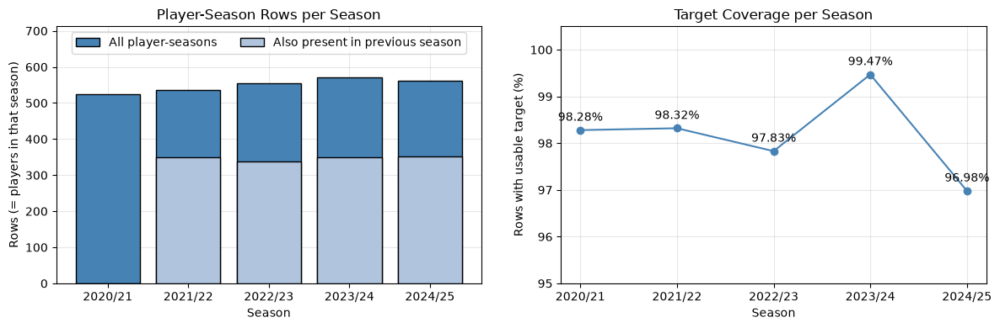

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
labels = [prof.short(s) for s in seasons41.index]

axes[0].bar(labels, seasons41["rows"], color="steelblue", edgecolor="black", label="All player-seasons")
axes[0].bar(labels, seasons41["returning_from_previous_season"].fillna(0), color="lightsteelblue",
            edgecolor="black", label="Also present in previous season")
axes[0].set_title("Player-Season Rows per Season")
axes[0].set_xlabel("Season")
axes[0].set_ylabel("Rows (= players in that season)")
axes[0].set_ylim(0, seasons41["rows"].max() * 1.25)
axes[0].legend(loc="upper center", ncol=2)

axes[1].plot(labels, seasons41["target_coverage_pct"], marker="o", color="steelblue")
for x, y in zip(labels, seasons41["target_coverage_pct"]):
    axes[1].annotate(f"{y:.2f}%", (x, y), textcoords="offset points", xytext=(0, 8), ha="center")
axes[1].set_title("Target Coverage per Season")
axes[1].set_xlabel("Season")
axes[1].set_ylabel("Rows with usable target (%)")
axes[1].set_ylim(95, 100.5)
plt.tight_layout()
plt.show()

**Interpretation**

- Seasons are balanced: each contributes between **19.1% and 20.8%** of the rows (524 to 570).
- Unique players per season equal rows per season: no player has two rows in the same season, including multi-club players.
- Between **337 and 352 players** per season also appear in the previous season, so roughly two thirds of each season's population is returning. The seasons are therefore **not independent samples of players**, which matters for later splits.
- Target coverage stays between **96.98% (2024/25)** and **99.47% (2023/24)**.

### E. Player Population

The population consists of Confirmed player-seasons only: a player is included when lineup evidence shows that he started or came on in at least one match. Position is the season's modal lineup position (`position_group_season`).

position_group_season,GK,DEF,MID,FWD,total
season,,,,,
2020/21,41,186,152,145,524
2021/22,42,182,155,158,537
2022/23,39,183,178,154,554
2023/24,40,191,180,159,570
2024/25,44,193,174,151,562


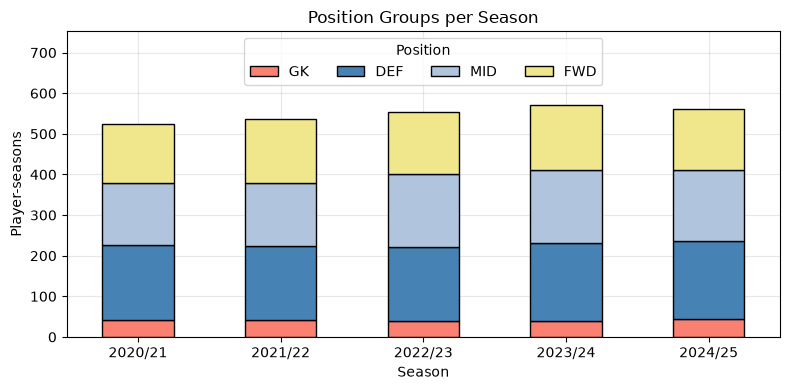

In [58]:
positions41 = prof.position_by_season(df41, scope41)
display(positions41.rename(index=prof.short).assign(total=lambda t: t.sum(axis=1)))

ax = positions41.rename(index=prof.short).plot(kind="bar", stacked=True, figsize=(8, 4), edgecolor="black",
                                               color=["salmon", "steelblue", "lightsteelblue", "khaki"])
ax.set_title("Position Groups per Season")
ax.set_xlabel("Season")
ax.set_ylabel("Player-seasons")
ax.set_ylim(0, positions41.sum(axis=1).max() * 1.32)
ax.legend(title="Position", ncol=4, loc="upper center")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

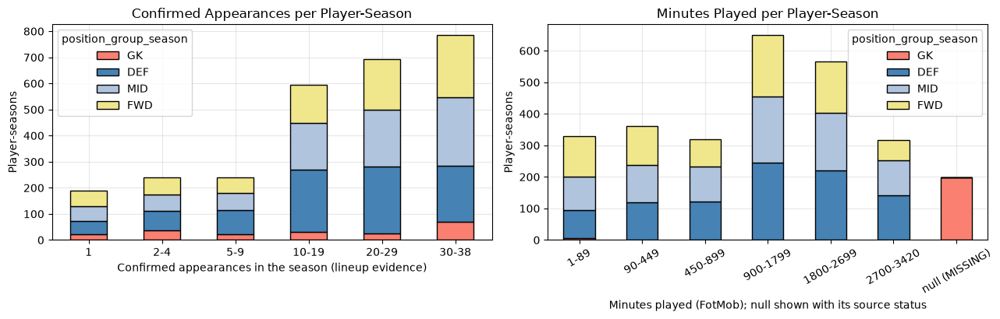

position_group_season,GK,DEF,MID,FWD
minutes played,,,,
1-89,7,88,106,129
90-449,0,119,120,123
450-899,0,121,111,88
900-1799,0,245,209,197
1800-2699,0,221,182,164
2700-3420,0,141,111,66
null (MISSING),199,0,0,0


In [59]:
appearances41 = prof.appearance_profile(df41)
minutes41 = prof.minutes_profile(df41)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
appearances41.plot(kind="bar", stacked=True, ax=axes[0], edgecolor="black",
                   color=["salmon", "steelblue", "lightsteelblue", "khaki"])
axes[0].set_title("Confirmed Appearances per Player-Season")
axes[0].set_xlabel("Confirmed appearances in the season (lineup evidence)")
axes[0].set_ylabel("Player-seasons")
axes[0].tick_params(axis="x", rotation=0)

minutes41.plot(kind="bar", stacked=True, ax=axes[1], edgecolor="black",
               color=["salmon", "steelblue", "lightsteelblue", "khaki"])
axes[1].set_title("Minutes Played per Player-Season")
axes[1].set_xlabel("Minutes played (FotMob); null shown with its source status")
axes[1].set_ylabel("Player-seasons")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
display(minutes41)

In [60]:
display(prof.low_playing_time(df41))
display(prof.gk_vs_outfield(df41))
display(prof.appearance_evidence_agreement(df41))
print("Outside the dataset (FotMob rs5 release):", prof.population_context())

,rows,share_pct,goalkeepers,target_coverage_pct,mean_null_metrics
group,,,,,
1 confirmed appearance,190,6.92,22,83.68,43.99
2-4 confirmed appearances,241,8.77,36,93.36,34.22
minutes < 90 (reported),330,12.01,7,87.88,43.61
minutes null,199,7.24,199,100.00,34.06
all rows,2747,100.00,206,98.18,17.49


,rows,unique_players,median_confirmed_appearances,minutes_null_pct,target_coverage_pct,mean_null_metrics
Goalkeeper,206,95,17.0,96.6,100.00,34.49
Outfield,2541,1133,21.0,0.0,98.03,16.11


,reported,lineup_evidence,compared,equal,reported_higher,reported_lower,reported_null
0,m_appearances,confirmed_appearance_count,2746,2746,0,0,1
1,m_starts,started_match_count,2746,2733,13,0,1


Outside the dataset (FotMob rs5 release): {'player_seasons': 3438, 'confirmed_appeared': 2747, 'unverified': 691, 'unknown_player_matches': 20184}


**Interpretation**

- Each season has **39-44 goalkeepers, 182-193 defenders, 152-180 midfielders and 145-159 forwards**; goalkeepers make up 7.5% of rows (206 rows, 95 players).
- Playing time is very uneven. **190 rows (6.9%) have a single confirmed appearance** and **330 rows (12.0%) report fewer than 90 minutes**. These rows have far more missing metrics (about 44 of 53) and lower target coverage (84% for single-appearance rows). They are part of the population; nothing is removed.
- **Minutes are null for 199 of the 206 goalkeeper rows** (status `MISSING`), never for outfield rows. Goalkeeper minutes are therefore essentially unavailable (known issue ISS-11); this null must not be read as zero minutes.
- Every row has at least one confirmed appearance, by construction. Players without a confirmed appearance are **not** in the dataset: the FotMob release counts **691 Unverified** player-seasons (bench listings with `UNKNOWN` participation), excluded from the research population and never counted as zero.
- The two independent derivations of appearances agree: FotMob-reported `m_appearances` equals lineup-confirmed appearances on all 2,746 comparable rows. Reported starts exceed lineup-confirmed starts on **13 rows** (known issue ISS-30); see Section G.

### F. Missingness Overview

Missingness is measured on the 53 FotMob metric columns (`m_*`). For goalkeeper-only metrics it is also measured on the rows where the metric applies (goalkeeper rows). Every null is paired with the source status that explains it.

In [61]:
display(pd.Series(prof.missingness_overview(df41), name="value").to_frame())
families41 = prof.missingness_by_family(df41, reliability41)
display(families41)

,value
metric_null_cells,48043.00
metric_cells,145591.00
metric_null_pct,33.00
all_null_cells,59755.00
all_cells,480725.00
all_null_pct,12.43
columns_with_nulls,75.00
metrics_with_nulls,53.00


,metrics,null_pct
family,,
GENERAL,7,7.96
EXPECTED,4,18.20
ATTACK,9,22.67
PASSING,10,28.63
DEFENDING,16,29.86
GOALKEEPING,7,93.19


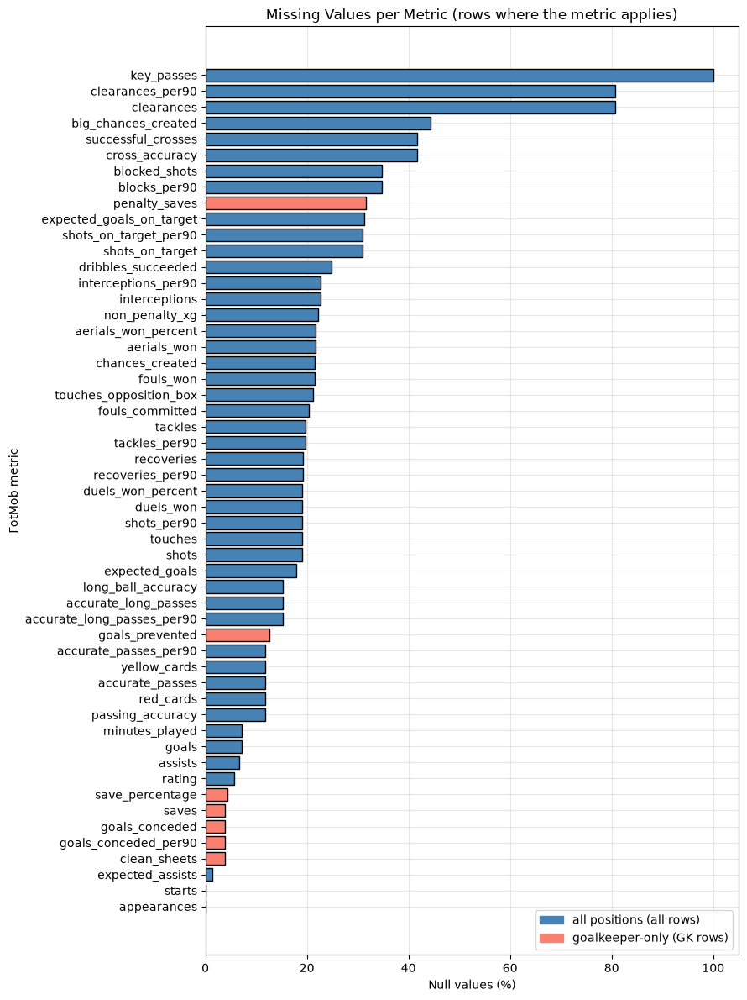

In [62]:
by_metric41 = prof.missingness_by_column(df41, reliability41).sort_values("null_pct_applicable_rows")
colors = ["salmon" if a == "GK" else "steelblue" for a in by_metric41["applies_to"]]
plt.figure(figsize=(9, 12))
plt.barh(by_metric41["metric"].str[2:], by_metric41["null_pct_applicable_rows"], color=colors, edgecolor="black")
plt.title("Missing Values per Metric (rows where the metric applies)")
plt.xlabel("Null values (%)")
plt.ylabel("FotMob metric")
plt.xlim(0, 105)
from matplotlib.patches import Patch
plt.legend(handles=[Patch(color="steelblue", label="all positions (all rows)"),
                    Patch(color="salmon", label="goalkeeper-only (GK rows)")], loc="lower right")
plt.tight_layout()
plt.show()

metric_null_pct  mean_null_metrics_per_row
season   2020/21                   32.84                      17.41
         2021/22                   32.34                      17.14
         2022/23                   33.79                      17.91
         2023/24                   34.50                      18.29
         2024/25                   31.47                      16.68
position GK                        65.07                      34.49
         DEF                       28.32                      15.01
         MID                       29.59                      15.69
         FWD                       33.81                      17.92
target   missing target            79.43                      42.10
         usable target             32.14                      17.03

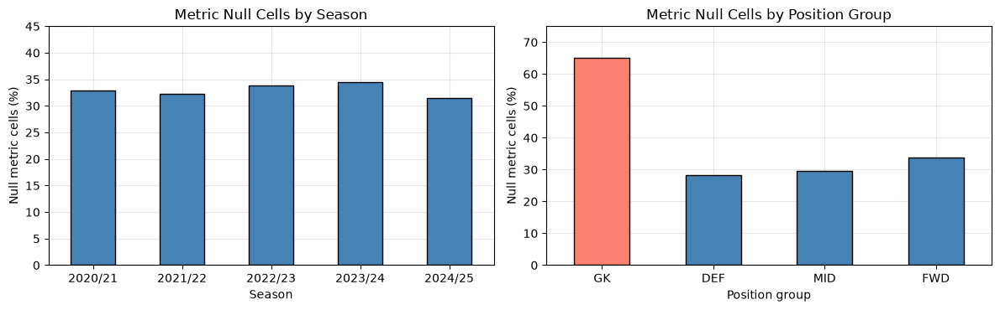

In [63]:
by_season41 = prof.missingness_by_group(df41, "season", list(scope41.labels)).rename(index=prof.short)
by_position41 = prof.missingness_by_group(df41, "position_group_season", prof.POSITION_ORDER)
by_target41 = prof.missingness_by_group(df41, "target_usable").rename(index={True: "usable target", False: "missing target"})
display(pd.concat({"season": by_season41, "position": by_position41, "target": by_target41}))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
by_season41["metric_null_pct"].plot(kind="bar", ax=axes[0], color="steelblue", edgecolor="black")
axes[0].set_title("Metric Null Cells by Season")
axes[0].set_xlabel("Season")
axes[0].set_ylabel("Null metric cells (%)")
axes[0].set_ylim(0, 45)
axes[0].tick_params(axis="x", rotation=0)
by_position41["metric_null_pct"].plot(kind="bar", ax=axes[1], color=["salmon", "steelblue", "steelblue", "steelblue"], edgecolor="black")
axes[1].set_title("Metric Null Cells by Position Group")
axes[1].set_xlabel("Position group")
axes[1].set_ylabel("Null metric cells (%)")
axes[1].set_ylim(0, 75)
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

In [64]:
# How nulls are coded: status cells by row group and metric scope
display(prof.status_by_position(df41, reliability41))

status                             CONFLICTING  MISSING  OBSERVED  OBSERVED_FALLBACK_LEADERBOARD  OBSERVED_SOURCE_REVISED  OBSERVED_ZERO  UNSUPPORTED  \
row_group     metric_scope                                                                                                                              
GK rows       GK-only metric                18        2      1175                              0                        0            135            0   
              all-position metric            4     6762      2117                             14                        5            368          206   
outfield rows GK-only metric                 0        0         0                              0                        0              0            0   
              all-position metric           14    20597     87997                            388                       90           5259         2541   

status                             UNVERIFIED_POSITION  
row_group     metric_scope                              
GK rows       GK-only metric                       112  
              all-position metric                    0  
outfield rows GK-only metric                     17787  
              all-position metric                    0

**Interpretation**

- **33.0% of metric cells are null** (48,043 of 145,591); across all 175 columns, 12.4% of cells are null. All 53 metrics have at least one null.
- By family, null shares range from **8.0% (GENERAL)** to **29.9% (DEFENDING)**; GOALKEEPING is 93.2% null because those metrics exist only for goalkeepers.
- Measured where they apply, the most incomplete metrics are `key_passes` (100%, no source data), `clearances` and `clearances_per90` (80.7%, values in only three seasons), `big_chances_created` (44.3%) and the crossing metrics (41.8%). Goalkeeper-only metrics are mostly complete on goalkeeper rows, except `penalty_saves` (31.6%) and `goals_prevented` (12.6%).
- The null share is similar across seasons (**31.5% to 34.5%**). It differs strongly by position (**GK 65.1%** vs 28-34% for outfield groups) and by target availability (about 42 null metrics per row without a target vs 17 with one).
- **Nulls are coded, not silent.** Outfield rows have `UNVERIFIED_POSITION` for every goalkeeper-only metric (17,787 cells): "not applicable / position not verified", not missing performance. Genuine source gaps are `MISSING` (27,361 cells). `OBSERVED_ZERO` (5,762) marks real zeros.
- These are descriptive patterns only. No cause is claimed and nothing is imputed.

### G. Structural Data Quality

Checks: key integrity, types, categorical domains, value domains, value-status agreement, cross-column logic, constant columns and column naming patterns. Every finding is reported and preserved; the dataset is not modified.

In [65]:
display(prof.logical_checks(df41))
domains41 = prof.categorical_domains(df41, scope41)
print("Categorical columns checked:", len(domains41), "| with unexpected values:", int((domains41["unexpected_values"].str.len() > 0).sum()))
consistency41 = prof.metric_status_consistency(df41)
print("Metric/status disagreements:", int(consistency41.drop(columns="metric").to_numpy().sum()))
print("Column patterns:", prof.column_patterns(df41, dictionary41))

,rows
check,
m_starts > m_appearances,6
m_shots_on_target > m_shots,0
m_goals > m_shots,0
m_minutes_played > 90 x m_appearances,0
m_appearances > 38,0
started + sub_in != confirmed appearances,0
confirmed_appearance_count < 1,0
target_usable differs from target value present,0
VALID target older than 90 days,0


Categorical columns checked: 65 | with unexpected values: 0
Metric/status disagreements: 0
Column patterns: {'dictionary_order_equals_schema': True, 'metrics_without_status': [], 'statuses_without_metric': [], 'non_snake_case_columns': [], 'prefixed_columns': {'m_': 53, 's_': 53, 'target_': 16, 'temporal_': 8, 'identity_': 8}}


In [66]:
# The six published rows where reported starts exceed reported appearances (kept as published)
display(prof.starts_gt_appearances(df41))

,canonical_player_id,season,fotmob_player_name,m_appearances,m_starts,s_starts,confirmed_appearance_count,started_match_count
0,fb69p_150591,2020/2021,Liam Cooper,25.0,26.0,OBSERVED,25,25
1,fb69p_255610,2020/2021,Harry Maguire,34.0,35.0,OBSERVED,34,34
2,fb69p_30973,2020/2021,Lukasz Fabianski,35.0,36.0,OBSERVED,35,35
3,fb69p_319784,2020/2021,Alisson Becker,33.0,34.0,OBSERVED,33,33
4,fb69p_43248,2020/2021,Jonny Evans,28.0,29.0,OBSERVED,28,28
5,fb69p_845990,2020/2021,Ozan Kabak,9.0,10.0,OBSERVED,9,9


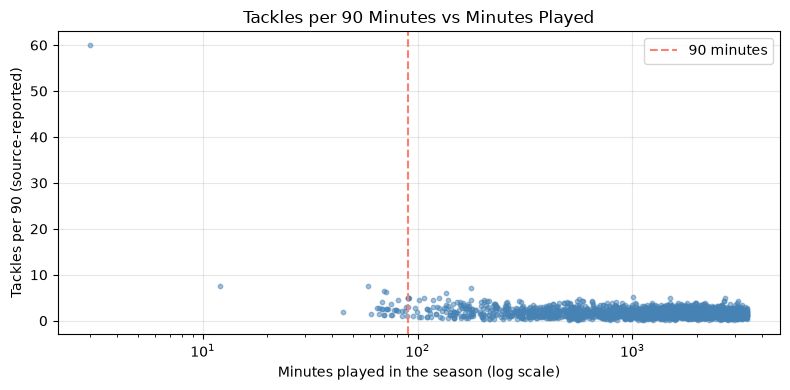

,fotmob_player_name,season,position_group_season,m_minutes_played,m_tackles_per90,m_accurate_passes_per90
0,Alexandre Jankewitz,2020/2021,MID,3.0,60.000000,60.000000
1,Kenedy,2021/2022,FWD,59.0,7.627119,51.864407
2,Nathaniel Chalobah,2022/2023,MID,12.0,7.500000,30.000000
3,Philip Billing,2024/2025,MID,177.0,7.118644,34.067797
4,Cody Drameh,2022/2023,DEF,70.0,6.428571,30.857143


In [67]:
# Per-90 rates computed from very few minutes
per90 = df41.dropna(subset=["m_minutes_played", "m_tackles_per90"])
plt.figure(figsize=(8, 4))
plt.scatter(per90["m_minutes_played"], per90["m_tackles_per90"], s=10, alpha=0.5, color="steelblue")
plt.axvline(90, color="salmon", linestyle="--", label="90 minutes")
plt.xscale("log")
plt.title("Tackles per 90 Minutes vs Minutes Played")
plt.xlabel("Minutes played in the season (log scale)")
plt.ylabel("Tackles per 90 (source-reported)")
plt.legend()
plt.tight_layout()
plt.show()
display(prof.extreme_rate_rows(df41))

**Interpretation**

- **Key integrity:** no duplicate or null primary keys, no duplicate rows. **Types:** all match the dictionary. **Categories:** 65 categorical columns checked (seasons, positions, target statuses, staleness buckets, identity statuses and all 53 status columns); none contains an unexpected value.
- **Value-status agreement:** on every row, a metric has a value exactly when its status is an observed one, and every `OBSERVED_ZERO` is a real zero.
- **Cross-column logic:** shots on target never exceed shots, goals never exceed shots, minutes never exceed 90 per appearance, appearance counts add up, target statuses match their age labels, and `missing_feature_count` equals the number of null metrics.
- **Known anomaly (DQ-RS5-04):** 6 rows, all 2020/21, report one more start than appearances (for example Alisson Becker: 33 appearances, 34 starts). Lineup evidence gives 33/33, so the reported start count is the one that is off. The published values are **kept unchanged**.
- **New structural observation:** **40 rows** report per-90 rates from fewer than 90 minutes, which produces extreme values (60 tackles per 90 from 3 minutes). These values are arithmetically consistent with the source totals; they are not errors, but per-90 rates on very small denominators are unstable. Step 8.2 should take this into account; nothing is changed here.
- No impossible values were found.

### H. Step 8.1 Conclusion

**What the dataset is.** 2,747 player-seasons, 1,228 players, five balanced seasons (19-21% each), 175 columns, verified by SHA-256 and the scope validator. Structurally clean: unique key, correct types, valid domains and categories, consistent cross-column counts.

**What later EDA must pay attention to:**
1. **Repeated players.** 687 players appear in 2+ seasons, and roughly two thirds of each season returns from the previous one. Rows are not independent.
2. **Uneven playing time.** 12% of rows have under 90 minutes; these rows are sparse and produce unstable per-90 rates (40 rows have per-90 rates from under 90 minutes).
3. **Goalkeepers are a distinct sub-population.** 206 rows; minutes null on 199 of them; 65% of metric cells null by design or by source gap.
4. **Missingness is structured, not random.** It depends on position, playing time and target availability, and is coded by `s_*` statuses (`UNVERIFIED_POSITION` = not applicable for GK-only metrics; `MISSING` = source gap; `OBSERVED_ZERO` = true zero).
5. **Columns without information.** 14 constant columns (including `m_key_passes`) and pending-decision metrics (`clearances` with three seasons of data).
6. **Preserved anomalies.** 6 rows with starts > appearances; 13 rows where reported starts exceed lineup starts.

**Gate G4.1:** see `reports/phase_04/step_01/PHASE4_01_ACCEPTANCE_REPORT.md`.

---

## 8.2 Target & Univariate Analysis

Objective:
Describe the distribution of the target (end-of-season market value) and the individual distribution of every candidate predictor, and identify the variables that have extreme values, limited coverage or need special interpretation.

Research questions:
1. How is player market value distributed, and how strongly is it skewed?
2. How does the target vary across seasons and positions?
3. What do the individual performance metrics look like, group by group?
4. Which variables contain extreme values?
5. Which variables have limited coverage?
6. Which metrics need special interpretation?

Methodology:
- All numbers come from `src/phase4/univariate.py`. The same functions write the evidence in `reports/phase_04/step_02/evidence/`. The dataset is verified by SHA-256 and the scope validator before it is read.
- **Descriptive only.** Feature-target relationships, correlations and feature selection belong to step 8.3 and are not analysed here.
- **Raw values are the source.** The target is summarised in EUR. A base-10 logarithm is computed on the fly for description and charts only; the stored column is never changed.
- **Nothing is removed or filled.** No outlier removal, capping, age cap, staleness filter, minimum-minutes rule or imputation. Interquartile-range fences (1.5 and 3 IQR) are used only to **count** extreme values.
- **Applicable rows.** Goalkeeper-only metrics are described on goalkeeper rows; all other features on all rows. Each null is read with its `s_*` status, and a null is never treated as zero.
- **Statistics:** skewness is the adjusted Fisher-Pearson coefficient and kurtosis is excess kurtosis (0 for a normal distribution). Shape labels: |skew| < 0.5 approximately symmetric; 0.5-1 moderate; >= 1 strong.

> **Temporal construct mismatch (RD-03).** The target is the latest valuation on or before season end. In practice it is a mid-season valuation (median 150 days before season end, from league-wide batches), while the metrics cover the whole season. Season-level target differences therefore partly reflect *when* each season's batch was published. This is a known limitation under objective A, not leakage, and it applies to every target statement below.

### A. Data Loading and Verification

In [68]:
from src.phase4 import univariate as uni

df42, schema42, scope42, verification42 = prof.load_verified()
dictionary42, eligibility42, reliability42 = prof.load_metadata()
register42 = uni.feature_register(eligibility42, reliability42)

print("SHA-256 verified:", verification42["sha256"] == prof.DATASET_SHA256)
print("Seasons (load_scope):", list(scope42.labels))
print("Rows per season (check_parquet):", verification42["scope_check"]["season"])

POS_COLORS = {"GK": "#2a78d6", "DEF": "#eb6834", "MID": "#1baf7a", "FWD": "#eda100"}  # fixed order, validated for colour-vision deficiency
SEASONS42 = list(scope42.labels)
target42 = uni.usable_target(df42)          # raw EUR, usable rows only (a copy; the dataset is not changed)
log_target42 = np.log10(target42)           # descriptive only

SHA-256 verified: True
Seasons (load_scope): ['2020/2021', '2021/2022', '2022/2023', '2023/2024', '2024/2025']
Rows per season (check_parquet): {'2020/2021': 524, '2021/2022': 537, '2022/2023': 554, '2023/2024': 570, '2024/2025': 562}


### B. Target Statistics

The target is `target_market_value` (EUR), present on the 2,697 rows where `target_usable` is true.

In [69]:
summary_target42 = uni.target_summary(df42)
display(summary_target42.map(lambda v: round(v, 3) if isinstance(v, float) else v))

,raw_eur,log10_eur
n,2697.0,2697.0
mean,19259306.637,7.007
std,20433237.143,0.582
min,100000.0,5.0
p01,200000.0,5.301
p05,800000.0,5.903
p10,1500000.0,6.176
p25,5000000.0,6.699
p50,13000000.0,7.114
p75,25000000.0,7.398


In [70]:
# Value granularity and missing targets
gran42 = uni.target_granularity(df42)
print(f"Distinct target values: {gran42['distinct_values']}")
print(f"Multiples of EUR 1m: {gran42['multiple_of_1m_pct']:.1f}%   multiples of EUR 5m: {gran42['multiple_of_5m_pct']:.1f}%")
print("Most common values (EUR m):", {int(k) / 1e6: v for k, v in list(gran42["most_common_eur"].items())[:6]})
display(uni.target_missing(df42).rename(columns=prof.short))

Distinct target values: 84
Multiples of EUR 1m: 86.9%   multiples of EUR 5m: 40.7%
Most common values (EUR m): {10.0: 133, 25.0: 129, 15.0: 116, 20.0: 114, 12.0: 107, 18.0: 102}


season,2020/21,2021/22,2022/23,2023/24,2024/25,tota/al
target_missing_reason,,,,,,
NO_ELIGIBLE_IDENTITY_MATCH,0,1,0,1,0,2
NO_VALUATION_HISTORY,0,1,4,0,6,11
ONLY_VALUATIONS_AFTER_CUTOFF,9,7,8,2,11,37
total,9,9,12,3,17,50


**Interpretation**

- **Centre and spread.** Median **EUR 13.0m**, mean **EUR 19.3m**, standard deviation EUR 20.4m. The interquartile range runs from EUR 5m to EUR 25m (IQR EUR 20m); the range is EUR 0.1m to EUR 200m.
- **Shape.** Skewness **2.31** and excess kurtosis **8.71**: strongly right-skewed and heavy-tailed. The mean is 1.48 times the median, and the top 1% begins at EUR 90m.
- **On the log10 scale** the distribution is compact (standard deviation 0.58, i.e. a factor of about 3.8) and moderately **left**-skewed (-0.84). The log scale over-corrects: the long tail now sits at the low end, among young fringe players valued at EUR 0.1-0.5m.
- **Granularity.** Values are rounded valuations, not continuous measurements: only **84 distinct values**, 86.9% are whole millions and 40.7% are multiples of EUR 5m (EUR 10m alone: 133 rows). Histograms therefore show heaping at round numbers.
- **Missing targets.** 50 rows (1.82%), mostly `ONLY_VALUATIONS_AFTER_CUTOFF` (37). They are documented, not imputed.

### C. Target Distribution: Raw and Log Scale

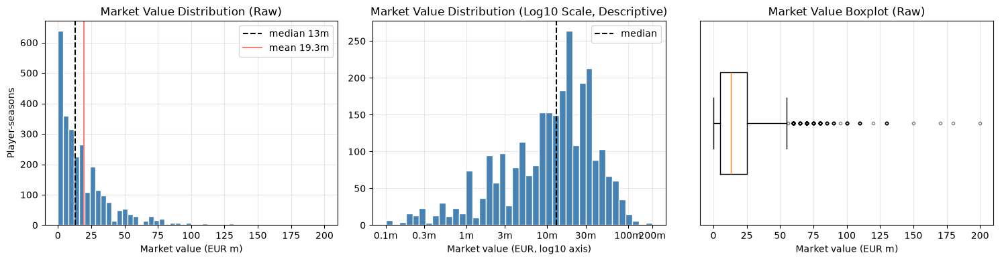

In [71]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(target42 / 1e6, bins=50, color=COLOR, edgecolor="white")
axes[0].axvline(target42.median() / 1e6, color="black", linestyle="--", label=f"median {target42.median() / 1e6:.0f}m")
axes[0].axvline(target42.mean() / 1e6, color="salmon", linestyle="-", label=f"mean {target42.mean() / 1e6:.1f}m")
axes[0].set_title("Market Value Distribution (Raw)")
axes[0].set_xlabel("Market value (EUR m)")
axes[0].set_ylabel("Player-seasons")
axes[0].legend()

axes[1].hist(log_target42, bins=40, color=COLOR, edgecolor="white")
axes[1].axvline(log_target42.median(), color="black", linestyle="--", label="median")
ticks = [0.1, 0.3, 1, 3, 10, 30, 100, 200]
axes[1].set_xticks(np.log10(np.array(ticks) * 1e6), [f"{t:g}m" for t in ticks])
axes[1].set_title("Market Value Distribution (Log10 Scale, Descriptive)")
axes[1].set_xlabel("Market value (EUR, log10 axis)")
axes[1].legend()

axes[2].boxplot(target42 / 1e6, orientation="horizontal", widths=0.5, flierprops={"marker": "o", "markersize": 3, "alpha": 0.5})
axes[2].set_title("Market Value Boxplot (Raw)")
axes[2].set_xlabel("Market value (EUR m)")
axes[2].set_yticks([])
plt.tight_layout()
plt.show()

**Interpretation**

- The raw histogram is dominated by one mass below EUR 30m and a thin tail to EUR 200m, with spikes at round values. The raw boxplot flags **151 values above the 1.5 IQR fence (EUR 55m)** and **32 above the 3 IQR fence (EUR 85m)**; no value falls below the lower fences.
- On the log axis, the same data is roughly bell-shaped around EUR 13m, with a longer low tail (79 values below the log-scale 1.5 IQR fence, EUR 0.45m). Neither scale is "correct": the raw scale is the research quantity, and the log scale is a reading aid.
- The right skew is an observed property of this dataset. It is consistent with how market values work (a few elite players are valued far above the rest), but this report only describes it.

In [72]:
fences42, extremes42 = uni.target_tail(df42)
display(fences42)
display(extremes42.assign(target_market_value=lambda t: t["target_market_value"] / 1e6,
                          target_audit_previous_value=lambda t: t["target_audit_previous_value"] / 1e6)
        .rename(columns={"target_market_value": "value_eur_m", "target_audit_previous_value": "previous_eur_m (audit)"}))
tail42 = uni.tail_consistency(df42)
print({k: tail42[k] for k in ["upper_3iqr_rows", "upper_3iqr_players", "ratio_to_previous_median",
                              "ratio_to_previous_min", "ratio_to_previous_max", "tail_rows_by_position"]})

,scale,fence,lower_fence,upper_fence,below,above
0,raw_eur,1.5 IQR,-2.500000e+07,5.500000e+07,0,151
1,raw_eur,3.0 IQR,-5.500000e+07,8.500000e+07,0,32
2,log10_eur,1.5 IQR,4.472136e+05,2.795085e+08,79,0
3,log10_eur,3.0 IQR,4.000000e+04,3.125000e+09,0,0


,fotmob_player_name,season,position_group_season,age_at_season_end_years,value_eur_m,target_valuation_date,target_valuation_age_days,target_status,previous_eur_m (audit),target_audit_ratio_to_previous_value,tail
2589,Erling Haaland,2024/2025,FWD,24.84,200.000,2024-12-16,160.0,STALE_TARGET,200.000,1.0000,highest
2038,Erling Haaland,2023/2024,FWD,23.83,180.000,2023-12-19,152.0,STALE_TARGET,180.000,1.0000,highest
1473,Erling Haaland,2022/2023,FWD,22.85,170.000,2022-11-03,206.0,STALE_TARGET,150.000,1.1333,highest
2735,Bukayo Saka,2024/2025,FWD,23.72,150.000,2024-12-16,160.0,STALE_TARGET,140.000,1.0714,highest
2085,Phil Foden,2023/2024,FWD,23.98,130.000,2024-03-14,66.0,VALID,110.000,1.1818,highest
2173,Bukayo Saka,2023/2024,FWD,22.70,130.000,2024-03-14,66.0,VALID,120.000,1.0833,highest
2219,Cole Palmer,2024/2025,MID,23.05,130.000,2024-12-16,160.0,STALE_TARGET,90.000,1.4444,highest
2562,Rodri,2024/2025,MID,28.92,130.000,2024-12-16,160.0,STALE_TARGET,130.000,1.0000,highest
2642,Phil Foden,2024/2025,MID,24.99,130.000,2025-03-18,68.0,VALID,140.000,0.9286,highest
109,Harry Kane,2020/2021,FWD,27.82,120.000,2021-03-18,66.0,VALID,120.000,1.0000,highest


{'upper_3iqr_rows': 32, 'upper_3iqr_players': 17, 'ratio_to_previous_median': 1.0, 'ratio_to_previous_min': 0.8333, 'ratio_to_previous_max': 1.4444, 'tail_rows_by_position': {'GK': 0, 'DEF': 1, 'MID': 14, 'FWD': 17}}


**Interpretation: extreme values are genuine, and they stay**

- The **32 values above EUR 85m** belong to **17 players** (for example Erling Haaland, EUR 170-200m; Bukayo Saka; Phil Foden; Rodri; Harry Kane; Mohamed Salah). Every one of them has a previous valuation, and the ratio to it lies between 0.83 and 1.44 (median 1.00). The players' own valuation histories show no isolated spike that would suggest a data error.
- The low end (EUR 0.1-0.15m) consists of young fringe players (ages 17-23). Their previous valuations, where present, are similar.
- The tail is concentrated in attacking positions (17 FWD, 14 MID, 1 DEF, 0 GK rows above EUR 85m).
- **Policy respected (P4-A09):** no value is removed, capped or treated as an error. `target_audit_*` is read here only as an audit check and never as a predictor (P4-A03).

### D. Target by Season

In [73]:
by_season42 = uni.target_by(df42, "season", SEASONS42)
display(by_season42.rename(index=prof.short).round(2))
timing42 = uni.target_timing(df42, scope42)
display(timing42.rename(index=prof.short))

,rows,usable_targets,median_eur,mean_eur,p25_eur,p75_eur,p90_eur,max_eur,skew_raw,skew_log10,coverage_pct,mean_to_median
season,,,,,,,,,,,,
2020/21,524,515,10000000.0,16877961.17,4000000.0,22000000.0,40000000.0,120000000.0,2.15,-0.77,98.28,1.69
2021/22,537,528,10000000.0,17205492.42,3500000.0,22000000.0,40000000.0,100000000.0,1.88,-0.59,98.32,1.72
2022/23,554,542,15000000.0,19610654.98,6000000.0,25000000.0,45000000.0,170000000.0,2.29,-0.94,97.83,1.31
2023/24,570,567,13000000.0,20129276.90,4500000.0,28000000.0,48800000.0,180000000.0,2.24,-0.90,99.47,1.55
2024/25,562,545,17000000.0,22244816.51,8000000.0,30000000.0,50000000.0,200000000.0,2.66,-0.97,96.98,1.31


,usable_targets,median_age_days,p90_age_days,max_age_days,share_over_90_days_pct,median_valuation_date,modal_valuation_date,modal_date_share_pct
season,,,,,,,,
2020/21,515,66.0,66.0,731.0,2.912621,2021-03-18,2021-03-18,92.621359
2021/22,528,150.0,150.0,586.0,78.030303,2021-12-23,2021-12-23,72.727273
2022/23,542,206.0,206.0,347.0,66.974170,2022-11-03,2022-11-03,60.516605
2023/24,567,152.0,152.0,166.0,72.663139,2023-12-19,2023-12-19,68.783069
2024/25,545,160.0,160.0,724.0,59.633028,2024-12-16,2024-12-16,53.394495


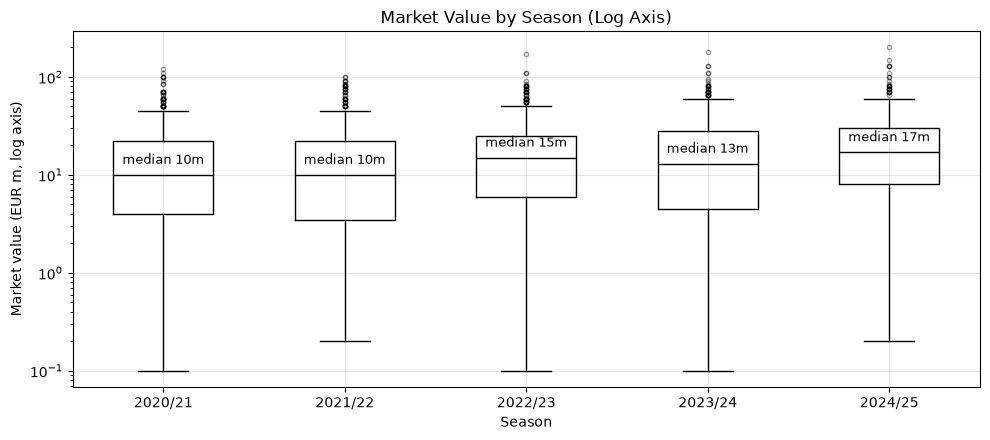

In [74]:
fig, ax = plt.subplots(figsize=(10, 4.5))
data = [df42.loc[df42["target_usable"] & (df42["season"] == s), "target_market_value"] / 1e6 for s in SEASONS42]
ax.boxplot(data, widths=0.55, flierprops={"marker": "o", "markersize": 3, "alpha": 0.4},
           medianprops={"color": "black"})
ax.set_xticks(range(1, 6), [prof.short(s) for s in SEASONS42])
ax.set_yscale("log")
for i, d in enumerate(data, 1):
    ax.annotate(f"median {d.median():g}m", (i, d.median()), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.set_title("Market Value by Season (Log Axis)")
ax.set_xlabel("Season")
ax.set_ylabel("Market value (EUR m, log axis)")
plt.tight_layout()
plt.show()

**Interpretation**

- **Medians rise across seasons:** EUR 10m (2020/21, 2021/22), 15m, 13m, then **17m in 2024/25**; the maximum rises from EUR 120m to 200m. The skew is strong in every season (raw 1.88-2.66).
- **Season and valuation timing are confounded (ISS-21).** In each season, 53-93% of targets come from a single league-wide valuation date (for example 2020/21: 92.6% on 2021-03-18). The median valuation age ranges from 66 days (2020/21) to 206 days (2022/23) before season end. A season difference therefore mixes general market movement, the population of that season and the date of that season's batch. This analysis cannot separate them.
- Target coverage is 97-99.5% in every season, so the season comparison is not distorted by missing targets.
- Under **RD-03**, a season's target describes a mid-season valuation. No staleness filter is applied (P4-A08, ISS-22): a filter would remove 2.9% of 2020/21 but 78% of 2021/22 targets.

### E. Target by Position and by Position and Season

Position is `position_group_season`, the player's **modal lineup position over the whole season** (P4-B04). It is partly determined after the valuation date (RD-03).

,rows,usable_targets,median_eur,mean_eur,p25_eur,p75_eur,p90_eur,max_eur,skew_raw,skew_log10,coverage_pct,mean_to_median
position_group_season,,,,,,,,,,,,
GK,206,206,6000000.0,11220145.63,2000000.0,17750000.0,25000000.0,65000000.0,1.67,-0.37,100.00,1.87
DEF,935,924,12000000.0,16650270.56,4000000.0,25000000.0,38000000.0,100000000.0,1.58,-0.88,98.82,1.39
MID,839,817,15000000.0,20952753.98,6000000.0,30000000.0,50000000.0,130000000.0,1.87,-0.94,97.38,1.40
FWD,767,750,15000000.0,22837000.00,6000000.0,30000000.0,55000000.0,200000000.0,2.42,-0.93,97.78,1.52


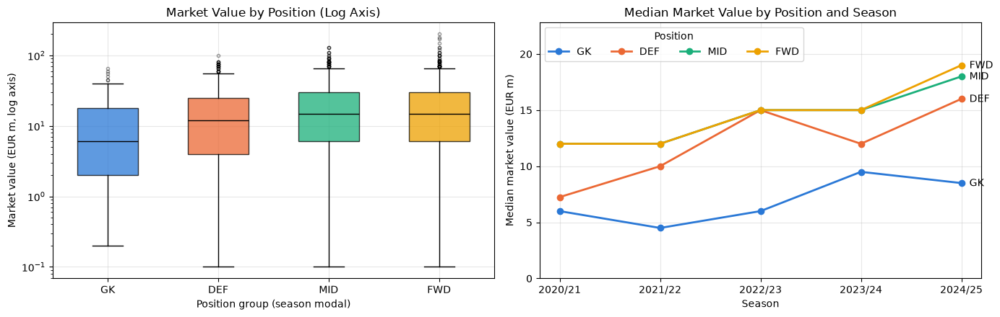

Median (EUR m) and usable targets by position and season:


season,2020/21,2021/22,2022/23,2023/24,2024/25
position_group_season,,,,,
GK,6.00,4.5,6.0,9.5,8.5
DEF,7.25,10.0,15.0,12.0,16.0
MID,12.00,12.0,15.0,15.0,18.0
FWD,12.00,12.0,15.0,15.0,19.0


season,2020/21,2021/22,2022/23,2023/24,2024/25
position_group_season,,,,,
GK,41,42,39,40,44
DEF,184,180,180,191,189
MID,149,151,172,179,166
FWD,141,155,151,157,146


In [75]:
by_position42 = uni.target_by(df42, "position_group_season", prof.POSITION_ORDER)
display(by_position42.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
data = [df42.loc[df42["target_usable"] & (df42["position_group_season"] == p), "target_market_value"] / 1e6
        for p in prof.POSITION_ORDER]
box = axes[0].boxplot(data, widths=0.55, patch_artist=True, medianprops={"color": "black"},
                      flierprops={"marker": "o", "markersize": 3, "alpha": 0.4})
for patch, p in zip(box["boxes"], prof.POSITION_ORDER):
    patch.set_facecolor(POS_COLORS[p])
    patch.set_alpha(0.75)
axes[0].set_xticks(range(1, 5), prof.POSITION_ORDER)
axes[0].set_yscale("log")
axes[0].set_title("Market Value by Position (Log Axis)")
axes[0].set_xlabel("Position group (season modal)")
axes[0].set_ylabel("Market value (EUR m, log axis)")

medians42 = uni.target_position_season(df42, scope42, "median") / 1e6
labels = [prof.short(s) for s in SEASONS42]
for p in prof.POSITION_ORDER:
    axes[1].plot(labels, medians42.loc[p], marker="o", linewidth=2, color=POS_COLORS[p], label=p)
    axes[1].annotate(p, (labels[-1], medians42.loc[p].iloc[-1]), textcoords="offset points", xytext=(8, -3))
axes[1].set_title("Median Market Value by Position and Season")
axes[1].set_xlabel("Season")
axes[1].set_ylabel("Median market value (EUR m)")
axes[1].set_ylim(0, medians42.values.max() * 1.2)
axes[1].legend(title="Position", loc="upper left", ncol=4)
plt.tight_layout()
plt.show()

print("Median (EUR m) and usable targets by position and season:")
display(medians42.rename(columns=prof.short))
display(uni.target_position_season(df42, scope42, "count").rename(columns=prof.short))

**Interpretation**

- **Goalkeepers are valued lowest** (median EUR 6m, maximum EUR 65m, no row above the 3 IQR fence). Defenders have a median of EUR 12m; midfielders and forwards EUR 15m.
- **Forwards have the longest tail** (skew 2.42, maximum EUR 200m, p90 EUR 55m). Mean-to-median ratios are 1.39-1.87, so the tail matters in every group.
- **By season**, outfield medians move together. MID and FWD medians are identical until 2023/24 (12, 12, 15, 15m), so their lines overlap; in 2024/25 they are 18m and 19m. Defender medians rise most (EUR 7.25m to 16m). Goalkeeper medians fluctuate between EUR 4.5m and 9.5m on about 40 rows per season, so single-season goalkeeper figures are imprecise.
- The position-by-season cells hold 39-191 targets each. Every cell is populated, but goalkeeper cells are small.
- These are descriptive differences only: no claim is made that position *causes* value, and position itself is a whole-season label (P4-B04).

### F. Feature-Group Methodology

The candidate predictors are taken from the step 8.0 eligibility register (`phase4_feature_eligibility.csv`): the categories `CANDIDATE_PREDICTOR` and `CONDITIONAL_PREDICTOR`, excluding club context (RS5-12, pending). That gives **53 features**: age plus 52 FotMob metrics, organised into nine analysis groups. The repository's own metric family is kept next to each feature.

Excluded from predictor analysis, with the reason recorded per column: all `target_*` and `temporal_*` columns; identity, id, population-evidence and provenance columns; `nationality_profile_present_day`; `m_key_passes` / `s_key_passes`; the 53 `s_*` status columns (read only to interpret availability); and the 8 club-context columns (counts only).

In [76]:
excluded42 = uni.excluded_from_analysis(df42, eligibility42)
print("Analysed features:", len(uni.FEATURES), "| columns not analysed as predictors:", len(excluded42))
display(excluded42["eligibility_category"].value_counts().rename("columns").to_frame())

summary42 = uni.feature_summary(df42, register42)
display(uni.group_overview(summary42).round(1))
display(register42[["feature", "analysis_group", "repository_family", "kind", "eligibility_category",
                    "reliability_status", "applicable_positions", "pending_owner_decision"]])

Analysed features: 53 | columns not analysed as predictors: 122


,columns
eligibility_category,
STATUS_MISSINGNESS,53
IDENTITY_METADATA,33
TARGET,16
CONDITIONAL_PREDICTOR,8
TEMPORAL_AUDIT,8
EXCLUDED_PREDICTOR,3
CANDIDATE_PREDICTOR,1


,features,conditional_or_pending,median_missing_pct_applicable,max_missing_pct_applicable,strongly_right_skewed,values_beyond_3iqr
analysis_group,,,,,,
1 Player context and age,1,0,0.0,0.0,0,0
2 Playing time and participation,3,0,0.0,7.2,0,0
3 Attacking,9,1,21.2,44.3,9,329
4 Expected (model-based) metrics,4,1,20.1,31.3,4,234
5 Passing and possession,10,3,15.2,41.8,6,196
6 Defensive,14,4,21.7,80.7,9,104
7 Discipline and fouls,4,0,16.1,21.5,3,229
8 Goalkeeping,7,4,3.9,31.6,1,0
9 Overall match rating,1,0,5.7,5.7,0,0


,feature,analysis_group,repository_family,kind,eligibility_category,reliability_status,applicable_positions,pending_owner_decision
0,age_at_season_end_years,1 Player context and age,CONTEXT,age (years),CANDIDATE_PREDICTOR,RELIABLE,ALL,
1,m_appearances,2 Playing time and participation,GENERAL,season count/total,CANDIDATE_PREDICTOR,RELIABLE_WITH_ALIGNMENT_LIMIT,ALL,
2,m_starts,2 Playing time and participation,GENERAL,season count/total,CANDIDATE_PREDICTOR,RELIABLE_WITH_ALIGNMENT_LIMIT,ALL,
3,m_minutes_played,2 Playing time and participation,GENERAL,season count/total,CANDIDATE_PREDICTOR,RELIABLE_WITH_ALIGNMENT_LIMIT,ALL,
4,m_goals,3 Attacking,ATTACK,season count/total,CANDIDATE_PREDICTOR,RELIABLE_WITH_ALIGNMENT_LIMIT,ALL,
5,m_assists,3 Attacking,ATTACK,season count/total,CANDIDATE_PREDICTOR,RELIABLE_WITH_ALIGNMENT_LIMIT,ALL,
6,m_shots,3 Attacking,ATTACK,season count/total,CANDIDATE_PREDICTOR,RELIABLE_WITH_ALIGNMENT_LIMIT,ALL,
7,m_shots_on_target,3 Attacking,ATTACK,season count/total,CANDIDATE_PREDICTOR,RELIABLE_WITH_ALIGNMENT_LIMIT,ALL,
8,m_shots_per90,3 Attacking,ATTACK,per-90 rate,CANDIDATE_PREDICTOR,RELIABLE_WITH_ALIGNMENT_LIMIT,ALL,
9,m_shots_on_target_per90,3 Attacking,ATTACK,per-90 rate,CANDIDATE_PREDICTOR,RELIABLE_WITH_ALIGNMENT_LIMIT,ALL,


**Interpretation**

- 40 features are `CANDIDATE_PREDICTOR` (usable with the RD-03 warning) and 13 are `CONDITIONAL_PREDICTOR`: the 8 source-reported rates and totals (ISS-29) and the 5 RD-04 features. The categories are described here, not changed.
- Attacking, expected and defensive groups contain almost all strongly right-skewed metrics and most values beyond 3 IQR. Context, playing time and rating are close to symmetric.

### G. Univariate Feature Analysis

One compact table per group. Statistics are computed on the applicable rows (goalkeeper rows for goalkeeper-only metrics). `missing_pct_applicable` is the share of applicable rows without a value; `upper_3iqr` counts values beyond the 3 IQR fence; `zero_pct` is the share of observed values equal to 0.

In [77]:
compact42 = uni.compact_summary(summary42).set_index("feature")
for group, features in uni.FEATURE_GROUPS.items():
    display(Markdown(f"**{group}**"))
    display(compact42.loc[features].round(2))

**1 Player context and age**

,kind,n,missing_pct_applicable,mean,p50,std,min,p05,p95,max,skew,upper_3iqr,zero_pct,seasons_with_values
feature,,,,,,,,,,,,,,
age_at_season_end_years,age (years),2747,0.0,26.55,26.39,4.43,15.87,19.54,34.03,40.65,0.19,0,0.0,5


**2 Playing time and participation**

,kind,n,missing_pct_applicable,mean,p50,std,min,p05,p95,max,skew,upper_3iqr,zero_pct,seasons_with_values
feature,,,,,,,,,,,,,,
m_appearances,season count/total,2746,0.04,20.09,21.0,11.81,1.0,1.0,37.0,38.0,-0.18,0,0.0,5
m_starts,season count/total,2746,0.04,15.22,14.0,11.97,0.0,0.0,36.0,38.0,0.30,0,11.8,5
m_minutes_played,season count/total,2548,7.24,1339.70,1244.0,1009.54,1.0,10.0,3070.3,3420.0,0.29,0,0.0,5


**3 Attacking**

,kind,n,missing_pct_applicable,mean,p50,std,min,p05,p95,max,skew,upper_3iqr,zero_pct,seasons_with_values
feature,,,,,,,,,,,,,,
m_goals,season count/total,2548,7.24,2.10,1.00,3.59,0.00,0.00,10.00,36.0,3.07,158,45.45,5
m_assists,season count/total,2564,6.66,1.49,1.00,2.25,0.00,0.00,6.85,18.0,2.24,53,47.66,5
m_shots,season count/total,2224,19.04,21.87,14.00,22.76,0.00,1.00,70.00,139.0,1.78,23,3.87,5
m_shots_on_target,season count/total,1898,30.91,9.02,5.00,9.69,1.00,1.00,29.00,63.0,2.08,28,0.00,5
m_shots_per90,per-90 rate,2224,19.04,1.30,1.03,1.01,0.00,0.11,3.25,7.5,1.05,2,3.87,5
m_shots_on_target_per90,per-90 rate,1898,30.91,0.52,0.39,0.47,0.03,0.07,1.36,7.5,2.83,4,0.00,5
m_big_chances_created,season count/total,1531,44.27,3.94,3.00,3.80,1.00,1.00,11.00,32.0,2.40,16,0.00,5
m_dribbles_succeeded,season count/total,2066,24.79,15.82,10.00,16.24,1.00,1.00,50.00,153.0,2.15,15,0.00,5
m_touches_opposition_box,season count/total,2165,21.19,43.86,27.00,47.80,1.00,2.00,146.00,394.0,2.11,30,0.00,5


... (8 outputs left out)

**8 Goalkeeping**

,kind,n,missing_pct_applicable,mean,p50,std,min,p05,p95,max,skew,upper_3iqr,zero_pct,seasons_with_values
feature,,,,,,,,,,,,,,
m_saves,season count/total,198,3.88,58.16,52.00,45.89,0.00,2.00,138.30,166.00,0.36,0,0.51,5
m_save_percentage,percentage (source-reported),197,4.37,65.45,66.70,10.63,25.00,45.04,80.00,100.00,-0.56,0,0.00,5
m_clean_sheets,season count/total,198,3.88,4.90,3.50,4.87,0.00,0.00,14.00,20.00,0.90,0,21.21,5
m_goals_conceded,season count/total,198,3.88,27.82,27.00,20.67,0.00,1.85,62.00,85.00,0.40,0,1.01,5
m_goals_conceded_per90,per-90 rate,198,3.88,1.64,1.52,0.71,0.00,0.74,3.00,4.00,0.89,0,1.01,5
m_penalty_saves,season count/total,141,31.55,0.45,0.00,0.65,0.00,0.00,2.00,3.00,1.29,0,62.41,5
m_goals_prevented,season total (model-based),180,12.62,-1.64,-1.02,4.10,-20.31,-8.78,3.92,9.47,-0.95,0,0.00,5


**9 Overall match rating**

,kind,n,missing_pct_applicable,mean,p50,std,min,p05,p95,max,skew,upper_3iqr,zero_pct,seasons_with_values
feature,,,,,,,,,,,,,,
m_rating,average rating (0-10),2590,5.72,6.73,6.74,0.42,4.47,6.04,7.4,8.12,-0.32,0,0.0,5


**Interpretation by group**

1. **Context and age.** Age is close to symmetric (median 26.4 years, range 15.9-40.7, skew 0.19). Goalkeepers are older (median 30.2) than defenders (26.8), midfielders (26.1) and forwards (25.5). Age shifts slightly younger over the seasons (median 26.9 to 26.1).
2. **Playing time.** Appearances, starts and minutes are spread across the whole range, slightly left-skewed or flat (negative kurtosis), with no extreme values. `m_starts` has 11.8% zeros (substitute-only seasons). Minutes are null on 199 goalkeeper rows (ISS-11).
3. **Attacking.** Every metric is strongly right-skewed. Goals: median 1, maximum 36, 45% zeros and **158 values beyond 3 IQR**, the heaviest tail of all features. Shots, big chances, dribbles and box touches have maxima 6-10 times their median.
4. **Expected metrics.** Same shape as their observed counterparts (xG skew 2.87, 78 values beyond 3 IQR). `m_expected_assists` is almost complete (1.4% missing), unlike the other xG metrics (18-31% missing).
5. **Passing and possession.** Volume totals are right-skewed (long passes skew 2.70). `m_passing_accuracy` is **left**-skewed (median 81.1%, a few low-volume players far below). Rates and per-90 values are much more symmetric than totals.
6. **Defensive.** Totals are mildly to strongly skewed (tackles 1.18, blocked shots 2.41). `m_tackles_per90` has skew **25** and kurtosis **940** from a single value (60 tackles per 90 from 3 minutes; P4-B05). Clearances have 81% missing (RD-04).
7. **Discipline and fouls.** Cards are discrete and zero-heavy: red cards are 0 in 91% of observed rows, so the IQR is 0 and every row with a red card (219) falls "beyond 3 IQR". The fences carry no information for such counts. Yellow cards are 0 in 19% of observed rows.
8. **Goalkeeping (GK rows only).** Saves, goals conceded and clean sheets are spread almost uniformly (skew < 1), because they scale with games played. `m_penalty_saves` is 62% zeros. `m_goals_prevented` is centred below zero (median -1.0, range -20.3 to +9.5).
9. **Rating.** Narrow and close to symmetric (median 6.74, standard deviation 0.42), with a short low tail (minimum 4.47).

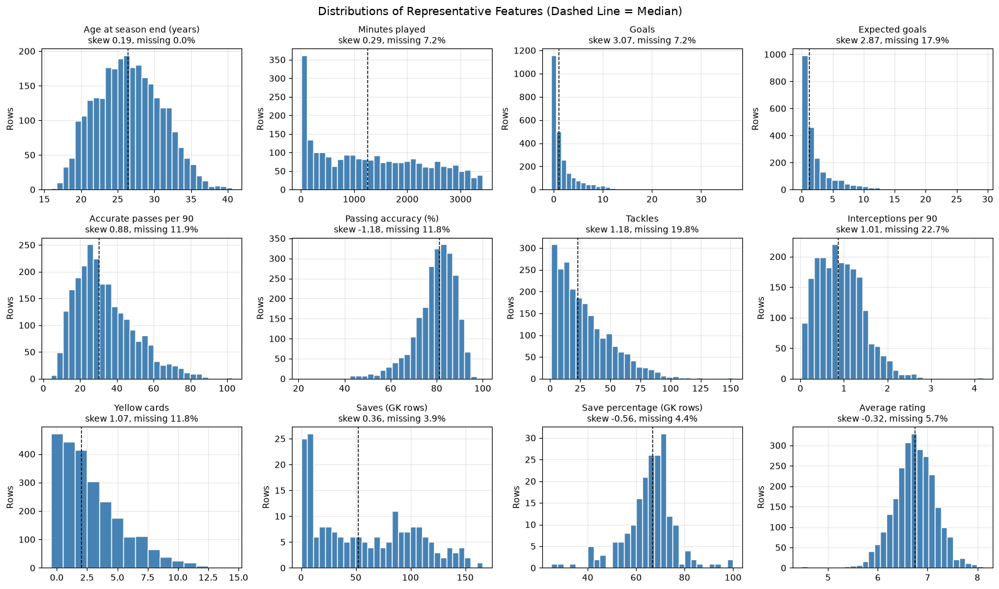

In [78]:
# Representative distributions: one or two features per group (raw values; GK metrics on GK rows)
reps = [("age_at_season_end_years", "Age at season end (years)"), ("m_minutes_played", "Minutes played"),
        ("m_goals", "Goals"), ("m_expected_goals", "Expected goals"),
        ("m_accurate_passes_per90", "Accurate passes per 90"), ("m_passing_accuracy", "Passing accuracy (%)"),
        ("m_tackles", "Tackles"), ("m_interceptions_per90", "Interceptions per 90"),
        ("m_yellow_cards", "Yellow cards"), ("m_saves", "Saves (GK rows)"),
        ("m_save_percentage", "Save percentage (GK rows)"), ("m_rating", "Average rating")]
fig, axes = plt.subplots(3, 4, figsize=(16, 9.5))
for ax, (feature, label) in zip(axes.flat, reps):
    rows = uni.applicable_rows(df42, feature, register42)
    values = df42.loc[rows, feature].dropna()
    discrete = feature in ("m_goals", "m_yellow_cards")
    bins = np.arange(-0.5, values.max() + 1.5, 1) if discrete else 30
    ax.hist(values, bins=bins, color=COLOR, edgecolor="white")
    ax.axvline(values.median(), color="black", linestyle="--", linewidth=1)
    s = summary42.set_index("feature").loc[feature]
    ax.set_title(f"{label}\nskew {s['skew']:.2f}, missing {s['missing_pct_applicable']:.1f}%", fontsize=10)
    ax.set_ylabel("Rows")
fig.suptitle("Distributions of Representative Features (Dashed Line = Median)", fontsize=13)
plt.tight_layout()
plt.show()

**Interpretation**

- Three shapes recur. **Counts of rare events** (goals, cards) pile up at 0-2 with long right tails. **Volume metrics** (minutes, tackles, saves) spread across the range because they scale with playing time. **Rates and averages** (passes per 90, interceptions per 90, rating, save percentage) are roughly bell-shaped.
- Because volume metrics follow minutes, their raw distributions largely restate the playing-time distribution. Step 8.3 must read them together with minutes before attributing differences to performance.
- Percentages from small denominators produce spikes at round values (100% save percentage, 0%/100% cross accuracy). These are genuine source values from very few attempts (ISS-29).

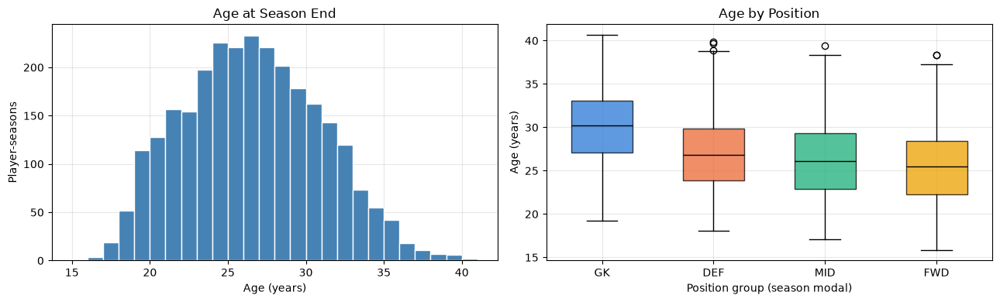

,count,mean,std,min,25%,50%,75%,max
position_group_season,,,,,,,,
GK,206.0,30.07,4.25,19.24,27.12,30.24,33.06,40.65
DEF,935.0,26.92,4.23,18.04,23.90,26.78,29.86,39.88
MID,839.0,26.16,4.35,17.07,22.88,26.12,29.32,39.39
FWD,767.0,25.58,4.30,15.87,22.28,25.46,28.47,38.37


In [79]:
# Age by position
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df42["age_at_season_end_years"], bins=np.arange(15, 42, 1), color=COLOR, edgecolor="white")
axes[0].set_title("Age at Season End")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Player-seasons")
data = [df42.loc[df42["position_group_season"] == p, "age_at_season_end_years"] for p in prof.POSITION_ORDER]
box = axes[1].boxplot(data, widths=0.55, patch_artist=True, medianprops={"color": "black"})
for patch, p in zip(box["boxes"], prof.POSITION_ORDER):
    patch.set_facecolor(POS_COLORS[p])
    patch.set_alpha(0.75)
axes[1].set_xticks(range(1, 5), prof.POSITION_ORDER)
axes[1].set_title("Age by Position")
axes[1].set_xlabel("Position group (season modal)")
axes[1].set_ylabel("Age (years)")
plt.tight_layout()
plt.show()
age42 = uni.age_profile(df42, scope42)
display(age42["by_position"].round(2))

**Interpretation**

- Age is complete (0% missing) and nearly symmetric, concentrated between 23 and 30. Goalkeepers are about four years older than outfield players at the median.
- Four birth dates are disputed across sources (ISS-07); they affect only a handful of rows. Age is not capped (RD-01 is a design decision about target age, not player age).

minutes_band,max | 1-89,max | 90-449,max | 450-899,max | 900+
feature,,,,
m_accurate_long_passes_per90,10.91,6.82,7.75,7.81
m_accurate_passes_per90,96.82,100.42,82.24,102.90
m_blocks_per90,2.40,2.24,1.93,2.05
m_clearances_per90,5.54,7.65,7.56,7.31
m_interceptions_per90,4.09,4.21,2.58,3.82
m_recoveries_per90,19.09,11.78,9.52,10.16
m_shots_on_target_per90,7.50,3.09,2.16,2.10
m_shots_per90,7.50,6.47,5.32,4.75
m_tackles_per90,60.00,7.12,4.63,5.18


minutes_band,rows | 1-89,rows | 90-449,rows | 450-899,rows | 900+
feature,,,,
m_accurate_long_passes_per90,23,269,311,1529
m_accurate_passes_per90,40,328,319,1536
m_blocks_per90,7,163,234,1390
m_clearances_per90,7,82,76,366
m_interceptions_per90,18,272,303,1530
m_recoveries_per90,36,328,320,1536
m_shots_on_target_per90,6,183,252,1457
m_shots_per90,40,328,320,1536
m_tackles_per90,31,316,320,1536


,top1pct_rows,of_which_minutes_under_90,rows_under_90_minutes_with_value
feature,,,
m_shots_per90,23,1,40
m_shots_on_target_per90,19,3,6
m_accurate_passes_per90,23,2,40
m_accurate_long_passes_per90,22,2,23
m_tackles_per90,23,6,31
m_interceptions_per90,22,7,18
m_recoveries_per90,23,4,36
m_blocks_per90,19,2,7
m_clearances_per90,6,0,7


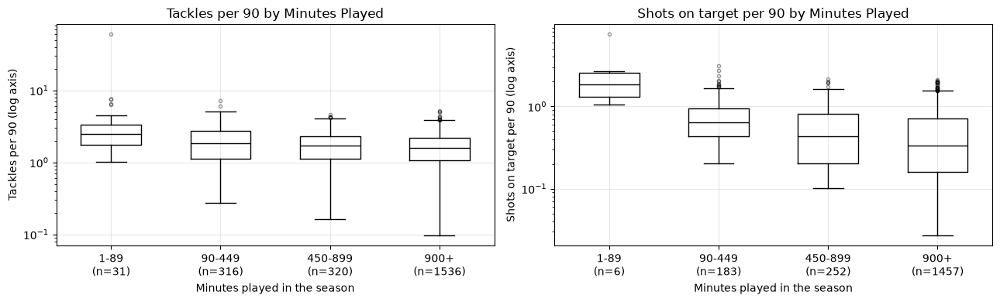

In [80]:
# Per-90 rates by minutes band (P4-B05): descriptive, no minimum-minutes rule is applied
bands42 = uni.per90_by_minutes(df42)
order = uni.MINUTES_LABELS
display(bands42.pivot(index="feature", columns="minutes_band", values="max")[order].round(2)
        .add_prefix("max | "))
display(bands42.pivot(index="feature", columns="minutes_band", values="n")[order].add_prefix("rows | "))
display(uni.per90_tail_share(df42).set_index("feature"))

band = pd.cut(df42["m_minutes_played"], uni.MINUTES_BANDS, labels=order)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, feature, label in [(axes[0], "m_tackles_per90", "Tackles per 90"),
                           (axes[1], "m_shots_on_target_per90", "Shots on target per 90")]:
    data = [df42.loc[band == b, feature].dropna() for b in order]
    ax.boxplot(data, widths=0.55, medianprops={"color": "black"}, flierprops={"marker": "o", "markersize": 3, "alpha": 0.4})
    ax.set_xticks(range(1, 5), [f"{b}\n(n={len(d)})" for b, d in zip(order, data)])
    ax.set_yscale("log")
    ax.set_title(f"{label} by Minutes Played")
    ax.set_xlabel("Minutes played in the season")
    ax.set_ylabel(f"{label} (log axis)")
plt.tight_layout()
plt.show()

**Interpretation (P4-B05)**

- The **largest per-90 values come from the smallest denominators.** `m_tackles_per90` reaches 60 under 90 minutes but at most 7.1 in any higher band. Shots on target per 90 reaches 7.5 under 90 minutes, against 2.1-3.1 above.
- Few rows are affected (6-40 rows per rate under 90 minutes), but they contribute up to 7 of the top-1% values of a rate (interceptions per 90).
- With 900+ minutes, rates are stable and their spread narrows. Per-90 rates must therefore always be read together with minutes. Whether a minimum-minutes rule should apply is an **design decision**; none is applied here.

### H. Missingness and Coverage

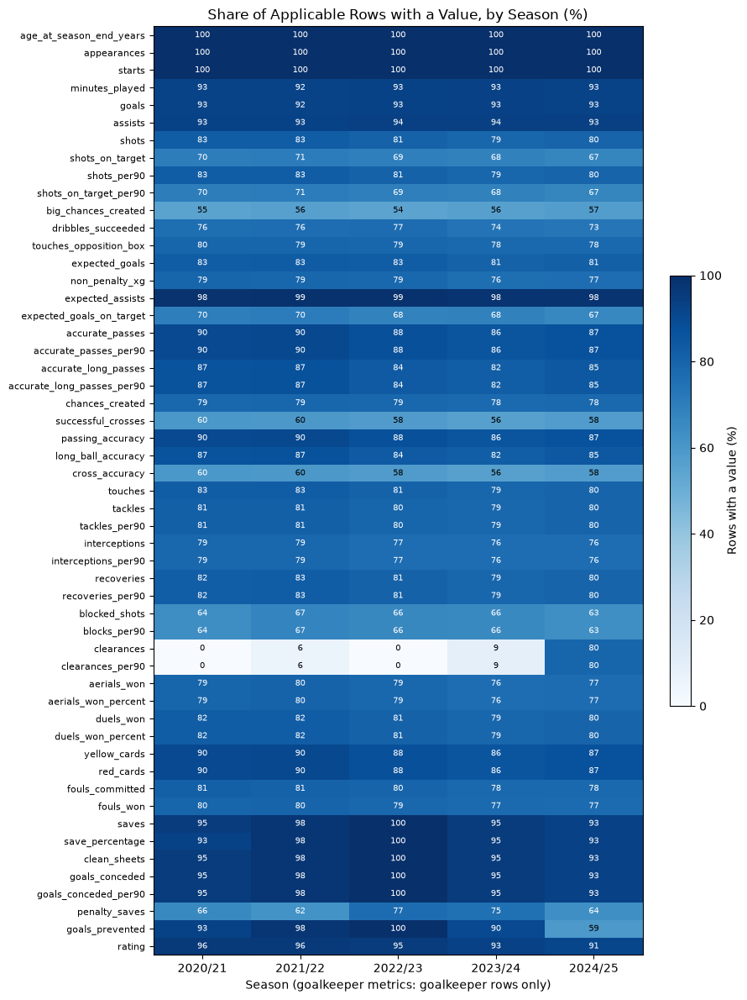

In [81]:
coverage42 = uni.coverage_by_season(df42, register42, scope42)
fig, ax = plt.subplots(figsize=(9, 12))
im = ax.imshow(coverage42.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_yticks(range(len(coverage42)), [f[2:] if f.startswith("m_") else f for f in coverage42.index], fontsize=8)
ax.set_xticks(range(5), [prof.short(s) for s in coverage42.columns])
for (i, j), v in np.ndenumerate(coverage42.values):
    ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7, color="white" if v > 60 else "black")
ax.grid(False)
ax.set_title("Share of Applicable Rows with a Value, by Season (%)")
ax.set_xlabel("Season (goalkeeper metrics: goalkeeper rows only)")
fig.colorbar(im, ax=ax, fraction=0.04, label="Rows with a value (%)")
plt.tight_layout()
plt.show()

In [82]:
coverage_limited42 = uni.limited_coverage(summary42, coverage42)
display(coverage_limited42.round(2))
present42, _ = uni.position_relevance(df42)
print("Share of rows with a value, by position (%), selected features:")
display(present42.loc[["m_minutes_played", "m_goals", "m_shots", "m_tackles", "m_blocked_shots", "m_clearances",
                       "m_accurate_passes", "m_saves", "m_goals_prevented", "m_rating"]].round(1))

,missing_pct_applicable,status_MISSING,lowest_season_coverage_pct,seasons_with_values,pending_owner_decision
m_clearances_per90,80.67,2216.0,0.00,3,RD-04
m_clearances,80.67,2216.0,0.00,3,RD-04
m_big_chances_created,44.27,1216.0,54.33,5,
m_cross_accuracy,41.75,1147.0,55.96,5,
m_successful_crosses,41.75,1147.0,55.96,5,
m_blocked_shots,34.69,953.0,63.35,5,
m_blocks_per90,34.69,953.0,63.35,5,
m_penalty_saves,31.55,2.0,61.90,5,
m_expected_goals_on_target,31.31,860.0,66.73,5,RD-04
m_shots_on_target_per90,30.91,849.0,67.08,5,


Share of rows with a value, by position (%), selected features:


position_group_season,GK,DEF,MID,FWD
m_minutes_played,3.4,100.0,100.0,100.0
m_goals,3.4,100.0,100.0,100.0
m_shots,0.0,91.8,88.0,81.9
m_tackles,0.0,90.9,87.4,80.8
m_blocked_shots,0.0,85.7,71.9,50.8
m_clearances,0.0,22.0,21.0,19.4
m_accurate_passes,96.1,91.8,88.0,81.9
m_saves,96.1,0.0,0.0,0.0
m_goals_prevented,87.4,0.0,0.0,0.0
m_rating,96.6,96.5,92.5,93.0


**Interpretation**

- **Coverage is stable across seasons for all features except `clearances`** (0%, 6%, 0%, 9%, 80% by season: RD-04, ISS-28) and `m_goals_prevented` (59% in 2024/25 against 90-100% earlier). Elsewhere, coverage varies by at most a few points between seasons.
- **21 features have more than 20% of applicable rows missing** or a season below 50% coverage. Apart from clearances, the most incomplete are big chances created (44%), crosses and cross accuracy (42%), blocks (35%), shots on target, xG on target and penalty saves (31-32%).
- **Position matters for availability.** Outfield metrics are absent on goalkeeper rows (`UNVERIFIED_POSITION` or `MISSING`), and goalkeeper metrics are absent on outfield rows (`UNVERIFIED_POSITION`, i.e. not applicable). Among outfield players, blocks are present for 86% of defenders but 51% of forwards.

In [83]:
# How zeros and nulls are recorded (ISS-25); minutes are used only to describe where the nulls occur
zero42 = uni.zero_recording(df42, register42)
display(zero42.set_index("feature")[["kind", "null_rows", "recorded_zeros", "min_observed",
                                     "median_minutes_when_null", "median_minutes_when_observed",
                                     "null_rows_under_450_minutes_pct", "count_metric_without_recorded_zero"]].round(1))
print(uni.detailed_block_missing(df42))

,kind,null_rows,recorded_zeros,min_observed,median_minutes_when_null,median_minutes_when_observed,null_rows_under_450_minutes_pct,count_metric_without_recorded_zero
feature,,,,,,,,
m_appearances,season count/total,0,0,1.0,NaN,1244.0,NaN,False
m_starts,season count/total,0,324,0.0,NaN,1244.0,NaN,False
m_goals,season count/total,0,1158,0.0,NaN,1244.0,NaN,False
m_assists,season count/total,0,1222,0.0,NaN,1244.0,NaN,False
m_shots,season count/total,324,86,0.0,14.0,1455.0,100.0,False
m_shots_on_target,season count/total,650,0,1.0,90.0,1657.5,77.4,True
m_shots_per90,per-90 rate,324,86,0.0,14.0,1455.0,100.0,False
m_shots_on_target_per90,per-90 rate,650,0,0.0,90.0,1657.5,77.4,False
m_big_chances_created,season count/total,1017,0,1.0,310.0,1789.0,57.7,True


{'outfield_rows_with_minutes': 2541, 'rows_without_detailed_stats': 317, 'median_minutes': 14.0, 'max_minutes': 344.0, 'share_under_90_minutes_pct': 89.27444794952682, 'median_null_metrics': 46.0, 'target_coverage_pct': 86.75078864353313, 'by_season': {'2020/2021': 50, '2021/2022': 51, '2022/2023': 68, '2023/2024': 80, '2024/2025': 68}}


**Interpretation: what a null probably means, and why it stays a null**

- **18 count metrics never contain a recorded zero** (their minimum is 1), for example tackles, shots on target, big chances created and blocked shots. Their nulls fall on low-minute rows. For most of them the median minutes on null rows is 14-35, against about 1,450-1,800 on observed rows. It is 90-310 for shots on target, blocked shots, crosses and big chances, and 1,166 for clearances, which are missing for whole seasons (RD-04).
- **317 outfield rows have minutes but no detailed statistics at all** (median 14 minutes, maximum 344; 89% under 90 minutes; median 46 of 53 metrics null).
- This pattern is **consistent with ISS-25**: for these metrics, the source often omits a value instead of reporting 0, so many nulls may mean "no recorded event". It cannot be verified row by row, and some nulls are genuine gaps. Following P4-A07, **no null is converted to zero**. The treatment (for example a status-based indicator, P4-D01) is a preprocessing decision for a later phase.
- Goals, assists, cards and starts do record zeros (`OBSERVED_ZERO`), so the meaning of a null differs between metrics. This is a further reason to read each null with its `s_*` status.

### I. Metrics that Need Special Interpretation

In [84]:
display(uni.special_interpretation(summary42, df42))
display(Markdown("**Club context (RS5-12, pending owner decision): counts only, not analysed as predictors**"))
display(uni.club_context_counts(df42).rename(columns=prof.short))

,topic,features,interpretation
0,Source-reported rates and totals (ISS-29),"m_aerials_won_percent, m_cross_accuracy, m_due...",Accepted as the source reports them; no indepe...
1,Pending owner decision RD-04,"m_clearances, m_clearances_per90, m_expected_g...",Described here; eligibility not decided. clear...
2,Goalkeeper-only metrics (ISS-11),"m_saves, m_save_percentage, m_clean_sheets, m_...",Described on GK rows only; outfield rows are U...
3,Per-90 rates on small denominators (P4-B05),"m_shots_per90, m_shots_on_target_per90, m_accu...",Rates from under 90 minutes produce the extrem...
4,Percentages and ratings,"m_aerials_won_percent, m_cross_accuracy, m_due...",Bounded scales; skewness and IQR fences mean l...
5,Starts anomaly (DQ-RS5-04),m_starts,6 rows with starts > appearances kept as publi...
6,"Whole-season position (P4-B04, RD-03)",position_group_season,"Modal position over the whole season, partly a..."
7,Zero-heavy counts,"m_red_cards, m_penalty_saves",Half or more of the observed values are 0 (rar...


**Club context (RS5-12, pending owner decision): counts only, not analysed as predictors**

season,2020/21,2021/22,2022/23,2023/24,2024/25,tota/al
multi_club_class,,,,,,
MULTI_CLUB_CONFIRMED_APPEARANCES,8,9,15,10,12,54
MULTI_CLUB_SQUAD_ONLY,3,3,6,2,5,19
SINGLE_CLUB,513,525,533,558,545,2674
total,524,537,554,570,562,2747


**Interpretation**

- **Source-reported rates (ISS-29)** keep their reliability warning: denominators are not available, so a 100% may rest on one attempt.
- **RD-04 features** are described above, but their eligibility is **not decided** here. **RS5-12**: 73 multi-club rows exist (54 with confirmed appearances for two clubs). Club context is shown as counts only and is not described as a predictor.
- **`position_group_season`** is used as a grouping variable, with the reminder that it is a whole-season modal label (P4-B04).

### J. Interpretation of Important Findings

1. **The target is strongly right-skewed and heavy-tailed** (skew 2.31, kurtosis 8.7; mean EUR 19.3m vs median EUR 13.0m). On the log10 scale it is compact and mildly left-skewed. The tail is genuine (elite players with consistent valuation histories) and is kept.
2. **The target is coarse.** It takes 84 distinct rounded values, with heaping at whole and five-million values.
3. **Season differences are confounded with valuation timing.** Medians rise from EUR 10m to 17m, but each season's target is dominated by one batch date (53-93% of rows) at a different distance from season end (RD-03, ISS-21).
4. **Position differences are clear.** Goalkeepers are valued lowest (median EUR 6m); forwards and midfielders highest (median EUR 15m), and forwards have the longest tail.
5. **Feature shapes follow their kind.** Rare-event counts are zero-heavy and right-skewed; volume totals mirror playing time; rates, percentages and ratings are close to symmetric.
6. **Extreme values** are concentrated in attacking counts (goals: 158 beyond 3 IQR) and in per-90 rates from very small minute totals (P4-B05).
7. **Limited coverage** affects 21 features. `clearances` is usable in essence only in 2024/25 (RD-04).
8. **Nulls are informative but ambiguous.** For 18 count metrics, nulls appear where a zero would be expected. They are kept as nulls (ISS-25, P4-A07).

### K. Limitations

- **Descriptive only.** Nothing here measures how features relate to the target (Step 8.3).
- **RD-03:** the label is mostly a mid-season valuation, while features cover the whole season. Season and position comparisons inherit this.
- **Repeated players (RS5-11):** 687 players contribute several rows, so counts of rows are not counts of independent observations. Tail rows in particular repeat the same players (32 rows, 17 players).
- **Goalkeepers:** about 40 rows per season and minutes are mostly missing (ISS-11), so goalkeeper statistics are imprecise and per-90 rates for goalkeepers cannot be checked.
- **Source limitations:** source-reported rates (ISS-29), retrospective collection (RS5-13), and identity mappings without human validation (ISS-01) apply unchanged.
- **IQR fences** are descriptive markers for skewed data, not outlier definitions. On the raw scale they flag much of the natural upper tail.

### L. Step 8.2 Conclusion

The target is a **strongly right-skewed, heavy-tailed, coarsely rounded** market value. Its level differs clearly by position and rises across seasons, but season differences cannot be separated from the timing of each season's valuation batch (RD-03, ISS-21). Its upper tail consists of genuine elite-player valuations and stays in the data.

The 53 candidate features fall into three distribution types (zero-heavy counts, playing-time-driven volumes, near-symmetric rates). Two things must accompany every later reading of them: **playing time** (volumes scale with it, and per-90 rates are unstable below 90 minutes) and **the paired `s_*` status** (nulls often sit where zeros would be expected, but are never converted). Pending decisions RD-04 and RS5-12 remain open.

**Gate G4.2:** see `reports/phase_04/step_02/PHASE4_02_ACCEPTANCE_REPORT.md`.

---

## 8.3 Bivariate Analysis

Objective:
Describe how each candidate predictor is associated with the market-value target, how candidate predictors are associated with each other, and where these associations need caution.

Research questions:
1. Which variables show descriptive associations with market value?
2. Are the relationships linear, monotonic, or neither?
3. Where do Pearson and Spearman correlations differ, and why?
4. How do relationships vary by position and by season?
5. Which features are highly redundant with each other?
6. Which associations look suspicious and need further investigation?

**This is association analysis, not causal analysis.** Nothing is selected, removed, filled or transformed.

> **Temporal construct mismatch (RD-03), applies to every target statement below.** The target is the latest valuation on or before season end. In practice it is mostly a mid-season valuation (median 150 days before season end, league-wide batches), while the metrics cover the whole season, about 44% of it after the valuation date. A correlation between a season metric and the target therefore cannot mean that the performance produced the valuation: part of the performance happened later. Read each association as "players valued higher at that point also tend to show this season profile".

### A. Statistical Methodology

| Element | Choice | Why |
|---|---|---|
| Variables | The 53 features analysed in 4.2 (40 candidate, 13 conditional predictors from the step 8.0 register). Excluded: target and `temporal_*` columns (P4-A03), ids and identity fields (P4-A05), `nationality_profile_present_day` (P4-A04), `key_passes` (ISS-28), club context (RS5-12, pending), `s_*` status columns (P4-D01) | Only columns eligible for descriptive predictor analysis |
| Conditional features | RD-04 metrics and the 8 source-reported metrics (ISS-29) are analysed but flagged; analysing them does **not** approve them | Design decisions RD-04 and P4-D03 remain open |
| Rows | Usable target (2,697 of 2,747) and a non-null feature value (**pairwise-complete**); goalkeeper metrics on goalkeeper rows only. Each correlation reports its own `n` and the number of players | A null is never read as zero (P4-A07); the 50 rows without a target stay in the dataset |
| Pearson | On the raw EUR target and on log10(target) (computed on the fly) | Raw Pearson is dominated by the elite tail (skew 2.31); log10 Pearson shows the linear association on a proportional scale |
| Spearman | Rank correlation (average ranks for ties) | Measures monotonic association; invariant to the log transform; robust to the tail |
| Uncertainty | 95% percentile interval from a **player-cluster bootstrap** (500 replicates, seed 43): players, not rows, are resampled | 687 players contribute several seasons (RS5-11); a row bootstrap would give intervals that are too narrow |
| Shape | Target median and quartiles inside equal-count bins of the feature (10 bins; fewer for goalkeeper metrics so that each bin has at least 30 rows) | Shows whether a relationship is monotonic, curved or irregular |
| Playing time | Partial Spearman of feature and target given minutes (and given starts, because goalkeeper minutes are mostly missing, ISS-11) | Many volume metrics are associated with value mainly because they grow with playing time |
| Groups | Spearman within each position and each season; cells with fewer than 30 pairs are left empty | Pooled correlations mix position and season-batch effects (ISS-21) |
| Categories | Target quantiles with counts; rank effect size epsilon-squared (Kruskal-Wallis H / (N-1)). **No p-values**: rows of the same player are not independent | Effect sizes compare groupings without a misleading test |
| Feature-feature | Spearman matrix on outfield rows (46 outfield features) and on goalkeeper rows (GK metrics with playing time, age and rating); pairs with \|rho\| >= 0.8 listed; groups linked at \|rho\| >= 0.9 reported as redundancy clusters | Describes overlap; **no feature is removed or preferred** |
| Identity sensitivity | Every feature-target Spearman recomputed without the 533 P4-B01 rows (identity tier not `AUTO_EXACT_VALIDATED`, or label `INCONCLUSIVE`) | Comparison only; the rows stay in every main result (ISS-01) |

Strength words used below, for \|Spearman\|: < 0.3 weak, 0.3-0.5 moderate, >= 0.5 strong; "no clear association" when the bootstrap interval contains 0. All numbers come from `src/phase4/bivariate.py`, which also writes `reports/phase_04/step_03/evidence/`.

In [85]:
from src.phase4 import bivariate as biv

df43, schema43, scope43, verification43 = prof.load_verified()
dictionary43, eligibility43, reliability43 = prof.load_metadata()
register43 = uni.feature_register(eligibility43, reliability43)
SEASONS43 = list(scope43.labels)

print("SHA-256 verified:", verification43["sha256"] == prof.DATASET_SHA256)
print("Seasons (load_scope):", [prof.short(s) for s in SEASONS43])
print("Rows per season (check_parquet):", verification43["scope_check"]["season"])
print("Usable targets:", int(df43["target_usable"].sum()), "of", len(df43))
print("Features analysed:", len(biv.FEATURES), "| identity sensitivity rows (P4-B01):", int(biv.identity_sensitivity_mask(df43).sum()))

assoc43 = biv.feature_target_association(df43, register43)   # includes the player-cluster bootstrap (about 30 s)
GROUP_COLORS = dict(zip(uni.FEATURE_GROUPS, ["#555555", "#8c8c8c", "#eb6834", "#eda100", "#2a78d6",
                                              "#1baf7a", "#a05195", "#3d5a80", "#000000"]))

SHA-256 verified: True
Seasons (load_scope): ['2020/21', '2021/22', '2022/23', '2023/24', '2024/25']
Rows per season (check_parquet): {'2020/2021': 524, '2021/2022': 537, '2022/2023': 554, '2023/2024': 570, '2024/2025': 562}
Usable targets: 2697 of 2747
Features analysed: 53 | identity sensitivity rows (P4-B01): 533


### B. Numerical Feature vs Target: Pearson and Spearman Summary

The table lists every feature, sorted by Spearman. `n` is the number of pairwise-complete rows, `players` the number of distinct players behind them, and `missing %` the share of applicable rows with a target where the feature is null.

In [86]:
cols = ["analysis_group", "n_pairs", "players", "missing_pct_with_target", "pearson_raw", "pearson_log10", "spearman",
        "spearman_ci_low", "spearman_ci_high", "association", "flags"]
table43 = assoc43.set_index("feature")[cols].sort_values("spearman", ascending=False)
table43["analysis_group"] = table43["analysis_group"].str[2:]
display(table43.rename(columns={"n_pairs": "n", "missing_pct_with_target": "missing %"}).round(3))
print(table43["association"].value_counts().to_string())

,analysis_group,n,players,missing %,pearson_raw,pearson_log10,spearman,spearman_ci_low,spearman_ci_high,association,flags
feature,,,,,,,,,,,
m_clean_sheets,Goalkeeping,198,87,3.883,0.680,0.626,0.671,0.536,0.770,strong positive,ISS-29 source-reported; GK rows only (ISS-11)
m_rating,Overall match rating,2567,1127,4.820,0.562,0.573,0.581,0.547,0.614,strong positive,
m_expected_assists,Expected (model-based) metrics,2668,1177,1.075,0.561,0.465,0.557,0.519,0.595,strong positive,
m_minutes_played,Playing time and participation,2498,1108,7.379,0.468,0.523,0.537,0.501,0.579,strong positive,
m_appearances,Playing time and participation,2696,1195,0.037,0.447,0.554,0.533,0.497,0.568,strong positive,
m_starts,Playing time and participation,2696,1195,0.037,0.455,0.510,0.528,0.489,0.566,strong positive,
m_saves,Goalkeeping,198,87,3.883,0.397,0.501,0.527,0.391,0.636,strong positive,GK rows only (ISS-11)
m_shots,Attacking,2216,954,17.835,0.571,0.479,0.515,0.468,0.560,strong positive,
m_goals,Attacking,2498,1108,7.379,0.553,0.413,0.500,0.459,0.541,strong positive,


association
moderate positive                 20
weak positive                     10
strong positive                    9
weak negative                      8
no clear monotonic association     5
moderate negative                  1


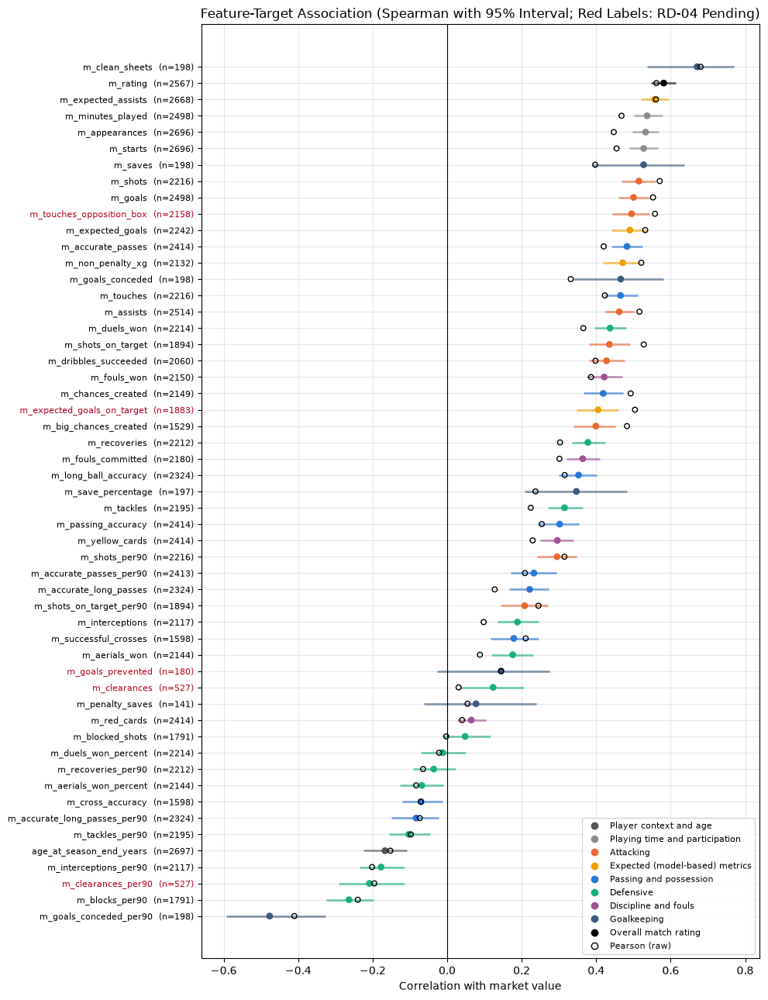

In [87]:
# Spearman with player-cluster bootstrap interval, and raw Pearson, for every feature
t = assoc43.sort_values("spearman")
fig, ax = plt.subplots(figsize=(10, 13))
y = np.arange(len(t))
colors = t["analysis_group"].map(GROUP_COLORS)
ax.hlines(y, t["spearman_ci_low"], t["spearman_ci_high"], color=colors, linewidth=2, alpha=0.6)
ax.scatter(t["spearman"], y, color=colors, s=28, zorder=3, label="Spearman (95% player-cluster bootstrap interval)")
ax.scatter(t["pearson_raw"], y, facecolors="none", edgecolors="black", s=22, zorder=3, label="Pearson, raw EUR target")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks(y, [f"{f}  (n={n})" for f, n in zip(t["feature"], t["n_pairs"])], fontsize=8)
for tick, f in zip(ax.get_yticklabels(), t["feature"]):
    if f in uni.RD04:
        tick.set_color("#b00020")
ax.set_xlabel("Correlation with market value")
ax.set_title("Feature-Target Association (Spearman with 95% Interval; Red Labels: RD-04 Pending)")
handles = [plt.Line2D([], [], color=c, marker="o", linestyle="", label=g[2:]) for g, c in GROUP_COLORS.items()]
ax.legend(handles=handles + ax.get_legend_handles_labels()[0][:0] +
          [plt.Line2D([], [], marker="o", color="black", markerfacecolor="none", linestyle="", label="Pearson (raw)")],
          loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

**Interpretation** (RD-03 applies: association with a mostly mid-season valuation, not causation)

- **Strongest monotonic associations (Spearman >= 0.5):** average match rating (0.58, interval 0.55-0.61), expected assists (0.56), the three playing-time measures (minutes 0.54, appearances 0.53, starts 0.53), shots (0.51) and goals (0.50). Among goalkeepers: clean sheets (0.67) and saves (0.53), but these rest on 198 rows from 87 goalkeepers, so their intervals are wide (0.54-0.77 and 0.39-0.64).
- **Moderate (0.3-0.5):** most attacking and creative totals (xG, touches in the opposition box, chances created, dribbles) and several volume totals (accurate passes, touches, duels won, recoveries).
- **No clear or weak association:** percentage and per-90 defensive metrics (duels won %, recoveries per 90, blocked shots, aerials won %), red cards, penalty saves and goals prevented. Defensive per-90 rates are **weakly negative** (blocks per 90 -0.26, interceptions per 90 -0.18).
- **Age** is weakly negative overall (-0.17), but section C shows that this single number hides a curved relationship.
- **Conditional features** (RD-04: `touches_opposition_box` 0.50, `expected_goals_on_target` 0.41, `clearances` 0.12, `clearances_per90` -0.21, `goals_prevented` 0.15; ISS-29 source-reported rates) are shown for description only. Their association does not resolve their eligibility. `clearances` rests on 527 rows from essentially one season (2024/25).
- Because 687 players appear in several seasons, the effective sample is closer to the number of players (about 900-1,200 for outfield features) than to `n`. The bootstrap intervals take this into account.

### C. Pearson vs Spearman: Linearity and Monotonicity

Two comparisons show the shape of a relationship: (1) Pearson on the raw target against Pearson on the log10 target and Spearman, and (2) the binned median trend.

In [88]:
gap43 = assoc43.set_index("feature")[["n_pairs", "pearson_raw", "pearson_log10", "spearman", "spearman_minus_pearson_raw"]]
print("Largest differences between Spearman and raw Pearson:")
display(gap43.reindex(gap43["spearman_minus_pearson_raw"].abs().sort_values(ascending=False).index).head(12).round(3))

binned43 = biv.binned_all(df43, register43)
shape43 = biv.binned_shape(binned43).set_index("feature")
print(shape43["trend"].value_counts().to_string())
display(shape43.join(assoc43.set_index("feature")["spearman"]).query("trend != 'monotonic'").round(2))

Largest differences between Spearman and raw Pearson:


,n_pairs,pearson_raw,pearson_log10,spearman,spearman_minus_pearson_raw
feature,,,,,
m_goals_conceded,198,0.332,0.434,0.466,0.134
m_saves,198,0.397,0.501,0.527,0.130
m_save_percentage,197,0.237,0.333,0.347,0.110
m_expected_goals_on_target,1883,0.504,0.384,0.405,-0.099
m_accurate_long_passes,2324,0.128,0.136,0.221,0.094
m_clearances,527,0.031,0.108,0.123,0.093
m_shots_on_target,1894,0.528,0.421,0.436,-0.092
m_interceptions,2117,0.098,0.167,0.189,0.091
m_tackles,2195,0.224,0.287,0.315,0.090


trend
monotonic                             21
irregular                             15
mostly monotonic (minor reversals)    14
inverted U (peak in bin 5)             1
inverted U (peak in bin 4)             1
inverted U (peak in bin 2)             1


,bins,median_first_bin_eur,median_last_bin_eur,last_to_first_ratio,direction_changes,peak_bin,trend,spearman
feature,,,,,,,,
age_at_season_end_years,10,4750000.0,2000000.0,0.42,1,5,inverted U (peak in bin 5),-0.17
m_assists,10,5000000.0,39000000.0,7.80,2,10,mostly monotonic (minor reversals),0.46
m_shots_on_target,10,7000000.0,43500000.0,6.21,2,10,mostly monotonic (minor reversals),0.44
m_shots_per90,10,8000000.0,25000000.0,3.12,2,10,mostly monotonic (minor reversals),0.29
m_shots_on_target_per90,10,15000000.0,25000000.0,1.67,4,9,irregular,0.21
m_big_chances_created,10,10000000.0,50000000.0,5.00,2,10,mostly monotonic (minor reversals),0.40
m_accurate_passes,10,4000000.0,33500000.0,8.38,2,10,mostly monotonic (minor reversals),0.48
m_accurate_passes_per90,10,10000000.0,25000000.0,2.50,2,10,mostly monotonic (minor reversals),0.23
m_accurate_long_passes,10,8000000.0,22000000.0,2.75,2,9,mostly monotonic (minor reversals),0.22


**Interpretation**

- **Spearman > raw Pearson (by 0.09-0.13):** goalkeeper volumes (saves, goals conceded), playing-time measures (appearances 0.53 vs 0.45) and defensive totals (tackles, interceptions, aerials won). The relationship is monotonic but not linear on the euro scale: values rise steadily in rank while the target tail stretches the raw scale. Log10 Pearson is close to Spearman for these features.
- **Raw Pearson > Spearman (by 0.08-0.10):** shots on target, expected goals on target, big chances created. Here a few elite attackers with very high totals and very high values drive the raw Pearson; in ranks the association is weaker. On the log10 scale these Pearson values drop to about the Spearman level. Raw Pearson is therefore not a reliable summary for this target.
- **Binned trends:** 21 features rise monotonically across all bins (all playing-time measures, rating, xG, xA, shots, goals, touches). 14 are mostly monotonic with minor reversals. 15 are irregular, mostly features with near-zero Spearman (percentages, defensive per-90 rates, red cards) or goalkeeper metrics with only about 33 rows per bin. Three show an inverted U: age, and two goalkeeper rates (save percentage, goals conceded per 90) whose six bins of about 33 rows are too noisy to read as a shape.
- **Age is clearly non-monotonic (inverted U).** The median value rises from EUR 4.75m (age 17-21) to about EUR 20-22m at 23-26, then falls to EUR 2m above 32.5. A Spearman of -0.17 summarises this curve badly. Both coefficients understate the age-value relationship, which section H quantifies by age band.

### D. Scatterplots and Descriptive Trends

The panel shows the features named in the step 8.3 instruction. Each point is a player-season (usable target, non-null feature); the y-axis is logarithmic. The black line is the binned median and the band the interquartile range of the target within each bin.

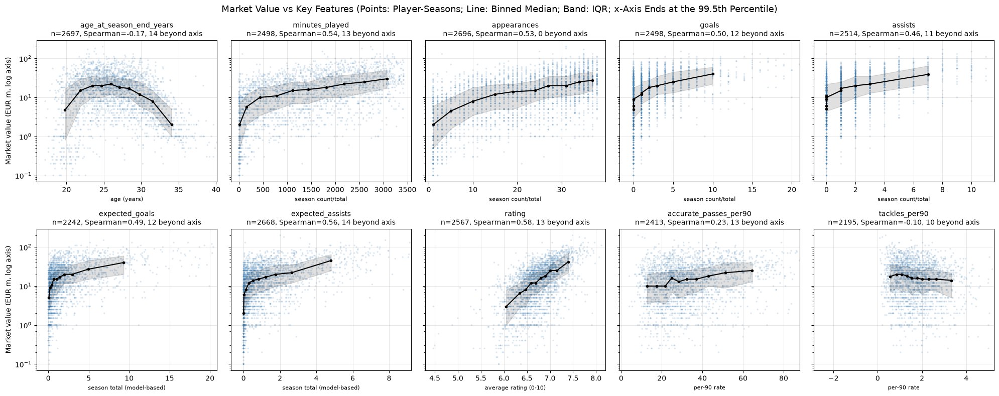

In [89]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8), sharey=True)
a43 = assoc43.set_index("feature")
for ax, f in zip(axes.flat, biv.KEY_FEATURES):
    sub = biv.pair_frame(df43, f, register43)
    ax.scatter(sub[f], sub["target_market_value"] / 1e6, s=6, alpha=0.18, color=COLOR, edgecolors="none")
    b = binned43[binned43["feature"] == f]
    ax.fill_between(b["feature_median"], b["target_p25_eur"] / 1e6, b["target_p75_eur"] / 1e6, color="black", alpha=0.12)
    ax.plot(b["feature_median"], b["target_median_eur"] / 1e6, color="black", marker="o", markersize=3)
    ax.set_yscale("log")
    hi = sub[f].quantile(0.995)
    beyond = int((sub[f] > hi).sum())
    ax.set_xlim(right=hi * 1.05)  # display only: extreme values stay in the data and in every statistic
    ax.set_title(f"{f.removeprefix('m_')}\nn={a43.at[f, 'n_pairs']}, Spearman={a43.at[f, 'spearman']:.2f}, {beyond} beyond axis", fontsize=10)
    ax.set_xlabel(uni.kind_of(f), fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("Market value (EUR m, log axis)")
fig.suptitle("Market Value vs Key Features (Points: Player-Seasons; Line: Binned Median; Band: IQR; x-Axis Ends at the 99.5th Percentile)", fontsize=13)
plt.tight_layout()
plt.show()

**Interpretation** (RD-03 applies)

- **Playing time** (minutes, appearances) shows the cleanest monotonic trend: the binned median rises from about EUR 2m to EUR 28-30m. The spread within each bin is still wide (an interquartile range of roughly a factor of 3-5), so playing time alone separates fringe from regular players but not cheap from expensive regulars.
- **Goals, assists, xG and xA** are zero-heavy (4.2). Their lower bins merge many zeros. The trend becomes steep only in the upper bins, where a few elite attackers sit. This is the reason why raw Pearson and Spearman diverge for attacking metrics.
- **Rating** rises steadily and is among the strongest associations. Rating is a composite source score that partly reflects the other metrics, so its association is not independent evidence.
- **Accurate passes per 90** shows a weak positive trend. **Tackles per 90** is flat to slightly negative: players with many defensive actions per 90 are not valued higher.
- **Age** shows the inverted U discussed above.
- Whole-season metrics include matches played after the valuation date (RD-03). A rising trend therefore means "higher-valued players also accumulate more of this over the season", not "this performance raised the value".

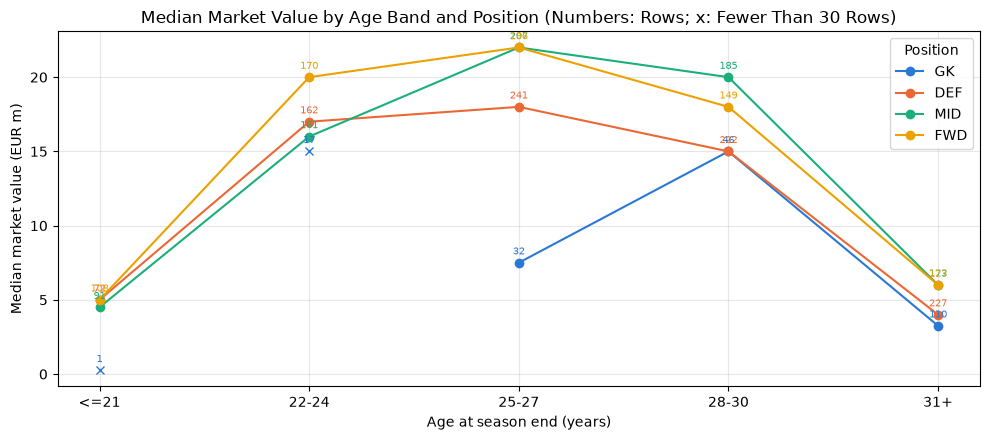

age_band,<=21,22-24,25-27,28-30,31+
position_group_season,,,,,
GK,0.25,15.0,7.5,15.0,3.25
DEF,5.00,17.0,18.0,15.0,4.00
MID,4.50,16.0,22.0,20.0,6.00
FWD,5.00,20.0,22.0,18.0,6.00


In [90]:
# Age profile by position: median value by age band (counts in labels); derived bands for description only
age43 = biv.target_quantiles_by(df43.assign(age_band=biv.age_band(df43)), [uni.POSITION, "age_band"])
fig, ax = plt.subplots(figsize=(10, 4.5))
for pos in prof.POSITION_ORDER:
    s = age43.loc[pos].reindex(biv.AGE_LABELS)
    ok = s["interpretable"].fillna(False).astype(bool)
    ax.plot(biv.AGE_LABELS, (s["median_eur"] / 1e6).where(ok), marker="o", color=POS_COLORS[pos], label=pos)
    ax.plot(biv.AGE_LABELS, (s["median_eur"] / 1e6).where(~ok), marker="x", linestyle="", color=POS_COLORS[pos])
    for x, (m, n) in enumerate(zip(s["median_eur"], s["n_target"])):
        if pd.notna(m):
            ax.annotate(f"{int(n)}", (x, m / 1e6), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=7, color=POS_COLORS[pos])
ax.set_title("Median Market Value by Age Band and Position (Numbers: Rows; x: Fewer Than 30 Rows)")
ax.set_xlabel("Age at season end (years)")
ax.set_ylabel("Median market value (EUR m)")
ax.legend(title="Position")
plt.tight_layout()
plt.show()
display(age43["median_eur"].unstack("age_band")[biv.AGE_LABELS].reindex(prof.POSITION_ORDER) / 1e6)

**Interpretation**

- The inverted U holds in every outfield position: medians peak at 22-27 years (EUR 17-22m) and drop to EUR 4-6m at 31+. Young players (<=21) also have low medians (EUR 4.5-5m) but the widest spread (interquartile ratio about 20), because the group mixes established young starters with fringe academy players.
- Goalkeepers peak later (28-30). The goalkeeper bands below 25 years have fewer than 30 rows and are not interpreted.
- Within-position Spearman of age reflects this: strongly negative for goalkeepers (-0.41) and defenders (-0.25), near zero for forwards (0.01), where the rising and the falling part cancel out.
- `age_at_season_end_years` depends on birth dates, 4 of which are disputed across sources (ISS-07).

### E. Playing Time as a Common Driver

Season totals grow with playing time, and playing time is itself strongly associated with value. The partial Spearman removes the part of a feature-target association that both share with minutes (or starts). It is a descriptive decomposition, not an adjustment of the data and not a causal estimate.

,n_with_minutes,spearman,spearman_with_minutes,partial_spearman_given_minutes,n_with_starts,partial_spearman_given_starts
feature,,,,,,
m_rating,2373,0.581,0.652,0.410,2567,0.406
m_long_ball_accuracy,2127,0.353,0.063,0.347,2324,0.365
m_clean_sheets,0,0.671,NaN,NaN,198,0.340
m_shots,2216,0.515,0.664,0.327,2216,0.330
m_expected_assists,2469,0.557,0.774,0.281,2667,0.328
m_touches_opposition_box,2158,0.495,0.613,0.324,2158,0.327
m_passing_accuracy,2216,0.302,0.053,0.277,2414,0.323
m_shots_per90,2216,0.295,0.023,0.318,2216,0.323
m_non_penalty_xg,2132,0.471,0.545,0.318,2132,0.320


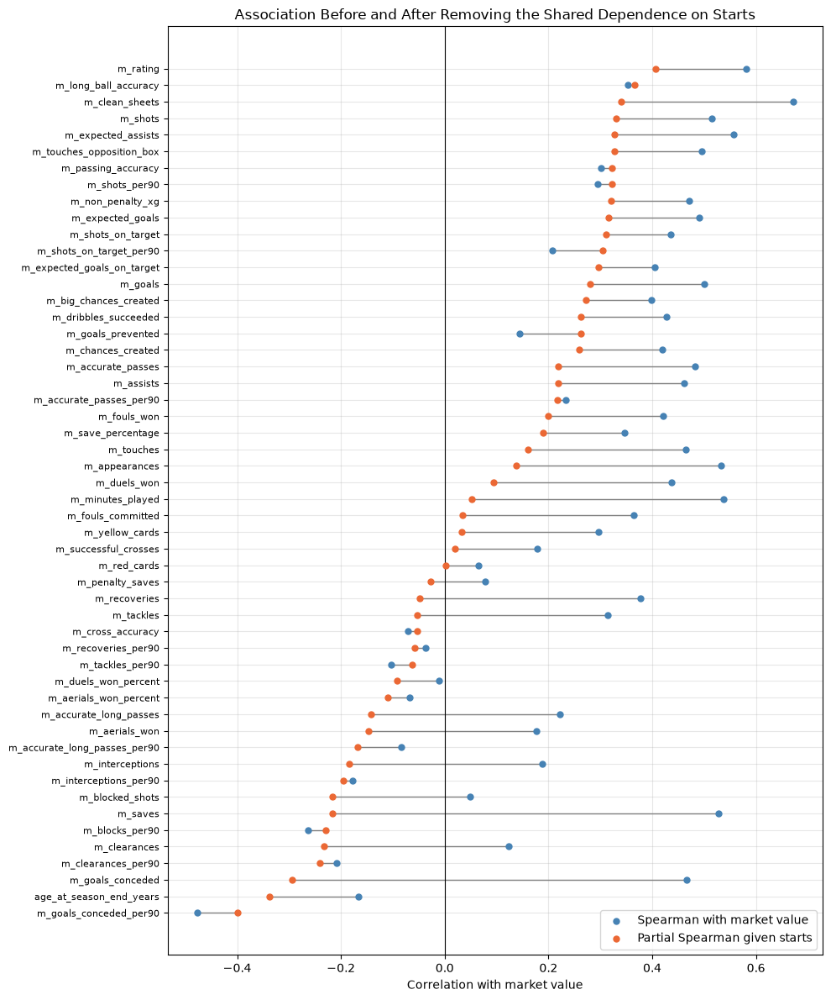

Totals vs their per-90 rates (outfield rows):


,total,n,spearman_total_rate,spearman_total_minutes,spearman_rate_minutes
rate,,,,,
m_shots_per90,m_shots,2224,0.709,0.667,0.026
m_shots_on_target_per90,m_shots_on_target,1898,0.719,0.484,-0.181
m_accurate_passes_per90,m_accurate_passes,2223,0.569,0.852,0.113
m_accurate_long_passes_per90,m_accurate_long_passes,2132,0.749,0.729,0.163
m_tackles_per90,m_tackles,2203,0.446,0.792,-0.112
m_interceptions_per90,m_interceptions,2123,0.621,0.721,-0.005
m_recoveries_per90,m_recoveries,2220,0.397,0.904,0.032
m_blocks_per90,m_blocked_shots,1794,0.718,0.519,-0.133
m_clearances_per90,m_clearances,531,0.712,0.656,0.016


In [91]:
pt43 = assoc43.set_index("feature")[["n_with_minutes", "spearman", "spearman_with_minutes", "partial_spearman_given_minutes",
                                     "n_with_starts", "partial_spearman_given_starts"]]
display(pt43.sort_values("partial_spearman_given_starts", ascending=False).round(3))

fig, ax = plt.subplots(figsize=(10, 12))
t = pt43.dropna(subset=["partial_spearman_given_starts"]).sort_values("partial_spearman_given_starts")
y = np.arange(len(t))
ax.hlines(y, t["spearman"], t["partial_spearman_given_starts"], color="grey", linewidth=1)
ax.scatter(t["spearman"], y, color=COLOR, s=25, zorder=3, label="Spearman with market value")
ax.scatter(t["partial_spearman_given_starts"], y, color="#eb6834", s=25, zorder=3, label="Partial Spearman given starts")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks(y, t.index, fontsize=8)
ax.set_xlabel("Correlation with market value")
ax.set_title("Association Before and After Removing the Shared Dependence on Starts")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

print("Totals vs their per-90 rates (outfield rows):")
display(biv.per90_vs_total(df43).set_index("rate").round(3))

**Interpretation**

- **Most volume associations are largely playing time.** Given starts, appearances drop from 0.53 to 0.14, recoveries from 0.38 to -0.05, tackles from 0.32 to -0.05, duels won from 0.44 to 0.09, touches from 0.47 to 0.16, fouls committed and yellow cards to about 0.03. Results given minutes are almost identical (minutes and starts correlate at 0.995).
- **Associations that remain beyond playing time** (partial about 0.3-0.4): rating (0.41), long-ball accuracy (0.37), shots and shots per 90 (0.33/0.32), xA (0.33), passing accuracy (0.32), touches in the opposition box (0.33, RD-04 pending), xG and non-penalty xG (0.32), goals (0.28). Age becomes more negative (-0.34): among players with the same number of starts, older players are valued lower.
- **Defensive totals turn negative given playing time:** interceptions (-0.18), blocked shots (-0.22), clearances (-0.23, RD-04), aerials won (-0.15). For a given number of starts, players with more defensive actions tend to have lower values. One plausible but **unverified** explanation is team context: players in stronger, possession-dominant teams defend less and are valued higher. Club context is not analysed here (RS5-12), so this cannot be checked in this phase.
- **Goalkeepers:** saves change from +0.53 to -0.22 and goals conceded from +0.47 to -0.29 given starts; clean sheets keep +0.34. The raw positive correlation of saves and goals conceded with value reflects that regular starters are valued higher, not that conceding goals is valued. Once starts are held fixed, conceding fewer goals goes with higher value, again consistent with a team-strength effect.
- **Per-90 rates remove most of the playing-time dependence:** their correlation with minutes is between -0.18 and 0.16, against 0.48-0.90 for the totals. Rates still carry the small-denominator instability of P4-B05.

### F. Relationships by Position and Season

Pooled correlations mix the four positions and the five seasonal valuation batches. The heatmap shows the Spearman correlation of each feature with the target inside each position and each season. Empty cells have fewer than 30 pairs.

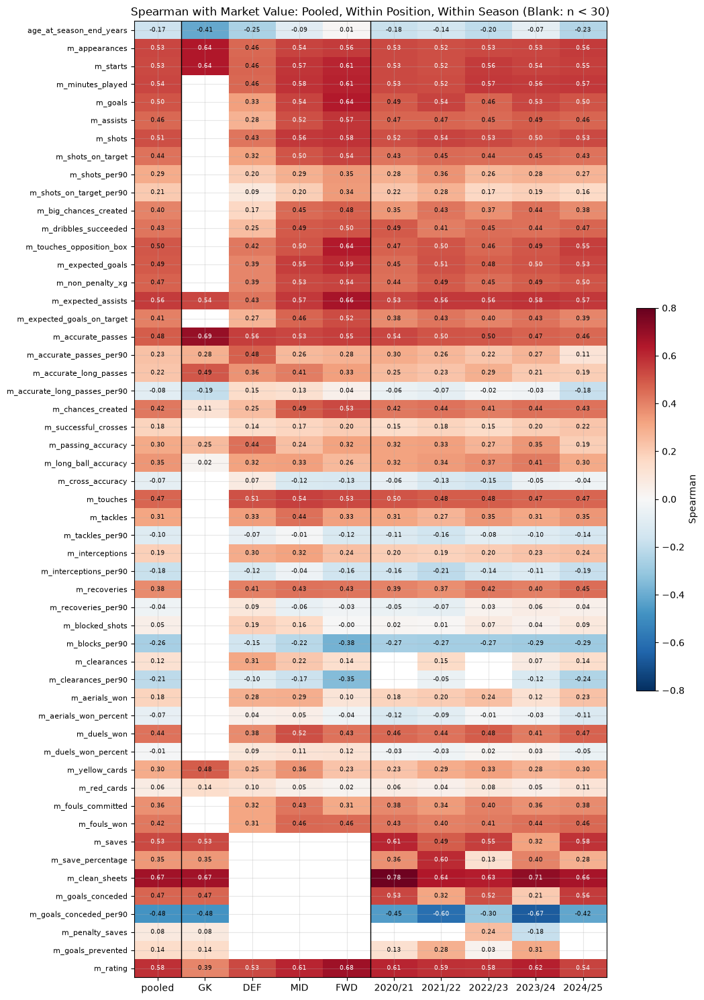

Minimum pair count per position and per season:


,GK,DEF,MID,FWD,2020/21,2021/22,2022/23,2023/24,2024/25
min n,0,0,0,0,0,26,0,30,26


,pooled_spearman,season_min,season_max,season_range,seasons_reported,position_min,position_max,positions_reported,sign_differs_across_positions
m_save_percentage,0.347,0.130,0.598,0.468,5,0.347,0.347,1,False
m_penalty_saves,0.077,-0.183,0.245,0.428,2,0.077,0.077,1,False
m_goals_conceded_per90,-0.477,-0.668,-0.297,0.371,5,-0.477,-0.477,1,False
m_goals_conceded,0.466,0.211,0.558,0.346,5,0.466,0.466,1,False
m_saves,0.527,0.320,0.607,0.287,5,0.527,0.527,1,False
m_goals_prevented,0.145,0.026,0.305,0.279,4,0.145,0.145,1,False
m_accurate_passes_per90,0.233,0.111,0.297,0.186,5,0.259,0.478,4,False
m_clearances_per90,-0.209,-0.238,-0.054,0.185,3,-0.349,-0.097,3,False
m_accurate_long_passes_per90,-0.083,-0.183,-0.018,0.164,5,-0.192,0.147,4,True
age_at_season_end_years,-0.167,-0.232,-0.072,0.160,5,-0.412,0.010,4,False


In [92]:
rho_pos43, n_pos43 = biv.association_by_group(df43, register43, uni.POSITION, prof.POSITION_ORDER)
rho_season43, n_season43 = biv.association_by_group(df43, register43, "season", SEASONS43)
within43 = biv.pooled_vs_within(assoc43, rho_season43, rho_pos43)
grid = pd.concat([within43[["pooled_spearman"]].rename(columns={"pooled_spearman": "pooled"}), rho_pos43,
                  rho_season43.rename(columns=prof.short)], axis=1).loc[uni.FEATURES]

fig, ax = plt.subplots(figsize=(11, 15))
im = ax.imshow(grid.to_numpy(float), cmap="RdBu_r", vmin=-0.8, vmax=0.8, aspect="auto")
ax.set_xticks(range(grid.shape[1]), grid.columns)
ax.set_yticks(range(grid.shape[0]), grid.index, fontsize=8)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.iat[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5, color="white" if abs(v) > 0.5 else "black")
for x in (0.5, 4.5):
    ax.axvline(x, color="black", linewidth=1)
ax.set_title("Spearman with Market Value: Pooled, Within Position, Within Season (Blank: n < 30)")
fig.colorbar(im, ax=ax, shrink=0.4, label="Spearman")
plt.tight_layout()
plt.show()

print("Minimum pair count per position and per season:")
display(pd.concat([n_pos43.min(), n_season43.rename(columns=prof.short).min()]).to_frame("min n").T)
display(within43.sort_values("season_range", ascending=False).head(10).round(3))

**Interpretation** (RD-03 applies; season comparisons also reflect batch timing, ISS-21)

- **By position, the direction is stable and the strength differs.** No feature has clearly opposite signs across positions (only long-pass rate per 90 changes sign, from -0.19 for goalkeepers to +0.15 for defenders, both weak). Attacking metrics are much more strongly associated with value for forwards than for defenders (goals 0.64 vs 0.33; assists 0.57 vs 0.28; touches in the opposition box 0.64 vs 0.42). Rating is strongest for forwards (0.68) and weakest for goalkeepers (0.39). For defenders, passing measures are relatively strong (accurate passes per 90 0.48, passing accuracy 0.44).
- **By season, outfield associations are stable:** the range of within-season Spearman values is at most about 0.1-0.2 for outfield features. The largest season ranges occur for goalkeeper metrics (save percentage 0.47, penalty saves 0.43, goals conceded per 90 0.37), which rest on about 40 goalkeeper rows per season and are not interpreted season by season.
- Stable within-season correlations mean that the pooled associations are not artefacts of a single season's valuation batch. The seasonal batches shift the **level** of the target (section H), not its rank association with performance.

### G. Identity Sensitivity (P4-B01)

The 533 rows whose identity mapping is not independently validated (or whose validation label is inconclusive) stay in every main result. Here each feature-target Spearman is recomputed without them to show how much the conclusions depend on these rows.

In [93]:
sens43 = biv.identity_sensitivity(df43, register43).set_index("feature")
display(biv.identity_subset_profile(df43))
display(sens43.reindex(sens43["difference"].abs().sort_values(ascending=False).index).head(10).round(3))
flips = (np.sign(sens43["spearman_all"]) != np.sign(sens43["spearman_without_p4b01"])) & (sens43["spearman_all"].abs() > 0.05)
print("Median |difference|:", round(sens43["difference"].abs().median(), 3),
      "| features with |difference| > 0.05:", int((sens43["difference"].abs() > 0.05).sum()),
      "| sign changes among |rho| > 0.05:", int(flips.sum()))

,rows,usable_targets,median_eur,p75_eur
P4-B01 subset,533,505,8000000.0,22000000.0
other rows,2214,2192,15000000.0,28000000.0


,n_all,n_without_p4b01,spearman_all,spearman_without_p4b01,difference
feature,,,,,
m_save_percentage,197,151,0.347,0.254,-0.092
age_at_season_end_years,2697,2192,-0.167,-0.237,-0.070
m_goals_prevented,180,136,0.145,0.077,-0.068
m_goals_conceded_per90,198,151,-0.477,-0.414,0.062
m_saves,198,151,0.527,0.472,-0.056
m_appearances,2696,2192,0.533,0.484,-0.049
m_starts,2696,2192,0.528,0.485,-0.042
m_clean_sheets,198,151,0.671,0.631,-0.040
m_minutes_played,2498,2041,0.537,0.498,-0.039


Median |difference|: 0.016 | features with |difference| > 0.05: 5 | sign changes among |rho| > 0.05: 0


**Interpretation**

- Results are **robust to identity evidence quality**. The median absolute change is 0.016; no association with \|rho\| > 0.05 changes sign. Only 5 features change by more than 0.05: four goalkeeper metrics, whose sample shrinks from about 198 to 151 rows, and age (-0.17 to -0.24).
- The P4-B01 rows are **not a random subset**: their median value is EUR 8m against EUR 15m for the other rows (inference: lower-profile players more often lack an independent identity check). Removing them would therefore shift the population. This is why they stay in the main analysis (P4-B01) and are used only for comparison.
- Robustness to the P4-B01 rows does not prove that mappings are correct. Identities are still not human-validated (ISS-01).

### H. Categorical Feature vs Target

The only categorical candidate predictor is `position_group_season` (a whole-season modal position, P4-B04). Season is a grouping key, not a predictor (P4-A05). Age band and minutes band are derived from numeric candidates for description only. Missing minutes form their own category. Club context is not analysed (RS5-12).

In [94]:
pos43 = biv.target_quantiles_by(df43, uni.POSITION, prof.POSITION_ORDER)
season43 = biv.target_quantiles_by(df43, "season", SEASONS43)
cells43 = biv.position_season_long(df43, scope43)
display((pos43[["n_target", "p10_eur", "p25_eur", "median_eur", "p75_eur", "p90_eur"]].astype(float) / [1, 1e6, 1e6, 1e6, 1e6, 1e6]).round(2))
display((season43.rename(index=prof.short)[["n_target", "p10_eur", "p25_eur", "median_eur", "p75_eur", "p90_eur"]].astype(float) / [1, 1e6, 1e6, 1e6, 1e6, 1e6]).round(2))
display(cells43["median_eur"].unstack("season").rename(columns=prof.short).reindex(prof.POSITION_ORDER) / 1e6)
display(cells43["n_target"].unstack("season").rename(columns=prof.short).reindex(prof.POSITION_ORDER))
display(biv.position_season_spread(cells43).round(2))
effects43 = biv.categorical_effects(df43)
display(effects43.round(3))

,n_target,p10_eur,p25_eur,median_eur,p75_eur,p90_eur
position_group_season,,,,,,
GK,206.0,0.85,2.0,6.0,17.75,25.0
DEF,924.0,1.80,4.0,12.0,25.00,38.0
MID,817.0,2.00,6.0,15.0,30.00,50.0
FWD,750.0,1.98,6.0,15.0,30.00,55.0


,n_target,p10_eur,p25_eur,median_eur,p75_eur,p90_eur
season,,,,,,
2020/21,515.0,1.5,4.0,10.0,22.0,40.0
2021/22,528.0,1.5,3.5,10.0,22.0,40.0
2022/23,542.0,2.0,6.0,15.0,25.0,45.0
2023/24,567.0,1.0,4.5,13.0,28.0,48.8
2024/25,545.0,2.0,8.0,17.0,30.0,50.0


season,2020/21,2021/22,2022/23,2023/24,2024/25
position_group_season,,,,,
GK,6.00,4.5,6.0,9.5,8.5
DEF,7.25,10.0,15.0,12.0,16.0
MID,12.00,12.0,15.0,15.0,18.0
FWD,12.00,12.0,15.0,15.0,19.0


season,2020/21,2021/22,2022/23,2023/24,2024/25
position_group_season,,,,,
GK,41,42,39,40,44
DEF,184,180,180,191,189
MID,149,151,172,179,166
FWD,141,155,151,157,146


,min_season_median_eur,max_season_median_eur,max_to_min_ratio,smallest_cell_n
position_group_season,,,,
GK,4500000.0,9500000.0,2.11,39
DEF,7250000.0,16000000.0,2.21,180
MID,12000000.0,18000000.0,1.50,149
FWD,12000000.0,19000000.0,1.58,141


,grouping,n,groups,kruskal_h,epsilon_squared
0,position_group_season,2697,4,69.785,0.026
1,"season (grouping key, not a predictor)",2697,5,39.218,0.015
2,position x season (grouping),2697,20,115.387,0.043
3,age band (derived from age),2697,5,528.522,0.196
4,minutes band (derived; missing kept separate),2697,5,672.134,0.249
5,season within GK,206,5,2.706,0.013
6,season within DEF,924,5,22.391,0.024
7,season within MID,817,5,6.946,0.009
8,season within FWD,750,5,14.412,0.019
9,position within 2020/2021,515,4,18.187,0.035


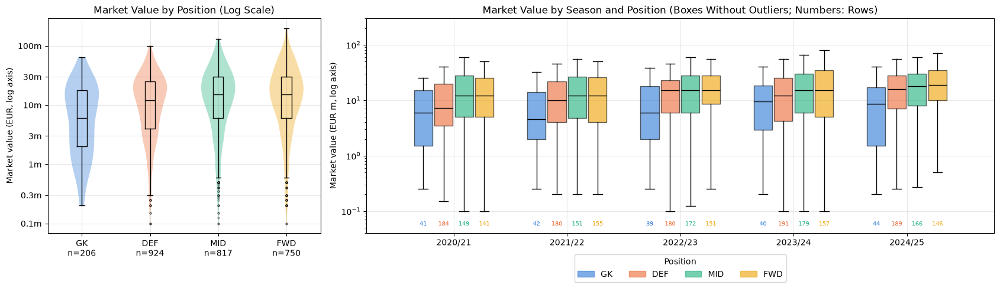

In [95]:
u43 = df43.loc[df43["target_usable"]]
fig, axes = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [1, 2.3]})
data = [np.log10(u43.loc[u43[uni.POSITION] == p, "target_market_value"]) for p in prof.POSITION_ORDER]
parts = axes[0].violinplot(data, showextrema=False)
for body, p in zip(parts["bodies"], prof.POSITION_ORDER):
    body.set_facecolor(POS_COLORS[p])
    body.set_alpha(0.35)
axes[0].boxplot(data, widths=0.15, flierprops={"marker": "o", "markersize": 2, "alpha": 0.4}, medianprops={"color": "black"})
axes[0].set_xticks(range(1, 5), [f"{p}\nn={len(d)}" for p, d in zip(prof.POSITION_ORDER, data)])
ticks = [0.1, 0.3, 1, 3, 10, 30, 100]
axes[0].set_yticks(np.log10(np.array(ticks) * 1e6), [f"{t:g}m" for t in ticks])
axes[0].set_title("Market Value by Position (Log Scale)")
axes[0].set_ylabel("Market value (EUR, log axis)")

width = 0.18
for k, p in enumerate(prof.POSITION_ORDER):
    d = [u43.loc[(u43[uni.POSITION] == p) & (u43["season"] == s), "target_market_value"] / 1e6 for s in SEASONS43]
    pos_x = np.arange(len(SEASONS43)) + (k - 1.5) * width
    bp = axes[1].boxplot(d, positions=pos_x, widths=width * 0.9, patch_artist=True, showfliers=False,
                         medianprops={"color": "black"})
    for box in bp["boxes"]:
        box.set_facecolor(POS_COLORS[p])
        box.set_alpha(0.6)
    for x, v in zip(pos_x, d):
        axes[1].annotate(str(len(v)), (x, 0.055), ha="center", fontsize=7, color=POS_COLORS[p])
axes[1].set_yscale("log")
axes[1].set_ylim(0.04, 300)
axes[1].set_xticks(range(len(SEASONS43)), [prof.short(s) for s in SEASONS43])
axes[1].set_title("Market Value by Season and Position (Boxes Without Outliers; Numbers: Rows)")
axes[1].set_ylabel("Market value (EUR m, log axis)")
axes[1].legend([plt.Rectangle((0, 0), 1, 1, color=POS_COLORS[p], alpha=0.6) for p in prof.POSITION_ORDER],
               prof.POSITION_ORDER, title="Position", loc="upper center", ncols=4, bbox_to_anchor=(0.5, -0.08))
plt.tight_layout()
plt.show()

In [96]:
# Derived categories (description only): age band and minutes band; missing minutes kept as a separate category
display((biv.target_quantiles_by(df43.assign(age_band=biv.age_band(df43)), "age_band", biv.AGE_LABELS)
         [["n_target", "p25_eur", "median_eur", "p75_eur"]].astype(float) / [1, 1e6, 1e6, 1e6]).round(2))
minutes43 = biv.target_quantiles_by(df43.assign(minutes_band=biv.minutes_band(df43)), "minutes_band",
                                    [*uni.MINUTES_LABELS, "minutes missing"])
display((minutes43[["rows", "n_target", "p25_eur", "median_eur", "p75_eur"]].astype(float) / [1, 1, 1e6, 1e6, 1e6]).round(2))
print("Positions of rows with missing minutes:",
      df43.loc[df43["m_minutes_played"].isna(), uni.POSITION].value_counts().to_dict())

,n_target,p25_eur,median_eur,p75_eur
age_band,,,,
<=21,272.0,0.8,5.0,17.25
22-24,510.0,8.0,17.0,32.00
25-27,676.0,12.0,20.0,35.00
28-30,602.0,8.0,17.0,30.00
31+,637.0,2.0,5.0,12.00


,rows,n_target,p25_eur,median_eur,p75_eur
minutes_band,,,,,
1-89,330.0,290.0,0.50,2.5,8.0
90-449,362.0,352.0,2.50,7.0,15.0
450-899,320.0,320.0,4.88,10.0,20.0
900+,1536.0,1536.0,10.00,20.0,35.0
minutes missing,199.0,199.0,2.00,7.0,18.0


Positions of rows with missing minutes: {'GK': 199}


**Interpretation** (RD-03 and ISS-21 apply)

- **Position:** goalkeepers are valued lowest (median EUR 6m, n = 206), defenders in between (EUR 12m), midfielders and forwards highest (EUR 15m each); forwards have the longest upper tail (p90 EUR 55m). The spread inside each position is much larger than the difference between positions: position explains little of the rank variation of value (epsilon-squared 0.026).
- **Season:** medians rise from EUR 10m (2020/21, 2021/22) to EUR 17m (2024/25), epsilon-squared 0.015. Because each season's target comes mainly from one valuation batch at a different distance from season end, this is a mix of market inflation and batch timing (ISS-21). It is not read as a performance effect.
- **Position x season:** season medians move by a factor of 1.5 (midfielders, forwards) to 2.2 (goalkeepers, defenders) within a position. The smallest cell has 39 goalkeeper rows, so every cell is above the 30-row threshold; goalkeeper cells are still imprecise. The seasonal pattern differs by position (for example the defender median rises from EUR 7.25m in 2020/21 to EUR 16m in 2024/25), so position and season effects are not simply additive.
- **Derived categories are much stronger groupings than position or season:** minutes band (epsilon-squared 0.25; median EUR 2.5m below 90 minutes, EUR 20m at 900+) and age band (0.20). The 199 rows with missing minutes (mostly goalkeepers, ISS-11) have a median of EUR 7m. They are shown as their own category and are not treated as zero minutes.
- Comparisons use counts on every chart and table. Groups below 30 rows (only goalkeeper age bands) are not interpreted.

### I. Feature-Feature Correlation Matrix

Spearman correlations between the 46 outfield features on outfield rows (pairwise-complete; cells with fewer than 30 pairs left empty), ordered by analysis group. Goalkeeper metrics are compared separately on goalkeeper rows, because they are not applicable to outfield players.

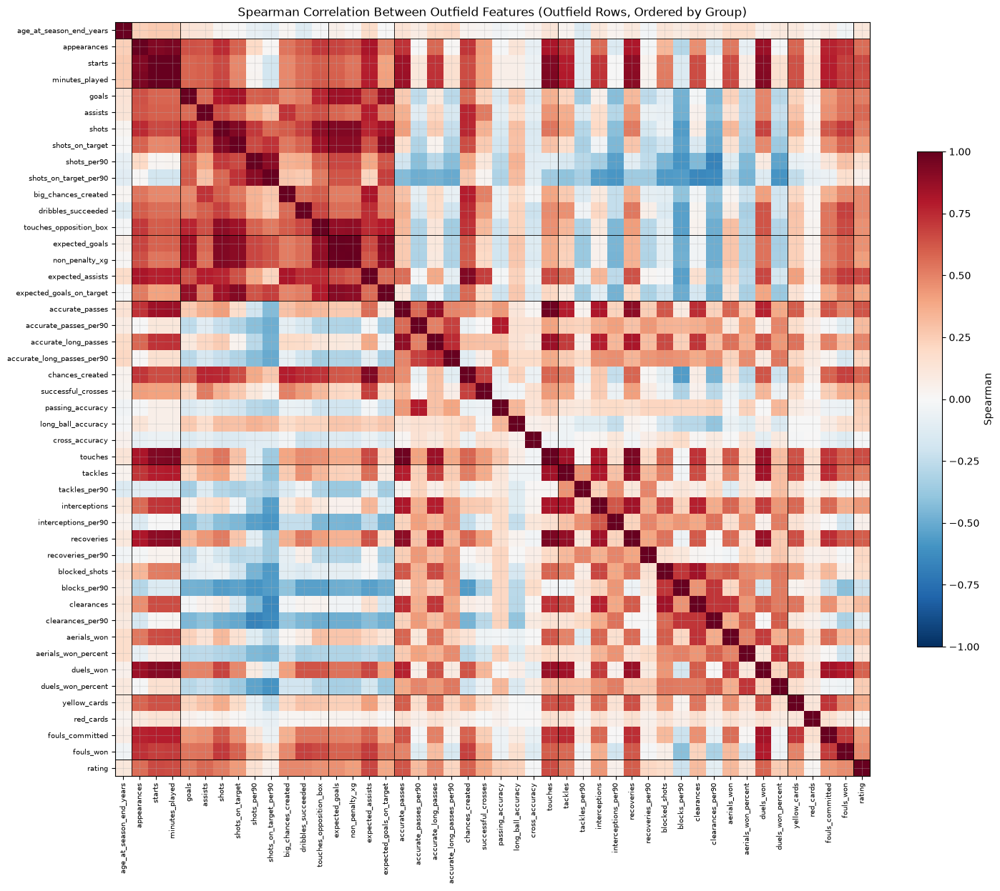

Pair counts: min 381 | median 2108 | cells left empty (n < 30): 0


,age_at_season_end_years,m_appearances,m_starts,m_rating,m_saves,m_save_percentage,m_clean_sheets,m_goals_conceded,m_goals_conceded_per90,m_penalty_saves,m_goals_prevented
age_at_season_end_years,1.00,0.02,0.01,0.00,-0.02,-0.02,-0.03,-0.01,0.09,0.05,0.00
m_appearances,0.02,1.00,1.00,0.32,0.95,0.33,0.88,0.91,-0.28,0.19,-0.10
m_starts,0.01,1.00,1.00,0.32,0.94,0.34,0.88,0.91,-0.28,0.20,-0.10
m_rating,0.00,0.32,0.32,1.00,0.30,0.75,0.43,0.10,-0.63,0.10,0.57
m_saves,-0.02,0.95,0.94,0.30,1.00,0.38,0.78,0.95,-0.16,0.20,-0.07
m_save_percentage,-0.02,0.33,0.34,0.75,0.38,1.00,0.46,0.12,-0.75,0.07,0.53
m_clean_sheets,-0.03,0.88,0.88,0.43,0.78,0.46,1.00,0.70,-0.54,0.18,0.02
m_goals_conceded,-0.01,0.91,0.91,0.10,0.95,0.12,0.70,1.00,0.03,0.20,-0.27
m_goals_conceded_per90,0.09,-0.28,-0.28,-0.63,-0.16,-0.75,-0.54,0.03,1.00,-0.07,-0.39
m_penalty_saves,0.05,0.19,0.20,0.10,0.20,0.07,0.18,0.20,-0.07,1.00,0.02


In [97]:
outfield43 = df43[uni.POSITION].isin(biv.OUTFIELD)
corr43, n43 = biv.correlation_matrix(df43, biv.OUTFIELD_FEATURES, outfield43, "spearman")
pearson43, _ = biv.correlation_matrix(df43, biv.OUTFIELD_FEATURES, outfield43, "pearson")

fig, ax = plt.subplots(figsize=(15, 13))
im = ax.imshow(corr43.to_numpy(float), cmap="RdBu_r", vmin=-1, vmax=1)
labels = [f.removeprefix("m_") for f in corr43.columns]
ax.set_xticks(range(len(labels)), labels, rotation=90, fontsize=7)
ax.set_yticks(range(len(labels)), labels, fontsize=7)
edges = np.cumsum([sum(f in biv.OUTFIELD_FEATURES for f in fs) for fs in uni.FEATURE_GROUPS.values()])[:-1]
for e in edges:
    ax.axhline(e - 0.5, color="black", linewidth=0.6)
    ax.axvline(e - 0.5, color="black", linewidth=0.6)
ax.set_title("Spearman Correlation Between Outfield Features (Outfield Rows, Ordered by Group)")
fig.colorbar(im, ax=ax, shrink=0.6, label="Spearman")
plt.tight_layout()
plt.show()
print("Pair counts: min", int(n43.to_numpy().min()), "| median", int(np.median(n43.to_numpy())),
      "| cells left empty (n < 30):", int(corr43.isna().to_numpy().sum()))

gk_cols43 = ["age_at_season_end_years", "m_appearances", "m_starts", "m_rating", *biv.GK_FEATURES]
corr_gk43, n_gk43 = biv.correlation_matrix(df43, gk_cols43, df43[uni.POSITION].eq("GK"), "spearman")
display(corr_gk43.round(2))

**Interpretation**

- The matrix has a clear block structure. One large positive block contains **playing time and every volume total** (touches, accurate passes, recoveries, duels won, tackles, fouls). A second block contains **shots, goals and xG**. A third contains **chance creation** (chances created, xA, big chances created, assists).
- **Per-90 rates and percentages are much less correlated** with the volume block, because dividing by minutes removes the shared playing-time component.
- Defensive per-90 rates correlate negatively with shot rates (blocks per 90 vs shots per 90: -0.59): a role difference (defenders vs attackers) inside the outfield rows.
- Pair counts range from 381 (`big_chances_created` with `clearances`, RD-04) to about 2,500. No cell is below 30 pairs.
- **Goalkeepers:** appearances, starts, saves, goals conceded and clean sheets form one block (0.88-0.996), all driven by how often the goalkeeper plays. Rates (save percentage, goals conceded per 90, goals prevented) are much less tied to playing time.

### J. Strongly Correlated Pairs and Redundancy

Pairs with \|Spearman\| >= 0.8 are listed with their semantic relation. Their within-season correlations show whether the overlap depends on the season. Redundancy clusters link features at \|Spearman\| >= 0.9. **This describes overlap; no feature is removed, merged or preferred (no feature selection).**

In [98]:
pairs43 = biv.strong_pairs(corr43, n43, pearson43, register43)
display(pairs43.round(3))
print(pairs43["relation"].value_counts().to_string())
pairs_season43 = biv.pair_by_season(df43, pairs43, outfield43, scope43)
print("Largest within-season range among strong pairs:", round(pairs_season43["season_range"].max(), 3))
display(pairs_season43.sort_values("season_range", ascending=False).head(5).round(3))
display(biv.redundancy_clusters(corr43))
display(biv.strong_pairs(corr_gk43, n_gk43, biv.correlation_matrix(df43, gk_cols43, df43[uni.POSITION].eq("GK"), "pearson")[0], register43).round(3))

,feature_a,feature_b,spearman,pearson_raw,n_pairs,relation
0,m_starts,m_minutes_played,0.995,0.996,2541,playing-time measures
1,m_expected_goals,m_non_penalty_xg,0.992,0.982,2138,"overlapping definition (shots, goals and xG)"
2,m_accurate_passes,m_touches,0.971,0.955,2224,same metric family (Passing and possession)
3,m_appearances,m_minutes_played,0.941,0.925,2541,playing-time measures
4,m_touches,m_recoveries,0.939,0.900,2220,season totals of different actions (shared dep...
5,m_minutes_played,m_touches,0.932,0.897,2224,volume metric scales with playing time
6,m_expected_assists,m_chances_created,0.929,0.939,2089,overlapping definition (chance creation and xA)
7,m_shots,m_shots_on_target,0.929,0.952,1898,"overlapping definition (shots, goals and xG)"
8,m_shots,m_expected_goals,0.926,0.908,2139,"overlapping definition (shots, goals and xG)"
9,m_shots,m_non_penalty_xg,0.925,0.906,2138,"overlapping definition (shots, goals and xG)"


relation
overlapping definition (shots, goals and xG)                              15
volume metric scales with playing time                                    12
season totals of different actions (shared dependence on playing time)    10
same metric family (Defensive)                                             6
playing-time measures                                                      3
same metric family (Passing and possession)                                3
same metric family (Attacking)                                             3
overlapping definition (chance creation and xA)                            2
Largest within-season range among strong pairs: 0.071


,feature_a,feature_b,pooled,2020/21,2021/22,2022/23,2023/24,2024/25,season_min,season_max,season_range
47,m_big_chances_created,m_expected_assists,0.815,0.776,0.813,0.824,0.816,0.847,0.776,0.847,0.071
51,m_appearances,m_recoveries,0.806,0.826,0.825,0.790,0.830,0.852,0.790,0.852,0.062
45,m_accurate_long_passes,m_recoveries,0.819,0.838,0.826,0.839,0.818,0.778,0.778,0.839,0.061
38,m_interceptions,m_recoveries,0.839,0.859,0.857,0.855,0.819,0.799,0.799,0.859,0.060
29,m_recoveries,m_duels_won,0.864,0.838,0.854,0.870,0.882,0.895,0.838,0.895,0.057


,cluster,size,members,min_abs_spearman_within,median_abs_spearman_within
0,1,7,"m_appearances, m_starts, m_minutes_played, m_a...",0.722812,0.898157
1,2,5,"m_shots, m_shots_on_target, m_expected_goals, ...",0.839665,0.914017
2,3,2,"m_shots_per90, m_shots_on_target_per90",0.902646,0.902646
3,4,2,"m_expected_assists, m_chances_created",0.929408,0.929408


,feature_a,feature_b,spearman,pearson_raw,n_pairs,relation
0,m_appearances,m_starts,0.996,0.999,205,playing-time measures
1,m_saves,m_goals_conceded,0.951,0.939,198,same metric family (Goalkeeping)
2,m_appearances,m_saves,0.945,0.936,198,volume metric scales with playing time
3,m_starts,m_saves,0.944,0.935,198,volume metric scales with playing time
4,m_appearances,m_goals_conceded,0.911,0.898,198,volume metric scales with playing time
5,m_starts,m_goals_conceded,0.910,0.897,198,volume metric scales with playing time
6,m_starts,m_clean_sheets,0.883,0.845,198,volume metric scales with playing time
7,m_appearances,m_clean_sheets,0.882,0.844,198,volume metric scales with playing time


**Interpretation**

- **54 outfield pairs** reach \|Spearman\| >= 0.8. All are positive. By relation: 15 within the shots-goals-xG family, 2 within chance creation and xA, 12 between a volume metric and playing time, 3 among the playing-time measures, 10 between season totals of different actions (shared playing-time dependence), and 12 within a metric family (defensive, passing, attacking).
- **Near-duplicates (\|rho\| >= 0.97):** starts and minutes (0.995), xG and non-penalty xG (0.992), accurate passes and touches (0.971). These pairs carry almost the same rank information.
- **Four redundancy clusters at 0.9:** (1) playing time with volume totals (appearances, starts, minutes, accurate passes, touches, recoveries, duels won); (2) shots, shots on target, xG, non-penalty xG, xG on target; (3) shots per 90 and shots on target per 90; (4) xA and chances created.
- **Overlap is stable across seasons:** within-season correlations of the strong pairs differ by at most 0.07. The redundancy is structural (definitions and playing time), not a season effect.
- **Goalkeepers:** 8 pairs at >= 0.8, all within the playing-time block (appearances and starts 0.996; saves and goals conceded 0.95).
- Raw Pearson is close to Spearman for most pairs, but it is higher for goal-xG pairs (goals vs xGOT: Pearson 0.95, Spearman 0.88), because both totals are extreme for the same elite forwards.
- Implication for later phases (not acted on here): models sensitive to collinearity will see heavily overlapping inputs. Which representation to keep (totals, rates, or both) is a feature-design decision (P4-D03), not made in 4.3.

### K. Suspicious Associations Requiring Further Investigation

The table compares the median target on rows where a feature is present and where it is null (applicable rows with a usable target).

In [99]:
miss43 = assoc43.set_index("feature")[["null_rows_with_target", "median_target_when_null_eur", "median_target_when_present_eur"]]
miss43 = miss43[miss43["null_rows_with_target"] > 0]
miss43["ratio_present_to_null"] = miss43["median_target_when_present_eur"] / miss43["median_target_when_null_eur"]
display((miss43.sort_values("null_rows_with_target", ascending=False) / [1, 1e6, 1e6, 1]).round(2))
print("Features where the median target is lower on null rows:",
      int((miss43["median_target_when_null_eur"] < miss43["median_target_when_present_eur"]).sum()), "of", len(miss43))

,null_rows_with_target,median_target_when_null_eur,median_target_when_present_eur,ratio_present_to_null
feature,,,,
m_clearances,2170.0,12.00,18.0,1.50
m_clearances_per90,2170.0,12.00,18.0,1.50
m_big_chances_created,1168.0,7.00,20.0,2.86
m_successful_crosses,1099.0,8.00,18.0,2.25
m_cross_accuracy,1099.0,8.00,18.0,2.25
m_blocks_per90,906.0,8.00,17.0,2.12
m_blocked_shots,906.0,8.00,17.0,2.12
m_expected_goals_on_target,814.0,5.00,18.0,3.60
m_shots_on_target,803.0,5.00,18.0,3.60


Features where the median target is lower on null rows: 51 of 52


**Associations that need further investigation** (none of them changes the data in this phase):

1. **Missingness itself is associated with value.** For 51 of 52 features with null rows, the median target is lower when the feature is null (for example rating: EUR 2.35m null vs 15m present; shots: 3.5m vs 16m). Nulls concentrate on low-minute fringe players (P4-B07, ISS-27). A complete-case analysis would therefore keep higher-valued players selectively. The only exception is `goals_prevented` (RD-04): 18 of its 26 null goalkeeper rows are in 2024/25, a season with higher goalkeeper values, so its nulls follow the season rather than playing time. The treatment of nulls is a preprocessing decision (ISS-25, P4-D01).
2. **Goalkeeper volume metrics change sign under playing-time control** (saves, goals conceded). Raw positive associations are playing-time artefacts. Clean sheets (0.67) probably carry team strength (better teams concede less) and playing time. Both readings need club context, which is pending (RS5-12).
3. **Defensive actions are negatively associated with value for a given playing time.** This is consistent with a team-style or team-strength confounder (possession teams defend less), but this phase cannot verify it.
4. **Rating** is among the strongest associations, but it is a composite source score built from match events. Its association overlaps with the other metrics and is not independent evidence.
5. **Season level shifts** (EUR 10m to 17m medians) cannot be separated from valuation batch timing (ISS-21, RD-03). Pooled correlations are stable within seasons; target **levels** are not comparable across seasons without this caveat.
6. **RD-04 features:** `touches_opposition_box` (0.50) and `expected_goals_on_target` (0.41) look strongly associated, but their window evidence is incomplete. `clearances` effectively covers one season. A strong association is not a reason to approve them.
7. **Age** is the clearest non-monotonic relationship. Linear or rank coefficients misrepresent it.

### L. Interpretation of Important Findings

1. **Playing time is the dominant common factor.** Minutes, appearances and starts are strongly associated with value (Spearman about 0.53), and most volume totals inherit their association from playing time.
2. **Beyond playing time, attacking output, creativity and passing quality remain associated** with value (partial Spearman about 0.3-0.4: rating, shots, xG, xA, touches in the box, long-ball and passing accuracy). Age has a negative association once playing time is fixed, inside an inverted-U age profile.
3. **Relationships are mostly monotonic but not linear on the euro scale.** Spearman or log-scale Pearson is the appropriate summary. Raw Pearson is distorted by the elite tail in both directions.
4. **Position changes the strength, not the direction** of associations. Attacking metrics matter more for forwards and passing metrics relatively more for defenders. **Seasons shift the level** of the target (batch timing), while rank associations stay stable.
5. **Feature redundancy is high and structural:** 54 strong outfield pairs and four redundancy clusters, built from definitions (xG from shots, xA from chances) and shared playing time.
6. **Results are robust to identity evidence quality** (median change 0.016, no sign changes). The P4-B01 subset is lower-valued, so it is kept in the main analysis.
7. **Missingness is informative:** null rows are systematically lower-valued.

All of these are descriptive associations with a mostly mid-season valuation (RD-03). None of them is a causal effect of performance on value.

### M. Limitations

- **RD-03:** the label precedes part of the season it is compared with. Associations describe co-occurrence over a season, not a temporal or causal order.
- **Non-independence (RS5-11):** repeated players reduce the effective sample. The player-cluster bootstrap addresses this for feature-target Spearman, but group tables and correlation matrices report point values only.
- **Pairwise-complete correlations** use different rows for different features (for example `clearances` 527 rows vs `appearances` 2,696). Because missingness is not random (ISS-27), coefficients of features with many nulls describe a different, higher-minutes population.
- **Confounding not addressed:** team strength and club context (RS5-12) and the season batches (ISS-21) are plausible confounders. Partial correlations control only for playing time.
- **Goalkeepers:** 206 rows, minutes mostly missing (ISS-11). Goalkeeper results are imprecise, and season-level goalkeeper correlations are not interpreted.
- **Coarse target:** 84 distinct values with heaping (4.2) create many ties; Spearman uses average ranks.
- **Source limitations:** source-reported rates (ISS-29), retrospective collection (RS5-13), disputed birth dates (ISS-07) and identities without human validation (ISS-01) apply unchanged.
- Correlations measure monotonic or linear association only. Interactions and non-monotonic patterns other than the binned trends are not examined.

### N. Step 8.3 Conclusion

Market value is most strongly associated with **playing time, attacking and creative output, and rating**. Most volume associations are largely a playing-time effect, and **age** has an inverted-U relationship that correlation coefficients understate. Relationships are monotonic rather than linear on the euro scale. Position modulates their strength but not their direction. Season shifts the level of the target in a way that cannot be separated from valuation timing. Candidate features overlap heavily (54 strong pairs, four redundancy clusters), which later feature design must take into account. No feature has been selected or removed.

Every result is a descriptive association with a mostly mid-season valuation (RD-03), not evidence that performance determines value. Pending decisions RD-04, RS5-12 and P4-D03 remain open.

**Gate G4.3:** see `reports/phase_04/step_03/PHASE4_03_ACCEPTANCE_REPORT.md`.

---

## 8.4 Multivariate & Group Analysis

Objective:
Describe how combinations of position, season, age and playing time relate to the target, so that the heterogeneity of the player population is understood before any feature engineering or modeling.

Research questions:
1. How do the four positions differ in population, target, age, playing time, metrics and missingness?
2. How do the five seasons differ, and how much of the seasonal change is composition, target timing or data availability?
3. Which descriptive player groups (playing time, usage, age) separate the population meaningfully?
4. Do feature-target associations hold inside positions and playing-time groups, or are they driven by mixing groups?
5. Which interactions (for example age x playing time) are visible?


> **Caveats carried into every target statement.** RD-03: the target is the latest valuation on or before season end, mostly mid-season, while metrics cover the whole season; associations are descriptive, not causal. ISS-21/ISS-22: each season's targets come mainly from one league-wide valuation batch at a different distance from season end (median age 66 days in 2020/21, 150-206 days afterwards), so season-level differences mix market movement and batch timing.

### A. Grouping Methodology

All groups are derived on the fly from existing columns, for description only. Nothing is written back, and a missing grouping value forms its own group (never zero).

| Grouping | Source | Boundaries | Rationale |
|---|---|---|---|
| Position | `position_group_season` | GK, DEF, MID, FWD | Existing candidate predictor (whole-season modal position, P4-B04) |
| Playing-time role | `m_starts` (league starts) | 0 / 1-9 / 10-18 / 19-28 / 29-38 | Quarter-season boundaries of a 38-match season: none, occasional (<25%), rotation (25-49%), regular (50-74%), core (>=75%). Starts are used instead of minutes because minutes are null on 199 of 206 goalkeeper rows (ISS-11) while starts are complete except one row |
| Usage pattern | `m_starts / m_appearances` | <50% / 50-89% / >=90% started | Separates bench players from starters independently of volume; ratios above 1 (6 rows, DQ-RS5-04) are read as 100% for grouping only |
| Age band | `age_at_season_end_years` | <=21 / 22-24 / 25-27 / 28-30 / 31+ | As in 4.3: three-year bands around the observed value peak, every outfield band >= 82 rows |
| Minutes band | `m_minutes_played` | 1-89 / 90-449 / 450-899 / 900+ / missing | As in 4.2 (P4-B05); outfield only in practice |

No group uses club context (RS5-12), identity fields or target columns. Groups with fewer than 30 usable targets are shown with their count but not interpreted. All numbers come from `src/phase4/multivariate.py`, which also writes `reports/phase_04/step_04/evidence/`.

In [100]:
from src.phase4 import multivariate as mvt

df44, schema44, scope44, verification44 = prof.load_verified()
dictionary44, eligibility44, reliability44 = prof.load_metadata()
register44 = uni.feature_register(eligibility44, reliability44)
SEASONS44 = list(scope44.labels)
groups44 = mvt.groups(df44)          # derived grouping columns (a separate frame; the dataset is unchanged)

print("SHA-256 verified:", verification44["sha256"] == prof.DATASET_SHA256)
print("Seasons (load_scope):", [prof.short(s) for s in SEASONS44])
print("Rows per season (check_parquet):", verification44["scope_check"]["season"])
STARTS_COLORS = dict(zip(mvt.STARTS_LABELS, ["#c7c7c7", "#9ecae1", "#4292c6", "#2171b5", "#08306b"]))
display(mvt.group_boundaries(df44).set_index(["grouping", "group"]))

SHA-256 verified: True
Seasons (load_scope): ['2020/21', '2021/22', '2022/23', '2023/24', '2024/25']
Rows per season (check_parquet): {'2020/2021': 524, '2021/2022': 537, '2022/2023': 554, '2023/2024': 570, '2024/2025': 562}


GK  DEF  MID  FWD  total  usable_targets
grouping     group                                                                      
starts_group 0 starts                            7   77  101  139    324             282
             1-9 starts                         75  245  232  203    755             747
             10-18 starts                       26  214  176  173    589             589
             19-28 starts                       24  214  173  151    562             562
             29-38 starts                       73  185  157  101    516             516
             starts missing                      1    0    0    0      1               1
usage_group  mainly substitute (<50% started)    9  164  291  350    814             769
             mixed (50-89% started)             14  384  360  321   1079            1077
             starter (>=90% started)           182  387  188   96    853             850
             appearances missing                 1    0    0    0      1               1
age_band     <=21                                1   82  113  124    320             272
             22-24                              17  163  161  171    512             510
             25-27                              32  241  207  196    676             676
             28-30                              46  222  185  149    602             602
             31+                               110  227  173  127    637             637
minutes_band 1-89                                7   88  106  129    330             290
             90-449                              0  119  120  123    362             352
             450-899                             0  121  111   88    320             320
             900+                                0  607  502  427   1536            1536
             minutes missing                   199    0    0    0    199             199

**Interpretation**

- Every playing-time role has at least 324 rows, and every outfield position has at least 68 usable targets in each role. Goalkeepers are bimodal: 75 rows with 1-9 starts (back-ups) and 73 with 29-38 starts (first choice), with only 7 at zero and 50 in between. Goalkeeper role cells below 30 rows are not interpreted.
- The usage pattern differs sharply by position: 182 of 206 goalkeeper rows are "starter" (a goalkeeper is rarely substituted on), while forwards are most often used from the bench (350 of 767 rows mainly as substitutes).
- The minutes band cannot describe goalkeepers (199 of 206 missing), which is why the starts-based role is the main playing-time grouping here.

### B. Position-Based Analysis

Each position is described with the same profile. Goalkeeper-specific metrics are described only for goalkeepers and are never compared with outfield metrics.

In [101]:
pos44 = mvt.profile(df44, uni.POSITION).reindex(prof.POSITION_ORDER)
cols = ["rows", "players", "usable_targets", "target_p25_eur", "target_median_eur", "target_p75_eur", "target_p90_eur",
        "age_median", "starts_median", "minutes_median", "minutes_missing_pct", "null_metrics_median", "p4b01_share_pct"]
display(pos44[cols].round(2))
print("Share of metric cells by s_* status (%), all 52 status columns pooled:")
display(mvt.status_mix(df44, pd.Series(True, index=df44.index), uni.POSITION, prof.POSITION_ORDER).round(2))

,rows,players,usable_targets,target_p25_eur,target_median_eur,target_p75_eur,target_p90_eur,age_median,starts_median,minutes_median,minutes_missing_pct,null_metrics_median,p4b01_share_pct
position_group_season,,,,,,,,,,,,,
GK,206,95,206,2000000.0,6000000.0,17750000.0,25000000.0,30.24,17.0,14.0,96.6,34.0,24.76
DEF,935,418,924,4000000.0,12000000.0,25000000.0,38000000.0,26.78,15.0,1370.0,0.0,12.0,20.00
MID,839,401,817,6000000.0,15000000.0,30000000.0,50000000.0,26.12,14.0,1240.0,0.0,11.0,18.47
FWD,767,367,750,6000000.0,15000000.0,30000000.0,55000000.0,25.46,12.0,1118.0,0.0,12.0,18.25


Share of metric cells by s_* status (%), all 52 status columns pooled:


,CONFLICTING,MISSING,OBSERVED,OBSERVED_FALLBACK_LEADERBOARD,OBSERVED_SOURCE_REVISED,OBSERVED_ZERO,UNVERIFIED_POSITION
GK,0.21,63.14,30.73,0.13,0.05,4.70,1.05
DEF,0.00,13.48,68.41,0.16,0.03,4.47,13.46
MID,0.03,14.75,67.55,0.27,0.10,3.83,13.46
FWD,0.01,19.08,63.35,0.48,0.08,3.55,13.46


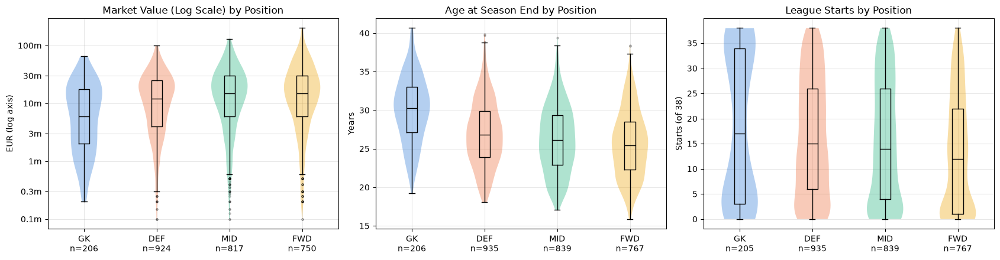

In [102]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
u44 = df44[df44["target_usable"]]
ticks = [0.1, 0.3, 1, 3, 10, 30, 100]
for ax, (col, title, log) in zip(axes, [("target_market_value", "Market Value (Log Scale)", True),
                                         ("age_at_season_end_years", "Age at Season End", False),
                                         ("m_starts", "League Starts", False)]):
    src = u44 if col == "target_market_value" else df44
    data = [src.loc[src[uni.POSITION] == p, col].dropna() for p in prof.POSITION_ORDER]
    data = [np.log10(d) for d in data] if log else data
    parts = ax.violinplot(data, showextrema=False)
    for body, p in zip(parts["bodies"], prof.POSITION_ORDER):
        body.set_facecolor(POS_COLORS[p])
        body.set_alpha(0.35)
    ax.boxplot(data, widths=0.15, flierprops={"marker": "o", "markersize": 2, "alpha": 0.3}, medianprops={"color": "black"})
    ax.set_xticks(range(1, 5), [f"{p}\nn={len(d)}" for p, d in zip(prof.POSITION_ORDER, data)])
    ax.set_title(f"{title} by Position")
    if log:
        ax.set_yticks(np.log10(np.array(ticks) * 1e6), [f"{t:g}m" for t in ticks])
axes[0].set_ylabel("EUR (log axis)")
axes[1].set_ylabel("Years")
axes[2].set_ylabel("Starts (of 38)")
plt.tight_layout()
plt.show()

In [103]:
# Position-relevant metrics. Outfield metrics on outfield rows; goalkeeper metrics on goalkeeper rows only (by role).
out44 = mvt.metric_profile(df44, uni.POSITION, mvt.OUTFIELD_METRICS, df44[uni.POSITION].isin(biv.OUTFIELD), biv.OUTFIELD)
print("Outfield metrics: median (missing % of rows)")
display(out44.pivot(index="metric", columns=uni.POSITION, values="median").round(2)
        .astype(str) + " (" + out44.pivot(index="metric", columns=uni.POSITION, values="missing_pct").round(1).astype(str) + "%)")
gk44 = mvt.metric_profile(df44, "starts_group", mvt.GK_METRICS, df44[uni.POSITION].eq("GK"), mvt.STARTS_LABELS)
print("Goalkeeper metrics by playing-time role: median (n with a value)")
display(gk44.pivot(index="metric", columns="starts_group", values="median").round(2)
        .astype(str) + " (n=" + gk44.pivot(index="metric", columns="starts_group", values="n").astype(int).astype(str) + ")")

Outfield metrics: median (missing % of rows)


position_group_season,DEF,MID,FWD
metric,,,
m_accurate_passes_per90,38.58 (8.2%),36.19 (12.2%),19.86 (18.1%)
m_aerials_won_percent,57.1 (10.1%),44.8 (16.0%),35.4 (21.3%)
m_assists,0.0 (0.0%),1.0 (0.0%),1.0 (0.0%)
m_duels_won_percent,56.25 (8.4%),49.05 (12.0%),42.1 (18.1%)
m_expected_assists,0.52 (1.0%),0.95 (1.7%),1.07 (1.7%)
m_expected_goals,0.75 (13.9%),1.12 (10.4%),3.28 (10.2%)
m_goals,0.0 (0.0%),1.0 (0.0%),2.0 (0.0%)
m_interceptions_per90,1.14 (9.7%),0.93 (15.4%),0.39 (25.8%)
m_passing_accuracy,82.8 (8.2%),83.5 (12.0%),76.85 (18.1%)


Goalkeeper metrics by playing-time role: median (n with a value)


starts_group,0 starts,1-9 starts,10-18 starts,19-28 starts,29-38 starts,starts missing
metric,,,,,,
m_clean_sheets,NaN,0.0 (n=75),2.5 (n=26),6.0 (n=24),10.0 (n=73),NaN
m_goals_conceded,NaN,5.0 (n=75),23.5 (n=26),35.0 (n=24),48.0 (n=73),NaN
m_goals_conceded_per90,NaN,2.0 (n=75),1.61 (n=26),1.41 (n=24),1.33 (n=73),NaN
m_goals_prevented,NaN,-0.43 (n=75),-2.22 (n=26),-3.92 (n=17),-1.04 (n=62),NaN
m_penalty_saves,NaN,0.0 (n=26),0.0 (n=20),0.0 (n=23),0.0 (n=72),NaN
m_rating,6.35 (n=5),6.38 (n=75),6.57 (n=26),6.6 (n=24),6.69 (n=69),NaN
m_save_percentage,NaN,60.55 (n=74),65.3 (n=26),67.05 (n=24),69.8 (n=73),NaN
m_saves,NaN,9.0 (n=75),43.0 (n=26),78.0 (n=24),106.0 (n=73),NaN


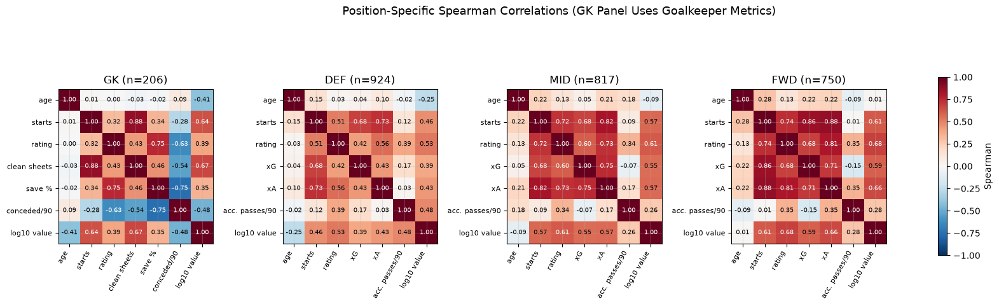

In [104]:
# Position-specific Spearman among selected variables and the log10 target (usable targets)
fig, axes = plt.subplots(1, 4, figsize=(21, 5.2), gridspec_kw={"wspace": 0.45})
for ax, pos in zip(axes, prof.POSITION_ORDER):
    variables = mvt.PAIR_VARS if pos != "GK" else ["age_at_season_end_years", "m_starts", "m_rating", "m_clean_sheets",
                                                   "m_save_percentage", "m_goals_conceded_per90"]
    corr, n = mvt.position_correlation(df44, pos, variables)
    im = ax.imshow(corr.to_numpy(float), cmap="RdBu_r", vmin=-1, vmax=1)
    short_names = {"age_at_season_end_years": "age", "m_starts": "starts", "m_rating": "rating", "m_expected_goals": "xG",
                   "m_expected_assists": "xA", "m_accurate_passes_per90": "acc. passes/90", "m_clean_sheets": "clean sheets",
                   "m_save_percentage": "save %", "m_goals_conceded_per90": "conceded/90", "log10_target": "log10 value"}
    labels = [short_names[c] for c in corr.columns]
    ax.set_xticks(range(len(labels)), labels, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(labels)), labels, fontsize=8)
    for i in range(len(labels)):
        for j in range(len(labels)):
            v = corr.iat[i, j]
            if pd.notna(v):
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 0.6 else "black")
    ax.set_title(f"{pos} (n={int(n.iat[-1, -1])})")
fig.suptitle("Position-Specific Spearman Correlations (GK Panel Uses Goalkeeper Metrics)", fontsize=13)
fig.colorbar(im, ax=axes, shrink=0.7, label="Spearman")
plt.show()

**Interpretation: positions are distinct sub-populations** (RD-03 applies to all target statements)

- **Goalkeepers** (206 rows, 95 players) are the most distinct group: lowest values (median EUR 6m), oldest (median 30.2 years), minutes missing on 96.6% of rows, and a median of 34 null metrics because outfield metrics are not recorded for them (`MISSING` on 63% of their metric cells, a different pattern from outfield `UNVERIFIED_POSITION`; analysed in 4.5). Their value rises steeply with role: EUR 2m for back-ups with 1-9 starts, EUR 16m for first-choice goalkeepers with 29-38 starts. Among goalkeeper metrics, clean sheets (0.67) and goals conceded per 90 (-0.48) are the strongest associations; age is clearly negative (-0.41).
- **Defenders, midfielders and forwards** share similar ages (median 25.5-26.8) and missingness (median 11-12 null metrics), but differ in level and in which metrics matter. Medians are EUR 12m / 15m / 15m; forwards have the longest tail (p90 EUR 55m).
- **Metric meaning differs by position.** Median xG is 0.75 for defenders and 3.28 for forwards; interceptions per 90 are 1.14 vs 0.39. The same value of a metric therefore describes a different role in each position, which is why pooled correlations (4.3) mix positions.
- **Within-position correlations:** for forwards, starts, rating, xG and xA correlate 0.68-0.88 with each other and 0.59-0.68 with the log target; for defenders, accurate passes per 90 (0.48) and rating (0.53) are as strongly associated as starts (0.46), while attacking metrics matter less (xG 0.39). Age is negative for defenders (-0.25) and goalkeepers (-0.41) but flat for forwards (0.01).
- Forwards have more missing rate metrics (18% of rows vs 8% for defenders), because more forwards play very few minutes (P4-B07).

### C. Player Population Groups and Interactions

This section crosses position with the playing-time role and age, and checks whether feature-target associations survive inside groups.

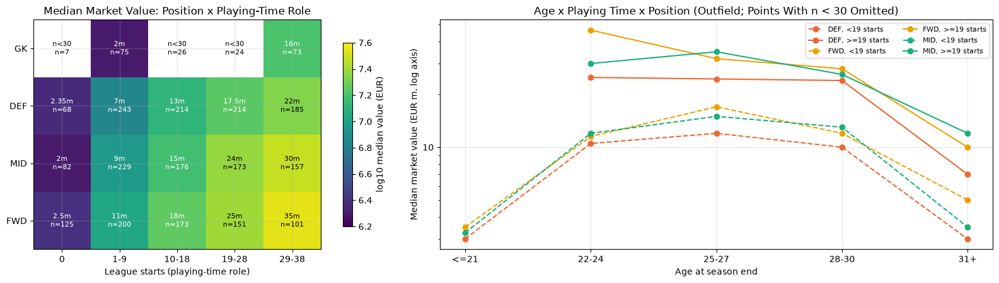

,rows,usable_targets,target_median_eur,age_median,minutes_median,null_metrics_median,p4b01_share_pct
starts_group,,,,,,,
0 starts,324,282,2350000.0,21.23,14.0,46.0,36.73
1-9 starts,755,747,8000000.0,26.30,417.5,14.0,22.65
10-18 starts,589,589,15000000.0,26.85,1254.0,11.0,15.96
19-28 starts,562,562,20000000.0,26.88,2059.0,10.0,12.99
29-38 starts,516,516,25000000.0,27.38,2885.0,10.0,14.53


In [105]:
grid44, n_grid44 = mvt.median_grid(df44, uni.POSITION, "starts_group", prof.POSITION_ORDER, mvt.STARTS_LABELS)
fig, axes = plt.subplots(1, 2, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})
im = axes[0].imshow(np.log10(grid44.to_numpy(float)), cmap="viridis", vmin=6.2, vmax=7.6)
for i in range(grid44.shape[0]):
    for j in range(grid44.shape[1]):
        v, n = grid44.iat[i, j], n_grid44.iat[i, j]
        axes[0].text(j, i, (f"{v / 1e6:g}m" if pd.notna(v) else "n<30") + f"\nn={n}", ha="center", va="center", fontsize=8,
                     color="white" if pd.notna(v) and v < 2e7 else "black")
axes[0].set_xticks(range(5), [l.replace(" starts", "") for l in mvt.STARTS_LABELS])
axes[0].set_yticks(range(4), prof.POSITION_ORDER)
axes[0].set_xlabel("League starts (playing-time role)")
axes[0].set_title("Median Market Value: Position x Playing-Time Role")
fig.colorbar(im, ax=axes[0], shrink=0.8, label="log10 median value (EUR)")

d44 = df44.join(groups44)
d44 = d44[d44["target_usable"] & d44[uni.POSITION].isin(biv.OUTFIELD)]
d44["role"] = np.where(d44["m_starts"] >= 19, ">=19 starts", "<19 starts")
for (pos, role), sub in d44.groupby([uni.POSITION, "role"]):
    s = sub.groupby("age_band", observed=True)[uni.TARGET].agg(["median", "size"]).reindex(biv.AGE_LABELS)
    s = s["median"].where(s["size"] >= mvt.MIN_N) / 1e6
    axes[1].plot(biv.AGE_LABELS, s, marker="o", color=POS_COLORS[pos], linestyle="-" if role == ">=19 starts" else "--",
                 label=f"{pos}, {role}")
axes[1].set_yscale("log")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
axes[1].yaxis.set_minor_formatter(plt.NullFormatter())
axes[1].set_xlabel("Age at season end")
axes[1].set_ylabel("Median market value (EUR m, log axis)")
axes[1].set_title("Age x Playing Time x Position (Outfield; Points With n < 30 Omitted)")
axes[1].legend(fontsize=8, ncols=2)
plt.tight_layout()
plt.show()
display(mvt.profile(df44, ["starts_group"]).reindex(mvt.STARTS_LABELS)[
    ["rows", "usable_targets", "target_median_eur", "age_median", "minutes_median", "null_metrics_median", "p4b01_share_pct"]].round(2))

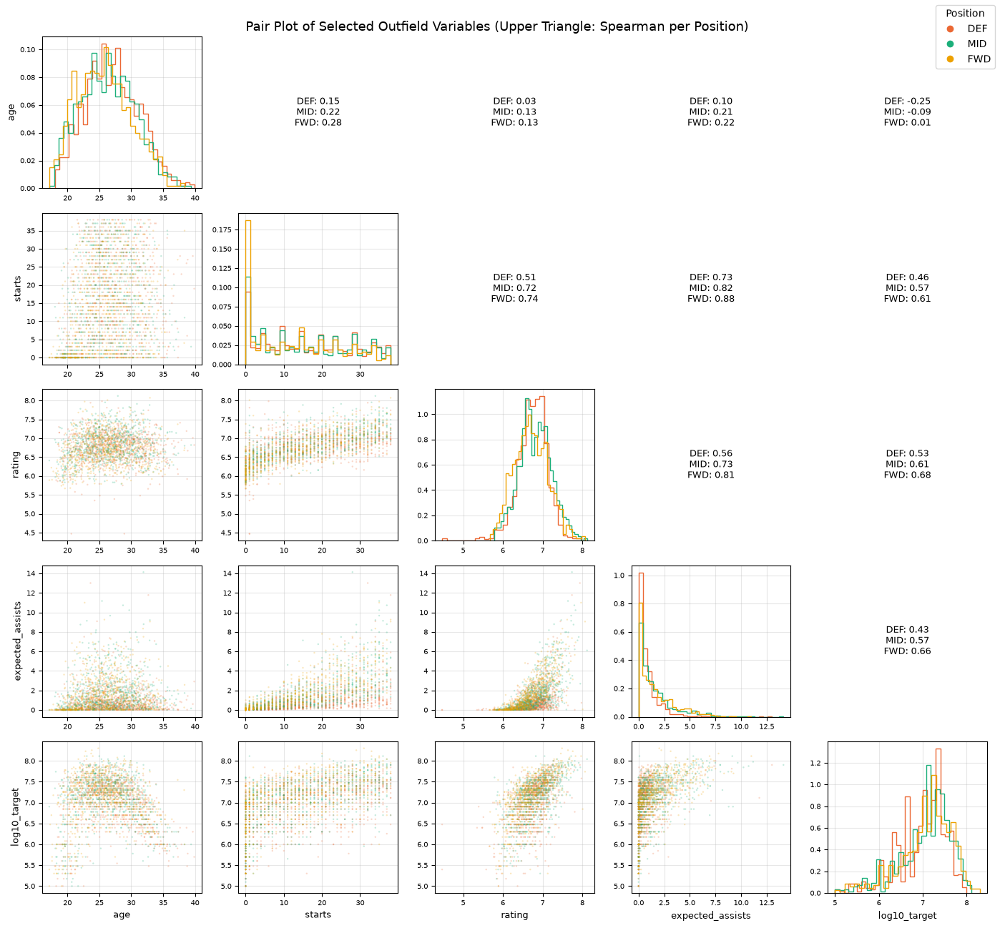

In [106]:
# Pair plot for selected outfield variables (usable targets), coloured by position; log10 target computed on the fly
pv = ["age_at_season_end_years", "m_starts", "m_rating", "m_expected_assists", "log10_target"]
pp = df44.loc[df44["target_usable"] & df44[uni.POSITION].isin(biv.OUTFIELD), pv[:-1] + [uni.POSITION]].copy()
pp["log10_target"] = np.log10(df44.loc[pp.index, uni.TARGET].astype(float))
fig, axes = plt.subplots(len(pv), len(pv), figsize=(14, 13))
for i, yv in enumerate(pv):
    for j, xv in enumerate(pv):
        ax = axes[i, j]
        if i == j:
            for pos in biv.OUTFIELD:
                ax.hist(pp.loc[pp[uni.POSITION] == pos, xv].dropna(), bins=30, histtype="step", color=POS_COLORS[pos], density=True)
        elif i > j:
            for pos in biv.OUTFIELD:
                s = pp[pp[uni.POSITION] == pos]
                ax.scatter(s[xv], s[yv], s=3, alpha=0.25, color=POS_COLORS[pos], edgecolors="none")
        else:
            ax.axis("off")
            r = {pos: pp.loc[pp[uni.POSITION] == pos, [xv, yv]].dropna().corr(method="spearman").iat[0, 1] for pos in biv.OUTFIELD}
            ax.text(0.5, 0.5, "\n".join(f"{k}: {v:.2f}" for k, v in r.items()), ha="center", va="center", fontsize=9, transform=ax.transAxes)
        if i == len(pv) - 1:
            ax.set_xlabel(xv.removeprefix("m_").replace("age_at_season_end_years", "age"), fontsize=9)
        if j == 0:
            ax.set_ylabel(yv.removeprefix("m_").replace("age_at_season_end_years", "age"), fontsize=9)
        ax.tick_params(labelsize=7)
handles = [plt.Line2D([], [], marker="o", linestyle="", color=POS_COLORS[p], label=p) for p in biv.OUTFIELD]
fig.legend(handles=handles, loc="upper right", title="Position")
fig.suptitle("Pair Plot of Selected Outfield Variables (Upper Triangle: Spearman per Position)", fontsize=13)
plt.tight_layout()
plt.show()

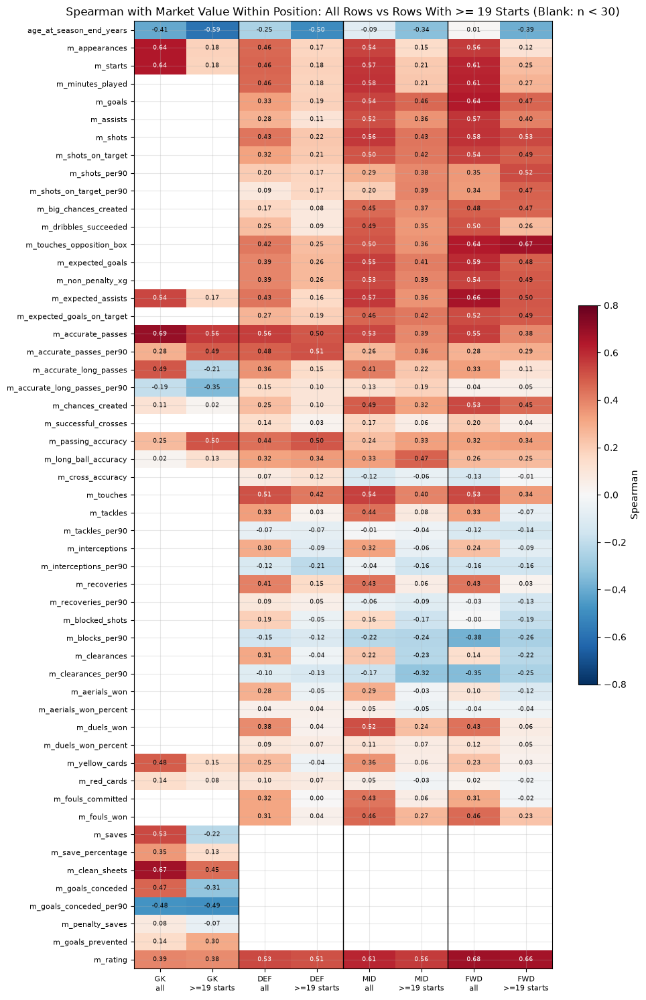

Smallest n among reported cells: 53


In [107]:
# Feature-target Spearman inside each position, for all rows and for rows with at least 19 starts
within44, within_n44 = mvt.within_group_spearman(df44, register44, uni.FEATURES)
fig, ax = plt.subplots(figsize=(10, 15))
im = ax.imshow(within44.to_numpy(float), cmap="RdBu_r", vmin=-0.8, vmax=0.8, aspect="auto")
ax.set_xticks(range(within44.shape[1]), [c.replace(" ", "\n", 1) for c in within44.columns], fontsize=8)
ax.set_yticks(range(within44.shape[0]), within44.index, fontsize=8)
for i in range(within44.shape[0]):
    for j in range(within44.shape[1]):
        v = within44.iat[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5, color="white" if abs(v) > 0.5 else "black")
for x in (1.5, 3.5, 5.5):
    ax.axvline(x, color="black", linewidth=1)
ax.set_title("Spearman with Market Value Within Position: All Rows vs Rows With >= 19 Starts (Blank: n < 30)")
fig.colorbar(im, ax=ax, shrink=0.4, label="Spearman")
plt.tight_layout()
plt.show()
print("Smallest n among reported cells:", int(within_n44[within44.notna()].min().min()))

**Interpretation: playing time and age interact, and associations change inside groups** (RD-03 applies)

- **Playing-time role is the strongest single grouping.** Median value rises in every position from the 0-start group (EUR 2-2.5m) to the 29-38-start group (EUR 22m defenders, 30m midfielders, 35m forwards, 16m goalkeepers). The rise is steepest for forwards. Fringe groups also carry most nulls (0-start rows: median 46 null metrics, 73% of metric cells `MISSING`) and the highest share of P4-B01 identity rows (37%).
- **Age x playing time.** Among outfield players with at least 19 starts, medians are highest at 22-27 years (EUR 25-45m depending on position) and decline after 30. Among players with fewer starts, young players are cheap (EUR 3.25m at <=21). Young regulars are the most highly valued group. The <=21 regular group has only 29 rows and is therefore not drawn. Age thus has opposite meanings depending on playing time, which explains its weak pooled correlation (-0.17).
- **Usage pattern adds little beyond starts:** "starter" forwards (>=90% started) have a median of EUR 35m, but this group is mostly the same as the 29-38-start group.
- **Associations within regular players (>=19 starts):**
  - Playing-time measures lose most of their association (starts 0.46-0.61 → 0.18-0.25): among regulars, how much one plays says little about value.
  - Defensive volumes (tackles, interceptions, clearances, aerials) fall to around zero or below. Their pooled association was mostly playing time (P4-B08).
  - Attacking output keeps a moderate association for midfielders and forwards (goals 0.46-0.47, xG 0.41-0.48, touches in the box 0.67 for forward regulars, RD-04 pending), and **shot rates become stronger** (shots per 90: forwards 0.35 → 0.52).
  - Rating stays stable (0.51-0.66 for outfield regulars). For defenders, passing measures stay associated (accurate passes per 90 0.51, passing accuracy 0.50).
  - **Age becomes clearly negative for every position** (-0.34 to -0.59): among regulars, younger players are valued higher.
- **Goalkeepers:** among first-choice goalkeepers (>=19 starts, n = 97), clean sheets stay associated (0.45) while saves turn negative (-0.22), consistent with the team-strength reading in 4.3 (unverified, RS5-12).
- **Pair plot:** within each outfield position, starts, rating and xA rise together and each relates to the log target in a roughly monotonic cloud; the per-position Spearman values (upper triangle) are similar for midfielders and forwards and lower for defenders.

### D. Season-Based Analysis

Seasons are compared on population, composition, target level and timing, playing-time patterns, metric coverage and metric distributions. Season is a grouping key, not a predictor (P4-A05).

In [108]:
pop44 = mvt.season_population(df44, scope44)
display(pop44.rename(index=prof.short).round(2))
timing44 = mvt.season_timing(df44, scope44)
display(timing44.rename(index=prof.short).round(2))

,rows,players,returning_from_previous_season,returning_pct,usable_targets,missing_targets,starts_median,minutes_median,minutes_missing,null_metrics_median,multi_club_rows,p4b01_rows,share_GK_pct,share_DEF_pct,share_MID_pct,share_FWD_pct,share_none_pct,share_occasional_pct,share_rotation_pct,share_regular_pct,share_core_pct
season,,,,,,,,,,,,,,,,,,,,,
2020/21,524,524,NaN,NaN,515,9,15.0,1355.0,39,12.0,11,110,7.82,35.50,29.01,27.67,9.92,26.15,22.52,20.99,20.42
2021/22,537,537,349.0,64.99,528,9,15.0,1349.0,41,12.0,12,116,7.82,33.89,28.86,29.42,9.68,27.19,22.35,22.16,18.62
2022/23,554,554,337.0,60.83,542,12,13.0,1212.0,39,12.0,21,94,7.04,33.03,32.13,27.80,12.27,27.98,21.12,20.04,18.59
2023/24,570,570,350.0,61.40,567,3,13.5,1161.0,38,12.0,12,102,7.02,33.51,31.58,27.89,14.39,25.96,23.51,18.95,17.19
2024/25,562,562,352.0,62.63,545,17,13.0,1149.0,42,10.0,17,111,7.83,34.34,30.96,26.87,12.46,30.07,17.79,20.28,19.22


,usable_targets,median_age_days,p90_age_days,max_age_days,share_over_90_days_pct,median_valuation_date,modal_valuation_date,modal_date_share_pct,bucket_0-30_pct,bucket_31-60_pct,bucket_61-90_pct,bucket_91-180_pct,bucket_>180_pct
season,,,,,,,,,,,,,
2020/21,515,66.0,66.0,731.0,2.91,2021-03-18,2021-03-18,92.62,0.97,0.78,95.34,1.55,1.36
2021/22,528,150.0,150.0,586.0,78.03,2021-12-23,2021-12-23,72.73,3.22,17.99,0.76,75.38,2.65
2022/23,542,206.0,206.0,347.0,66.97,2022-11-03,2022-11-03,60.52,0.37,0.74,31.92,1.48,65.50
2023/24,567,152.0,152.0,166.0,72.66,2023-12-19,2023-12-19,68.78,0.18,0.88,26.28,72.66,0.00
2024/25,545,160.0,160.0,724.0,59.63,2024-12-16,2024-12-16,53.39,0.37,0.92,39.08,57.61,2.02


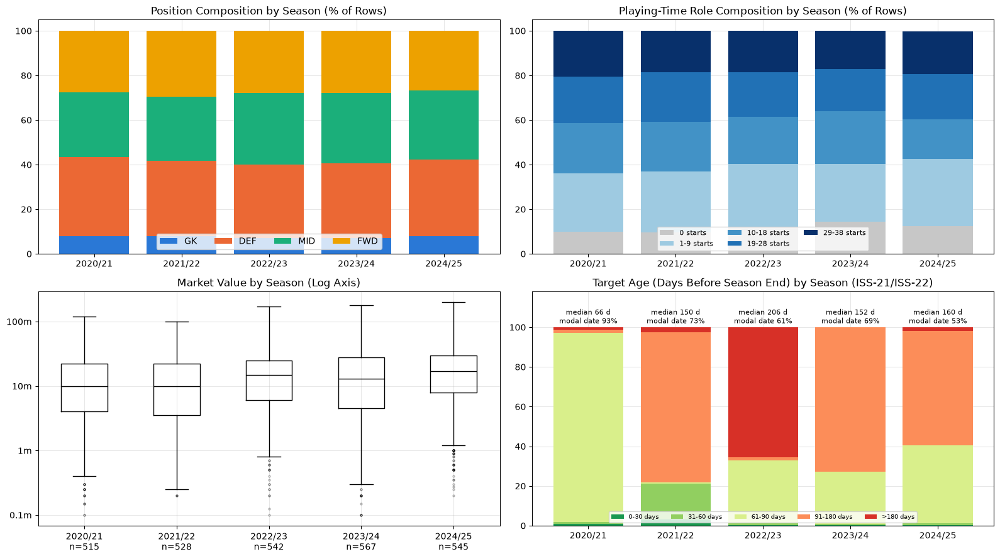

In [109]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
x = np.arange(len(SEASONS44))
bottom = np.zeros(len(SEASONS44))
for p in prof.POSITION_ORDER:
    v = pop44[f"share_{p}_pct"].to_numpy()
    axes[0, 0].bar(x, v, bottom=bottom, color=POS_COLORS[p], label=p)
    bottom += v
axes[0, 0].set_title("Position Composition by Season (% of Rows)")
axes[0, 0].legend(ncols=4, loc="lower center")
bottom = np.zeros(len(SEASONS44))
for lab in mvt.STARTS_LABELS:
    v = pop44[f"share_{mvt.STARTS_SHORT[lab]}_pct"].to_numpy()
    axes[0, 1].bar(x, v, bottom=bottom, color=STARTS_COLORS[lab], label=lab)
    bottom += v
axes[0, 1].set_title("Playing-Time Role Composition by Season (% of Rows)")
axes[0, 1].legend(ncols=3, loc="lower center", fontsize=8)
data = [np.log10(df44.loc[df44["target_usable"] & (df44["season"] == s), uni.TARGET]) for s in SEASONS44]
axes[1, 0].boxplot(data, widths=0.5, flierprops={"marker": "o", "markersize": 2, "alpha": 0.3}, medianprops={"color": "black"})
axes[1, 0].set_yticks(np.log10(np.array([0.1, 1, 10, 100]) * 1e6), ["0.1m", "1m", "10m", "100m"])
axes[1, 0].set_xticks(range(1, 6), [f"{prof.short(s)}\nn={len(d)}" for s, d in zip(SEASONS44, data)])
axes[1, 0].set_title("Market Value by Season (Log Axis)")
bucket_cols = [c for c in timing44.columns if c.startswith("bucket_")]
bottom = np.zeros(len(SEASONS44))
bucket_colors = ["#1a9850", "#91cf60", "#d9ef8b", "#fc8d59", "#d73027"]
for c, col in zip(bucket_cols, bucket_colors):
    v = timing44[c].fillna(0).to_numpy()
    axes[1, 1].bar(x, v, bottom=bottom, color=col, label=c.removeprefix("bucket_").removesuffix("_pct") + " days")
    bottom += v
for i, (age, share) in enumerate(zip(timing44["median_age_days"], timing44["modal_date_share_pct"])):
    axes[1, 1].text(i, 102, f"median {age:.0f} d\nmodal date {share:.0f}%", ha="center", fontsize=8)
axes[1, 1].set_ylim(0, 118)
axes[1, 1].set_title("Target Age (Days Before Season End) by Season (ISS-21/ISS-22)")
axes[1, 1].legend(ncols=5, loc="lower center", fontsize=7)
for ax in (axes[0, 0], axes[0, 1], axes[1, 1]):
    ax.set_xticks(x, [prof.short(s) for s in SEASONS44])
plt.tight_layout()
plt.show()

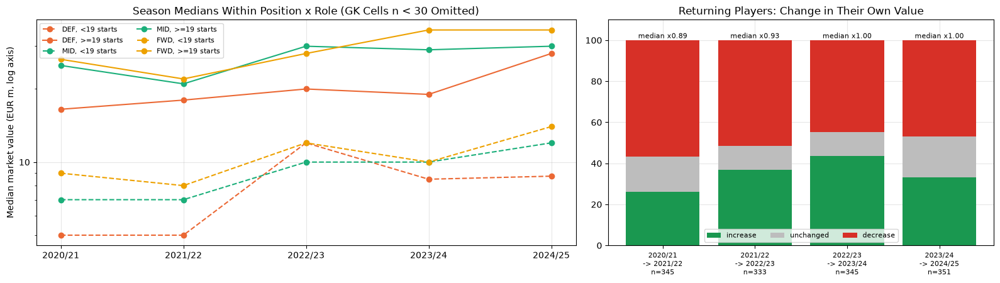

,position,starts_group,min_n,median_2020/21,n_2020/21,median_2021/22,n_2021/22,median_2022/23,n_2022/23,median_2023/24,n_2023/24,median_2024/25,n_2024/25,last_to_first_ratio
0,GK,<19 starts,20,NaN,21,NaN,22,NaN,20,NaN,21,NaN,25,NaN
1,GK,>=19 starts,19,NaN,20,NaN,20,NaN,19,NaN,19,NaN,19,NaN
2,DEF,<19 starts,97,5000000.0,100,5000000.0,97,12000000.0,97,8500000.0,119,8750000.0,112,1.75
3,DEF,>=19 starts,72,16500000.0,84,18000000.0,83,20000000.0,83,19000000.0,72,28000000.0,77,1.70
4,MID,<19 starts,84,7000000.0,84,7000000.0,87,10000000.0,110,10000000.0,113,12000000.0,93,1.71
5,MID,>=19 starts,62,25000000.0,65,21000000.0,64,30000000.0,62,29000000.0,66,30000000.0,73,1.20
6,FWD,<19 starts,93,9000000.0,93,8000000.0,103,12000000.0,101,10000000.0,108,14000000.0,93,1.56
7,FWD,>=19 starts,48,26500000.0,48,22000000.0,52,28000000.0,50,35000000.0,49,35000000.0,53,1.32


In [110]:
strat44 = mvt.season_stratified_medians(df44, scope44, coarse=True)
ret44 = mvt.returning_player_change(df44, scope44)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.4, 1]})
for _, r in strat44.iterrows():
    vals = [r[f"median_{prof.short(s)}"] / 1e6 for s in SEASONS44]
    if all(pd.isna(vals)):
        continue
    axes[0].plot([prof.short(s) for s in SEASONS44], vals, marker="o", color=POS_COLORS[r["position"]],
                 linestyle="-" if r["starts_group"] == ">=19 starts" else "--", label=f"{r['position']}, {r['starts_group']}")
axes[0].set_yscale("log")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
axes[0].yaxis.set_minor_formatter(plt.NullFormatter())
axes[0].set_ylabel("Median market value (EUR m, log axis)")
axes[0].set_title("Season Medians Within Position x Role (GK Cells n < 30 Omitted)")
axes[0].legend(fontsize=8, ncols=2)
axes[1].bar(range(len(ret44)), ret44["share_increase_pct"], color="#1a9850", label="increase")
axes[1].bar(range(len(ret44)), ret44["share_unchanged_pct"], bottom=ret44["share_increase_pct"], color="#bdbdbd", label="unchanged")
axes[1].bar(range(len(ret44)), ret44["share_decrease_pct"], bottom=ret44["share_increase_pct"] + ret44["share_unchanged_pct"],
            color="#d73027", label="decrease")
axes[1].set_xticks(range(len(ret44)), [f"{prof.short(a)}\n-> {prof.short(b)}\nn={n}" for a, b, n in zip(ret44["from"], ret44["to"], ret44["players"])], fontsize=8)
for i, m in enumerate(ret44["median_ratio"]):
    axes[1].text(i, 101, f"median x{m:.2f}", ha="center", fontsize=8)
axes[1].set_ylim(0, 110)
axes[1].set_title("Returning Players: Change in Their Own Value")
axes[1].legend(loc="lower center", ncols=3, fontsize=8)
plt.tight_layout()
plt.show()
display(strat44.round(2))

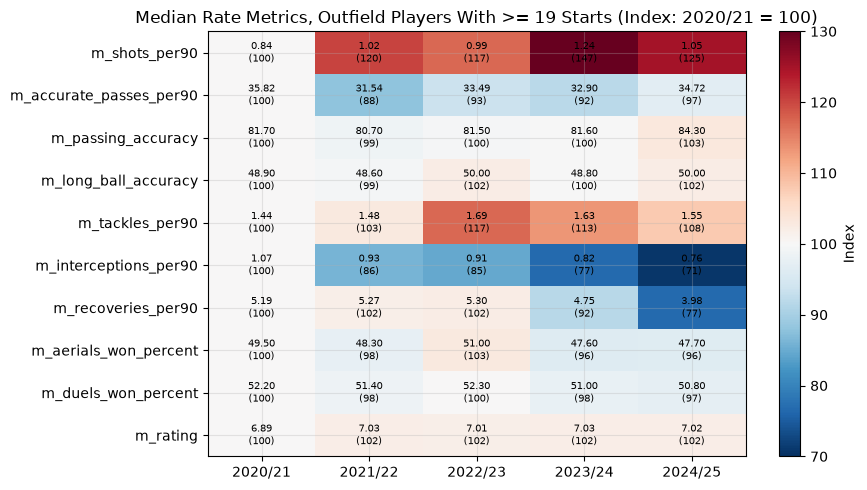

Coverage of these metrics among the same rows (% with a value):


season,2020/21,2021/22,2022/23,2023/24,2024/25
m_shots_per90,100.0,100.0,100.0,100.0,100.0
m_accurate_passes_per90,100.0,100.0,100.0,100.0,100.0
m_passing_accuracy,100.0,100.0,100.0,100.0,100.0
m_long_ball_accuracy,100.0,99.5,100.0,100.0,100.0
m_tackles_per90,100.0,100.0,100.0,100.0,100.0
m_interceptions_per90,100.0,100.0,100.0,100.0,100.0
m_recoveries_per90,100.0,100.0,100.0,100.0,100.0
m_aerials_won_percent,100.0,100.0,100.0,100.0,100.0
m_duels_won_percent,100.0,100.0,100.0,100.0,100.0
m_rating,100.0,100.0,100.0,100.0,94.6


Season coverage of all features (applicable rows) is in Phase 4.2, figure 'Share of applicable rows with a value by season'.


In [111]:
# Rate metrics for outfield players with >= 19 starts (stable denominators): median by season, as an index (2020/21 = 100)
med44, cov44 = mvt.season_metric_medians(df44, scope44)
index44 = med44.div(med44.iloc[:, 0], axis=0) * 100
fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(index44.to_numpy(float), cmap="RdBu_r", vmin=70, vmax=130, aspect="auto")
for i in range(index44.shape[0]):
    for j in range(index44.shape[1]):
        ax.text(j, i, f"{med44.iat[i, j]:.2f}\n({index44.iat[i, j]:.0f})", ha="center", va="center", fontsize=7.5)
ax.set_xticks(range(len(SEASONS44)), [prof.short(s) for s in SEASONS44])
ax.set_yticks(range(len(index44)), index44.index)
ax.set_title("Median Rate Metrics, Outfield Players With >= 19 Starts (Index: 2020/21 = 100)")
fig.colorbar(im, ax=ax, label="Index")
plt.tight_layout()
plt.show()
print("Coverage of these metrics among the same rows (% with a value):")
display(cov44.rename(columns=prof.short).round(1))
print("Season coverage of all features (applicable rows) is in Phase 4.2, figure 'Share of applicable rows with a value by season'.")

**Interpretation: seasonal change is level, timing and some metric drift, not composition** (RD-03, ISS-21, ISS-22)

- **Population is stable:** 524-570 rows per season; 61-65% of each season's players also played the previous season; position shares vary by at most 3 points; playing-time role shares are stable (the 0-start share is 9.7-14.4%). Missing targets are 3-17 per season (17 in 2024/25).
- **Target timing differs strongly by season** (ISS-21/ISS-22). In 2020/21 93% of targets share one valuation date 66 days before season end; in 2022/23 the main batch is 206 days before season end and 66% of targets are older than 180 days. Any staleness filter would therefore change the season mix (ISS-22); none is applied.
- **The season level shift is not explained by composition.** Within the same position and role (two roles, all cells >= 48 rows for outfield positions), medians still rise by a factor of 1.2-1.75 from 2020/21 to 2024/25 (for example defenders with >= 19 starts: EUR 16.5m to 28m).
- **But returning players' own values do not rise on average:** the median ratio for the same player between consecutive seasons is 0.89, 0.93, 1.00 and 1.00, with more decreases than increases. Rising medians at constant composition and flat individual values together suggest that the level shift comes from **who enters** the league (new, younger, more expensive players replacing older ones), from batch timing, or from market movement. This analysis cannot separate these explanations. It does show that a season-level difference is not evidence of a common market inflation affecting every player.
- **Some metric distributions drift across seasons** among regular outfield players: recoveries per 90 fall from 5.19 to 3.98 (index 77) and interceptions per 90 from 1.07 to 0.76 (index 71), while passing accuracy rises to 84.3% in 2024/25 and shots per 90 peak in 2023/24. Their coverage is 99.5-100% in every season, so the drift is not missingness. It may reflect playing style, or source definition and collection changes (RS5-13). The source cannot be checked here; step 8.5 assesses metric reliability. Rating coverage drops to 94.6% of regular outfield rows in 2024/25.
- Season comparisons of the target must therefore always be read with timing (ISS-21) and data availability (4.2 coverage), never as a performance effect.

### E. Goalkeepers Separately

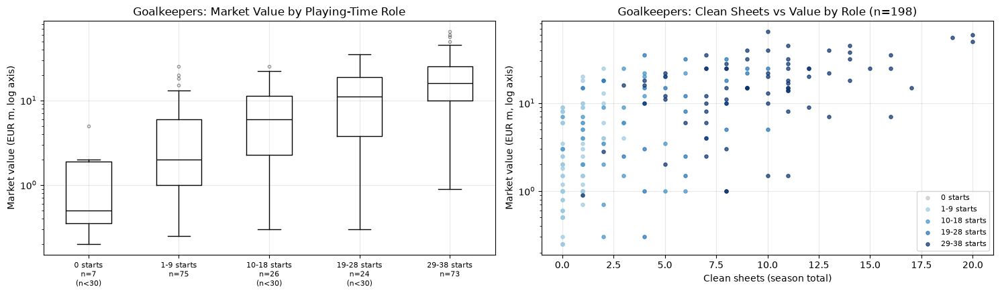

In [112]:
gkd = df44[(df44[uni.POSITION] == "GK") & df44["target_usable"]].join(groups44)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
roles = [r for r in mvt.STARTS_LABELS if (gkd["starts_group"] == r).any()]
data = [gkd.loc[gkd["starts_group"] == r, uni.TARGET] / 1e6 for r in roles]
axes[0].boxplot(data, widths=0.5, medianprops={"color": "black"}, flierprops={"marker": "o", "markersize": 3, "alpha": 0.4})
axes[0].set_xticks(range(1, len(roles) + 1), [f"{r}\nn={len(d)}" + ("\n(n<30)" if len(d) < 30 else "") for r, d in zip(roles, data)], fontsize=8)
axes[0].set_yscale("log")
axes[0].set_ylabel("Market value (EUR m, log axis)")
axes[0].set_title("Goalkeepers: Market Value by Playing-Time Role")
for r in roles:
    s = gkd[gkd["starts_group"] == r]
    axes[1].scatter(s["m_clean_sheets"], s[uni.TARGET] / 1e6, s=14, alpha=0.7, color=STARTS_COLORS[r], label=r)
axes[1].set_yscale("log")
axes[1].set_xlabel("Clean sheets (season total)")
axes[1].set_ylabel("Market value (EUR m, log axis)")
axes[1].set_title(f"Goalkeepers: Clean Sheets vs Value by Role (n={int(gkd['m_clean_sheets'].notna().sum())})")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Interpretation (goalkeeper metrics only; not compared with outfield metrics)**

- Goalkeeper value is mostly a matter of being first choice: back-ups (1-9 starts, n = 75) have a median of EUR 2m, first-choice goalkeepers (29-38 starts, n = 73) EUR 16m. The intermediate roles have fewer than 30 rows each.
- Clean sheets rise with starts by construction (a goalkeeper must play to keep one). Inside the first-choice group, more clean sheets still go with higher values, consistent with team strength (not testable here, RS5-12).
- Goalkeeper metrics are complete for goalkeepers with at least one start, except `penalty_saves` (null on 65% of back-up rows) and `goals_prevented` (null on 15-29% of regular rows; RD-04). Goalkeepers with 0 starts (7 rows) have no goalkeeper metrics. These gaps are analysed in step 8.5 and are not filled.

### F. Identity Sensitivity of Group Results

In [113]:
gid44 = mvt.group_identity_sensitivity(df44)
display(gid44.round(2))
print("Median ratio (without P4-B01 / all) over cells with n >= 30:", round(gid44["ratio"].median(), 3))

,position,starts_group,n_all,n_without_p4b01,p4b01_share_pct,median_all_eur,median_without_p4b01_eur,ratio
0,DEF,0 starts,68,44,35.29,2350000.0,4250000.0,1.81
1,DEF,1-9 starts,243,182,25.10,7000000.0,8000000.0,1.14
2,DEF,10-18 starts,214,184,14.02,13000000.0,13000000.0,1.00
3,DEF,19-28 starts,214,181,15.42,17500000.0,18000000.0,1.03
4,DEF,29-38 starts,185,152,17.84,22000000.0,22000000.0,1.00
5,FWD,0 starts,125,83,33.60,2500000.0,3000000.0,1.20
6,FWD,1-9 starts,200,161,19.50,11000000.0,12000000.0,1.09
7,FWD,10-18 starts,173,144,16.76,18000000.0,17500000.0,0.97
8,FWD,19-28 starts,151,137,9.27,25000000.0,25000000.0,1.00
9,FWD,29-38 starts,101,94,6.93,35000000.0,35000000.0,1.00


Median ratio (without P4-B01 / all) over cells with n >= 30: 1.021


**Interpretation**

- In the regular and core groups (>= 10 starts), group medians change by at most 3% without the P4-B01 rows. The group conclusions do not depend on identity evidence quality.
- In fringe groups the P4-B01 share is high (30-43% of 0-start rows), and these rows are lower-valued. Without them, the 0-start medians would rise from EUR 2.0-2.5m to EUR 3.0-4.25m. Fringe-group levels are therefore the least robust group results. The rows stay in the main analysis (P4-B01), and identities remain without human validation (ISS-01).

### G. Interpretation of Important Patterns

1. **Three population axes dominate:** position, playing-time role and age. The playing-time role is the strongest grouping (median EUR 2.35m with 0 starts vs EUR 25m with 29-38 starts), followed by age, then position.
2. **Interactions matter:** age has opposite meanings for regulars (young regulars are the most valuable) and fringe players (young fringe players are cheap). Pooled age correlations hide this.
3. **Inside regular players, the associations change.** Playing time and defensive volumes lose most of their association. Attacking output, shot rates, passing quality (defenders) and rating keep it, and age becomes clearly negative.
4. **Positions are distinct sub-populations** with different metric meanings. Goalkeepers in particular need separate description; their value depends mainly on being first choice.
5. **Seasons differ in target timing and level, not in composition.** Stratified medians rise 1.2-1.75x, while returning players' own values stay flat or fall. Some rate metrics drift across seasons (recoveries and interceptions per 90).
6. **Fringe groups are the least reliable:** they carry most nulls, the highest P4-B01 share, and the least robust medians.

### H. Limitations

- **RD-03 and ISS-21/ISS-22** apply to every target comparison. Season comparisons cannot separate market movement, batch timing and population turnover.
- **Repeated players (RS5-11):** group tables count rows, not independent players; no intervals are reported for group medians.
- **Group boundaries** are defined by domain reasoning (quarter seasons, three-year age bands) and checked for size, not optimised. Other reasonable boundaries could shift individual medians.
- **Goalkeepers:** 206 rows; most role x season cells are below 30 rows and are not interpreted.
- **Confounders** such as team strength and club context (RS5-12) are not analysed.
- **Metric drift across seasons** is described, not explained.
- **Derived groups** exist only in this analysis. They are not features, and no preprocessing or modeling was performed.

### I. Step 8.4 Conclusion

The player population is heterogeneous along three main axes: **position, playing-time role and age**, and these axes interact. Market value rises steeply with the playing-time role in every position. Age has opposite meanings for regular and fringe players. Inside regular players, attacking output, shot rates, passing quality and rating stay associated with value, while playing-time and defensive volumes do not. Goalkeepers form a separate sub-population whose value depends mainly on being first choice. Seasons differ mainly in target timing and level: the level rise persists inside position and role strata, but individual players' values do not rise on average. Fringe groups are the least reliable part of the data. All results are descriptive associations under RD-03 and ISS-21/ISS-22.

**Gate G4.4:** see `reports/phase_04/step_04/PHASE4_04_ACCEPTANCE_REPORT.md`.

---

## 8.5 Missingness, Temporal & Data Reliability Analysis

Objective:
Establish how trustworthy the available observations are: what is missing and why, how the label relates in time to the features, how much results depend on identity evidence, and which metrics and source fields carry reliability limits. The aim is to show which observations are **reliable, uncertain, unavailable or unsuitable** for specific interpretations, and how these limits may affect later modeling.

Questions:
1. Where are values missing, at feature and population level, and what does each missing value mean?
2. How reliable are goalkeeper observations?
3. How large is the temporal mismatch between label and features (RD-03), by season and by player?
4. How sensitive are results to identity evidence quality (P4-B01, ISS-01)?
5. How reliable are the RD-04 metrics, the club-context columns and the source-reported rates?
6. What is the status of the other known conditions?


Rules applied here: no exclusion, imputation or zero-fill; no staleness filter; no change to D4, D6, mappings or eligibility. `temporal_*` and `target_audit_*` columns are **read for auditing only** and never treated as predictors (P4-A03). RD-03 accompanies every target statement.

### A. Missingness Methodology: What a Missing Value Means

Each of the 53 metric columns `m_*` has a paired status column `s_*`. The status, not the null, tells what the value means. The eight statuses are kept separate throughout this section.

```text
                         Is the metric applicable to the row's position?
                          |                                      |
                         no                                     yes
                          |                                      |
              UNVERIFIED_POSITION                 Does the source support the metric at all?
              (not applicable; null)               |                                    |
                                                  no                                   yes
                                                   |                                    |
                                            UNSUPPORTED                     Did the source return a value?
                                     (no source data; null)                 |                          |
                                                                           no                         yes
                                                                            |                          |
                                                                        MISSING            Do collection passes agree?
                                                                  (unavailable; null)       |               |            |
                                                                                    disagree,        revised        agree
                                                                                    unresolved     (later kept)        |
                                                                                        |               |     value = 0 ? / via leaderboard ?
                                                                                  CONFLICTING   OBSERVED_SOURCE_     |          |           |
                                                                                    (null)        REVISED       OBSERVED_  OBSERVED_   OBSERVED
                                                                                                               ZERO      FALLBACK_
                                                                                                                         LEADERBOARD
```

| Concept | Status | Stored value | May be read as |
|---|---|---|---|
| Genuine observed zero | `OBSERVED_ZERO` | 0 | "nothing happened" (a real zero) |
| Unavailable observation | `MISSING` | null | unknown: the event may or may not have happened |
| Not applicable | `UNVERIFIED_POSITION` | null | the metric does not describe this row's position |
| Unsupported metric | `UNSUPPORTED` | null | the source never provides it (`key_passes`) |
| Conflicting source value | `CONFLICTING` | null | unknown: the sources disagree |
| Revised observation | `OBSERVED_SOURCE_REVISED` | value | observed, but changed after first collection (RS5-13) |
| Fallback observation | `OBSERVED_FALLBACK_LEADERBOARD` | value | observed via the season leaderboard |

The diagram reflects the documented status vocabulary (FotMob coverage report); the decision order is a reading aid, not a reconstruction of the collection code. All numbers come from `src/phase4/reliability.py`, which also writes `reports/phase_04/step_05/evidence/`.

In [114]:
from src.phase4 import reliability as rel

df45, schema45, scope45, verification45 = prof.load_verified()
dictionary45, eligibility45, reliability45 = prof.load_metadata()
register45 = uni.feature_register(eligibility45, reliability45)
SEASONS45 = list(scope45.labels)
print("SHA-256 verified:", verification45["sha256"] == prof.DATASET_SHA256)
print("Seasons (load_scope):", [prof.short(s) for s in SEASONS45])
print("Rows per season (check_parquet):", verification45["scope_check"]["season"])
semantics45 = rel.status_semantics(df45)
display(semantics45.set_index("status").round(2))

SHA-256 verified: True
Seasons (load_scope): ['2020/21', '2021/22', '2022/23', '2023/24', '2024/25']
Rows per season (check_parquet): {'2020/2021': 524, '2021/2022': 537, '2022/2023': 554, '2023/2024': 570, '2024/2025': 562}


,label,meaning,reliability_class,cells,cells_pct,stored_null,stored_zero,stored_non_zero
status,,,,,,,,
OBSERVED,Observed value,Value reported by the source for the season,available,91289,62.70,0,0,91289
OBSERVED_ZERO,Genuine observed zero,The source reports zero events; the stored val...,available,5762,3.96,0,5762,0
OBSERVED_FALLBACK_LEADERBOARD,Observed via fallback,Value taken from the season leaderboard becaus...,available (alternative source path),402,0.28,0,270,132
OBSERVED_SOURCE_REVISED,"Observed, revised by source",Value differs between collection passes; the l...,available (revised),95,0.07,0,0,95
MISSING,Unavailable observation,The source provides no value for this player-s...,unavailable,27361,18.79,27361,0,0
UNVERIFIED_POSITION,Not applicable or unverified by position,Position-specific metric on a row whose positi...,not applicable,17899,12.29,17899,0,0
UNSUPPORTED,Unsupported metric,The source has no data for this metric at all ...,unavailable (no source data),2747,1.89,2747,0,0
CONFLICTING,Conflicting source values,Collection passes disagree and no value could ...,unverified conflict,36,0.02,36,0,0


**Interpretation**

- Of 145,591 metric cells (2,747 rows x 53 metrics), 66.9% hold a value: 62.7% `OBSERVED`, 3.96% genuine zeros, 0.28% via the leaderboard fallback and 0.07% source-revised. 33.0% are null: 18.8% `MISSING`, 12.3% not applicable (`UNVERIFIED_POSITION`), 1.9% `UNSUPPORTED` (`key_passes`) and 36 cells `CONFLICTING`.
- **Status and value agree on every cell:** every `MISSING`, `UNVERIFIED_POSITION`, `UNSUPPORTED` and `CONFLICTING` cell is null, and every `OBSERVED_ZERO` cell is 0. No unavailable value has been stored as zero.
- Only `OBSERVED_ZERO` (and 270 leaderboard zeros) may be read as "no event". A null is never a zero here, even where P4-B07 suggests that many `MISSING` count values would have been zero.

### B. Feature-Level Missingness

In [115]:
fm45 = rel.feature_missingness(df45, reliability45, scope45)
display(rel.family_missingness(fm45).round(2))
cols = ["metric", "family", "applicable_positions", "null", "null_pct", "null_applicable_pct", "null_with_target_pct", "null_without_target_pct"]
display(fm45[cols].sort_values("null_applicable_pct", ascending=False).set_index("metric").round(1))

,metrics,median_null_applicable_pct,max_null_applicable_pct
family,,,
GOALKEEPING,7,3.88,31.55
GENERAL,7,7.24,19.04
PASSING,10,15.22,100.00
EXPECTED,4,20.06,31.31
ATTACK,9,21.19,44.27
DEFENDING,16,21.62,80.67


,family,applicable_positions,null,null_pct,null_applicable_pct,null_with_target_pct,null_without_target_pct
metric,,,,,,,
m_key_passes,PASSING,ALL,2747,100.0,100.0,100.0,100.0
m_clearances,DEFENDING,ALL,2216,80.7,80.7,80.5,92.0
m_clearances_per90,DEFENDING,ALL,2216,80.7,80.7,80.5,92.0
m_big_chances_created,ATTACK,ALL,1216,44.3,44.3,43.3,96.0
m_successful_crosses,PASSING,ALL,1147,41.8,41.8,40.7,96.0
m_cross_accuracy,PASSING,ALL,1147,41.8,41.8,40.7,96.0
m_blocks_per90,DEFENDING,ALL,953,34.7,34.7,33.6,94.0
m_blocked_shots,DEFENDING,ALL,953,34.7,34.7,33.6,94.0
m_penalty_saves,GOALKEEPING,GK_ONLY,2606,94.9,31.6,31.6,NaN


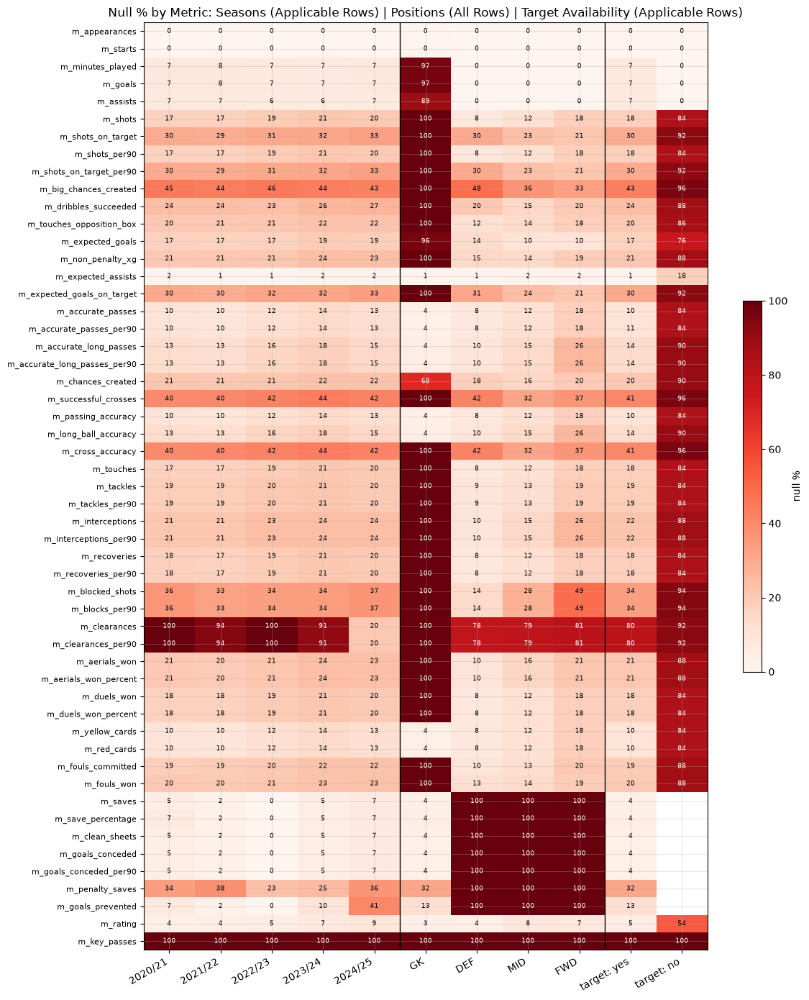

In [116]:
heat = fm45.set_index("metric")[[c for c in fm45.columns if c.startswith("null_") and c.endswith("_pct")
                                  and c not in ("null_pct", "null_applicable_pct")]]
heat = heat[[c for c in heat.columns if "/" in c] + [f"null_{p}_pct" for p in prof.POSITION_ORDER] + ["null_with_target_pct", "null_without_target_pct"]]
labels = [c.removeprefix("null_").removesuffix("_pct").replace("with_target", "target: yes").replace("without_target", "target: no") for c in heat.columns]
fig, ax = plt.subplots(figsize=(12, 14))
im = ax.imshow(heat.to_numpy(float), cmap="Reds", vmin=0, vmax=100, aspect="auto")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.iat[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=6.5, color="white" if v > 60 else "black")
ax.set_xticks(range(len(labels)), labels, rotation=30, ha="right")
ax.set_yticks(range(len(heat)), heat.index, fontsize=8)
for x in (4.5, 8.5):
    ax.axvline(x, color="black", linewidth=1)
ax.set_title("Null % by Metric: Seasons (Applicable Rows) | Positions (All Rows) | Target Availability (Applicable Rows)")
fig.colorbar(im, ax=ax, shrink=0.4, label="null %")
plt.tight_layout()
plt.show()

**Interpretation**

- **By family** (median null share on applicable rows): goalkeeping 3.9%, general 7.2%, passing 15.2%, expected metrics 20.1%, attacking 21.2%, defending 21.6%. The defending family has the widest range (up to 80.7% for `clearances`).
- **Most incomplete applicable metrics:** `key_passes` 100% (unsupported), `clearances` and `clearances_per90` 80.7% (no values in 2020/21 and 2022/23; RD-04), `big_chances_created` 44.3%, the crossing pair 41.8%, `blocked_shots` and `blocks_per90` 34.7%, `penalty_saves` 31.6% (GK).
- **Seasons:** apart from `clearances` and `goals_prevented` (40.9% null in 2024/25, RD-04), each metric's null share varies by only a few points across seasons. Missingness is not season-driven for the other metrics.
- **Positions:** goalkeeper rows are null on nearly every outfield metric. Among outfield positions, forwards have the most nulls (for example interceptions 25.8% vs defenders 9.7%), and defenders the most for attacking counts (shots on target 30.4%, big chances 48.1%). This is consistent with nulls standing in for "no event" for rare actions (P4-B07), but that remains unverified.
- **Target availability:** rows without a target are null on 76-96% of most metrics (exceptions: expected assists 18%, rating 54%), against about 1-45% for rows with a target (except `clearances`). The 50 rows without a target are almost all very-low-playing-time rows (section C).

### C. Population-Level and Status-Aware Missingness

,rows,null_metrics_mean,null_metrics_median,rows_with_all_detailed_stats_null_pct,MISSING_pct,UNVERIFIED_POSITION_pct,CONFLICTING_pct
segment,,,,,,,
target available,2697,17.03,12.0,10.20,17.95,12.28,0.03
target missing,50,42.10,47.0,84.00,64.34,13.21,0.00
goalkeepers,206,34.49,34.0,0.00,61.95,1.03,0.20
outfield,2541,16.11,11.0,12.48,15.29,13.21,0.01
"outfield, 0 starts",317,46.20,46.0,100.00,72.08,13.21,0.00
"outfield, 1-9 starts",680,14.76,14.0,0.00,12.74,13.21,0.00
"outfield, 10-18 starts",563,11.07,11.0,0.00,5.78,13.21,0.01
"outfield, 19-28 starts",538,10.39,10.0,0.00,4.50,13.21,0.01
"outfield, 29-38 starts",443,10.02,10.0,0.00,3.77,13.21,0.03


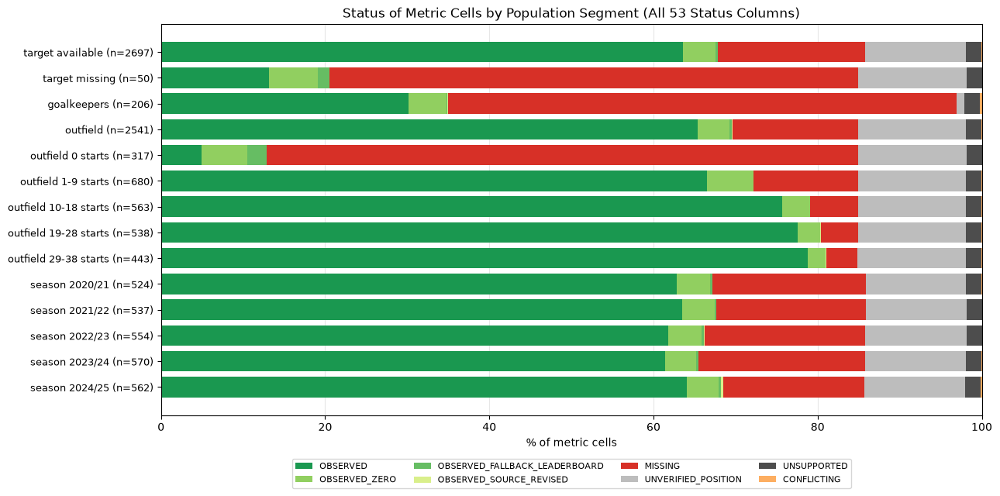

In [117]:
pop45 = rel.population_missingness(df45)
display(pop45.set_index("segment").round(2))
segments = {"target available": df45["target_usable"], "target missing": ~df45["target_usable"],
            "goalkeepers": df45[uni.POSITION].eq("GK"), "outfield": df45[uni.POSITION].ne("GK")}
g45 = mvt.groups(df45)
for lab in mvt.STARTS_LABELS:
    segments[f"outfield {lab}"] = df45[uni.POSITION].ne("GK") & g45["starts_group"].eq(lab)
share_rows = {}
for name, sel in segments.items():
    counts = pd.Series(df45.loc[sel, rel.status_cols(df45)].to_numpy().ravel()).value_counts()
    share_rows[f"{name} (n={int(sel.sum())})"] = counts / counts.sum() * 100
share45 = pd.DataFrame(share_rows).T.reindex(columns=rel.STATUS_ORDER).fillna(0)
for s in SEASONS45:
    sel = df45["season"].eq(s)
    counts = pd.Series(df45.loc[sel, rel.status_cols(df45)].to_numpy().ravel()).value_counts()
    share45.loc[f"season {prof.short(s)} (n={int(sel.sum())})"] = (counts / counts.sum() * 100).reindex(rel.STATUS_ORDER).fillna(0)

fig, ax = plt.subplots(figsize=(13, 6.5))
left = np.zeros(len(share45))
for st in rel.STATUS_ORDER:
    ax.barh(range(len(share45)), share45[st], left=left, color=rel.STATUS_COLORS[st], label=st)
    left += share45[st].to_numpy()
ax.set_yticks(range(len(share45)), share45.index, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("% of metric cells")
ax.set_title("Status of Metric Cells by Population Segment (All 53 Status Columns)")
ax.legend(ncols=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout()
plt.show()

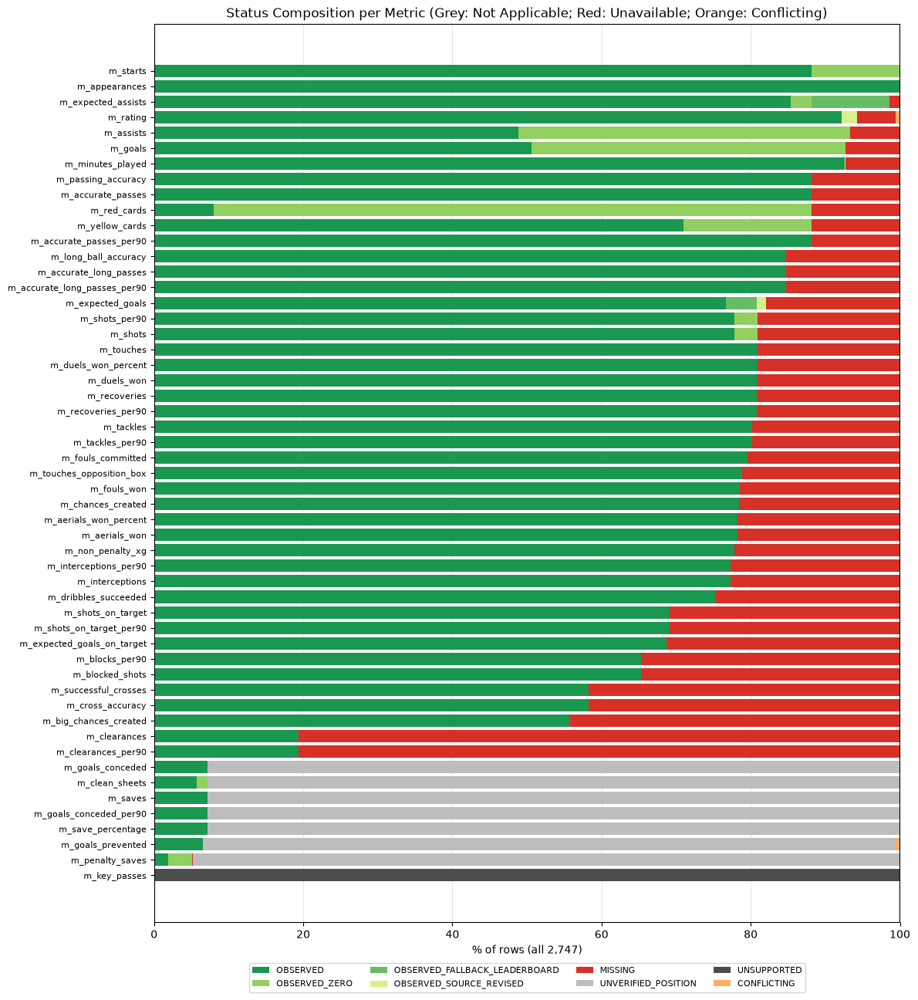

,CONFLICTING,OBSERVED_SOURCE_REVISED,OBSERVED_FALLBACK_LEADERBOARD
m_accurate_passes_per90,1,0,0
m_expected_assists,0,0,287
m_expected_goals,0,34,115
m_goals_prevented,18,0,0
m_minutes_played,0,3,0
m_rating,17,58,0


In [118]:
# Status composition of every metric (all rows); sorted by the share of cells holding a value
sm45 = rel.status_matrix(df45)
shares = sm45.div(sm45.sum(axis=1), axis=0) * 100
order = (shares[["OBSERVED", "OBSERVED_ZERO", "OBSERVED_FALLBACK_LEADERBOARD", "OBSERVED_SOURCE_REVISED"]].sum(axis=1)).sort_values().index
shares = shares.loc[order]
fig, ax = plt.subplots(figsize=(12, 13))
left = np.zeros(len(shares))
for st in rel.STATUS_ORDER:
    ax.barh(range(len(shares)), shares[st], left=left, color=rel.STATUS_COLORS[st], label=st)
    left += shares[st].to_numpy()
ax.set_yticks(range(len(shares)), shares.index, fontsize=8)
ax.set_xlabel("% of rows (all 2,747)")
ax.set_title("Status Composition per Metric (Grey: Not Applicable; Red: Unavailable; Orange: Conflicting)")
ax.legend(ncols=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.04))
plt.tight_layout()
plt.show()
display(sm45.loc[sm45[["CONFLICTING", "OBSERVED_SOURCE_REVISED", "OBSERVED_FALLBACK_LEADERBOARD"]].sum(axis=1) > 0,
                 ["CONFLICTING", "OBSERVED_SOURCE_REVISED", "OBSERVED_FALLBACK_LEADERBOARD"]])

**Interpretation: which observations are reliable, uncertain, unavailable or not applicable**

- **Missingness is driven by playing time, not by season.** Outfield rows with 0 starts have a median of 46 null metrics, 72% of their cells `MISSING` and no detailed statistics at all. From one start upward, the `MISSING` share falls to 12.7%, then 5.8%, 4.5% and 3.8% across the roles. The same holds for minutes: 87.6% of outfield rows under 90 minutes have no detailed statistics. Seasons differ by at most 3 points in the `MISSING` share (17.2-20.3%).
- **Rows without a target** are 64% `MISSING` (vs 18% with a target), and 84% have no detailed statistics. A complete-case analysis would remove fringe players selectively (ISS-27).
- **Goalkeepers** are 62% `MISSING`. This share is not "unknown performance": the outfield metrics are simply not recorded for goalkeepers, but the source codes them `MISSING` rather than `UNVERIFIED_POSITION` (section D). The not-applicable status is used in the other direction only (goalkeeper metrics on outfield rows: 13.2% of outfield cells).
- **Uncertain cells are rare but concentrated:** 36 `CONFLICTING` cells (17 `rating`, 18 `goals_prevented`, 1 `accurate_passes_per90`), mostly in 2024/25 (0.11% of that season's cells vs at most 0.01% elsewhere). 95 source-revised cells (58 `rating`, 34 `expected_goals`, 3 `minutes_played`). 402 leaderboard-fallback cells (`expected_assists` 287, `expected_goals` 115), of which 270 are zeros.
- **Reliable:** observed values and genuine zeros on rows with playing time. **Uncertain:** conflicting cells (null), revised and fallback values (kept, but from a different source path). **Unavailable:** `MISSING`, concentrated in fringe players. **Not applicable:** goalkeeper metrics on outfield rows and, in practice, outfield metrics on goalkeeper rows.

### D. Goalkeeper Reliability

Goalkeepers are analysed separately. Their missingness differs from outfield missingness, and no goalkeeper performance is inferred from unavailable values.

In [119]:
gk45 = rel.goalkeeper_reliability(df45, scope45)
print("Status of goalkeeper-relevant metrics on goalkeeper rows:")
display(gk45["gk_status_matrix"].loc[uni.FEATURE_GROUPS["8 Goalkeeping"] + ["m_minutes_played", "m_rating", "m_appearances", "m_starts", "m_accurate_passes"]])
print("Status of all outfield metrics on goalkeeper rows (cells):")
display(gk45["gk_outfield_metric_status"])
display(gk45["gk_coverage_by_season"].rename(index=prof.short).round(1))
display(gk45["gk_minutes_sources"])
display(gk45["gk_consistency_checks"])

Status of goalkeeper-relevant metrics on goalkeeper rows:


,OBSERVED,OBSERVED_ZERO,OBSERVED_FALLBACK_LEADERBOARD,OBSERVED_SOURCE_REVISED,MISSING,UNVERIFIED_POSITION,UNSUPPORTED,CONFLICTING
m_saves,197,1,0,0,0,8,0,0
m_save_percentage,197,0,0,0,0,9,0,0
m_clean_sheets,156,42,0,0,0,8,0,0
m_goals_conceded,196,2,0,0,0,8,0,0
m_goals_conceded_per90,196,2,0,0,0,8,0,0
m_penalty_saves,53,88,0,0,2,63,0,0
m_goals_prevented,180,0,0,0,0,8,0,18
m_minutes_played,7,0,0,0,199,0,0,0
m_rating,194,0,0,5,3,0,0,4
m_appearances,205,0,0,0,1,0,0,0


Status of all outfield metrics on goalkeeper rows (cells):


,OBSERVED,OBSERVED_ZERO,OBSERVED_FALLBACK_LEADERBOARD,OBSERVED_SOURCE_REVISED,MISSING,UNVERIFIED_POSITION,UNSUPPORTED,CONFLICTING
cells,1513,361,14,0,6558,0,206,0


,gk_rows,minutes_metric_present,lineup_minutes_present,m_saves_present_pct,m_save_percentage_present_pct,m_clean_sheets_present_pct,m_goals_conceded_present_pct,m_goals_conceded_per90_present_pct,m_penalty_saves_present_pct,m_goals_prevented_present_pct
season,,,,,,,,,,
2020/21,41,2,41,95.1,92.7,95.1,95.1,95.1,65.9,92.7
2021/22,42,1,42,97.6,97.6,97.6,97.6,97.6,61.9,97.6
2022/23,39,0,39,100.0,100.0,100.0,100.0,100.0,76.9,100.0
2023/24,40,2,40,95.0,95.0,95.0,95.0,95.0,75.0,90.0
2024/25,44,2,44,93.2,93.2,93.2,93.2,93.2,63.6,59.1


,source,gk_rows_with_value
0,m_minutes_played (FotMob season stats),7
1,"lineup minutes (temporal_* audit columns, not ...",206


,check,rows_compared,agree_within_0_1pp,max_abs_difference,reading
0,save_percentage = saves / (saves + goals_conce...,197,197,5.000000e-02,consistent with the reported totals (rounding ...
1,goals_conceded_per90 = goals_conceded x 90 / l...,198,198,4.440892e-16,identical: the rate is computed from lineup mi...
2,clean_sheets <= appearances,198,198,NaN,bound holds; clean sheets per match not verifi...


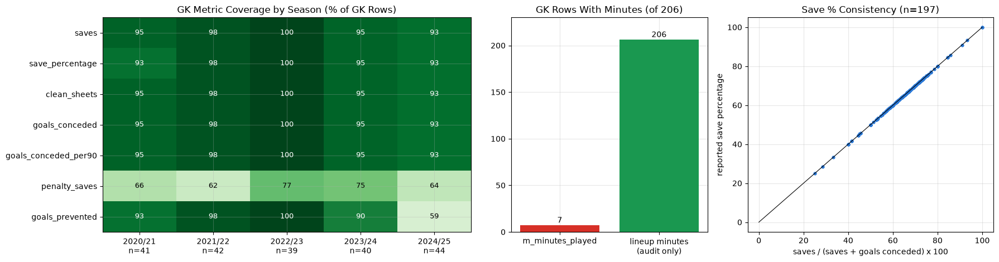

In [120]:
gk_rows45 = df45[df45[uni.POSITION].eq("GK")]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw={"width_ratios": [1.5, 0.8, 1]})
cov = gk45["gk_coverage_by_season"][[c for c in gk45["gk_coverage_by_season"].columns if c.endswith("_present_pct")]]
cov.columns = [c.removeprefix("m_").removesuffix("_present_pct") for c in cov.columns]
im = axes[0].imshow(cov.T.to_numpy(float), cmap="Greens", vmin=50, vmax=100, aspect="auto")
for i in range(cov.shape[1]):
    for j in range(cov.shape[0]):
        axes[0].text(j, i, f"{cov.iat[j, i]:.0f}", ha="center", va="center", fontsize=9, color="white" if cov.iat[j, i] > 85 else "black")
axes[0].set_xticks(range(len(SEASONS45)), [f"{prof.short(s)}\nn={n}" for s, n in zip(SEASONS45, gk45["gk_coverage_by_season"]["gk_rows"])])
axes[0].set_yticks(range(cov.shape[1]), cov.columns)
axes[0].set_title("GK Metric Coverage by Season (% of GK Rows)")
axes[1].bar(["m_minutes_played", "lineup minutes\n(audit only)"], gk45["gk_minutes_sources"]["gk_rows_with_value"], color=["#d73027", "#1a9850"])
for i, v in enumerate(gk45["gk_minutes_sources"]["gk_rows_with_value"]):
    axes[1].text(i, v + 3, str(v), ha="center")
axes[1].set_ylim(0, 230)
axes[1].set_title("GK Rows With Minutes (of 206)")
sp = gk_rows45.dropna(subset=["m_saves", "m_goals_conceded", "m_save_percentage"])
axes[2].scatter(sp["m_saves"] / (sp["m_saves"] + sp["m_goals_conceded"]) * 100, sp["m_save_percentage"], s=12, color=POS_COLORS["GK"])
axes[2].plot([0, 100], [0, 100], color="black", linewidth=0.8)
axes[2].set_xlabel("saves / (saves + goals conceded) x 100")
axes[2].set_ylabel("reported save percentage")
axes[2].set_title(f"Save % Consistency (n={len(sp)})")
plt.tight_layout()
plt.show()

**Interpretation**

- **Goalkeeper metrics are well covered on goalkeeper rows:** saves, save percentage, clean sheets and goals conceded (and per 90) have values on 93-100% of goalkeeper rows in every season. The exceptions are `penalty_saves` (62-77% per season; 63 of its nulls are `UNVERIFIED_POSITION` on goalkeeper rows) and `goals_prevented` (59% in 2024/25, with 15 `CONFLICTING` cells; RD-04).
- **Two source-reported goalkeeper rates are internally consistent:** `save_percentage` equals saves / (saves + goals conceded) on all 197 rows (largest difference 0.05 points, rounding), and `goals_conceded_per90` equals goals conceded x 90 / lineup minutes on all 198 rows. `clean_sheets` respects clean sheets <= appearances, but per-match clean sheets are not in the dataset.
- **Goalkeeper minutes are not missing from the evidence, only from the metric.** `m_minutes_played` has a value on 7 of 206 goalkeeper rows, but lineup-derived minutes (the `temporal_*` audit columns) exist for all 206. For outfield rows, lineup minutes equal `m_minutes_played` on 2,489 of 2,491 rows (largest difference 19 minutes). Using lineup minutes for goalkeepers would however mean deriving a feature from temporal-audit columns, which P4-A03 excludes. This is recorded as a new design decision (P4-D05) and not acted on.
- **Outfield metrics on goalkeeper rows** are coded `MISSING` (6,558 cells), not "not applicable". For goalkeepers, these nulls describe a metric that is not recorded for the position. They do not describe unknown goalkeeper performance and must not be read as zero.
- Goalkeeper performance cannot be inferred from unavailable values. With about 40 goalkeeper rows per season, season-level goalkeeper statistics remain imprecise (ISS-11).

### E. Temporal Validity of the Target (RD-03)

The target is the latest valuation on or before the official season end (D4). The analysis below recomputes the RD-03 reference values and examines how the valuation date relates to the season's matches, appearances and minutes. No staleness filter is applied, and D4 and D6 are unchanged.

In [121]:
ref45 = rel.temporal_reference(df45)
display(ref45)
tby45 = rel.temporal_by_season(df45, scope45)
display(tby45.rename(index=prof.short).round(2))
display(rel.alignment_classes(df45).rename(columns=lambda c: prof.short(c) if "/" in str(c) else c))
display(rel.old_valuations(df45))

,measure,reference,recomputed,matches_reference
0,Median valuation age (days),150.00,150.000000,True
1,Usable targets older than 90 days (%),56.62,56.618465,True
2,Appearances after the valuation date (%),44.10,44.097834,True
3,Minutes after the valuation date (%),43.66,43.664683,True
4,Targets older than 365 days,12.00,12.000000,True
5,Valuations after the season cutoff,0.00,0.000000,True
6,Usable targets dated before the season's first...,18.00,18.000000,True


,usable_targets,distinct_valuation_dates,top1_date,top1_share_pct,top3_share_pct,median_age_days,over_90_days_pct,over_365_days,league_games_after_valuation_median,appearances_after_valuation_pct,minutes_after_valuation_pct
season,,,,,,,,,,,
2020/21,515,13,2021-03-18,92.62,95.92,66.0,2.91,1,94.0,24.91,24.75
2021/22,528,23,2021-12-23,72.73,93.18,150.0,78.03,4,211.0,48.58,48.72
2022/23,542,24,2022-11-03,60.52,91.70,206.0,66.97,0,254.0,54.72,54.35
2023/24,567,18,2023-12-19,68.78,94.00,152.0,72.66,0,211.0,46.84,46.22
2024/25,545,26,2024-12-16,53.39,91.93,160.0,59.63,7,221.0,44.16,44.27


season,2020/21,2021/22,2022/23,2023/24,2024/25,total
temporal_alignment_class,,,,,,
ALL_GAMES_AFTER_VALUATION,17,51,55,55,46,224
ALL_GAMES_ON_OR_BEFORE_VALUATION,86,62,46,75,68,337
MIXED,412,415,441,437,431,2136
NO_VALUATION_SELECTED,9,9,12,3,17,50
total,524,537,554,570,562,2747


,fotmob_player_name,season,position_group_season,m_starts,target_market_value,target_valuation_date,target_valuation_age_days
485,Khanya Leshabela,2020/2021,MID,0.0,100000.0,2019-05-23,731.0
2545,Alex Palmer,2024/2025,GK,NaN,900000.0,2023-06-01,724.0
2469,Wes Burns,2024/2025,FWD,12.0,1200000.0,2023-06-09,716.0
563,Liam Delap,2021/2022,FWD,0.0,1000000.0,2020-10-13,586.0
2547,Patson Daka,2024/2025,FWD,6.0,15000000.0,2023-10-27,576.0
2495,Christian Walton,2024/2025,GK,7.0,900000.0,2023-10-27,576.0
2218,Jakub Stolarczyk,2024/2025,GK,10.0,300000.0,2023-10-27,576.0
2312,Alfie Dorrington,2024/2025,DEF,0.0,500000.0,2023-12-19,523.0
561,Dane Scarlett,2021/2022,FWD,0.0,250000.0,2020-12-17,521.0
2689,Edmond-Paris Maghoma,2024/2025,MID,0.0,350000.0,2023-12-27,515.0


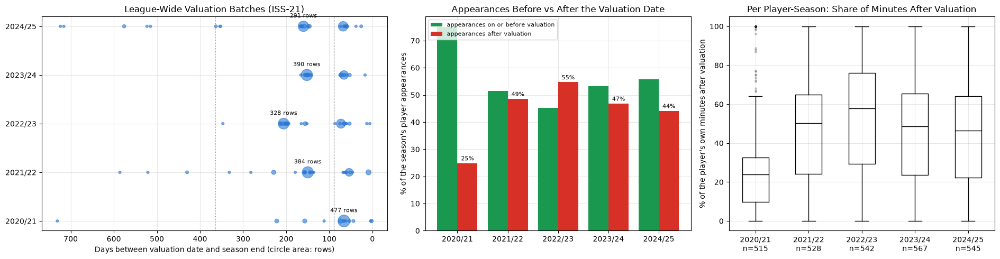

In [122]:
u45 = df45[df45["target_usable"]]
fig, axes = plt.subplots(1, 3, figsize=(19, 5), gridspec_kw={"width_ratios": [1.3, 1, 1]})
for i, s in enumerate(SEASONS45):
    ages = u45.loc[u45["season"] == s, "target_valuation_age_days"]
    counts = ages.value_counts()
    axes[0].scatter(counts.index, [i] * len(counts), s=np.sqrt(counts.values) * 12, alpha=0.6, color="#2a78d6")
    top = counts.idxmax()
    axes[0].annotate(f"{counts.max()} rows", (top, i), textcoords="offset points", xytext=(0, 12), ha="center", fontsize=8)
axes[0].set_yticks(range(len(SEASONS45)), [prof.short(s) for s in SEASONS45])
axes[0].axvline(90, color="grey", linestyle="--", linewidth=0.8)
axes[0].axvline(365, color="grey", linestyle=":", linewidth=0.8)
axes[0].invert_xaxis()
axes[0].set_xlabel("Days between valuation date and season end (circle area: rows)")
axes[0].set_title("League-Wide Valuation Batches (ISS-21)")

x = np.arange(len(SEASONS45))
axes[1].bar(x - 0.2, 100 - tby45["appearances_after_valuation_pct"], 0.4, color="#1a9850", label="appearances on or before valuation")
axes[1].bar(x + 0.2, tby45["appearances_after_valuation_pct"], 0.4, color="#d73027", label="appearances after valuation")
for i, v in enumerate(tby45["appearances_after_valuation_pct"]):
    axes[1].text(i + 0.2, v + 1, f"{v:.0f}%", ha="center", fontsize=8)
axes[1].set_xticks(x, [prof.short(s) for s in SEASONS45])
axes[1].set_ylabel("% of the season's player appearances")
axes[1].set_title("Appearances Before vs After the Valuation Date")
axes[1].legend(fontsize=8, loc="upper left")

share45 = rel.row_after_share(df45)
data = [share45[u45["season"] == s].dropna() * 100 for s in SEASONS45]
axes[2].boxplot(data, widths=0.5, medianprops={"color": "black"}, flierprops={"marker": "o", "markersize": 2, "alpha": 0.3})
axes[2].set_xticks(range(1, 6), [f"{prof.short(s)}\nn={len(d)}" for s, d in zip(SEASONS45, data)])
axes[2].set_ylabel("% of the player's own minutes after valuation")
axes[2].set_title("Per Player-Season: Share of Minutes After Valuation")
plt.tight_layout()
plt.show()

,group,n,spearman_minutes_before,spearman_minutes_after,spearman_before_vs_after_minutes
0,all seasons,2697,0.521,0.381,0.459
1,2020/21,515,0.528,0.412,0.689
2,2021/22,528,0.513,0.396,0.527
3,2022/23,542,0.557,0.386,0.473
4,2023/24,567,0.574,0.367,0.524
5,2024/25,545,0.575,0.356,0.472


,mostly before (<1/3 after) n,mostly before (<1/3 after),mixed n,mixed,mostly after (>2/3 after) n,mostly after (>2/3 after)
age_at_season_end_years,1134.0,-0.19,954.0,-0.30,609.0,-0.02
m_minutes_played,1063.0,0.57,883.0,0.39,552.0,0.52
m_appearances,1134.0,0.58,954.0,0.35,608.0,0.53
m_goals,1063.0,0.54,883.0,0.44,552.0,0.40
m_assists,1069.0,0.51,891.0,0.37,554.0,0.41
m_expected_goals,924.0,0.53,871.0,0.43,447.0,0.42
m_expected_assists,1116.0,0.59,953.0,0.45,599.0,0.56
m_rating,1064.0,0.62,942.0,0.56,561.0,0.50
m_accurate_passes_per90,982.0,0.20,929.0,0.23,502.0,0.31
m_tackles_per90,896.0,-0.13,857.0,-0.11,442.0,0.02


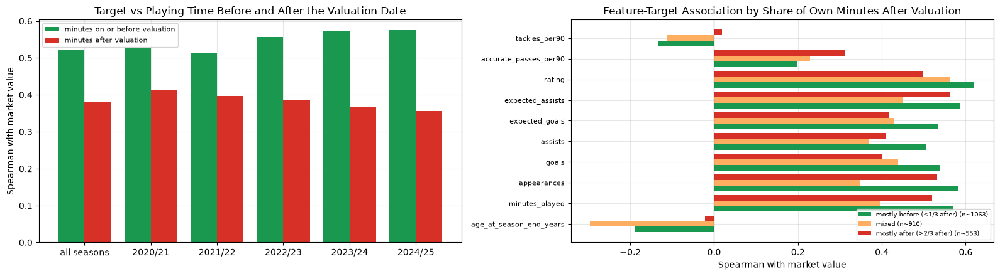

In [123]:
ba45 = rel.before_after_association(df45, scope45)
display(ba45.round(3))
bys45 = rel.association_by_after_share(df45, register45, biv.KEY_FEATURES)
display(bys45.round(2))
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
x = np.arange(len(ba45))
axes[0].bar(x - 0.2, ba45["spearman_minutes_before"], 0.4, color="#1a9850", label="minutes on or before valuation")
axes[0].bar(x + 0.2, ba45["spearman_minutes_after"], 0.4, color="#d73027", label="minutes after valuation")
axes[0].set_xticks(x, ba45["group"])
axes[0].set_ylabel("Spearman with market value")
axes[0].set_title("Target vs Playing Time Before and After the Valuation Date")
axes[0].legend(fontsize=8)
cols = ["mostly before (<1/3 after)", "mixed", "mostly after (>2/3 after)"]
t = bys45[cols].astype(float)
for k, c in enumerate(cols):
    axes[1].barh(np.arange(len(t)) + (k - 1) * 0.27, t[c], 0.27, label=f"{c} (n~{int(bys45[c + ' n'].median())})",
                 color=["#1a9850", "#fdae61", "#d73027"][k])
axes[1].set_yticks(range(len(t)), [f.removeprefix("m_") for f in t.index], fontsize=8)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Spearman with market value")
axes[1].set_title("Feature-Target Association by Share of Own Minutes After Valuation")
axes[1].legend(fontsize=7, loc="lower right")
plt.tight_layout()
plt.show()

**Interpretation: the temporal mismatch is real, season-dependent and partly visible in the associations** (D4 and D6 unchanged; no filter)

- **All RD-03 reference values are reproduced exactly from the official dataset:** median valuation age 150 days, 56.62% of usable targets older than 90 days, 44.10% of appearances and 43.66% of minutes after the valuation date, 12 targets older than 365 days, 0 valuations after the cutoff, and 18 targets dated before their season's first match.
- **League-wide batches:** each season has 13-26 distinct valuation dates, but the top three dates hold 91.7-95.9% of targets, and one date holds 53-93%. The batch falls 66 days before season end in 2020/21, but 150-206 days in later seasons. Correspondingly, 24.9% of 2020/21 appearances come after the valuation, against 44.2-54.7% in later seasons (2022/23 is the extreme).
- **Per player-season:** 2,136 rows mix games before and after the valuation; 224 rows have all their games after the valuation (for example players arriving late in the season), 337 all before, and 50 have no target. The share of a player's own minutes after valuation varies widely inside every season (figure, right panel).
- **The label tracks earlier playing time more than later playing time.** The target correlates 0.52 with minutes on or before the valuation date and 0.38 with minutes after it (0.51-0.58 vs 0.36-0.41 in every season). Later playing time still correlates with the target because playing time persists (before vs after minutes 0.46). This supports reading the target as a valuation at a point in the season, not as a summary of the whole season.
- **Most playing-time and attacking associations weaken for rows whose minutes lie mostly after the valuation:** rating 0.62 (mostly before) vs 0.50 (mostly after), goals 0.54 vs 0.40, appearances 0.58 vs 0.53. Not all do: accurate passes per 90 rises (0.20 vs 0.31). These groups also differ in who they contain (late arrivals and breakthrough players are over-represented in "mostly after"), so the comparison is descriptive and not a clean test.
- **Old labels (RD-01):** 12 usable targets are older than 365 days (maximum 731). They are kept and flagged as weak labels.
- None of this is read as later performance causing earlier valuations. The mismatch weakens label-feature correspondence; under objective A it is a documented limitation, not leakage.

### F. Identity Sensitivity (P4-B01, ISS-01)

The 533 P4-B01 rows (identity evidence tier not `AUTO_EXACT_VALIDATED`, or validation label `INCONCLUSIVE`) stay in the main dataset. They are compared here, and results without them are computed **for sensitivity only**. No identity label is invented.

In [124]:
display(rel.identity_overview(df45))
comp45 = rel.identity_comparison(df45)
display(comp45.T.round(2))
display(rel.identity_season_medians(df45, scope45).rename(index=prof.short))
ids45 = biv.identity_sensitivity(df45, register45).set_index("feature")
print("Feature-target Spearman: median |change| without P4-B01:", round(ids45["difference"].abs().median(), 3),
      "| max:", round(ids45["difference"].abs().max(), 3))

identity_rs5_validation_label,<null>,CONFIRMED_MATCH,INCONCLUSIVE,total
identity_evidence_tier,,,,
AUTO_ADJUDICATED_EXTERNAL,0,0,6,6
AUTO_ADJUDICATED_INDEPENDENT_RULE,0,73,3,76
AUTO_EXACT_NOT_INDEPENDENTLY_VALIDATED,0,0,449,449
AUTO_EXACT_VALIDATED,0,2214,0,2214
UNRESOLVED,2,0,0,2
total,2,2287,458,2747


population,main dataset,P4-B01 subset,main without P4-B01 (sensitivity only)
rows,2747.00,533.00,2214.00
players,1228.00,300.00,928.00
usable_targets,2697.00,505.00,2192.00
target_missing_pct,1.82,5.25,0.99
target_p25_eur,5000000.00,2000000.00,6000000.00
target_median_eur,13000000.00,8000000.00,15000000.00
target_p75_eur,25000000.00,22000000.00,28000000.00
target_p90_eur,45000000.00,35000000.00,47700000.00
age_median,26.39,25.00,26.64
starts_median,14.00,7.00,15.00


,median_all_eur,median_without_p4b01_eur,p4b01_rows
season,,,
2020/21,10000000.0,12000000.0,110
2021/22,10000000.0,12000000.0,116
2022/23,15000000.0,15000000.0,94
2023/24,13000000.0,15000000.0,102
2024/25,17000000.0,18000000.0,111


Feature-target Spearman: median |change| without P4-B01: 0.016 | max: 0.092


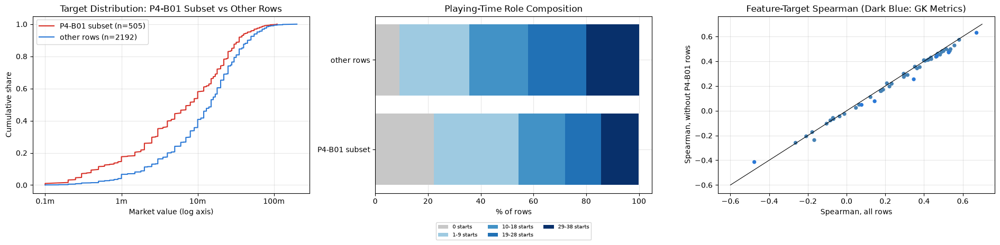

In [125]:
m45 = biv.identity_sensitivity_mask(df45)
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
for name, sel, col in (("P4-B01 subset", m45, "#d73027"), ("other rows", ~m45, "#2a78d6")):
    v = np.sort(np.log10(df45.loc[sel & df45["target_usable"], uni.TARGET]))
    axes[0].plot(v, np.arange(1, len(v) + 1) / len(v), color=col, label=f"{name} (n={len(v)})")
axes[0].set_xticks(np.log10(np.array([0.1, 1, 10, 100]) * 1e6), ["0.1m", "1m", "10m", "100m"])
axes[0].set_xlabel("Market value (log axis)")
axes[0].set_ylabel("Cumulative share")
axes[0].set_title("Target Distribution: P4-B01 Subset vs Other Rows")
axes[0].legend()
roles = pd.crosstab(m45.map({True: "P4-B01 subset", False: "other rows"}), mvt.groups(df45)["starts_group"], normalize="index") * 100
roles = roles[[c for c in mvt.STARTS_LABELS if c in roles.columns]]
left = np.zeros(len(roles))
for c, col in zip(roles.columns, ["#c7c7c7", "#9ecae1", "#4292c6", "#2171b5", "#08306b"]):
    axes[1].barh(roles.index, roles[c], left=left, color=col, label=c)
    left += roles[c].to_numpy()
axes[1].set_xlabel("% of rows")
axes[1].set_title("Playing-Time Role Composition")
axes[1].legend(fontsize=7, ncols=3, loc="upper center", bbox_to_anchor=(0.5, -0.15))
axes[2].scatter(ids45["spearman_all"], ids45["spearman_without_p4b01"], s=18,
                c=[POS_COLORS["GK"] if f in uni.FEATURE_GROUPS["8 Goalkeeping"] else COLOR for f in ids45.index])
axes[2].plot([-0.6, 0.7], [-0.6, 0.7], color="black", linewidth=0.8)
axes[2].set_xlabel("Spearman, all rows")
axes[2].set_ylabel("Spearman, without P4-B01 rows")
axes[2].set_title("Feature-Target Spearman (Dark Blue: GK Metrics)")
plt.tight_layout()
plt.show()

**Interpretation**

- **Composition of the subset:** 449 rows are exact matches without independent validation, 76 rule-adjudicated (3 of them inconclusive: RD-02), 6 externally adjudicated (inconclusive) and 2 unresolved (ISS-04). The subset covers 300 players.
- **The subset is not a random sample.** Its median value is EUR 8m (vs 15m for the other rows), 22.3% of its rows have 0 starts (vs 9.3%), and 5.3% lack a target (vs 1.0%). Lower-profile and fringe players more often lack independent identity validation. Excluding the subset would therefore shift the population towards regular, higher-valued players; this is why it stays in the main analysis.
- **Effect on results:**
  - Target distribution: season medians rise by EUR 0-2m without the subset; the overall median rises from EUR 13m to 15m.
  - Descriptive relationships: feature-target Spearman changes by a median of 0.016 and at most 0.092 (goalkeeper save percentage); no association with \|rho\| > 0.05 changes sign.
  - Group results (4.4): medians for players with >= 10 starts change by at most 3%; fringe-group medians are the least robust.
  - Potential modeling conclusions: target levels for fringe players and goalkeepers are the most sensitive; any reported model result should include a P4-B01 sensitivity run (P4-B01 is required before final results).
- **Coverage is not precision.** Automated mapping covers 99.84% of identities and 99.93% of rows, but no mapping has been validated by a person. The 95% lower bound of automated-validator precision among decided pairs is 98.73% (below the 99% SOP), and only 73.70% if inconclusive pairs count as unverified (ISS-01). Robust results under P4-B01 do not prove that the mappings are correct.

### G. RD-04 Metric Reliability

The five RD-04 metrics are assessed on coverage, observation window, missingness, position relevance and evidence quality. **This assessment neither approves nor excludes them**; the decision is left to the modeling design (section 8.7.F).

,metric,season,applicable_rows,values,coverage_pct,status_MISSING,status_CONFLICTING,status_UNVERIFIED_POSITION,window_status,window_agree_pct,match_coverage_pct,spearman_with_target,pairs
0,m_clearances,2020/2021,524,0,0.00,524,0,0,NO_SEASON_VALUES,NaN,100.00,NaN,0
1,m_clearances,2021/2022,537,33,6.15,504,0,0,FULL_EPL_SEASON_VERIFIED,100.00,100.00,0.15,33
2,m_clearances,2022/2023,554,0,0.00,554,0,0,NO_SEASON_VALUES,NaN,100.00,NaN,0
3,m_clearances,2023/2024,570,51,8.95,519,0,0,FULL_EPL_SEASON_VERIFIED,100.00,100.00,0.07,51
4,m_clearances,2024/2025,562,447,79.54,115,0,0,FULL_EPL_SEASON_VERIFIED,100.00,100.00,0.14,443
5,m_clearances_per90,2020/2021,524,0,0.00,524,0,0,NO_SEASON_VALUES,NaN,NaN,NaN,0
6,m_clearances_per90,2021/2022,537,33,6.15,504,0,0,NOT_VERIFIABLE_FROM_MATCH_DATA,NaN,NaN,-0.05,33
7,m_clearances_per90,2022/2023,554,0,0.00,554,0,0,NO_SEASON_VALUES,NaN,NaN,NaN,0
8,m_clearances_per90,2023/2024,570,51,8.95,519,0,0,NOT_VERIFIABLE_FROM_MATCH_DATA,NaN,NaN,-0.12,51
9,m_clearances_per90,2024/2025,562,447,79.54,115,0,0,NOT_VERIFIABLE_FROM_MATCH_DATA,NaN,NaN,-0.24,443


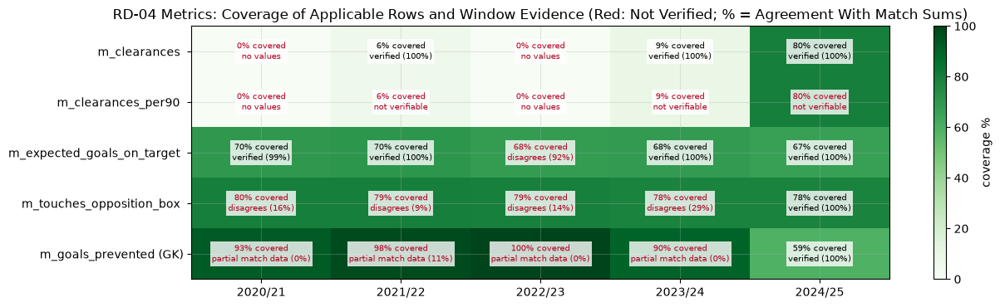

In [126]:
rd45 = rel.rd04_assessment(df45, scope45)
display(rd45.round(2))
win_codes = {"FULL_EPL_SEASON_VERIFIED": "verified", "DISAGREES_WITH_MATCH_SUM": "disagrees", "NO_SEASON_VALUES": "no values",
             "NOT_VERIFIABLE_FROM_MATCH_DATA": "not verifiable", "PARTIAL_MATCH_COVERAGE": "partial match data"}
cov = rd45.pivot(index="metric", columns="season", values="coverage_pct").reindex(uni.RD04)
win = rd45.pivot(index="metric", columns="season", values="window_status").reindex(uni.RD04)
agree = rd45.pivot(index="metric", columns="season", values="window_agree_pct").reindex(uni.RD04)
fig, ax = plt.subplots(figsize=(13, 3.8))
im = ax.imshow(cov.to_numpy(float), cmap="Greens", vmin=0, vmax=100, aspect="auto")
for i in range(cov.shape[0]):
    for j in range(cov.shape[1]):
        a = agree.iat[i, j]
        txt = f"{cov.iat[i, j]:.0f}% covered\n{win_codes.get(win.iat[i, j], win.iat[i, j])}" + (f" ({a:.0f}%)" if pd.notna(a) else "")
        ax.text(j, i, txt, ha="center", va="center", fontsize=7.5,
                color="#b00020" if win.iat[i, j] != "FULL_EPL_SEASON_VERIFIED" else "black",
                bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none", "pad": 1.5})
ax.set_xticks(range(len(SEASONS45)), [prof.short(s) for s in SEASONS45])
ax.set_yticks(range(len(uni.RD04)), [f"{m} {'(GK)' if m in uni.FEATURE_GROUPS['8 Goalkeeping'] else ''}" for m in uni.RD04])
ax.set_title("RD-04 Metrics: Coverage of Applicable Rows and Window Evidence (Red: Not Verified; % = Agreement With Match Sums)")
fig.colorbar(im, ax=ax, label="coverage %")
plt.tight_layout()
plt.show()

**Interpretation (pending design decision RD-04; no approval or exclusion implied)**

| Metric | Coverage | Window evidence | Position relevance | Reading |
|---|---|---|---|---|
| `clearances` | 0% in 2020/21 and 2022/23; 6-9% in 2021/22 and 2023/24; 80% in 2024/25 | Verified wherever values exist | Defensive (all outfield) | Usable values, but effectively one season; season-dependent availability would confound any pooled use |
| `clearances_per90` | As `clearances` | Not verifiable from match data (derived) | Defensive | Same coverage problem plus P4-B05 |
| `expected_goals_on_target` | 67-70% per season | Verified in four seasons; 92.06% agreement in 2022/23 | Attacking | Stable coverage; one season with partial disagreement; strongly redundant with shots and xG (4.3) |
| `touches_opposition_box` | 78-80% per season | Disagrees with match sums in 2020/21-2023/24 (9-29% agreement; ratio to match sums 1.10-1.33); verified only in 2024/25 | Attacking | The season value appears to measure something different from the per-match field before 2024/25. Its strong association (Spearman 0.46-0.55 in every season) does not resolve the definition problem |
| `goals_prevented` (GK) | 90-100% of GK rows in 2020/21-2023/24; 59% in 2024/25 (15 conflicting) | Per-match field on only 1-3% of matches before 2024/25; verified only in 2024/25 | GK only | Weak evidence in four seasons, and the verified season is the least complete |

The decision options remain those of RD-04: exclude, or use with season-aware handling. Step 8.6 records the evidence in the feature assessment without deciding.

### H. Club Context Reliability (RS5-12)

The eight club-context columns are described for availability and temporal meaning only. They are not candidate predictors by default.

In [127]:
club45 = rel.club_context(df45, scope45)
for k, v in club45.items():
    print(k)
    display(v.rename(columns=lambda c: prof.short(c) if "/" in str(c) else c))

club_context_availability


,column,non_null,distinct,example
0,confirmed_team_ids,2747,73,8602
1,confirmed_team_count,2747,2,1
2,associated_team_count,2747,2,1
3,associated_team_ids,2747,89,8602
4,associated_team_names,2747,89,Wolverhampton Wanderers
5,is_multi_club,2747,2,False
6,multi_club_status,2747,2,SINGLE_CLUB
7,multi_club_class,2747,3,SINGLE_CLUB


club_context_by_season


season,2020/21,2021/22,2022/23,2023/24,2024/25,total
multi_club_class,,,,,,
MULTI_CLUB_CONFIRMED_APPEARANCES,8,9,15,10,12,54
MULTI_CLUB_SQUAD_ONLY,3,3,6,2,5,19
SINGLE_CLUB,513,525,533,558,545,2674
total,524,537,554,570,562,2747


club_context_target


,usable_targets,median_eur
multi_club_class,,
MULTI_CLUB_CONFIRMED_APPEARANCES,54,17000000.0
MULTI_CLUB_SQUAD_ONLY,19,12000000.0
SINGLE_CLUB,2624,13000000.0


club_context_timing


,multi_club_rows,with_usable_target,median_minutes_after_valuation_pct,rows_with_games_after_valuation
0,73,73,43.541667,66


**Interpretation**

- **Availability is complete:** all eight columns are non-null on every row. They encode the club(s) a player was associated with in the season (73 distinct confirmed team-id combinations, 89 associated-team combinations).
- **Temporal meaning is the problem, not coverage.** Club membership is a whole-season fact. For the 73 multi-club rows (54 with confirmed appearances for two clubs, 19 squad-only), the move happened sometime during the season. 66 of them have games after their valuation date, and a median of 44% of their minutes falls after it. The dataset does not record the transfer date, so it cannot tell whether a move came before or after the valuation. A move after the valuation would put post-valuation information into the row.
- **A club can also proxy value directly** (team strength, budget), which is plausibly the confounder behind the defensive and goalkeeper patterns in 4.3 and 4.4. Multi-club rows with confirmed appearances have a higher median (EUR 17m vs 13m for single-club rows), but these 54 rows are too few for conclusions.
- Club context therefore stays **conditional (RS5-12)**. Any use needs a design decision on its temporal interpretation (for example, using only the club at the valuation date, which would need data not in this release).

### I. Source-Reported Metrics (ISS-29) and Other Known Conditions

In [128]:
display(rel.source_reported(df45, gk45["gk_consistency_checks"]).set_index("metric").round(2))
display(rel.other_conditions(df45, scope45).set_index("condition"))

,applicable_rows,values,null_pct,outside_0_100,values_at_0_or_100_pct,check_result,verifiable_in_dataset
metric,,,,,,,
m_aerials_won_percent,2541,2150,15.39,0.0,1.16,Denominator (aerial duels contested) not in th...,False
m_cross_accuracy,2541,1600,37.03,0.0,2.19,Denominator (crosses attempted) not in the dat...,False
m_duels_won_percent,2541,2222,12.55,0.0,0.14,Denominator (duels contested) not in the datas...,False
m_long_ball_accuracy,2541,2132,16.10,0.0,1.92,Denominator (long balls attempted) not in the ...,False
m_passing_accuracy,2541,2224,12.48,0.0,0.04,Denominator (passes attempted) not in the data...,False
m_save_percentage,206,197,4.37,0.0,1.02,Consistent with saves / (saves + goals concede...,True
m_clean_sheets,206,198,3.88,NaN,NaN,Bound clean sheets <= appearances holds; per-m...,False
m_goals_conceded_per90,206,198,3.88,NaN,NaN,Identical to goals conceded x 90 / lineup minu...,True


,topic,evidence,handling
condition,,,
ISS-28,key_passes excluded,m_key_passes null on 2747 of 2747 rows; s_key_...,Excluded; no data to assess
P4-A04,Present-day nationality excluded,"2747 rows with a value, 88 distinct values; co...",Not a historical fact; excluded
DQ-RS5-04,Starts greater than appearances,"6 rows, seasons ['2020/2021']",Kept as published; affects start-share ratios ...
RS5-13,Historical source revisions,expected_goals 34; minutes_played 3; rating 58,Later source value kept; values may differ fro...
RD-01,Old valuation labels,12 usable targets older than 365 days (max 731),Kept; weak labels; owner decision open
ISS-04,Unresolved identities,"2 rows (REVIEW_REQUIRED, no target)",Human review required; not adjudicated
P4-B02,Conflicting cells,accurate_passes_per90 1; goals_prevented 18; r...,Null and traceable; never zero
P4-B02,Unverified-position cells,17899 cells: 17787 on outfield rows (GK-only m...,Not applicable; never zero
ISS-27,Rows without target,"50: ONLY_VALUATIONS_AFTER_CUTOFF 37, NO_VALUAT...",Kept in the dataset; no target imputed


**Interpretation**

- **Source-reported rates:** all bounded rates lie within [0, 100]. Two goalkeeper rates are now internally consistent with their totals (`save_percentage`, `goals_conceded_per90`). The five outfield rates (`aerials_won_percent`, `cross_accuracy`, `duels_won_percent`, `long_ball_accuracy`, `passing_accuracy`) cannot be checked, because their denominators (attempts) are not in the dataset. `clean_sheets` satisfies its bound but cannot be verified per match. Small denominators produce 0% and 100% values (`cross_accuracy` 2.2% of values). The ISS-29 caveat therefore remains for six of the eight metrics and is weakened, not removed, for the two consistent goalkeeper rates. `passing_accuracy` also drifts across seasons (P4-B09).
- **Other conditions (all unchanged and documented):** `key_passes` has no data (excluded, ISS-28). Present-day nationality has 88 values collected in November 2026 and is excluded (P4-A04). Six 2020/21 rows have starts > appearances (kept, DQ-RS5-04). 95 source-revised cells (RS5-13). 12 targets are older than 365 days (RD-01). 2 identities are unresolved (ISS-04). 36 conflicting and 17,899 unverified-position cells are null; 112 of the unverified-position cells sit on goalkeeper rows. 50 rows have no target (37 only valuations after the cutoff, 11 no valuation history, 2 unresolved identity).

### J. Reliability Overview

,null_applicable_pct,seasons_with_values,window_evidence,source_check,applicability,reliability_class,caveats
feature,,,,,,,
age_at_season_end_years,0.000000,5,not a season metric,"birth date (4 disputed, ISS-07)",all rows,reliable with caveat,ISS-07
m_appearances,0.036403,5,verified all seasons,window audit,ALL,reliable with caveat,RD-03
m_starts,0.036403,5,verified or derived from verified totals,window audit,ALL,reliable with caveat,RD-03
m_minutes_played,7.244266,5,verified all seasons,window audit,ALL,reliable with caveat,"RD-03, RS5-13"
m_goals,7.244266,5,verified all seasons,window audit,ALL,reliable with caveat,RD-03
m_assists,6.661813,5,verified all seasons,window audit,ALL,reliable with caveat,RD-03
m_shots,19.038952,5,verified all seasons,window audit,ALL,reliable with caveat,RD-03
m_shots_on_target,30.906443,5,verified all seasons,window audit,ALL,"reliable values, limited coverage",RD-03
m_shots_per90,19.038952,5,verified or derived from verified totals,window audit,ALL,reliable with caveat,"RD-03, P4-B05, P4-B09"


reliability_class
reliable with caveat                      25
reliable values, limited coverage         15
uncertain: source-reported                 6
pending owner decision (RD-04)             5
source-reported, internally consistent     2


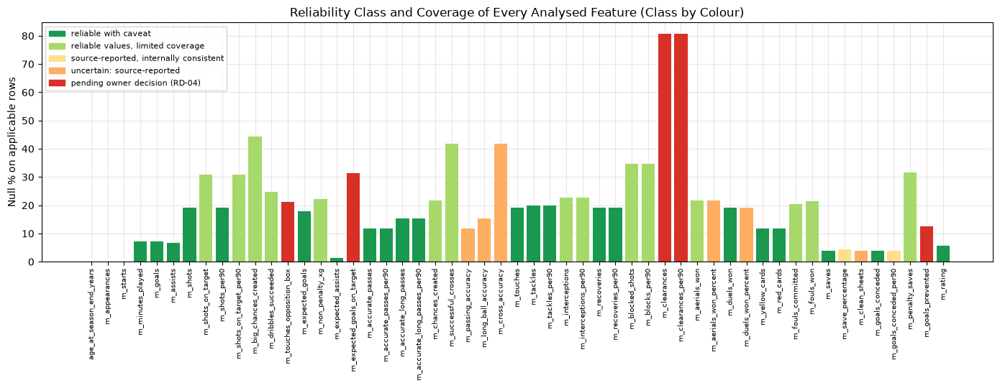

In [129]:
window45 = pd.read_csv(rel.WINDOW_AUDIT).rename(columns=lambda c: c.lstrip("﻿"))
map45 = rel.reliability_map(df45, register45, fm45, window45)
display(map45.set_index("feature"))
print(map45["reliability_class"].value_counts().to_string())

classes = ["reliable with caveat", "reliable values, limited coverage", "source-reported, internally consistent",
           "uncertain: source-reported", "pending owner decision (RD-04)"]
class_colors = ["#1a9850", "#a6d96a", "#fee08b", "#fdae61", "#d73027"]
m = map45.set_index("feature")
fig, ax = plt.subplots(figsize=(14, 5.5))
for k, f in enumerate(m.index):
    c = class_colors[classes.index(m.at[f, "reliability_class"])]
    ax.bar(k, m.at[f, "null_applicable_pct"], color=c)
ax.set_xticks(range(len(m)), m.index, rotation=90, fontsize=7)
ax.set_ylabel("Null % on applicable rows")
ax.set_title("Reliability Class and Coverage of Every Analysed Feature (Class by Colour)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in class_colors], labels=classes, fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

**How to read the reliability classes** (evidence description, not feature selection; RD-03 applies to every feature)

| Class | Features | Meaning |
|---|---:|---|
| Reliable with caveat | 25 | Window verified in all seasons (or derived from verified totals), null share <= 20%; caveats per feature (P4-B05 rates, P4-B09 drift, RS5-13 revisions, leaderboard fallback, GK-only) |
| Reliable values, limited coverage | 15 | Same evidence, but more than 20% null on applicable rows, mostly low-minute players (P4-B07); values are trustworthy where present, but missingness is informative |
| Source-reported, internally consistent | 2 | `save_percentage`, `goals_conceded_per90`: consistent with totals and lineup minutes |
| Uncertain: source-reported | 6 | ISS-29 rates that cannot be verified in the dataset (5 outfield percentages, `clean_sheets`) |
| Pending design decision | 5 | RD-04 metrics with incomplete window evidence or season coverage |

Observations that are **unsuitable for specific interpretations**: any null as a zero; outfield metrics on goalkeeper rows; per-90 rates under 90 minutes (P4-B05); `touches_opposition_box` before 2024/25 as the per-match quantity; `clearances` as a five-season feature; club context as a pre-valuation fact; season-level target differences as performance effects; targets older than 365 days as current valuations.

### K. Interpretation of Important Findings

1. **Status semantics are clean and preserved.** Every unavailable, not-applicable, unsupported or conflicting cell is null; every genuine zero is recorded as zero. Missing values do not need to be guessed: their meaning is in `s_*`.
2. **Missingness follows playing time, not season.** It is concentrated in rows with 0 starts or under 90 minutes, and in rows without a target. It is informative and not random (ISS-27, P4-B07).
3. **Goalkeepers differ in coding, not in coverage of their own metrics.** Goalkeeper metrics cover 93-100% of goalkeeper rows (except penalty saves and goals prevented). Outfield metrics are coded `MISSING` for goalkeepers. Goalkeeper minutes exist in lineup evidence but not in `m_minutes_played` (P4-D05).
4. **The temporal mismatch is reproduced exactly and is strongly season-dependent** (25% of appearances after valuation in 2020/21, 44-55% later). The label tracks earlier playing time more than later playing time, and associations weaken for players whose minutes mostly follow the valuation.
5. **Identity evidence quality does not change the descriptive relationships**, but the P4-B01 subset is lower-valued and fringe-heavy, so excluding it would bias the population. Coverage is not precision.
6. **RD-04 evidence is weak in different ways:** `clearances` lacks seasons, `touches_opposition_box` measures something else before 2024/25, `goals_prevented` is weakly verified, and `expected_goals_on_target` is nearly fine. Club context is complete but temporally ambiguous.
7. **Source-reported rates:** two goalkeeper rates are internally consistent; six remain unverifiable.

### L. Limitations

- The status decision diagram is a reading aid based on the documented vocabulary, not a reconstruction of the collection code.
- `MISSING` cannot be split further into "no event" and "not collected" from this dataset (P4-B07). The share of each is unknown.
- Temporal analysis uses the dataset's own audit columns. Whether the valuation date is an effective or a publication date is unknown (ISS-24). Same-day duplicates were removed upstream (ISS-23).
- The before/after comparisons are descriptive; groups by after-share differ in composition.
- Identity sensitivity compares with and without P4-B01; it cannot measure the true error rate without human labels (ISS-01).
- RD-04 assessment relies on the rs5 window audit; it was not re-derived from raw match data here.
- Club context temporal meaning cannot be resolved without transfer dates.
- RD-03 applies to every target statement.

### M. Step 8.5 Conclusion

The data are **reliable where they are observed**: status and value agree on every cell, the window evidence verifies most metrics in all five seasons, and two goalkeeper rates are internally consistent. The main reliability limits are structural:
- informative missingness concentrated in fringe players and rows without a target;
- a goalkeeper sub-population with different coding and no minutes metric;
- a season-dependent temporal mismatch between a mostly mid-season label and whole-season features;
- an identity-sensitivity subset that is small in effect but not random in composition;
- five RD-04 metrics and the club-context columns whose use needs design decisions;
- six unverifiable source-reported rates.

None of these limits was resolved by exclusion, imputation, filtering or reclassification; each is documented for the feature assessment in step 8.6. New items: P4-B10 (status coding of outfield metrics on goalkeeper rows, conflicts concentrated in 2024/25) and P4-D05 (goalkeeper minutes from lineup evidence: design decision).

**Gate G4.5:** see `reports/phase_04/step_05/PHASE4_05_ACCEPTANCE_REPORT.md`.

---

## 8.6 Feature Assessment & Modeling Feasibility

Objective:
Assess which candidate predictors and feature groups look suitable for a future regression dataset, and whether a reliable regression study is feasible in the modeling stage, using the evidence of steps 8.1 to 8.5. **This is an assessment, not feature selection.** No feature is engineered, selected, removed or reclassified, no model is trained, and no split is executed.

Questions:
1. Which feature groups appear promising, and which features have sufficient coverage and acceptable reliability?
2. Which features carry temporal-alignment concerns, are redundant, or are position-specific?
3. Which features must stay conditional, and why are some columns excluded?
4. Is the target suitable for regression, and which target scale and population structure should the modeling stage consider?
5. Which evaluation splits are appropriate, and which risks must the modeling stage carry?

### A. Evaluation Framework

Each of the 53 analysed features is rated on twelve dimensions. Ten are **evidence-based** and follow a fixed rule; two are **judgments** and are labelled as such. Ratings come from the tested evidence of earlier sub-phases (each evidence set has a test asserting it equals a recomputation from the official dataset).

| # | Dimension | Type | Rule | Source |
|---|---|---|---|---|
| 1 | Coverage | evidence | High: <=10% null on applicable rows and values in 5 seasons; Medium: <=30%; Low: >30% or < 5 seasons | 4.5 |
| 2 | Missingness | evidence | "Informative" when the median target on null rows is less than half that on present rows | 4.3 |
| 3 | Source reliability | evidence | Phase 8.5 reliability class | 4.5 |
| 4 | Temporal alignment | evidence | RD-03 for all; plus incomplete window (RD-04) or small denominators (P4-B05) | 4.5, 4.1 |
| 5 | Position relevance | evidence | GK only, or outfield within-position Spearman range >= 0.25: position-specific | 4.4 |
| 6 | Distribution | evidence | Skewness label | 4.2 |
| 7 | Outlier behaviour | evidence | Heavy tail when > 2% of values lie beyond 3 IQR (kept, never removed) | 4.2 |
| 8 | Redundancy | evidence | Max \|Spearman\| with another outfield feature: >= 0.9 high, >= 0.8 medium | 4.3 |
| 9 | Interpretability | **judgment** | Counts/totals high; per-90, model-based, percentages medium; composite rating low | – |
| 10 | Target association | evidence | Pooled \|Spearman\| (strong/moderate/weak/none) and partial Spearman given starts (retained >= 0.25, partly 0.10-0.25, mostly playing time < 0.10); max \|Spearman\| among regular players of the same population | 4.3, 4.4 |
| 11 | Identity sensitivity | evidence | \|change without P4-B01\| >= 0.05: sensitive | 4.3 |
| 12 | Modeling usefulness | **judgment by explicit rules** | Pending/conditional first; then playing time and age as axes; "promising" if association is retained beyond playing time or >= 0.3 among regulars | combination |

The resulting **The modeling stage recommendation** is a consideration category, not a selection. Code: `src/phase4/feasibility.py`; evidence: `reports/phase_04/step_06/evidence/`.

In [130]:
from src.phase4 import feasibility as fea

df46, schema46, scope46, verification46 = prof.load_verified()
dictionary46, eligibility46, reliability46 = prof.load_metadata()
register46 = uni.feature_register(eligibility46, reliability46)
print("SHA-256 verified:", verification46["sha256"] == prof.DATASET_SHA256)
print("Seasons (load_scope):", [prof.short(s) for s in scope46.labels])
ev46 = fea.load_evidence()
fa46 = fea.feature_assessment(df46, register46, ev46)
cols = ["feature", "analysis_group", "coverage", "missingness_informative", "reliability_class", "temporal", "position_relevance", "shape",
        "tail", "redundancy", "interpretability_judgment", "association", "beyond_playing_time", "identity_sensitivity",
        "usefulness_judgment", "phase5_recommendation"]
display(fa46.set_index("feature")[["coverage", "reliability_class", "association", "beyond_playing_time", "phase5_recommendation"]])
print("All twelve dimensions: reports/phase_04/step_06/evidence/feature_assessment_matrix.csv and the matrix figure below.")

SHA-256 verified: True
Seasons (load_scope): ['2020/21', '2021/22', '2022/23', '2023/24', '2024/25']


,coverage,reliability_class,association,beyond_playing_time,phase5_recommendation
feature,,,,,
age_at_season_end_years,high,reliable with caveat,weak,retained,consider; needs a non-linear representation
m_appearances,high,reliable with caveat,strong,partly retained,consider one representation of playing time
m_starts,high,reliable with caveat,strong,n/a (is the control),consider one representation of playing time
m_minutes_played,high,reliable with caveat,strong,mostly playing time,consider one representation of playing time
m_goals,high,reliable with caveat,strong,retained,consider (core candidate)
m_assists,high,reliable with caveat,moderate,partly retained,consider (core candidate)
m_shots,medium,reliable with caveat,strong,retained,consider (core candidate)
m_shots_on_target,low,"reliable values, limited coverage",moderate,retained,consider with missingness handling (P4-B07)
m_shots_per90,medium,reliable with caveat,weak,retained,consider (core candidate)


All twelve dimensions: reports/phase_04/step_06/evidence/feature_assessment_matrix.csv and the matrix figure below.


### B. Feature Assessment Matrix

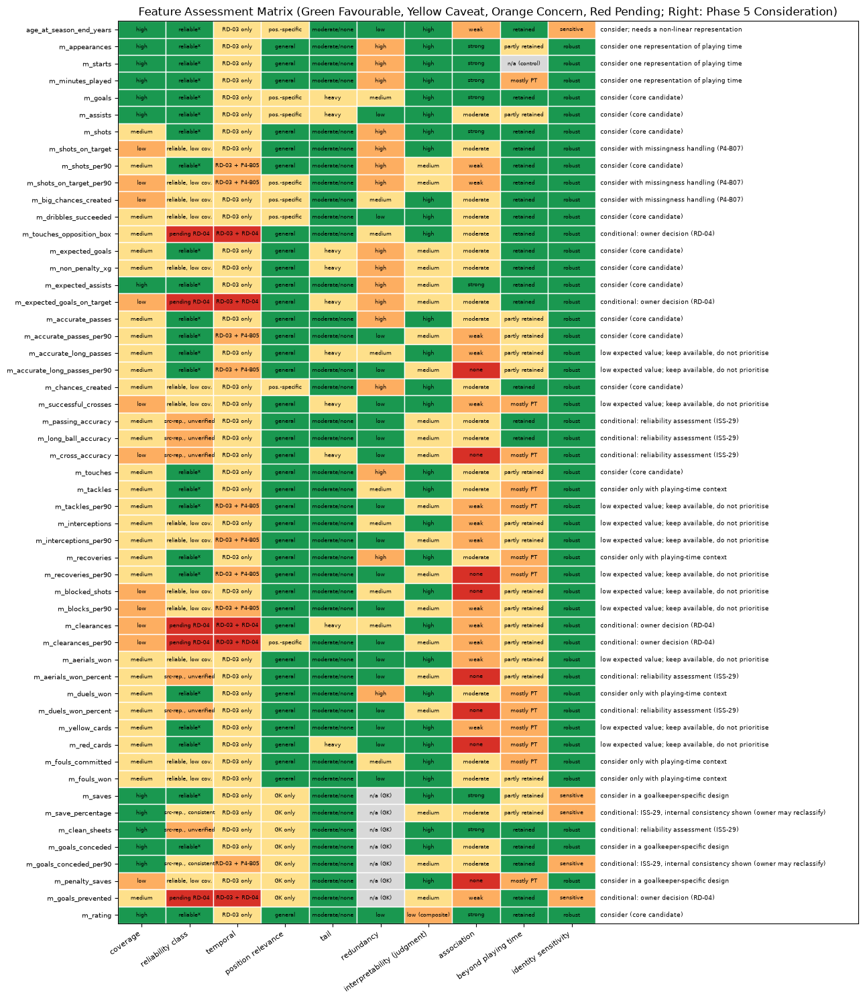

features
coverage                  medium                                                    29
                          high                                                      13
                          low                                                       11
reliability_class         reliable with caveat                                      25
                          reliable values, limited coverage                         15
                          uncertain: source-reported                                 6
                          pending owner decision (RD-04)                             5
                          source-reported, internally consistent                     2
temporal                  RD-03 only                                                39
                          RD-03 + small denominators (P4-B05)                        9
                          RD-03 + incomplete window (RD-04)                          5
position_relevance        general                                                   38
                          position-specific                                          8
                          GK only                                                    7
tail                      moderate/none                                             43
                          heavy                                                     10
redundancy                low                                                       21
                          high                                                      16
                          medium                                                     9
                          n/a (GK matrix)                                            7
interpretability_judgment high                                                      31
                          medium                                                    21
                          low (composite source score)                               1
association               moderate                                                  21
                          weak                                                      15
                          strong                                                     9
                          none                                                       8
beyond_playing_time       retained                                                  21
                          partly retained                                           18
                          mostly playing time                                       13
                          n/a (is the control)                                       1
identity_sensitivity      robust                                                    48
                          sensitive                                                  5
usefulness_judgment       promising                                                 18
                          limited descriptive association                           12
                          unknown until RD-04 is decided                             5
                          mostly a playing-time proxy                                5
                          limited                                                    4
                          promising as the playing-time axis; highly redu...         3
                          promising but incomplete                                   3
                          promising for goalkeepers                                  2
                          promising (non-monotonic; interacts with playin...         1
phase5_recommendation     consider (core candidate)                                 13
                          low expected value; keep available, do not prio...        12
                          conditional: reliability assessment (ISS-29)               6
                          conditional: owner decision (RD-04)               

In [131]:
# Visual matrix: green = favourable, yellow = caveat, orange = concern, red = blocked/pending, grey = not applicable
SCORE = {
    "coverage": {"high": 3, "medium": 2, "low": 1},
    "reliability_class": {"reliable with caveat": 3, "reliable values, limited coverage": 2, "source-reported, internally consistent": 2,
                          "uncertain: source-reported": 1, "pending owner decision (RD-04)": 0},
    "temporal": {"RD-03 only": 2, "RD-03 + small denominators (P4-B05)": 1, "RD-03 + incomplete window (RD-04)": 0},
    "position_relevance": {"general": 3, "position-specific": 2, "GK only": 2},
    "tail": {"moderate/none": 3, "heavy": 2},
    "redundancy": {"low": 3, "medium": 2, "high": 1, "n/a (GK matrix)": -1},
    "interpretability_judgment": {"high": 3, "medium": 2, "low (composite source score)": 1},
    "association": {"strong": 3, "moderate": 2, "weak": 1, "none": 0},
    "beyond_playing_time": {"retained": 3, "partly retained": 2, "mostly playing time": 1, "n/a (is the control)": -1},
    "identity_sensitivity": {"robust": 3, "sensitive": 1},
}
cmap = {-1: "#d9d9d9", 0: "#d73027", 1: "#fdae61", 2: "#fee08b", 3: "#1a9850"}
ABBREV = {"reliable with caveat": "reliable*", "reliable values, limited coverage": "reliable, low cov.",
          "source-reported, internally consistent": "src-rep., consistent", "uncertain: source-reported": "src-rep., unverified",
          "pending owner decision (RD-04)": "pending RD-04", "RD-03 + small denominators (P4-B05)": "RD-03 + P4-B05",
          "RD-03 + incomplete window (RD-04)": "RD-03 + RD-04", "n/a (GK matrix)": "n/a (GK)", "n/a (is the control)": "n/a (control)",
          "low (composite source score)": "low (composite)", "mostly playing time": "mostly PT", "position-specific": "pos.-specific"}
grid = fa46.set_index("feature")[list(SCORE)].apply(lambda col: col.map(SCORE[col.name]))
fig, ax = plt.subplots(figsize=(13, 15))
for i, f in enumerate(grid.index):
    for j, d in enumerate(grid.columns):
        ax.add_patch(plt.Rectangle((j, i), 1, 1, color=cmap[int(grid.iat[i, j])], ec="white"))
        label = str(fa46.set_index("feature").at[f, d])
        label = ABBREV.get(label, label)
        ax.text(j + 0.5, i + 0.5, label, ha="center", va="center", fontsize=5.5)
rec = fa46.set_index("feature")["phase5_recommendation"]
for i, f in enumerate(grid.index):
    ax.text(len(grid.columns) + 0.1, i + 0.5, rec[f], va="center", fontsize=6.5)
ax.set_xlim(0, len(grid.columns) + 5.5)
ax.set_ylim(len(grid), 0)
ax.set_xticks(np.arange(len(grid.columns)) + 0.5, [c.replace("_judgment", " (judgment)").replace("_", " ") for c in grid.columns], rotation=35, ha="right", fontsize=8)
ax.set_yticks(np.arange(len(grid)) + 0.5, grid.index, fontsize=7.5)
ax.set_title("Feature Assessment Matrix (Green Favourable, Yellow Caveat, Orange Concern, Red Pending; Right: Phase 5 Consideration)")
ax.grid(False)
plt.tight_layout()
plt.show()
display(fea.matrix_counts(fa46))

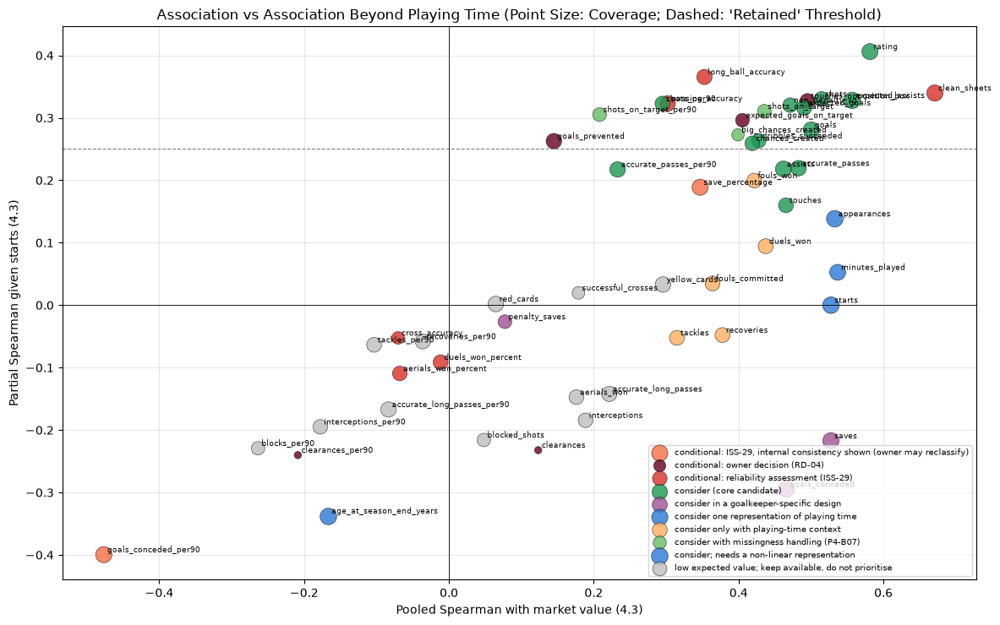

In [132]:
# Evidence behind the recommendations: pooled association vs association beyond playing time
rec_colors = {"consider (core candidate)": "#1a9850", "consider with missingness handling (P4-B07)": "#66bd63",
              "consider one representation of playing time": "#2a78d6", "consider; needs a non-linear representation": "#2a78d6",
              "consider in a goalkeeper-specific design": "#a05195", "consider only with playing-time context": "#fdae61",
              "low expected value; keep available, do not prioritise": "#bdbdbd",
              "conditional: reliability assessment (ISS-29)": "#d73027", "conditional: ISS-29, internal consistency shown (owner may reclassify)": "#f46d43",
              "conditional: owner decision (RD-04)": "#67001f"}
fig, ax = plt.subplots(figsize=(12, 7.5))
for r, sub in fa46.groupby("phase5_recommendation"):
    y = sub["partial_given_starts"].fillna(0)
    ax.scatter(sub["pooled_spearman"], y, s=(100 - sub["null_applicable_pct"]) * 2, color=rec_colors[r], alpha=0.8, label=r, edgecolors="black", linewidths=0.4)
for _, row in fa46.iterrows():
    ax.annotate(row["feature"].removeprefix("m_"), (row["pooled_spearman"], 0 if pd.isna(row["partial_given_starts"]) else row["partial_given_starts"]),
                fontsize=6.5, xytext=(3, 2), textcoords="offset points")
ax.axhline(0.25, color="grey", linestyle="--", linewidth=0.8)
ax.axhline(0, color="black", linewidth=0.6)
ax.axvline(0, color="black", linewidth=0.6)
ax.set_xlabel("Pooled Spearman with market value (4.3)")
ax.set_ylabel("Partial Spearman given starts (4.3)")
ax.set_title("Association vs Association Beyond Playing Time (Point Size: Coverage; Dashed: 'Retained' Threshold)")
ax.legend(fontsize=7, loc="lower right")
plt.tight_layout()
plt.show()

**Interpretation (RD-03 applies: associations describe co-occurrence with a mostly mid-season valuation)**

- **Core candidates for consideration (13):** goals, assists, shots, shots per 90, dribbles, xG, non-penalty xG, xA, accurate passes, accurate passes per 90, chances created, touches and rating. Their association is retained beyond playing time or persists among regular players. Most are highly redundant within their family (shots-xG cluster, xA-chances cluster). Choosing representations is therefore the main the modeling stage design task.
- **Playing time (3) and age (1):** the strongest axes of the population, but the three playing-time measures are near-duplicates, and age is non-monotonic. One playing-time representation and a non-linear age form are recommended for consideration.
- **With missingness handling (3):** shots on target and its rate, big chances created. Their signal is retained, but coverage is low (31-44% null), mostly where a zero would be expected (P4-B07).
- **Only with playing-time context (5):** tackles, recoveries, duels won, fouls committed, fouls won. Their pooled association is mostly playing time.
- **Low expected value (12):** most defensive rates, long passing, crosses and cards. They stay available, but nothing suggests they should be prioritised. Their negative partial associations (P4-B08) may reflect team context.
- **Goalkeeper-specific (3 plus 3 conditional):** saves, goals conceded and penalty saves; clean sheets, save percentage and goals conceded per 90 remain ISS-29 conditional. They are meaningful only in a goalkeeper design.
- **Conditional:** 5 RD-04 metrics (design decision) and 8 ISS-29 metrics. For two of them (save percentage, goals conceded per 90), internal consistency was shown in 4.5, so they may be reclassified. Nothing is reclassified here.

### C. Eligibility Review, Conditional and Excluded Features

The current repository classification (`phase4_feature_eligibility.csv`) is used as is. It is unchanged since step 8.0 (test `test_eligibility_file_unchanged`).

In [133]:
display(fea.eligibility_review(eligibility46, fa46))
display(fea.group_recommendations(fa46).set_index("group"))
sr46 = fea.status_role(df46)
display(sr46)
print("Constant status columns:", sr46.attrs["constant_status_columns"])

,columns,examples,phase_4_6_reading
subtype,,,
CANDIDATE_PREDICTOR,41,"age_at_season_end_years, position_group_season...",Candidates with warnings; assessed in the matr...
CONDITIONAL_PREDICTOR: owner decision (RD-04),5,"m_clearances, m_clearances_per90, m_expected_g...",Remain pending; 4.5 evidence summarised for th...
CONDITIONAL_PREDICTOR: owner decision (RS5-12),8,"confirmed_team_ids, confirmed_team_count, asso...",Remain pending; temporally ambiguous (4.5)
CONDITIONAL_PREDICTOR: reliability assessment (ISS-29),8,"m_aerials_won_percent, m_clean_sheets, m_cross...","Assessed in 4.5: 2 internally consistent, 6 un..."
EXCLUDED_PREDICTOR,3,"nationality_profile_present_day, m_key_passes,...","m_key_passes, s_key_passes, nationality_profil..."
IDENTITY_METADATA,33,"canonical_player_id, season, season_id, fotmob...",Never predictors (group keys and sensitivity g...
STATUS_MISSINGNESS,53,"missing_feature_count, s_accurate_long_passes,...",Not numeric performance features; possible rol...
TARGET,16,"target_market_value, target_currency, target_s...",Never predictors
TEMPORAL_AUDIT,8,"temporal_player_games_in_season, temporal_play...",Never predictors (audit only; see P4-D05)


,features,evidence,recommendation_for_phase5_consideration
group,,,
Playing time,"m_appearances, m_starts, m_minutes_played",Strongest grouping axis (4.4) and Spearman ~0....,Consider; choose one primary representation; s...
Age,age_at_season_end_years,Inverted U; interacts with playing time; -0.34...,Consider with a non-linear form; ISS-07 for 4 ...
Position context,position_group_season,Distinct sub-populations; metric meaning diffe...,Consider as context or for position-specific m...
Attacking output and xG,"m_goals, m_shots, m_shots_on_target, m_expecte...",Retained beyond playing time (partial 0.28-0.3...,Consider; resolve redundancy by design (totals...
Chance creation and xA,"m_assists, m_expected_assists, m_chances_creat...","xA 0.56 pooled, 0.33 given starts; xA/chances ...",Consider; big chances has 44% nulls
Passing quality,"m_accurate_passes_per90, m_passing_accuracy, m...",Retained for defenders (0.48-0.51); accuracy r...,Consider position-specifically; ISS-29 decisio...
Possession volume,"m_touches, m_accurate_passes, m_dribbles_succe...",Mostly playing time (touches 0.47 -> 0.16 give...,Consider only with playing-time context
Defensive actions,"m_tackles, m_interceptions, m_recoveries, m_bl...",Positive pooled associations are playing time;...,Low expected value as direct signals; possible...
Discipline and fouls,"m_yellow_cards, m_red_cards, m_fouls_committed...",Mostly playing time; fouls won retains 0.20,Low priority


,possible_role,basis,assessment,decision_needed
0,Interpret nulls in EDA and audits,"Distinguishes unavailable, not applicable, uns...",Used throughout Phase 4,none
1,Missingness indicators for preprocessing,"MISSING is informative (fringe players, lower ...",Possible; one indicator per metric family or p...,P4-D01 decision
2,Applicability masks,UNVERIFIED_POSITION marks GK-only metrics on o...,Possible for position-specific designs,"P4-D01, P4-B10"
3,Exclusion of unusable cells,CONFLICTING (36 cells) and UNSUPPORTED (key_pa...,Keep null; never zero,none
4,Numeric performance features,Statuses are categorical source codes,Not appropriate,n/a


Constant status columns: ['s_key_passes']


**Interpretation**

- **Classification (175 columns):** 41 candidate predictors with warnings; 8 conditional for a reliability assessment (ISS-29); 13 conditional for design decisions (5 RD-04, 8 RS5-12); 3 excluded; 16 target, 33 identity/metadata, 8 temporal-audit and 53 status/missingness columns. All counts match the step 8.0 register.
- **Explicitly excluded:** `m_key_passes` and `s_key_passes` (no source data on any row; ISS-28) and `nationality_profile_present_day` (a present-day profile value collected in November 2026, not a historical fact; P4-A04). Target, temporal-audit and identity columns are never predictors (P4-A03, P4-A05). Temporal-audit columns remain excluded even though they contain goalkeeper lineup minutes (P4-D05 is a design decision).
- **RD-04 (pending):** the 4.5 evidence differs per metric (`expected_goals_on_target` nearly verified; `touches_opposition_box` disagreeing before 2024/25; `clearances` effectively one season; `goals_prevented` weakly verified). The choice is left to the modeling design (section 8.7.F).
- **RS5-12 (pending):** club context is complete but temporally ambiguous and possibly a strong proxy.
- **Status columns:** not numeric performance features. Their most plausible future roles are missingness indicators (for example per metric family or for the "no detailed statistics" block) and applicability masks for position-specific designs. `s_key_passes` is constant. The role is decided in preprocessing design (P4-D01).

### D. Regression Feasibility

In [134]:
display(fea.target_feasibility(df46))
core46 = fa46.loc[fa46["phase5_recommendation"].eq("consider (core candidate)") & ~fa46["position_relevance"].eq("GK only"), "feature"].tolist()
display(fea.population_feasibility(df46, scope46).join(fea.complete_case(df46, core46)).round(2))
spread46 = fea.spread_vs_level(df46)
display(spread46.round(2))

,measure,value,note
0,usable targets,2697,
1,players with a usable target,1196,
2,distinct target values,84,"coarse, rounded valuations"
3,skewness raw / log10,2.31 / -0.84,log over-corrects slightly
4,max / median,15.4,heavy upper tail
5,share of total value in top 5% of rows,21.1%,raw-scale errors dominated by the tail
6,rows beyond 3 IQR (raw),32,genuine elite players (4.2)


,usable_rows,players,rows_per_player,target_median_eur,complete_case_core_outfield_pct
population,,,,,
all,2697,1196,2.26,13000000.0,78.28
GK,206,95,2.17,6000000.0,NaN
DEF,924,408,2.26,12000000.0,73.92
MID,817,387,2.11,15000000.0,81.76
FWD,750,355,2.11,15000000.0,79.87
2020/21,515,515,1.00,10000000.0,79.75
2021/22,528,528,1.00,10000000.0,79.22
2022/23,542,542,1.00,15000000.0,81.31
2023/24,567,567,1.00,13000000.0,76.09


n  median_eur     iqr_eur  p75_to_p25  iqr_log10
position_group_season starts_group                                                    
DEF                   0 starts       68   2350000.0   7500000.0       16.00       1.20
                      1-9 starts    243   7000000.0   9000000.0        4.00       0.60
                      10-18 starts  214  13000000.0  15000000.0        4.00       0.60
                      19-28 starts  214  17500000.0  22750000.0        4.14       0.62
                      29-38 starts  185  22000000.0  20000000.0        2.67       0.43
FWD                   0 starts      125   2500000.0   7000000.0        8.00       0.90
                      1-9 starts    200  11000000.0  13000000.0        3.60       0.56
                      10-18 starts  173  18000000.0  25000000.0        3.50       0.54
                      19-28 starts  151  25000000.0  34000000.0        3.27       0.51
                      29-38 starts  101  35000000.0  42000000.0        3.33       0.52
GK                    1-9 starts     75   2000000.0   5000000.0        6.00       0.78
                      29-38 starts   73  16000000.0  15000000.0        2.50       0.40
MID                   0 starts       82   2000000.0   6500000.0       14.00       1.15
                      1-9 starts    229   9000000.0  15000000.0        6.00       0.78
                      10-18 starts  176  15000000.0  18000000.0        3.57       0.55
                      19-28 starts  173  24000000.0  28000000.0        3.33       0.52
                      29-38 starts  157  30000000.0  38000000.0        3.24       0.51

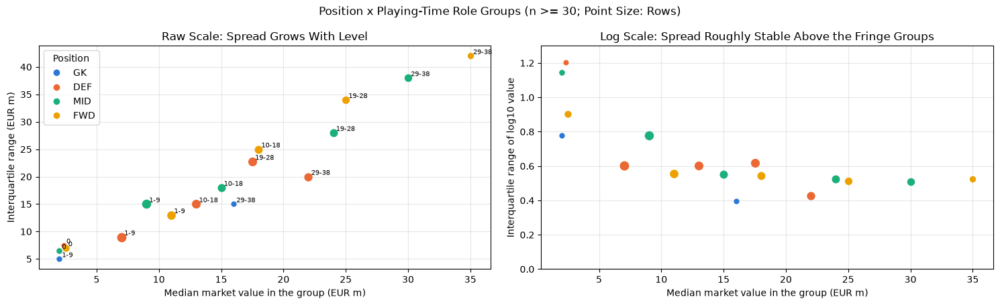

In [135]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for (pos, grp), r in spread46.iterrows():
    axes[0].scatter(r["median_eur"] / 1e6, r["iqr_eur"] / 1e6, color=POS_COLORS[pos], s=r["n"] / 3)
    axes[1].scatter(r["median_eur"] / 1e6, r["iqr_log10"], color=POS_COLORS[pos], s=r["n"] / 3)
    axes[0].annotate(grp.replace(" starts", ""), (r["median_eur"] / 1e6, r["iqr_eur"] / 1e6), fontsize=7, xytext=(3, 2), textcoords="offset points")
axes[0].set_xlabel("Median market value in the group (EUR m)")
axes[0].set_ylabel("Interquartile range (EUR m)")
axes[0].set_title("Raw Scale: Spread Grows With Level")
axes[1].set_xlabel("Median market value in the group (EUR m)")
axes[1].set_ylabel("Interquartile range of log10 value")
axes[1].set_title("Log Scale: Spread Roughly Stable Above the Fringe Groups")
axes[1].set_ylim(0, 1.3)
axes[0].legend(handles=[plt.Line2D([], [], marker="o", linestyle="", color=POS_COLORS[p], label=p) for p in prof.POSITION_ORDER], title="Position")
fig.suptitle("Position x Playing-Time Role Groups (n >= 30; Point Size: Rows)", fontsize=12)
plt.tight_layout()
plt.show()

**Interpretation: regression is feasible, with clear design constraints** (no model trained)

- **Size:** 2,697 usable targets from 1,196 players (2.3 rows per player). By position: 206 goalkeeper rows (95 players) and 750-924 rows per outfield position. With about 1,200 independent players, model complexity must stay moderate.
- **Target scale:** raw skew 2.31; the top 5% of rows hold 21% of total value; max/median 15. On the raw scale, squared-error fits and metrics would be dominated by elite players. On the log scale skew is -0.84, and the spread inside position x role groups is roughly constant (IQR of log10 0.40-0.78 for groups with >= 1 start, mostly 0.5-0.6), while the raw IQR grows with the level (EUR 5m to 42m). **Consideration for the modeling stage:** train on a log-transformed target, with raw-scale metrics reported for interpretation; compare with a raw-target baseline. The stored target is never changed.
- **Coarse target:** 84 distinct values (heaping). Error metrics should tolerate ties; rank metrics need care.
- **Irreducible spread:** even at fixed position and role, p75/p25 ratios are about 2.5-4 for regular players (6-16 for fringe groups). Performance features must explain value within these cells. A substantial part of value variation is not captured by playing time and position, and prediction will be imperfect.
- **Missingness:** a complete-case analysis on the 13 core candidates would keep 78% of usable outfield rows (74% of defenders), selectively dropping fringe players. A status-aware missingness plan is needed.
- **Heterogeneity:** positions differ in level, metric meaning and missingness; seasons differ in label timing and level (ISS-21, P4-B09). Options for the modeling stage to compare: a pooled model with position context and season-aware evaluation, and position-specific models (goalkeepers are likely too few for a separate complex model).
- **Temporal mismatch and identity:** both persist (RD-03, ISS-01). Every result needs the RD-03 statement and a P4-B01 sensitivity run.

### E. Split Strategy Assessment

Random row-level splitting is prohibited (RS5-11). The alternatives are assessed analytically; **no split is executed here**.

In [136]:
display(fea.player_structure(df46))
print("Analytic expectation for an 80/20 random row split:", fea.random_split_leakage(df46))
th46 = fea.temporal_holdout(df46, scope46)
display(th46.round(2))
display(fea.split_comparison().set_index("strategy").drop(columns="recommendation"))

,players,rows
seasons_per_player,,
1,517,517
2,241,482
3,191,573
4,110,440
5,137,685


Analytic expectation for an 80/20 random row split: {'test_share': 0.2, 'expected_test_rows_with_player_in_train_pct': 76.2352243233222, 'players_with_multiple_seasons': 679, 'rows_of_multi_season_players': 2180}


,test_season,train_seasons,train_rows,test_rows,test_rows_player_seen_in_train_pct,test_new_player_rows,train_target_median_eur,test_target_median_eur,test_median_valuation_age_days,clearances_coverage_train_pct,clearances_coverage_test_pct
0,2021/2022,1,515,528,65.34,183,10000000.0,10000000.0,150.0,0.00,6.25
1,2022/2023,2,1043,542,65.68,186,10000000.0,15000000.0,206.0,3.16,0.00
2,2023/2024,3,1585,567,69.31,174,12000000.0,13000000.0,152.0,2.08,8.99
3,2024/2025,4,2152,545,74.68,138,12000000.0,17000000.0,160.0,3.90,81.28


,definition,properties,requirements
strategy,,,
Random row split,Not allowed (RS5-11),Same player in train and test; inflated scores,-
"Grouped by player (K-fold, players kept together)",Every player-season belongs to one fold,No identity leakage; uses all five seasons; fo...,Stratify or report by season and position; rep...
"Temporal hold-out (train earlier seasons, test 2024/25)","Train 2020/21-2023/24, test 2024/25",Matches the use case 'estimate this season's v...,Report returning and new players separately; c...
Rolling origin (expanding window),Test 2021/22 ... 2024/25 in turn with earlier ...,Several temporal estimates; first folds are sm...,Use if temporal stability matters
Combined grouped + temporal,Temporal hold-out where test players are remov...,Strictest; smallest training set; answers 'new...,Owner choice


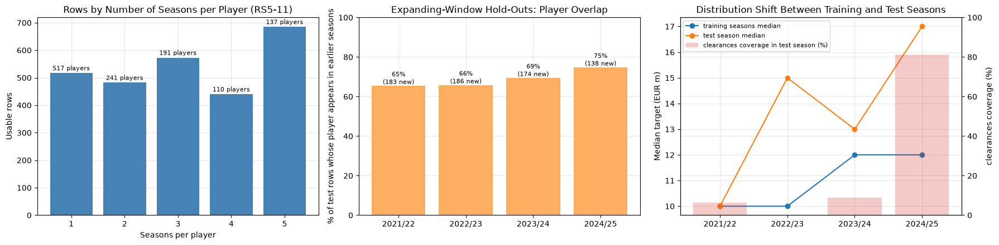

In [137]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
ps = fea.player_structure(df46)
axes[0].bar(ps.index.astype(str), ps["rows"], color=COLOR)
for x, (n_p, n_r) in enumerate(zip(ps["players"], ps["rows"])):
    axes[0].text(x, n_r + 10, f"{n_p} players", ha="center", fontsize=8)
axes[0].set_xlabel("Seasons per player")
axes[0].set_ylabel("Usable rows")
axes[0].set_title("Rows by Number of Seasons per Player (RS5-11)")
x = np.arange(len(th46))
axes[1].bar(x, th46["test_rows_player_seen_in_train_pct"], color="#fdae61")
for i, (v, n) in enumerate(zip(th46["test_rows_player_seen_in_train_pct"], th46["test_new_player_rows"])):
    axes[1].text(i, v + 1, f"{v:.0f}%\n({n} new)", ha="center", fontsize=8)
axes[1].set_xticks(x, [prof.short(s) for s in th46["test_season"]])
axes[1].set_ylim(0, 100)
axes[1].set_ylabel("% of test rows whose player appears in earlier seasons")
axes[1].set_title("Expanding-Window Hold-Outs: Player Overlap")
axes[2].plot([prof.short(s) for s in th46["test_season"]], th46["train_target_median_eur"] / 1e6, marker="o", label="training seasons median")
axes[2].plot([prof.short(s) for s in th46["test_season"]], th46["test_target_median_eur"] / 1e6, marker="o", label="test season median")
ax2 = axes[2].twinx()
ax2.bar(x, th46["clearances_coverage_test_pct"], alpha=0.25, color="#d73027", label="clearances coverage in test season (%)")
ax2.set_ylim(0, 100)
ax2.set_ylabel("clearances coverage (%)")
axes[2].set_ylabel("Median target (EUR m)")
axes[2].set_title("Distribution Shift Between Training and Test Seasons")
h1, l1 = axes[2].get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
axes[2].legend(h1 + h2, l1 + l2, fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

**Interpretation and recommendation (P4-D02)**

- **Random row split (rejected):** 679 of the 1,196 players with a target appear in 2+ seasons (2,180 of 2,697 rows). Under an 80/20 random row split, about **76%** of test rows would belong to a player who also has training rows. Scores would be inflated by player identity.
- **Grouped by player (recommended primary):** keeps all of a player's seasons in one fold. It uses all five seasons and gives several folds for uncertainty. Its limitation: every fold mixes the season batches, so batch effects are shared between training and test. Results should therefore be reported per season and per position, with an identity-sensitivity (P4-B01) run.
- **Temporal evaluation (recommended supplementary):** an expanding window (train on earlier seasons, test on the next one) matches the use case "estimate this season's values from past seasons". It shows real shift: in 2024/25 the median target is EUR 17m vs 12m in earlier seasons, the label batch differs, and `clearances` jumps from 3.9% to 81% coverage (RD-04). 74.7% of 2024/25 rows belong to players seen in earlier seasons, so returning and new players must be reported separately.
- **Final test:** every development season is used by the EDA and by cross-validation, so none of them can serve as a clean final test. The final test is therefore a separate season, **2025/26**, which is not used for any analysis or design choice and is scored once (section 13).
- **Rule for every strategy:** never use information from a later season to evaluate an earlier one. Preprocessing statistics (for example scaling or imputation, if any) must be fitted on training folds only.

### F. Modeling Risk Register

In [138]:
risks46 = fea.risk_register()
display(risks46.set_index("id"))
display(risks46.groupby(["severity", "owner_approval_required"]).size().rename("risks").to_frame())

,risk,evidence,severity,affected,potential_impact,mitigation,owner_approval_required,phase5_action
id,,,,,,,,
R01,Identity leakage through repeated players,687 players in 2+ seasons; an 80/20 random row...,High,All,Inflated evaluation,Grouped-by-player and/or temporal split; never...,No,Fix split before any evaluation (P4-D02)
R02,Temporal construct mismatch,Mostly mid-season label; 44% of appearances af...,High,All m_*,Weaker label-feature correspondence; misleadin...,Report RD-03; season-aware evaluation; keep D4...,Yes (RD-03 decision),State in every result
R03,Season batch effects and level shift,Valuation age 66-206 days by season; medians 1...,High,Target,Season-dependent bias; poor temporal generalis...,Season-aware evaluation and reporting; do not ...,No,Evaluation design
R04,"Heavy-tailed, coarse target",Skew 2.31; 32 rows beyond 3 IQR; 84 distinct v...,High,Target,Raw-scale losses dominated by elite players,Consider log-scale training with raw-scale rep...,No,Target transformation decision
R05,"Informative, non-random missingness",Fringe rows 72% MISSING; null rows lower-value...,High,Count and rate metrics,Biased complete-case models; wrong zero-fill,Status-aware missingness plan; no blind imputa...,No,Preprocessing design (P4-D01)
R06,Playing-time confounding and redundancy,Most volume associations vanish given starts; ...,Medium,Volume totals,"Unstable coefficients, spurious importance",Choose representations deliberately; check mul...,No,Feature design (P4-D03)
R07,Position heterogeneity,Different levels and metric meanings; GK 206 rows,Medium,All,Pooled model fits outfield; poor GK estimates,Position context or position-specific models; ...,No,Model design
R08,Goalkeeper data limits,Minutes 7/206; outfield metrics MISSING; ~40 G...,Medium,GK metrics,Unstable GK estimates,GK-specific handling; P4-D05 decision on lineu...,Yes (P4-D05),Feature design
R09,Identity mappings not human-validated,Lower bound 98.73% (< 99% SOP); 533 P4-B01 row...,Medium,Target,Small wrong-target risk; fringe sensitivity,P4-B01 sensitivity run for every result; owner...,Yes (labels),Before final results


risks
severity owner_approval_required       
High     No                           4
         Yes (RD-03 decision)         1
Low      No                           2
         Yes (P4-D03)                 1
         Yes (RD-01)                  1
Medium   No                           4
         Yes (P4-B05)                 1
         Yes (P4-D05)                 1
         Yes (RD-04)                  1
         Yes (RS5-12)                 1
         Yes (labels)                 1

**Interpretation**

- Five **high-severity** risks: repeated players (R01), the temporal construct mismatch (R02), season batch effects (R03), the heavy-tailed coarse target (R04) and informative missingness (R05). All can be mitigated by design choices (grouped and temporal evaluation, log-scale consideration, status-aware missingness), but none disappears.
- **Design decisions** are attached to RD-03, P4-D05, ISS-01, RD-04, RS5-12, P4-D03 (ISS-29 reclassification), P4-B05 and RD-01. No issue was closed in this phase.

### G. Recommendations for the modeling stage (Feasibility Only)

```text
the modeling stage entry
   |
   |-- Design decisions first ....... RD-04, RS5-12, P4-D05, P4-B05, ISS-29 reclassification (P4-D03), RD-03 confirmation, RD-01
   |-- Split design (P4-D02) ........ grouped-by-player K-fold (primary) + expanding window (supplementary); never random rows
   |-- Final test ................... a separate, untouched season (2025/26), scored once
   |-- Target scale ................. compare log-scale training (raw-scale reporting) with a raw baseline; stored target unchanged
   |-- Missingness plan (P4-D01) .... status-aware; no blind zero-fill; indicator or block handling; fit on training folds only
   |-- Feature representation ....... one playing-time measure; non-linear age; resolve shots-xG and xA-chances redundancy
   |-- Population design ............ pooled model with position context vs position-specific; goalkeepers handled separately
   |-- Reporting .................... per position, per season, returning vs new players, P4-B01 sensitivity, RD-03 statement
```

1. Resolve each pending design decision above (answered in section 8.7.F).
2. Fix the evaluation design before training anything.
3. Build preprocessing and features only inside the approved design (the modeling stage), with the eligibility register as the hard boundary.
4. Keep elite tails, never zero-fill, never filter by staleness without approval.

### H. Limitations

- The assessment rests on descriptive evidence. A feature's usefulness inside a multivariate model may differ from its bivariate and grouped associations.
- Two dimensions (interpretability, usefulness) involve judgment. Their rules are explicit, but other reasonable rules would move borderline features between categories.
- Thresholds (for example 0.25 for "retained", 0.3 among regulars) were set before reading the matrix; they are not tuned.
- Split feasibility is analytic; fold balance and variance will only be known when the split is designed in the modeling stage.
- RD-03, ISS-01, ISS-21 and the other open conditions apply unchanged.

### I. Step 8.6 Conclusion

A regression study is **feasible but conditional**. The data support it in size (2,697 targets, 1,196 players), in feature reliability (most features verified over five seasons) and in signal: attacking output, creation, passing quality and rating are associated with value beyond playing time. The study must however be designed around:
- repeated players (grouped and temporal evaluation, never random rows);
- a heavy-tailed target (log-scale consideration);
- informative missingness (a status-aware plan);
- strong redundancy and playing-time confounding (deliberate representations);
- position heterogeneity (goalkeepers in particular);
- season batch effects;
- the temporal construct mismatch.

Thirteen features are core candidates for consideration, four form the playing-time and age axes, and eleven are position- or context-dependent. Twelve have low expected value, and thirteen remain conditional pending design decision. No feature was selected or engineered, no model was trained, and no split was executed.

**Gate G4.6:** see `reports/phase_04/step_06/PHASE4_06_ACCEPTANCE_REPORT.md`.

---

## 8.7 EDA Synthesis

Objective:
Review the EDA as a whole: check that the findings are consistent and supported by evidence, that the research constraints held, that limitations are documented, and what the EDA hands over to the modeling stage.

This section changes no data and no earlier result.

### A. EDA Summary

| Step | Question answered | Gate | Main deliverables |
|---|---|---|---|
| 8.0 | Is the official dataset acceptable for EDA, under which conditions? | CONDITIONAL PASS | Condition register, eligibility register, entry checklist |
| 8.1 | What does the dataset contain, and is it structurally sound? | PASS | Profiling, population and structural quality reports |
| 8.2 | How are the target and each feature distributed? | PASS | Target and univariate reports |
| 8.3 | How do features relate to the target and to each other? | PASS | Bivariate report, correlation matrices, association and redundancy summaries |
| 8.4 | How heterogeneous is the population across positions, seasons and groups? | PASS | Multivariate, position, season and group reports |
| 8.5 | How trustworthy are the observations (missingness, timing, identity, sources)? | PASS | Missingness, temporal, identity and metric reliability reports |
| 8.6 | Which features are promising, and is regression feasible? | PASS | Feature assessment matrix, feasibility, split assessment, risk register |
| 8.7 | Is the EDA complete, consistent, and what does it hand over to modeling? | see section F | Final acceptance report, issue tracker, this synthesis |

```text
Data collection (FotMob, Transfermarkt)  ->  integration and five-season release (rs5_v1, CONDITIONAL)
   ->  8.0 acceptance and conditions  ->  8.1 structure  ->  8.2 distributions  ->  8.3 relationships
   ->  8.4 groups and heterogeneity  ->  8.5 reliability  ->  8.6 feasibility  ->  8.7 synthesis  ->  09-13 modeling and holdout test
```

### B. Verification and Cross-Phase Consistency

The checks below recompute key statistics from the official dataset and compare them with the evidence recorded by each sub-phase. Code: `src/phase4/synthesis.py`.

In [139]:
from src.phase4 import synthesis as syn

df47, schema47, scope47, verification47 = prof.load_verified()
print("SHA-256 verified:", verification47["sha256"] == prof.DATASET_SHA256)
print("Seasons (load_scope):", [prof.short(s) for s in scope47.labels], "| excluded:", list(scope47.excluded_labels))
print("Rows of an excluded season in the dataset:", int(df47["season"].isin(scope47.excluded_labels).sum()))
cons47 = syn.consistency_checks(df47)
display(cons47.set_index("check").dropna(axis=1, how="all"))
print("All cross-phase checks consistent:", bool(cons47["consistent"].all()))
display(syn.definitional_differences().set_index("topic"))

SHA-256 verified: True
Seasons (load_scope): ['2020/21', '2021/22', '2022/23', '2023/24', '2024/25'] | excluded: ['2019/2020']
Rows of an excluded season in the dataset: 0


,value_4.0,value_4.3,value_4.4,value_fresh,consistent,note,value_4.2,value_4.6,value_4.1,value_4.5,value_4.3 vs 4.6,value_4.3 vs 4.5
check,,,,,,,,,,,,
Rows,2747.0,2747.0,2747.0,2747.0,True,,NaN,NaN,NaN,NaN,NaN,NaN
Usable targets,2697.0,2697.0,2697.0,2697.0,True,,2697.0,2697,NaN,NaN,NaN,NaN
Players,1228.0,NaN,NaN,1228.0,True,,NaN,NaN,NaN,NaN,NaN,NaN
Target median (EUR),13000000.0,NaN,NaN,13000000.0,True,,13000000.0,NaN,NaN,NaN,NaN,NaN
Null metric cells,48043.0,NaN,NaN,48043.0,True,,NaN,NaN,48043.0,48043.0,NaN,NaN
P4-B01 rows,533.0,533.0,NaN,533.0,True,,NaN,NaN,NaN,533.0,NaN,NaN
Median valuation age (days),150.0,NaN,NaN,150.0,True,,NaN,NaN,NaN,150.0,NaN,NaN
Appearances after valuation (%),44.1,NaN,NaN,NaN,True,,NaN,NaN,NaN,44.1,NaN,NaN
Multi-season players (all rows),687.0,NaN,NaN,687.0,True,4.6 reports 679 players for usable-target rows...,NaN,NaN,NaN,NaN,NaN,NaN


All cross-phase checks consistent: True


,source_a,source_b,explanation
topic,,,
Limited-coverage features,4.2: 21 (> 20% null on applicable rows or a se...,"4.5: 15 in class 'reliable values, limited cov...",Different definitions
Multi-season players,"4.0/4.1: 687 players, 2,206 rows (all rows)","4.6: 679 players, 2,180 rows (rows with a usab...",Different populations
Players,"4.0/4.1: 1,228 (all rows)","4.3/4.6: 1,196 (rows with a usable target)",Different populations
Rows without detailed statistics,4.2: 317 outfield rows with minutes but no det...,"4.5: 317 outfield rows with 0 starts, all with...","Same rows, two descriptions"
Association labels,4.3: strength from |Spearman| plus a bootstrap...,4.6: strength from |Spearman| only ('none' bel...,Different rules; both give 9 strong; weak/none...


In [140]:
# Research-integrity checks
print("Excluded-season strings in Phase 4.1-4.6 evidence tables:", len(syn.scope_scan()))
display(syn.predictor_integrity().set_index("set"))
elig47 = syn.eligibility_rebuild()
print("Eligibility register rebuilt by its Phase 4.0 script, byte-identical:", elig47["identical"])
print("Eligibility categories:", elig47["category_counts"])

Excluded-season strings in Phase 4.1-4.6 evidence tables: 0


,columns,forbidden,club_context,rd04_recommended,ok
set,,,,,
analysed predictors (4.2-4.6),53,,,,True
recommended for consideration (4.6),28,,,,True


Eligibility register rebuilt by its Phase 4.0 script, byte-identical: True
Eligibility categories: {'STATUS_MISSINGNESS': 53, 'CANDIDATE_PREDICTOR': 41, 'IDENTITY_METADATA': 33, 'CONDITIONAL_PREDICTOR': 21, 'TARGET': 16, 'TEMPORAL_AUDIT': 8, 'EXCLUDED_PREDICTOR': 3}


**Interpretation**

- **Consistency:** rows (2,747), usable targets (2,697), players (1,228), the target median (EUR 13m), null metric cells (48,043), P4-B01 rows (533), RD-03 timing, goalkeeper rows, position and season medians, all 53 pooled Spearman values and all identity-sensitivity differences agree across the sub-phases and with a fresh recomputation.
- **Different numbers that are not contradictions** come from different definitions or populations: 687 vs 679 multi-season players (all rows vs rows with a target), 1,228 vs 1,196 players, 21 vs 15 "limited coverage" features (4.2 counts every feature; 4.5 gives RD-04 and ISS-29 features their own classes).
- **Integrity:** no excluded-season string occurs in any the EDA evidence table; no target, temporal, identity, provenance, status, club-context or present-day nationality column was analysed as a predictor or recommended; no RD-04 metric was recommended; the eligibility register is byte-identical to a fresh rebuild from its step 8.0 script, so no classification was changed silently.
- **Review correction made in 4.7:** a step 8.6 test compared the eligibility file with itself. It now rebuilds the register and compares bytes. The 4.6 notebook table that printed 29 KB of text now shows five columns; the full matrix remains in the evidence and the figure.

### C. Main Findings Across the EDA

**Dataset quality.** The dataset is structurally sound: a unique key, valid types and domains, five balanced seasons (524-570 rows) and no excluded-season rows. Status and value agree on all 145,591 metric cells, and the observation window is verified for most metrics in all seasons. Its limits are structural rather than errors (sections D-E).

**Target.** The target is strongly right-skewed (median EUR 13m, mean 19.3m, max 200m), coarse (84 distinct values) and heavy-tailed with genuine elite players, compact on a log scale. Its level depends on position (GK lowest), on playing time and on season. Season differences mix market movement, population turnover and valuation batch timing.

**Features and relationships.**
- Playing time is the dominant axis (Spearman about 0.53; median EUR 2.35m with 0 starts vs EUR 25m with 29-38 starts).
- Beyond playing time, attacking output, chance creation, passing quality and rating stay associated with value (partial about 0.25-0.41). Among regular players, shot rates and age matter more.
- Defensive and goalkeeper volumes reverse once playing time is fixed, plausibly a team effect that cannot be tested while club context is pending.
- Age has an inverted U and interacts with playing time.
- Features are highly redundant: 54 strong pairs and four clusters.

**Population heterogeneity.** Positions are distinct sub-populations with different metric meanings. Goalkeepers form a separate population. Fringe players carry most nulls and the highest identity-sensitivity share.

All relationships are descriptive associations with a mostly mid-season valuation (RD-03), not causal effects.

### D. Missingness and Temporal Limitations

| Limitation | Size | Consequence |
|---|---|---|
| Informative missingness (ISS-27, ISS-25, P4-B07) | 33.0% of metric cells null; 72% `MISSING` for 0-start outfield rows vs 4% for core players | Complete-case analysis would drop fringe players; null is never zero |
| Status coding on GK rows (P4-B10) | Outfield metrics `MISSING` on GK rows; GK minutes metric 7/206 | GK nulls are "not recorded", not unknown performance; P4-D05 decision |
| Temporal construct mismatch (RD-03) | Median valuation 150 days before season end; 44.10% of appearances and 43.66% of minutes after it; 25-55% by season | Weaker label-feature correspondence; target tracks earlier minutes (0.52 vs 0.38) |
| Valuation batches (ISS-21, ISS-22) | One date holds 53-93% of a season's targets; median age 66-206 days | Season comparisons confounded; any staleness filter would change the season mix |
| Old labels (RD-01) | 12 targets > 365 days | Weak labels, kept |
| Identity (ISS-01, P4-B01) | No human validation; 533 sensitivity rows, lower-valued | Relationships robust (median change 0.016), fringe levels sensitive |
| Metric drift (P4-B09) | Recoveries/90 -23%, interceptions/90 -29% among regulars | Season-aware evaluation |
| RD-04 and club context (RS5-12) | 5 metrics with incomplete evidence; club context temporally ambiguous | Pending design decision |

### E. Feature Assessment and Modeling Feasibility

- **For consideration in the modeling stage (not a selection):**
  - 13 core candidates: goals, assists, shots, shots per 90, dribbles, xG, non-penalty xG, xA, accurate passes, accurate passes per 90, chances created, touches, rating;
  - one playing-time representation and a non-linear age term;
  - position context, with goalkeepers handled separately.
- **Conditional:** 5 RD-04 metrics, 8 ISS-29 metrics (2 internally consistent), 8 club-context columns. **Excluded:** `key_passes` (both columns) and present-day nationality.
- **Feasibility:** regression is feasible but conditional. The modeling stage should consider:
  - log-scale training with raw-scale reporting;
  - status-aware missingness handling;
  - deliberate representations against redundancy;
  - grouped-by-player K-fold as the primary evaluation, an expanding window as the supplementary one, and a separate untouched season for the final test (never random rows; about 76% identity leakage otherwise);
  - per-position, per-season and P4-B01 sensitivity reporting.
- **Risks:** 18 registered (5 high). None is closed.

Conditions: 55; resolved: 8; open: 47
Conditions open at the end of the EDA that needed a design decision (answered in the table below):


,title,classification,blocks_final_modeling,target_phase
id,,,,
RD-03,Temporal construct mismatch (also ISS-02),B,False,4.1 onward (interpretation); decision before f...
ISS-01,Identity mappings not human-validated,B,True,Before final modeling dataset acceptance
ISS-22,Staleness filters change the season mix,B,False,Only if a filter is proposed
RD-01,Targets older than 365 days,B,True,Decision recorded before final modeling dataset
RD-04,Five features with incomplete window evidence,C,True,Before feature selection / final modeling
RS5-12,Club context usage,C,True,Before feature selection / final modeling
RD-02,Two inconclusive RULE adjudications (El Mohama...,C,True,Decision recorded before final modeling dataset
ISS-04,Two unresolved identities,C,False,Any time; a resolution needs a new version
P4-D03,Final feature inclusion,D,True,Before final modeling


Conditions open at the end of the EDA that had to be settled before final modeling:


,title,owner_approval_required,target_phase
id,,,
RS5-11,No random row-level split as an evaluation str...,False,Before model evaluation
ISS-01,Identity mappings not human-validated,True,Before final modeling dataset acceptance
P4-B01,Identity sensitivity,False,Before final results
ISS-27,Missingness is not random,False,Plan before preprocessing
ISS-25,"A null may mean ""no event""",False,Before preprocessing
RD-01,Targets older than 365 days,True,Decision recorded before final modeling dataset
RD-04,Five features with incomplete window evidence,True,Before feature selection / final modeling
RS5-12,Club context usage,True,Before feature selection / final modeling
RD-02,Two inconclusive RULE adjudications (El Mohama...,True,Decision recorded before final modeling dataset


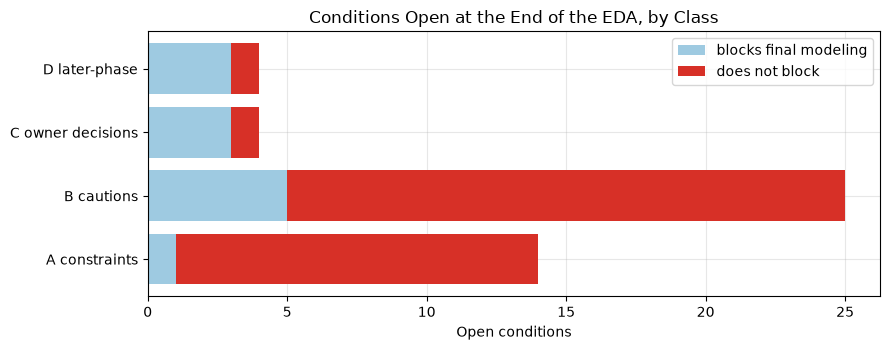

In [141]:
import yaml
register47 = yaml.safe_load((ROOT / "reports/phase_04/step_00/phase4_condition_register.yaml").read_text(encoding="utf-8"))["conditions"]
reg47 = pd.DataFrame(register47)
reg47["state"] = np.where(reg47.get("status").isna(), "OPEN", "RESOLVED")
open47 = reg47[reg47["state"].eq("OPEN")]
print(f"Conditions: {len(reg47)}; resolved: {int((reg47['state'] == 'RESOLVED').sum())}; open: {len(open47)}")
owner47 = open47[open47["owner_approval_required"].eq(True)][["id", "title", "classification", "blocks_final_modeling", "target_phase"]]
print("Conditions open at the end of the EDA that needed a design decision (answered in the table below):")
display(owner47.set_index("id"))
print("Conditions open at the end of the EDA that had to be settled before final modeling:")
display(open47[open47["blocks_final_modeling"].eq(True)][["id", "title", "owner_approval_required", "target_phase"]].set_index("id"))

fig, ax = plt.subplots(figsize=(9, 3.6))
tab = pd.crosstab(open47["classification"], open47["blocks_final_modeling"].map({True: "blocks final modeling", False: "does not block"}))
tab = tab.reindex(["A", "B", "C", "D"]).fillna(0)
left = np.zeros(len(tab))
for col, color in zip(tab.columns, ["#9ecae1", "#d73027"]):
    ax.barh(["A constraints", "B cautions", "C owner decisions", "D later-phase"], tab[col], left=left, color=color, label=col)
    left += tab[col].to_numpy()
ax.set_xlabel("Open conditions")
ax.set_title("Conditions Open at the End of the EDA, by Class")
ax.legend()
plt.tight_layout()
plt.show()

### F. From EDA to Modeling: How Each Open Question Was Answered

The EDA left a set of questions open on purpose: it describes, it does not choose. The modeling design (sections 09 and 10) answers each of them before any model is trained.

| EDA question | Answer in the modeling design | Section |
|---|---|---|
| Population: goalkeepers are a distinct sub-population with no minutes metric (P4-D05) | Model **outfield players only** (DEF, MID, FWD); 206 goalkeeper rows stay in the dataset, counted as excluded | 09.A |
| Target scale: raw skew 2.31, heavy tail | Model `ln(EUR)`; nothing capped or removed | 09.B |
| Prior information: value level is persistent across seasons | Value at the **start** of the season (latest valuation strictly before the first match) as a feature, with a flag for players without one | 09.C |
| Redundancy (P4-D03): four clusters of near-duplicate features | One representative per cluster, chosen by hand; volumes as per-90 rates | 09.D |
| RD-04 (5 metrics), RS5-12 (club context), `key_passes`, defensive and discipline groups | Excluded from the features | 09.D |
| ISS-29 (source-reported rates) | Two passing-accuracy rates kept, reported as a risk | 09.D |
| Missingness (P4-D01, ISS-25, ISS-27) | No imputation, no zero-fill, no `s_*` status features; LightGBM handles nulls natively | 09.E |
| Per-90 instability at low minutes (P4-B05) | No minimum-minutes filter; errors reported for under / over 900 minutes | 09.F, 12 |
| Season batch effects (ISS-21) | Season is **not** a feature; results reported per season | 09.D, 11 |
| Split (P4-D02), repeated players (RS5-11) | Repeated StratifiedGroupKFold by player (primary), expanding window (supplementary) | 10 |
| Identity precision (ISS-01) and sensitivity (P4-B01) | Human labelling (0 wrong); sensitivity run without the identity-sensitive rows | 05.B, 11 |
| Label timing (RD-03) | Rule D4 kept; every result read as end-of-season estimation, not forecast | 14 |

**Known limitations carried into modeling:** the mostly mid-season label (RD-03) and season batches (ISS-21), informative missingness, source-reported rates, metric drift, retrospective collection (RS5-13), internal academic use only (ISS-16).

### G. EDA Conclusion

The EDA tells a coherent story, from the collected and integrated data, through its structure, distributions, relationships, heterogeneity and reliability, to a feasibility assessment for modeling. Every number in it is traceable to code and recorded evidence that agree with each other and with the development dataset.

Its main messages for modeling:
1. The target is heavy-tailed: model it on the log scale.
2. Rows are not independent (repeated players): never split rows at random.
3. Playing time, age and position structure everything; goalkeepers are a separate population.
4. Many features are redundant; missing values are informative and must not be filled with zero.
5. The label is mostly a mid-season valuation: results are associations, not causes.

**Acceptance evidence:** `reports/phase_04/step_07/PHASE4_FINAL_ACCEPTANCE_REPORT.md`.

---

# 09. Data Preprocessing & Feature Engineering

Objective:
Turn the development dataset into a model input, following the answers given to the EDA questions (section 8.7.F).

Everything in this section is fixed in one configuration file, `configs/phase_05_model.yaml` (`phase5_model_v1`), **before any model result was seen**. The code is `src/phase5/season_start_prev_value.py` and `src/phase5/features.py`; the model input is a new file, and the development release is never changed.

Workflow:

```text
Development dataset (2,747 rows)
        |
        v
A. Population: outfield players with a usable target
        |
        v
B. Target: ln(EUR)
        |
        v
C. Previous value: latest valuation before the season's first match
        |
        v
D. Features: 19 columns (one representative per redundant cluster, per-90 rates)
        |
        v
E. Missing values: kept as null (no imputation)
        |
        v
Model input (2,491 rows x 19 features)
```

## A. Modeling Population

Rules:
- Keep rows with a usable target (`target_usable`).
- Keep outfield players only (`position_group_season` in DEF, MID, FWD). Goalkeepers have no minutes metric and most outfield metrics do not apply to them (EDA 8.4, 8.5); with 206 rows they are too few for a separate model.
- Remove nothing else: no minimum-minutes rule, no outlier removal, no staleness filter.

In [142]:
from src.phase5 import features as fx
from src.phase5 import train_eval as te

CFG5 = fx.load_config()
FEATURES = fx.feature_columns(CFG5)

# Verify the model input before reading it
MODEL_INPUT = ROOT / "data/phase_05/features/model_input_v1/model_input.parquet"
mi_manifest = read_json("data/phase_05/features/model_input_v1/manifest.json")
assert sha256_file(MODEL_INPUT) == mi_manifest["output_sha256"], "Model input changed"
assert mi_manifest["inputs"]["release_sha256"] == OFFICIAL_SHA256, "Model input not built from the official release"
dev = pd.read_parquet(MODEL_INPUT).sort_values(fx.KEY).reset_index(drop=True)
print("Config:", CFG5["config_version"], "| model input SHA-256 verified")

usable_all = df[df["target_usable"]]
population = pd.DataFrame({
    "usable rows in dataset": usable_all["position_group_season"].value_counts(),
    "rows in model": dev["position_group_season"].value_counts(),
}).reindex(["GK", "DEF", "MID", "FWD"]).fillna(0).astype(int)
population.loc["Total"] = population.sum()
display(population)
print("Model rows:", len(dev), "| players:", dev["canonical_player_id"].nunique(),
      "| goalkeeper rows excluded (kept in the dataset):", int(population.loc["GK", "usable rows in dataset"]))

Config: phase5_model_v1 | model input SHA-256 verified


,usable rows in dataset,rows in model
position_group_season,,
GK,206,0
DEF,924,924
MID,817,817
FWD,750,750
Total,2697,2491


Model rows: 2491 | players: 1101 | goalkeeper rows excluded (kept in the dataset): 206


**Interpretation**

- The model covers **2,491 outfield player-seasons of 1,101 players**. The 206 goalkeeper rows stay in the dataset and are reported as excluded; every conclusion below applies to outfield players only.
- 49 players change position group between seasons; each row keeps the position of its own season.

## B. Target Transformation

The EDA showed a heavy right tail (raw skew 2.31). On the raw scale, an error of EUR 5m means little for a EUR 80m player and a lot for a EUR 2m player, and squared errors would be dominated by a few elite players.

Transformation: `log_target = ln(target_market_value)`. Errors on this scale are **relative errors**: a prediction that is 30% too high has the same error for a cheap and an expensive player. Nothing is capped or removed.

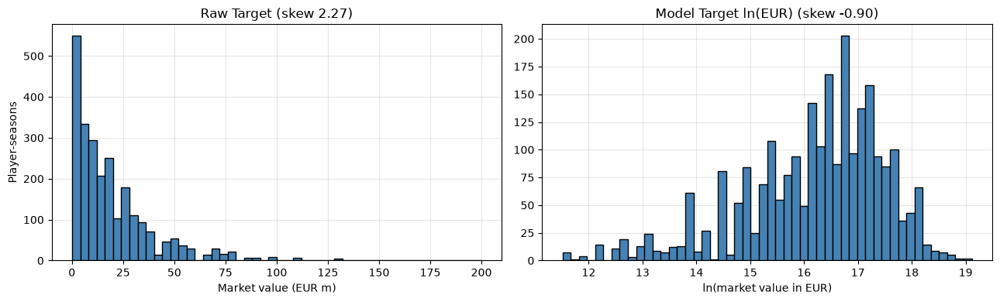

In [143]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(dev["target_market_value"] / 1e6, bins=50, color=COLOR, edgecolor="black")
axes[0].set_title(f"Raw Target (skew {dev['target_market_value'].skew():.2f})")
axes[0].set_xlabel("Market value (EUR m)")
axes[0].set_ylabel("Player-seasons")
axes[1].hist(dev["log_target"], bins=50, color=COLOR, edgecolor="black")
axes[1].set_title(f"Model Target ln(EUR) (skew {dev['log_target'].skew():.2f})")
axes[1].set_xlabel("ln(market value in EUR)")
plt.tight_layout()
plt.show()

**Interpretation**

- On the log scale the distribution is compact and only mildly skewed, so no single group of players dominates the loss.
- Predictions are made in `ln(EUR)` and can be turned back into euros with `exp()`. MdAPE (section 10.D) is computed in euros.

## C. Feature Engineering: Previous Value

Hypothesis:
A player's market value is persistent: the best single guess for the value at the end of a season is the value at its start. Performance during the season then explains how much the value **changes**.

Definition (rule `latest_valid_strictly_before_first_match_v1`):
- the latest valid Transfermarkt valuation dated **strictly before the season's first match** (official dates in `configs/phase_03_seasons.yaml`);
- `log_prev_value = ln(previous value)`, and a flag `has_prev_value`.

Why not the "previous valuation" already in the dataset? It is usually a **mid-season** valuation (median 98-198 days before the target, depending on the season), so it already reflects part of the season that the features describe. A season-start value avoids this overlap.

No-overlap check: previous valuation strictly before the first match on every row: True


,rows,with_previous_value,median_age_at_first_match_days,without_previous_value
season,,,,
2020/21,474,447,157.0,27
2021/22,486,467,66.0,19
2022/23,503,485,51.0,18
2023/24,527,494,52.0,33
2024/25,501,491,81.0,10


Rows whose target is dated before the season start (kept, reported separately): 15


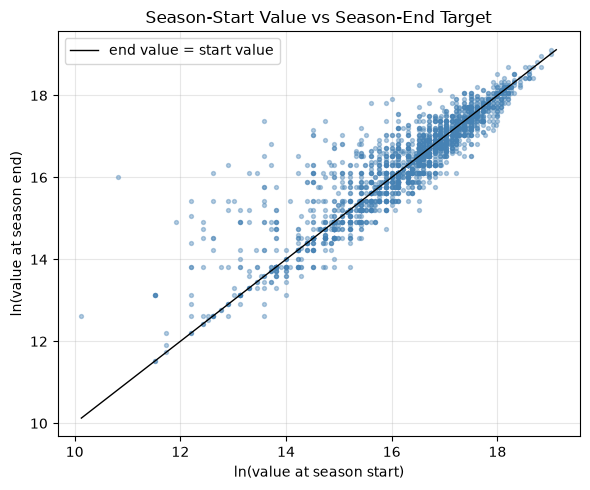

In [144]:
PREV_FILE = ROOT / "data/phase_05/previous_value/season_start_prev_value_v1/season_start_prev_value.parquet"
prev_manifest = read_json("data/phase_05/previous_value/season_start_prev_value_v1/manifest.json")
assert sha256_file(PREV_FILE) == prev_manifest["output_sha256"], "Previous-value table changed"
prev = dev[fx.KEY].merge(pd.read_parquet(PREV_FILE), on=fx.KEY, how="left", validate="one_to_one")

avail = prev[prev["prev_status"].eq("AVAILABLE")]
print("No-overlap check: previous valuation strictly before the first match on every row:",
      bool((pd.to_datetime(avail["prev_valuation_date"]) < pd.to_datetime(avail["first_match_date"])).all()))

coverage = prev.assign(has_prev=prev["prev_status"].eq("AVAILABLE")).groupby("season").agg(
    rows=("has_prev", "size"), with_previous_value=("has_prev", "sum"),
    median_age_at_first_match_days=("prev_age_days_at_first_match", "median"))
coverage["without_previous_value"] = coverage["rows"] - coverage["with_previous_value"]
coverage.index = coverage.index.map(short)
display(coverage)
print("Rows whose target is dated before the season start (kept, reported separately):",
      int(dev["target_before_season_start"].sum()))

fig, ax = plt.subplots(figsize=(6, 5))
has = dev[dev["has_prev_value"]]
ax.scatter(has["log_prev_value"], has["log_target"], s=8, alpha=0.4, color=COLOR)
lims = [has[["log_prev_value", "log_target"]].min().min(), has[["log_prev_value", "log_target"]].max().max()]
ax.plot(lims, lims, color="black", linewidth=1, label="end value = start value")
ax.set_xlabel("ln(value at season start)")
ax.set_ylabel("ln(value at season end)")
ax.set_title("Season-Start Value vs Season-End Target")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation**

- The previous value is available for most rows and is always dated before the first match, so it contains **no information from the season itself**.
- The points lie close to the diagonal: value is highly persistent. This is why the **persistence** reference (prediction = start value) is a strong baseline that the model must beat (section 10.E).
- The 107 rows without a previous value are mostly players new to Transfermarkt's valuation list. They are kept with `has_prev_value = False` and `log_prev_value` null.
- 2020/21 previous values come from the COVID re-valuation batch; this is accepted and reported as a limitation.
- 15 rows have a target dated before the season start (a player whose last valuation predates the season). They are kept and their errors reported separately.

## D. Feature Selection

Rule: one representative per redundant cluster found in EDA 8.3 (chosen by hand, not by an automatic search inside the folds), volumes turned into per-90 rates, and nothing that the EDA flagged as unreliable or not time-valid.

Derived per-90 features: `total × 90 / m_minutes_played`, null when minutes are null or 0 (never 0).

In [145]:
FEATURE_GROUPS = {
    "Previous value": ["log_prev_value", "has_prev_value"],
    "Playing time": ["m_minutes_played"],
    "Age": ["age_at_season_end_years"],
    "Position": ["position_group_season"],
    "Attacking": ["m_goals", "m_non_penalty_xg", "m_shots_per90"],
    "Chance creation": ["m_assists", "m_expected_assists", "m_big_chances_created"],
    "Passing": ["m_accurate_passes_per90", "m_accurate_long_passes_per90", "m_passing_accuracy", "m_long_ball_accuracy"],
    "Possession (derived per 90)": ["m_touches_per90", "m_dribbles_succeeded_per90", "m_successful_crosses_per90"],
    "Rating": ["m_rating"],
}
assert sorted(sum(FEATURE_GROUPS.values(), [])) == sorted(FEATURES), "Feature list differs from the configuration"
feature_table = pd.DataFrame([{"group": g, "feature": f, "dtype": str(dev[f].dtype),
                               "null %": round(dev[f].isna().mean() * 100, 1)}
                              for g, fs in FEATURE_GROUPS.items() for f in fs])
display(feature_table.set_index(["group", "feature"]))
print("Number of features:", len(FEATURES))

dtype  null %
group                       feature                                       
Previous value              log_prev_value                 float64     4.3
                            has_prev_value                    bool     0.0
Playing time                m_minutes_played               float64     0.0
Age                         age_at_season_end_years        float64     0.0
Position                    position_group_season         category     0.0
Attacking                   m_goals                        float64     0.0
                            m_non_penalty_xg               float64    14.4
                            m_shots_per90                  float64    11.0
Chance creation             m_assists                      float64     0.0
                            m_expected_assists             float64     1.1
                            m_big_chances_created          float64    38.6
Passing                     m_accurate_passes_per90        float64    11.1
                            m_accurate_long_passes_per90   float64    14.6
                            m_passing_accuracy             float64    11.0
                            m_long_ball_accuracy           float64    14.6
Possession (derived per 90) m_touches_per90                float64    11.0
                            m_dribbles_succeeded_per90     float64    17.3
                            m_successful_crosses_per90     float64    35.8
Rating                      m_rating                       float64     4.9

Number of features: 19


**Excluded from the features**

| Excluded | Reason |
|---|---|
| Other members of the four redundancy clusters (e.g. shots, xG, chances created, touches totals) | One representative per cluster |
| Defensive actions (recoveries, duels won, ...) and discipline / fouls | Weak or playing-time-only association in the EDA; kept out of the baseline feature set |
| RD-04 metrics, `key_passes` | Incomplete window evidence; no data |
| Club context (RS5-12) | Unclear time reference |
| `s_*` status columns | Statuses describe data availability, not the player |
| Season | Season effects are mostly valuation-batch timing (ISS-21); trees cannot extrapolate to a new season |
| Goalkeeper-only metrics | Goalkeepers are out of the model |
| Identity, target and temporal-audit columns | Never predictors (leakage) |

**Feature risks that are reported, not hidden:** per-90 rates are unstable at low minutes (P4-B05); `m_passing_accuracy` and `m_long_ball_accuracy` are source-reported (ISS-29); passing accuracy drifts across seasons; `m_rating` is a composite score from the source.

## E. Missing Values

The EDA showed that missingness is informative (fringe players have far more nulls) and that a null often means "the source reports nothing", not "zero". Therefore:
- **no imputation and no zero-fill**;
- the model is **LightGBM**, which handles nulls natively: at each split it learns on which side rows with a null should go;
- since nothing is fitted before the model, no preprocessing statistic can leak from test folds.

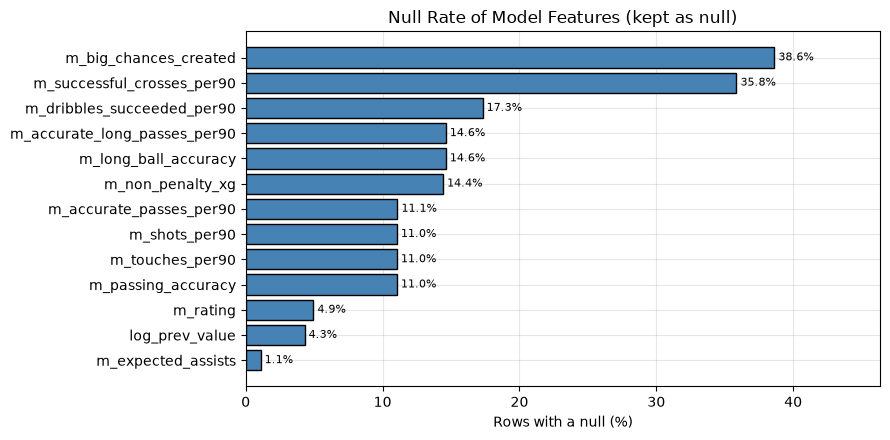

In [146]:
null_rate = dev[FEATURES].isna().mean().sort_values() * 100
null_rate = null_rate[null_rate > 0]
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(null_rate.index, null_rate.values, color=COLOR, edgecolor="black")
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in null_rate.values], padding=3, fontsize=8)
ax.set_xlabel("Rows with a null (%)")
ax.set_title("Null Rate of Model Features (kept as null)")
ax.set_xlim(0, null_rate.max() * 1.2)
plt.tight_layout()
plt.show()

# The recorded null rates of the build match the data
recorded = pd.Series(mi_manifest["checks"]["null_rate"])
assert (recorded - dev[recorded.index].isna().mean().round(4)).abs().max() < 1e-4

**Interpretation**

- `m_big_chances_created` and `m_successful_crosses_per90` are null in more than a third of the rows, mostly for low-minute players for whom the source reports nothing. Filling these with zero would claim an observation that does not exist.
- Position, age, minutes and the previous-value flag are complete, so every row has the main structural information.

## F. Summary of the Model Input

| Item | Value |
|---|---|
| Rows / players | 2,491 / 1,101 (DEF, MID, FWD; 2020/21-2024/25) |
| Target | ln(EUR) |
| Features | 19 (18 numeric + 1 categorical position) |
| Missing values | kept as null |
| Removed rows | none beyond the population rule |

---

# 10. Evaluation Design & Baseline

Objective:
Measure how well a model **generalises to players it has not seen**, and compare it with simple references.

## A. Why Not a Random Train / Validation Split?

The EDA (8.6.E) showed that 679 players appear in two or more seasons. With a random row split about 76% of validation rows would belong to a player who is also in training, and the model could simply remember the player's level. The split must therefore keep **all seasons of a player on the same side**.

## B. Primary Evaluation: Repeated StratifiedGroupKFold

Configuration:
- 5 folds, **grouped by player** (`canonical_player_id`): a player is never in training and test at the same time.
- **Stratified** on 5 quantile bins of the log target, so each fold covers cheap and expensive players alike.
- **Repeated 5 times** with seeds 0-4, so every row gets 5 out-of-fold predictions and the spread across repeats can be reported.

The cell below rebuilds the folds with the configured seeds and checks them against the folds recorded in the saved predictions.

In [147]:
from sklearn.model_selection import StratifiedGroupKFold

ev = CFG5["evaluation"]["primary"]
X5, y5, g5 = te.prepare(dev, CFG5), dev["log_target"].to_numpy(), dev["canonical_player_id"].to_numpy()
bins5 = pd.qcut(dev["log_target"], ev["n_bins"], labels=False).to_numpy()

OOF = pd.read_parquet(ROOT / "data/phase_05/results/run_v1/oof_predictions_primary.parquet")
fold_rows, folds_match = [], True
for repeat, seed in enumerate(ev["seeds"][: ev["n_repeats"]]):
    cv = StratifiedGroupKFold(n_splits=ev["n_splits"], shuffle=True, random_state=seed)
    for fold, (tr, ts) in enumerate(cv.split(X5, bins5, g5)):
        saved = set(OOF.loc[(OOF["repeat"] == repeat) & (OOF["fold"] == fold), "row"])
        folds_match &= saved == set(ts)
        fold_rows.append({"repeat": repeat, "fold": fold, "train rows": len(tr), "test rows": len(ts),
                          "test players": len(set(g5[ts])), "players in train and test": len(set(g5[tr]) & set(g5[ts])),
                          "test median ln target": round(float(np.median(y5[ts])), 2)})
folds = pd.DataFrame(fold_rows)
display(folds[folds["repeat"] == 0].set_index("fold"))
print("Folds over all repeats:", len(folds), "| players in both train and test, max:", folds["players in train and test"].max())
print("Folds identical to those used for the saved predictions:", folds_match)

,repeat,train rows,test rows,test players,players in train and test,test median ln target
fold,,,,,,
0,0,1993,498,221,0,16.52
1,0,1993,498,223,0,16.52
2,0,1993,498,222,0,16.49
3,0,1993,498,217,0,16.45
4,0,1992,499,218,0,16.52


Folds over all repeats: 25 | players in both train and test, max: 0
Folds identical to those used for the saved predictions: True


**Interpretation**

- Folds are balanced in size and in target level, and no player is ever in both training and test.
- The folds rebuilt here are identical to the folds behind the saved predictions, so the results in section 11 come from exactly this design.

## C. Supplementary Evaluation: Forward Chaining

Grouped folds mix seasons, so a model may learn from a later season and be tested on an earlier one. Forward chaining mirrors real use: **train on all earlier seasons, test on the next one**. Players in the test season may appear in earlier seasons, as they would in practice.

In [148]:
fwd_plan = pd.DataFrame([{"test season": short(s),
                          "training seasons": f"{short(SEASONS[0])} - {short(SEASONS[SEASONS.index(s) - 1])}",
                          "train rows": int((dev["season"] < s).sum()), "test rows": int((dev["season"] == s).sum())}
                         for s in CFG5["evaluation"]["supplementary"]["test_seasons"]])
display(fwd_plan.set_index("test season"))

,training seasons,train rows,test rows
test season,,,
2021/22,2020/21 - 2020/21,474,486
2022/23,2020/21 - 2021/22,960,503
2023/24,2020/21 - 2022/23,1463,527
2024/25,2020/21 - 2023/24,1990,501


## D. Metrics

| Metric | Formula | Reading |
|---|---|---|
| **MAE (ln)** — primary | mean of \|ln(pred) − ln(actual)\| | `exp(MAE)` = typical ratio error |
| RMSE (ln) | sqrt(mean of squared ln errors) | penalises large misses more |
| MdAPE (EUR) | median of \|pred − actual\| / actual | typical percentage error in euros |

Each metric is computed per repeat and reported as the mean (± standard deviation) over the 5 repeats.

## E. Baselines

Two models that need no performance data:
- **Dummy:** predict the median ln target of the training fold for every player (no information at all).
- **Persistence:** predict the season-start value (section 09.C). Only possible for rows that have a previous value.

A useful model must beat persistence: otherwise the season's performance adds nothing.

In [149]:
# Dummy baseline: training-fold median, same folds as the model
dummy = []
for repeat, seed in enumerate(ev["seeds"][: ev["n_repeats"]]):
    pred = np.empty(len(dev))
    for tr, ts in StratifiedGroupKFold(n_splits=ev["n_splits"], shuffle=True, random_state=seed).split(X5, bins5, g5):
        pred[ts] = np.median(y5[tr])
    dummy.append(te.metrics(y5, pred))

has_prev = dev["has_prev_value"].to_numpy()
persistence = te.metrics(y5[has_prev], dev.loc[has_prev, "log_prev_value"].to_numpy())

baselines = pd.DataFrame({
    "Dummy (training median)": {"rows": len(dev), **{k: np.mean([d[k] for d in dummy]) for k in ("mae_log", "rmse_log", "mdape_eur")}},
    "Persistence (season-start value)": {"rows": persistence["n"], **{k: persistence[k] for k in ("mae_log", "rmse_log", "mdape_eur")}},
}).T
baselines["typical ratio error exp(MAE)"] = np.exp(baselines["mae_log"].astype(float))
display(baselines.astype(float).round(3))

,rows,mae_log,rmse_log,mdape_eur,typical ratio error exp(MAE)
Dummy (training median),2491.0,1.013,1.358,62.5,2.753
Persistence (season-start value),2384.0,0.323,0.544,20.0,1.381


**Interpretation**

- Knowing nothing about the player gives a typical error of more than a factor of 2.
- Persistence is far better: knowing the season-start value already brings the typical error down to about 1.38×. This is the bar the model has to clear.

---

# 11. Model Training & Hyperparameter Tuning

## A. Model Choice: LightGBM

One main model, a **LightGBM gradient-boosted tree regressor**, because:
- it handles **nulls natively** (section 09.E);
- it captures **non-linear effects and interactions** found in the EDA (the inverted-U of age, the age × playing-time interaction, position-dependent meanings);
- it is insensitive to feature scale and robust to skewed features, so no scaling is needed.

## B. Hyperparameter Tuning: Nested Cross-Validation

Tuning must not see the test fold. Inside every outer training fold, a `GridSearchCV` with an **inner GroupKFold(3) by player** chooses the configuration; the chosen configuration is refitted on the outer training fold and predicts the outer test fold.

```text
Outer fold k (grouped by player)
   training part ──> inner GroupKFold(3) ──> best of 8 configurations ──> refit ──> predict test part
```

The grid (8 configurations) was fixed in the configuration before any result was seen. Training takes long (25 outer folds × 8 configurations × 3 inner folds, plus forward chaining), so this notebook does **not retrain**: it reads the saved out-of-fold predictions of `src/phase5/train_eval.py` and recomputes every metric from them.

In [150]:
tuning = CFG5["evaluation"]["tuning"]
display(pd.DataFrame({"values searched": {k: v for k, v in tuning["grid"].items()}}))

RESULTS = ROOT / "data/phase_05/results/run_v1"
res_manifest = read_json("data/phase_05/results/run_v1/manifest.json")
assert res_manifest["input_sha256"] == mi_manifest["output_sha256"], "Results were not produced from this model input"
best = pd.read_csv(RESULTS / "best_params.csv")
best_primary = best[best["run"] == "primary"]
print("Configuration chosen by the inner search in the 25 primary outer folds:")
display(best_primary.groupby(list(tuning["grid"]), dropna=False).size().rename("outer folds").to_frame())

,values searched
n_estimators,"[200, 500]"
learning_rate,[0.05]
num_leaves,"[15, 31]"
min_child_samples,"[20, 50]"


Configuration chosen by the inner search in the 25 primary outer folds:


outer folds
n_estimators learning_rate num_leaves min_child_samples             
200          0.05          15         20                          17
                                      50                           6
                           31         50                           2

**Interpretation**

- The inner search picks 200 trees and 15 leaves, the smallest values in the grid, in 23 of 25 outer folds; the leaf-size setting varies. With about 2,000 training rows and a dominant previous-value feature, a small model is enough. Because the choice sits at the edge of the grid, even simpler models were not explored (a limitation, section 14).

## C. Cross-Validation Results

In [151]:
metrics5 = read_json("data/phase_05/results/run_v1/metrics.json")

# Recompute the primary result from the saved out-of-fold predictions
oof = OOF.merge(dev.rename_axis("row").reset_index()[["row", "canonical_player_id", "season", "log_target",
                                                         "log_prev_value", "has_prev_value"]],
                on="row", suffixes=("", "_dev"))
assert (oof["canonical_player_id"] == oof["canonical_player_id_dev"]).all() and (oof["season"] == oof["season_dev"]).all()
assert (oof.groupby("repeat")["row"].nunique() == len(dev)).all(), "every row predicted once per repeat"
per_repeat = pd.DataFrame([te.metrics(f["log_target"].to_numpy(), f["pred_log"].to_numpy()) for _, f in oof.groupby("repeat")])
on_prev = pd.DataFrame([te.metrics(f["log_target"].to_numpy(), f["pred_log"].to_numpy())
                        for _, f in oof[oof["has_prev_value"]].groupby("repeat")])
assert abs(per_repeat["mae_log"].mean() - metrics5["primary"]["overall"]["mae_log"]) < 1e-9, "differs from recorded metrics"

fwd = pd.read_parquet(RESULTS / "predictions_forward.parquet").merge(
    dev.rename_axis("row").reset_index()[["row", "log_target"]], on="row")
fwd_m = te.metrics(fwd["log_target"].to_numpy(), fwd["pred_log"].to_numpy())
sens = metrics5["sensitivity_without_identity_rows"]["overall"]

def row(label, n, m, sd=None):
    return {"evaluation": label, "rows": n, "MAE ln": m["mae_log"], "± sd over repeats": sd,
            "RMSE ln": m["rmse_log"], "MdAPE %": m["mdape_eur"], "typical ratio error": np.exp(m["mae_log"])}

cv_table = pd.DataFrame([
    row("Model, grouped CV (primary)", len(dev), per_repeat.mean(), per_repeat["mae_log"].std(ddof=0)),
    row("Model, without identity-sensitive rows", sens["n"], sens, sens["mae_log_sd"]),
    row("Model, forward chaining", fwd_m["n"], fwd_m),
    row("Model, rows with a previous value", int(dev["has_prev_value"].sum()), on_prev.mean()),
    row("Persistence, same rows", persistence["n"], persistence),
    row("Dummy (training median)", len(dev), pd.DataFrame(dummy).mean()),
]).set_index("evaluation")
display(cv_table.round(3))

,rows,MAE ln,± sd over repeats,RMSE ln,MdAPE %,typical ratio error
evaluation,,,,,,
"Model, grouped CV (primary)",2491,0.265,0.001,0.420,17.383,1.303
"Model, without identity-sensitive rows",2037,0.254,0.002,0.399,16.924,1.289
"Model, forward chaining",2017,0.283,NaN,0.456,18.281,1.328
"Model, rows with a previous value",2384,0.235,NaN,0.341,16.722,1.265
"Persistence, same rows",2384,0.323,NaN,0.544,20.000,1.381
Dummy (training median),2491,1.013,NaN,1.358,62.500,2.753


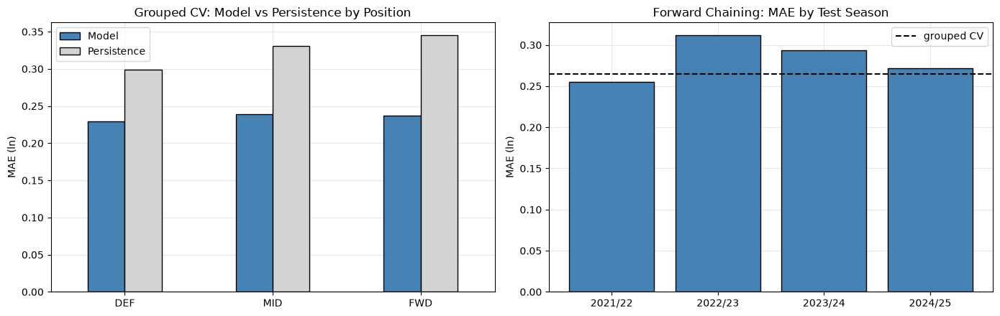

In [152]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Model vs persistence by position (rows with a previous value)
pos = pd.DataFrame({p: {"Model": v["model_on_persistence_rows"]["mae_log"], "Persistence": v["persistence"]["mae_log"]}
                    for p, v in metrics5["primary"]["position_group_season"].items()}).T.reindex(["DEF", "MID", "FWD"])
pos.plot(kind="bar", ax=axes[0], color=[COLOR, "lightgray"], edgecolor="black", rot=0)
axes[0].set_title("Grouped CV: Model vs Persistence by Position")
axes[0].set_ylabel("MAE (ln)")
axes[0].set_xlabel("")

# Forward chaining by test season
by_season = fwd.merge(dev.rename_axis("row").reset_index()[["row", "season"]], on="row", suffixes=("", "_d"))
fs = by_season.groupby("season").apply(lambda f: te.metrics(f["log_target"].to_numpy(), f["pred_log"].to_numpy())["mae_log"],
                                       include_groups=False)
axes[1].bar([short(s) for s in fs.index], fs.values, color=COLOR, edgecolor="black")
axes[1].axhline(per_repeat["mae_log"].mean(), color="black", linestyle="--", label="grouped CV")
axes[1].set_title("Forward Chaining: MAE by Test Season")
axes[1].set_ylabel("MAE (ln)")
axes[1].legend()
plt.tight_layout()
plt.show()

**Interpretation**

- **Primary result:** MAE 0.265 (± 0.001 over repeats), a typical ratio error of about **1.30×**, MdAPE about 17%. The spread over repeats is tiny, so the estimate is stable.
- **The model beats persistence** on the same rows (0.235 vs 0.323) and in every position: the season's performance, age and minutes add real information beyond the season-start value.
- **Identity sensitivity:** without the 454 identity-sensitive rows the error is slightly lower (0.254), with the same conclusion. Since human labelling found no wrong identity, this difference reflects the type of player in that subset (fewer minutes), not wrong matches.
- **Forward chaining** is a little worse (0.283), as expected: each test season brings a new valuation batch and new players, and early folds train on few seasons.

---

# 12. Error Analysis

Objective:
Find **where** the model is accurate and where it is not. Errors are computed from the out-of-fold predictions (each row predicted by a model that never saw the player), per repeat, then averaged. No row is removed.

In [153]:
oof_g = oof.merge(dev.rename_axis("row").reset_index()[["row", "position_group_season", "m_minutes_played",
                                                          "age_at_season_end_years", "target_before_season_start"]], on="row")
oof_g["abs_err"] = (oof_g["pred_log"] - oof_g["log_target"]).abs()
oof_g["minutes"] = np.where(oof_g["m_minutes_played"] >= 900, "900+ minutes", "under 900 minutes")
oof_g["age band"] = pd.cut(oof_g["age_at_season_end_years"], [0, 21, 24, 29, 50], labels=["<= 21", "22-24", "25-29", "30+"])
oof_g["previous value"] = np.where(oof_g["has_prev_value"], "returning (has value)", "new (no value)")
oof_g["season "] = oof_g["season"].map(short)

def group_errors(col):
    per = oof_g.groupby(["repeat", col], observed=True)["abs_err"].agg(["mean", "sum", "size"]).reset_index()
    out = per.groupby(col, observed=True).agg(rows=("size", "first"), MAE=("mean", "mean"), error_sum=("sum", "mean"))
    out["share of total error %"] = out["error_sum"] / out["error_sum"].sum() * 100
    return out.drop(columns="error_sum")

error_tables = {c: group_errors(c) for c in ["minutes", "age band", "previous value", "position_group_season", "season "]}
display(pd.concat(error_tables, names=["group", "value"]).round(3))

rows    MAE  share of total error %
group                 value                                                     
minutes               900+ minutes           1536  0.203                  47.269
                      under 900 minutes       955  0.364                  52.731
age band              <= 21                   271  0.641                  26.357
                      22-24                   493  0.322                  24.071
                      25-29                  1044  0.190                  30.011
                      30+                     683  0.189                  19.561
previous value        new (no value)          107  0.926                  15.022
                      returning (has value)  2384  0.235                  84.978
position_group_season DEF                     924  0.253                  35.464
                      FWD                     750  0.277                  31.452
                      MID                     817  0.267                  33.083
season                2020/21                 474  0.270                  19.421
                      2021/22                 486  0.237                  17.486
                      2022/23                 503  0.276                  21.076
                      2023/24                 527  0.281                  22.460
                      2024/25                 501  0.257                  19.557

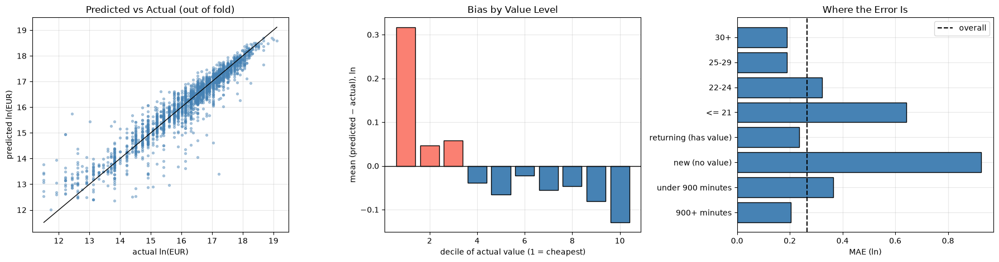

In [154]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# Predicted vs actual (repeat 0)
r0 = oof_g[oof_g["repeat"] == 0]
axes[0].scatter(r0["log_target"], r0["pred_log"], s=8, alpha=0.4, color=COLOR)
lims = [r0[["log_target", "pred_log"]].min().min(), r0[["log_target", "pred_log"]].max().max()]
axes[0].plot(lims, lims, color="black", linewidth=1)
axes[0].set_xlabel("actual ln(EUR)")
axes[0].set_ylabel("predicted ln(EUR)")
axes[0].set_title("Predicted vs Actual (out of fold)")

# Mean signed error by decile of the actual value: shrinkage toward the middle
r0 = r0.assign(decile=pd.qcut(r0["log_target"], 10, labels=False) + 1, err=r0["pred_log"] - r0["log_target"])
dec = r0.groupby("decile")["err"].mean()
axes[1].bar(dec.index, dec.values, color=np.where(dec.values > 0, "salmon", COLOR), edgecolor="black")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_xlabel("decile of actual value (1 = cheapest)")
axes[1].set_ylabel("mean (predicted − actual), ln")
axes[1].set_title("Bias by Value Level")

# MAE by minutes band and previous-value status
mae_groups = pd.concat([error_tables["minutes"]["MAE"], error_tables["previous value"]["MAE"], error_tables["age band"]["MAE"]])
axes[2].barh(mae_groups.index.astype(str), mae_groups.values, color=COLOR, edgecolor="black")
axes[2].axvline(per_repeat["mae_log"].mean(), color="black", linestyle="--", label="overall")
axes[2].set_xlabel("MAE (ln)")
axes[2].set_title("Where the Error Is")
axes[2].legend()
plt.tight_layout()
plt.show()

**Interpretation**

- **Predictions shrink toward the middle.** Cheap players are over-valued and expensive players under-valued; large value changes are under-predicted in both directions. This is typical of a model whose strongest feature is the previous value.
- **Error concentrates in a minority of rows.** Players under 900 minutes (about 38% of rows) produce about half of the total absolute error; players without a previous value have by far the largest error (MAE about 0.93, a factor of about 2.5).
- **Young players** (21 or under) are hard: their value moves fast and depends on potential, which season statistics capture poorly.
- **Established regulars** (900+ minutes, age 25+) are estimated well, with a typical error of about 1.2×.
- Positions differ little; seasons differ mainly through their valuation batch.

## A. Which Features Does the Model Use?

The cell below reads the importance of each feature (total split gain) from the saved final model of section 13.

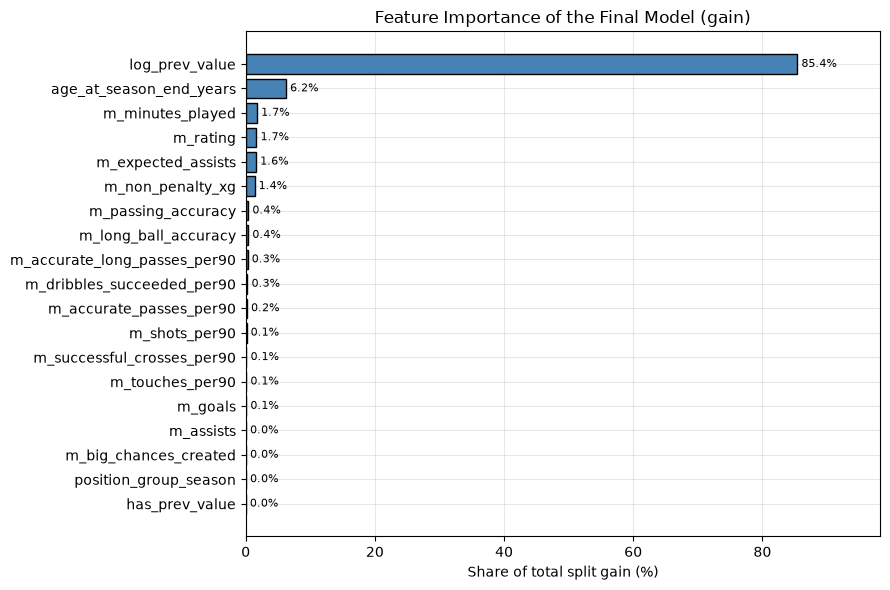

In [155]:
import lightgbm as lgb

FINAL_DIR = ROOT / "data/phase_05/final_model/final_model_v1"
final_manifest = read_json("data/phase_05/final_model/final_model_v1/manifest.json")
assert sha256_file(FINAL_DIR / "final_model.txt") == final_manifest["model_sha256"], "Final model changed"
booster = lgb.Booster(model_file=str(FINAL_DIR / "final_model.txt"))
assert booster.feature_name() == FEATURES == final_manifest["feature_order"]

gain = pd.Series(booster.feature_importance(importance_type="gain"), index=FEATURES)
gain = (gain / gain.sum() * 100).sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(gain.index, gain.values, color=COLOR, edgecolor="black")
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in gain.values], padding=3, fontsize=8)
ax.set_xlabel("Share of total split gain (%)")
ax.set_title("Feature Importance of the Final Model (gain)")
ax.set_xlim(0, gain.max() * 1.15)
plt.tight_layout()
plt.show()

**Interpretation**

- The **season-start value dominates** (about 85% of the gain), as expected from section 09.C.
- After it come age, playing time, rating and the expected-goals / expected-assists features: the variables that the EDA found associated with value beyond playing time.
- Passing, possession, goals and assists add little, and position adds almost nothing once the other features are known.
- Gain importance shows what the model **uses**, not what **causes** value (RD-03), and correlated features share their importance.

---

# 13. Final Model & Holdout Test (2025/26)

Objective:
Give one honest estimate of performance on a season that played **no part** in any design decision.

```text
Development data (2,491 rows)                       2025/26 season
        |                                                 |
1. Freeze rules, code and config (SHA-256)                |
        |                                                 |
2. Fit the final model ONCE on all rows                   |
        |                                                 |
        +----------------> 3. Collect and build 2025/26 with the frozen code (blind)
                                                          |
                                     4. Score ONCE, report as computed
```

## A. Pre-Registration and Freeze

Before any 2025/26 data entered the project, the following were written down and frozen with SHA-256 (`reports/phase_05/holdout/HOLDOUT_PREREGISTRATION.md`, `holdout_freeze_manifest.json`): the model configuration, the feature, target and previous-value code, the development model input, the scoring metrics and the decision rules.

**Decision rules**

| Criterion | Rows | Statistic | PASS | FAIL | INCONCLUSIVE |
|---|---|---|---|---|---|
| **Primary:** model vs persistence | rows with a previous value | ΔMAE = MAE(persistence) − MAE(model), ln scale, 95% paired player bootstrap (2,000 draws, seed 0) | lower bound > 0 | upper bound < 0 | interval contains 0 |
| Secondary: within ±20% | rows with 900+ minutes | share of predictions with predicted/actual in [0.8, 1.2], 95% player bootstrap | lower bound ≥ 60% | upper bound < 60% | interval contains 60% |

Note on the secondary criterion: the 60% target was set **after** the development results had been seen (the cross-validation estimate was 62.1%, interval 59.7%-64.3%). It therefore cannot be tested on development data, and it was made secondary before any holdout prediction. The primary criterion answers the project's question directly: does the season add information beyond the start value?

The cell below verifies the freeze and shows the order of events from the recorded timestamps.

In [156]:
from src.phase5.final_model import verify_freeze

freeze = verify_freeze()   # raises if any frozen file changed
print("Frozen files verified by SHA-256:", len(freeze["files"]))

HO_INPUT = ROOT / "data/holdout_2025_26/model_input/holdout_model_input_v2.parquet"
HO_PRED = ROOT / "data/holdout_2025_26/scoring/holdout_predictions.parquet"
lock = read_json("reports/phase_05/holdout/HOLDOUT_SCORED.lock")
ho_build_full = read_json("data/holdout_2025_26/model_input/build_manifest_v2.json")

timeline = pd.DataFrame([
    ("Pre-registration frozen", freeze["signed_utc"]),
    ("Final model fitted on development data", final_manifest["generated_utc"]),
    ("2025/26 FotMob release built", ho_release["created_at_utc"]),
    ("2025/26 model input built", ho_build_full["generated_utc"]),
    ("Primary criterion amended (before any prediction)", freeze["amendment_1_signed_utc"]),
    ("Holdout scored (once)", lock["started_utc"]),
], columns=["event", "UTC time"])
timeline["UTC time"] = pd.to_datetime(timeline["UTC time"], format="ISO8601").dt.strftime("%Y-%m-%d %H:%M")
display(timeline.set_index("event"))
assert list(timeline["UTC time"]) == sorted(timeline["UTC time"]), "events out of order"

Frozen files verified by SHA-256: 7


,UTC time
event,
Pre-registration frozen,2026-11-16 08:45
Final model fitted on development data,2026-11-16 08:48
2025/26 FotMob release built,2026-11-16 09:34
2025/26 model input built,2026-11-16 09:52
Primary criterion amended (before any prediction),2026-11-16 13:27
Holdout scored (once),2026-11-16 13:50


## B. Final Model

The final model is fitted **once on all 2,491 development rows**, with the same 8-configuration grid and inner GroupKFold(3) by player, and saved with its SHA-256 before any holdout row existed (`src/phase5/final_model.py`).

In [157]:
display(pd.Series({**final_manifest["best_params"], "inner CV MAE (ln)": round(final_manifest["inner_cv_mae_log"], 4),
                   "training rows": final_manifest["training_rows"], "training players": final_manifest["training_players"],
                   "features": len(final_manifest["feature_order"]), "trees": booster.num_trees()},
                  name="final model").astype(str).to_frame())

,final model
learning_rate,0.05
min_child_samples,50.0
n_estimators,200.0
num_leaves,15.0
inner CV MAE (ln),0.2641
training rows,2491.0
training players,1101.0
features,19.0
trees,200.0


## C. Holdout Model Input

Built with the frozen rules: confirmed 2025/26 player-seasons, outfield positions, usable target with the 2025/26 season-end cutoff, previous value strictly before the 2025/26 first match, the same 19 features, no imputation.

In [158]:
assert sha256_file(HO_INPUT) == ho_build_full["model_input_sha256"] == lock["input_sha256"], "Holdout input changed"
hb = ho_build_full["model_input"]
display(pd.Series({
    "player-seasons collected": hb["player_seasons_total"],
    "goalkeepers excluded": hb["goalkeepers_excluded"],
    "outfield rows without a usable target": hb["outfield_without_usable_target"],
    "rows scored": hb["model_rows"],
    "rows without a previous value": hb["no_prev_value"],
    "players already seen in development": hb["seen_in_development"],
    "rows with 900+ minutes": hb["minutes_900_plus"],
    "identity mappings labelled wrong": hb["iss01_labels"]["owner_rejected"],
}, name="rows").to_frame())

,rows
player-seasons collected,537
goalkeepers excluded,40
outfield rows without a usable target,13
rows scored,484
rows without a previous value,8
players already seen in development,356
rows with 900+ minutes,316
identity mappings labelled wrong,0


## D. Holdout Result

The scoring script (`src/holdout/score_holdout.py`) verified every frozen SHA-256, created a lock file so it can never run twice, and wrote the predictions. The cell below does **not** rescore: it re-applies the saved final model to the frozen holdout input, checks that the predictions are identical to the saved ones, and recomputes the criteria with the same pre-registered functions.

In [159]:
from src.holdout.score_holdout import paired_delta, within_band

ho = pd.read_parquet(HO_INPUT)
saved_pred = pd.read_parquet(HO_PRED)
assert sha256_file(HO_PRED) == lock["predictions_sha256"], "Saved predictions changed"
check = ho[fx.KEY].assign(pred_now=booster.predict(te.prepare(ho, CFG5))).merge(saved_pred, on=fx.KEY, validate="one_to_one")
print("Max |re-applied − saved prediction|:", float((check["pred_now"] - check["pred_log"]).abs().max()))

hp = saved_pred[saved_pred["has_prev_value"]]
primary = paired_delta(hp["log_target"].to_numpy(), hp["pred_log"].to_numpy(), hp["log_prev_value"].to_numpy(),
                       hp["canonical_player_id"].to_numpy())
h9 = saved_pred[saved_pred["minutes_900_plus"]]
secondary = within_band(h9["log_target"].to_numpy(), h9["pred_log"].to_numpy(), h9["canonical_player_id"].to_numpy())
recorded = read_json("data/holdout_2025_26/scoring/holdout_metrics.json")
assert primary["verdict"] == recorded["primary_vs_persistence"]["verdict"] == lock["primary_verdict"]
assert secondary["verdict"] == recorded["secondary_within_20pct_900min"]["verdict"] == lock["secondary_verdict"]

display(pd.DataFrame([
    {"criterion": "Primary: ΔMAE = persistence − model (ln)", "rows": primary["n_rows"],
     "result": f"model {primary['mae_model']:.3f} vs persistence {primary['mae_persistence']:.3f}  →  Δ {primary['delta_mae']:.3f}",
     "95% interval": f"{primary['ci95'][0]:.3f} to {primary['ci95'][1]:.3f}", "verdict": primary["verdict"]},
    {"criterion": "Secondary: share within ±20%, 900+ minutes", "rows": secondary["n_rows"],
     "result": f"{secondary['share_within_20pct']:.1%} (threshold 60%)",
     "95% interval": f"{secondary['ci95'][0]:.1%} to {secondary['ci95'][1]:.1%}", "verdict": secondary["verdict"]},
]).set_index("criterion"))

Max |re-applied − saved prediction|: 0.0


,rows,result,95% interval,verdict
criterion,,,,
Primary: ΔMAE = persistence − model (ln),476,model 0.246 vs persistence 0.368 → Δ 0.122,0.092 to 0.157,PASS
"Secondary: share within ±20%, 900+ minutes",316,64.9% (threshold 60%),59.5% to 69.9%,INCONCLUSIVE


,rows,Model,Persistence
group,,,
DEF,167,0.229,0.348
MID,158,0.226,0.372
FWD,151,0.284,0.385
seen in development,356,0.186,0.295
new to the model,120,0.421,0.582
900+ minutes,316,0.189,0.309
under 900 minutes,160,0.357,0.484


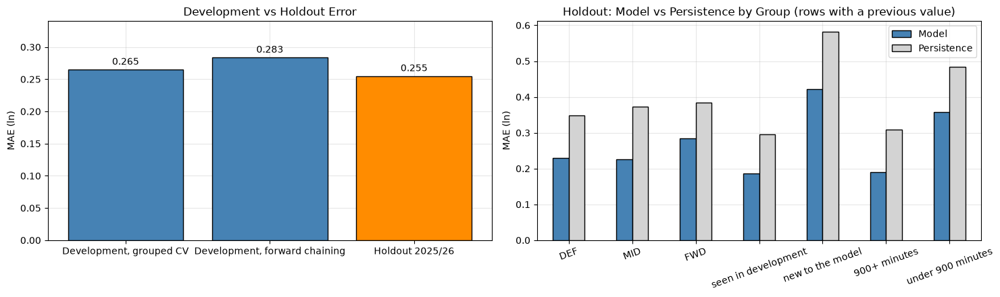

In [160]:
# Holdout vs development, and model vs persistence by group on the holdout
ho_all = te.metrics(saved_pred["log_target"].to_numpy(), saved_pred["pred_log"].to_numpy())
compare = pd.Series({"Development, grouped CV": per_repeat["mae_log"].mean(),
                     "Development, forward chaining": fwd_m["mae_log"],
                     "Holdout 2025/26": ho_all["mae_log"]})

groups = {"DEF": saved_pred["position_group_season"].eq("DEF"), "MID": saved_pred["position_group_season"].eq("MID"),
          "FWD": saved_pred["position_group_season"].eq("FWD"),
          "seen in development": saved_pred["seen_in_development"], "new to the model": ~saved_pred["seen_in_development"],
          "900+ minutes": saved_pred["minutes_900_plus"], "under 900 minutes": ~saved_pred["minutes_900_plus"]}
rows = []
for name, mask in groups.items():
    f = saved_pred[mask & saved_pred["has_prev_value"]]
    rows.append({"group": name, "rows": len(f),
                 "Model": te.metrics(f["log_target"].to_numpy(), f["pred_log"].to_numpy())["mae_log"],
                 "Persistence": te.metrics(f["log_target"].to_numpy(), f["log_prev_value"].to_numpy())["mae_log"]})
ho_groups = pd.DataFrame(rows).set_index("group")
display(ho_groups.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].bar(compare.index, compare.values, color=[COLOR, COLOR, "darkorange"], edgecolor="black")
axes[0].bar_label(axes[0].containers[0], labels=[f"{v:.3f}" for v in compare.values], padding=3)
axes[0].set_ylabel("MAE (ln)")
axes[0].set_title("Development vs Holdout Error")
axes[0].set_ylim(0, compare.max() * 1.2)
ho_groups[["Model", "Persistence"]].plot(kind="bar", ax=axes[1], color=[COLOR, "lightgray"], edgecolor="black", rot=20)
axes[1].set_ylabel("MAE (ln)")
axes[1].set_xlabel("")
axes[1].set_title("Holdout: Model vs Persistence by Group (rows with a previous value)")
plt.tight_layout()
plt.show()

**Interpretation**

- **Primary criterion: PASS.** On a season the model never saw, it beats persistence clearly: ΔMAE 0.122, 95% interval 0.092 to 0.157. It beats persistence in every position and every reported group.
- **Secondary criterion: INCONCLUSIVE.** 64.9% of the predictions for regular players are within ±20% of the actual value, above the 60% target, but the lower end of the interval (59.5%) touches the threshold. More data would be needed to establish it.
- **No sign of overfitting:** the holdout error (0.255) is in line with development (0.265 grouped CV, 0.283 forward chaining).
- **The same weak spots come back:** players new to the model, players under 900 minutes and the 8 rows without a previous value. The error analysis of section 12 generalises.
- The re-applied model reproduces the saved predictions, and the recomputed criteria match the recorded verdicts. 2025/26 has now been used, so any further model change would need a new untouched season.

---

# 14. Conclusion & Limitations

## A. Summary

| Stage | Result |
|---|---|
| Data | 2,747 development player-seasons (1,228 players, 5 seasons) from FotMob and Transfermarkt, built by a gated, checksummed pipeline; 2025/26 built the same way as holdout |
| EDA | Heavy-tailed target, repeated players, strong role of playing time, age and position, informative missingness, mid-season label |
| Preprocessing | Outfield population (2,491 rows), ln target, season-start value, 19 features, nulls kept |
| Evaluation | Repeated StratifiedGroupKFold by player (primary), forward chaining (supplementary), persistence and dummy baselines |
| Model | LightGBM, nested grid search: MAE 0.265 (typical error 1.30×), beats persistence (0.235 vs 0.323 on the same rows) |
| Holdout 2025/26 | Primary PASS (ΔMAE 0.122, 95% CI 0.092-0.157); secondary INCONCLUSIVE (64.9%, CI 59.5%-69.9%) |

**Answer to the research question.** The season-start value carries most of the information about a player's end-of-season value, but the season's performance, minutes and age add a real and stable improvement over it, confirmed on an untouched season. The model is accurate for established regulars and weak for new, young and low-minute players.

## B. Limitations

- **Timing of the label (RD-03).** The target is mostly a mid-season valuation, while features cover the whole season (about 44% of appearances fall after the valuation date). Results describe how whole-season statistics relate to the end-of-season valuation; they are **not forecasts**, and performance must not be read as causing value.
- **Outfield players only.** Goalkeepers are excluded.
- **2020/21 previous values** come from the COVID re-valuation batch.
- **Weak groups:** new players, players under 900 minutes, young players.
- **Small grid:** the chosen hyperparameters sit at the edge of the grid.
- **Feature importance** is descriptive; correlated features share importance.
- **Retrospective collection:** FotMob statistics were collected after the seasons; post-season revisions were not rechecked.
- **Internal academic use only:** upstream Transfermarkt rights are not verified.

## C. Possible Next Work

- Transfer and club-move information, to help new and low-minute players.
- A wider or more regularised hyperparameter grid, under a new configuration version.
- A goalkeeper-specific model.
- Any change must be tested on a new untouched season (for example 2026/27) with a new pre-registration.

## D. Reproducibility

| Step | Command (`.venv314`, scikit-learn 1.9.1, lightgbm 4.7.0) | Output |
|---|---|---|
| Previous value | `python -I src/phase5/season_start_prev_value.py` | `data/phase_05/previous_value/` |
| Model input | `python -I src/phase5/features.py` | `data/phase_05/features/model_input_v1/` |
| Cross-validation | `python -I src/phase5/train_eval.py` | `data/phase_05/results/run_v1/` |
| Final model | `python -I src/phase5/final_model.py` | `data/phase_05/final_model/final_model_v1/` |
| Holdout scoring | `src/holdout/score_holdout.py` (locked: runs once) | `data/holdout_2025_26/scoring/` |

Each output folder has a manifest with input and output SHA-256 values, and this notebook verifies them before use. Detailed reports: `reports/phase_05/PHASE5_FINAL_REPORT.md`, `reports/phase_05/LEAKAGE_AUDIT.md`, `reports/phase_05/holdout/HOLDOUT_RESULT.md`.